# Chapter 16 — Introduction to Biofluid Mechanics

*Fluid Mechanics, 5th edition — Pijush K. Kundu, Ira M. Cohen, David R. Dowling (2012).*
This notebook teaches every new idea of the chapter with plain words, step-by-step mathematics, small worked examples, tested Python from the `fluidpy` package, figures, animations and interactive explainers. It does not reproduce the book's text or figures; equations are cited by their numbers so you can follow along in your copy.

---

**The big idea in one paragraph**

The last chapter turns the whole book on your own body. Blood is a slightly odd fluid, pushed in pulses through elastic,
branching, curved and sometimes collapsing tubes — and almost every answer is either Poiseuille's resistance $R=\dfrac{8\mu L}{\pi a^4}$ (16.20) or a
wave whose speed the wall sets, $c=\sqrt{\dfrac{Eh}{2\rho a_0}}$ (16.62), adjusted by one number, the Womersley number $\alpha=a\sqrt{\omega/\nu}$ (16.12), that compares a vessel with
its own Stokes layer. At the end the same tools lift water up a tree.

**Road map** — the new ideas of this chapter, in the order they build on each other:

1. **The heart as a pump** — its work per beat is the area of its pressure–volume loop (`C01`).
2. **Blood thins when sheared** — Casson's law, a straight line in square roots (`C02`).
3. **One number for every vessel** — the Womersley number α (`C03`).
4. **Resistance ∝ a⁻⁴** — why small arteries control blood pressure (`C04`).
5. **A plasma layer makes narrow tubes slippery** — the Fåhræus–Lindqvist effect (`C05`).
6. **The tube law** — an artery is a spring (`C06`).
7. **The Windkessel** — the aorta stores each beat and drains it (`C07`).
8. **The pulse is a wave of wall stretch** — the Moens–Korteweg speed (`C08`).
9. **Womersley's oscillating profile** — a breathing parabola or a lagging plug (`C09`).
10. **How much flow, how late** — amplitude and phase lag of pulsatile flow (`C10`).
11. **Viscous pulse waves** — slower and fading, by amounts ∝ 1/α (`C11`).
12. **Murray's law** — Q ∝ a³ and fixed branch angles (`C12`).
13. **Reflections at forks** — an admittance mismatch sends the pulse back (`C13`).
14. **Dean's vortices in a bend** — two cells and a core flung outward (`C14`).
15. **Collapsible tubes choke at S = 1** — flow limitation (`C15`).
16. **The Casson plug** — a yield stress freezes the centre of a pipe flow (`C16`).
17. **Water potential** — sap is pulled up a tree under tension (`C17`).

**What you should already know** (each is recapped where it is used):

- Newton's viscosity law $\tau=\mu\dfrac{du}{dy}$ (1.3) and hydrostatics $\dfrac{dp}{dz}=-\rho g$ (1.8) (Ch. 1)
- continuity and Navier–Stokes in cylindrical coordinates (Ch. 4)
- Poiseuille flow $u_z=\dfrac{R^2-a^2}{4\mu}\dfrac{dp}{dz}$ (8.6) and Stokes' second problem $u(y,t)=U\exp\{-y\sqrt{\omega/2\nu}\}\cos(\omega t-y\sqrt{\omega/2\nu})$ (8.38) (Ch. 8)
- boundary-layer separation (Ch. 9)
- d'Alembert's solution $p'(x,t)=f(x-ct)+g(x+ct)$ (15.15) and the $1-M^2$ structure of duct flow (Ch. 15)

## 🎮 Interactive explainers in this chapter

| # | Explainer | What it makes clear |
|---|---|---|
| 1 | **Does a yield stress stop the blood?** | the centre freezes into a plug; the flow stops only when the wall stress drops below τ_y |
| 2 | **Why doesn't blood pressure fall to zero between beats?** | a stretchy aorta stores each stroke and drains it with time constant RK |
| 3 | **Is the pulse at your wrist the blood arriving?** | a wave of wall stretch at metres per second; the blood barely moves |
| 4 | **Is pulsing flow just Poiseuille flow sloshing?** | α turns a breathing parabola into a lagging plug |
| 5 | **Does the flow follow the pressure?** | small α a damper, large α a mass: 1/α² and 90° late |
| 6 | **Why isn't a wider vessel always better?** | pumping ∝ a⁻⁴ against upkeep ∝ a²: Q ∝ a³ and fixed angles |
| 7 | **When does a fork send the pulse back?** | an admittance mismatch, not size alone; energy always balances |
| 8 | **What does a bend do to the flow?** | two vortices, a core flung outward, a flux loss of order K² |
| 9 | **Why can't you suck harder through a floppy straw?** | at S = 1 the flow stops hearing the outlet |
| 10 | **How does water climb a 30-metre tree?** | it is pulled: ψ falls from soil to leaf and p goes below zero |

Each one opens right where its idea is taught and fills the window (no scrolling). Start with the **Walkthrough**, then **Explore** with the sliders and presets, read **Explain** (every number worked out with your settings, and what it means), step through the **Derivation** where there is one, read the **Equations** and the **Code**, and finish with **Check yourself**. On the web page they are full-window; in Colab and Jupyter they appear in the cell output (use ⤢ *Full screen* or *Open in new tab* for more room).

## ⚙️ Setup — run this cell first

It works in three places without changes:
* **Google Colab** — clones the public repository into `/content/fluidpy` (the `fluidpy` package, its tests and the
  interactive explainers) and installs the one package Colab lacks (`pint`). No GPU is needed.
* **Jupyter / VS Code on your computer** — finds the repository root (the folder with `book.yaml`) and imports from it.
* **The published web page** — already executed; nothing to run.

In [1]:
# ── Setup: find (or fetch) the fluidpy repository, then load the house style ─────────────────────────────
import os, sys, subprocess, pathlib                     # standard library only, so this cell never fails on imports

IN_COLAB = "google.colab" in sys.modules                 # True when this notebook runs inside Google Colab
REPO_URL = "https://github.com/shammun/fluidpy.git"               # the public repository with the fluidpy package

if IN_COLAB:
    ROOT = pathlib.Path("/content/fluidpy")              # where the repository is cloned on Colab
    if not ROOT.exists():                                 # first run in this Colab session: clone it
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    else:                                                 # later runs: fetch the newest version
        subprocess.run(["git", "-C", str(ROOT), "pull", "--ff-only", "-q"], check=False)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements-colab.txt")], check=True)
else:
    ROOT = pathlib.Path.cwd().resolve()                   # start where Jupyter was launched …
    while not (ROOT / "book.yaml").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent                                # … and walk up until we find the repository root

os.chdir(ROOT)                                            # relative paths (outputs/, viz/) now resolve from the root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))                         # make `import fluidpy` work

from fluidpy.core.style import setup_notebook            # matplotlib + plotly style shared with the explainers
from fluidpy.core.embed import show_viz                  # shows an interactive explainer in the notebook
from fluidpy.core.anim import show_animation             # plays a matplotlib animation inline
FAST = setup_notebook()                                   # FAST=True (env FLUIDPY_FAST=1) shrinks grids for quick runs
print(f"IN_COLAB = {IN_COLAB} | repository root: {ROOT.name} | FAST = {FAST}")  # folder name only (no local path)

IN_COLAB = False | repository root: Fluid Dynamics | FAST = False


## 📦 Chapter imports and the numbers we will use

Every worked number in this notebook uses **our own illustrative inputs**, written out in the cell below as small
dictionaries: a resting adult heart (`heart`), blood (`blood`), Whitmore's Casson constants (`casson`), a medium artery
(`artery`), an aorta (`aorta`), a Windkessel (`windkessel`), a 40-µm tube (`micro`), an arteriole, Murray's costs
(`murray`), a bend (`bend`), a collapsible vein (`vein`), a Casson pipe, a tree and a phloem sieve tube. None of them is a
number from the book. The module carries its own illustrative set too; it is printed once at the end of the cell — **both
sets are ours**; where they differ, the notebook uses the dictionaries below.

In [2]:
import numpy as np                                          # arrays and maths
import sympy as sp                                          # symbolic algebra (derivation checks)
import matplotlib.pyplot as plt                             # static figures and animations
import pandas as pd                                         # small tables
import math, functools                                      # factorials; lru_cache (remember a slow result)
from scipy.integrate import quad, solve_ivp                 # numerical integral; ODE integrator
from scipy.optimize import brentq, minimize                 # root in a bracket; minimum of a function of several variables
from scipy.special import jv, jve                           # Bessel functions J_n (and the scaled version for large arguments)
from fluidpy import ch16_biofluid_mechanics as ch16         # this chapter's tested functions (re-exports Ch. 8 and Ch. 15 helpers)
from fluidpy.core import laminar as LAM, acoustics as AC, similarity as SIM, thermo as TH, units as UN   # earlier chapters' tools
from fluidpy import ch01_introduction as ch01               # Ch. 1: Newton's law of viscosity, capillary rise
from fluidpy.core.interact import slider_figure, animate_figure, live   # plotly slider figures and kernel-only widgets
from fluidpy.core.anim import animate                       # builds a matplotlib animation from an update function
from fluidpy.core.style import COLORS, savefig              # house colours; save a figure to outputs/ch16/
import logging, warnings; logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # silence harmless font messages

MMHG = 133.322387415                                    # Pa per mmHg (exact definition)
heart = dict(EDV=130e-6, ESV=55e-6, HR=66.0, BSA=1.9,   # m^3, m^3, beats/min, m^2 (illustrative adult, ours)
             pS=125*MMHG, pD=75*MMHG, systole_share=0.35,                  # systolic, diastolic [Pa]; share of a beat in systole
             p_min=5*MMHG, p_ED=10*MMHG, p_open=80*MMHG, p_peak=125*MMHG, p_ES=100*MMHG)   # loop corners [Pa]
blood = dict(rho=1060.0, mu=3.5e-3, mu_p=1.2e-3, T=310.15)       # = ch16.BLOOD (cited typical values): kg/m^3, Pa s, Pa s, K
casson = dict(k_c=1.53, s0=2.0)                          # Whitmore's constants in (16.7): k_c [-], sqrt(tau_y/mu_p) [s^-1/2]
artery = dict(a=2e-3)                                    # a medium artery radius [m]
aorta = dict(a0=12e-3, h=1.5e-3, E=0.4e6, L=0.3)          # radius [m], wall [m], Young's modulus [Pa], length [m]
windkessel = dict(R=1.45e8, K=1.2e-8)                    # peripheral resistance [Pa s/m^3], compliance [m^3/Pa]
micro = dict(a=20e-6, delta=2e-6, mu_c=4.0e-3)            # a 40-µm tube with a 2-µm plasma layer; core viscosity [Pa s]
arteriole = dict(a=25e-6, L=2e-3)                        # radius, length [m]
murray = dict(mu=3.5e-3, b_metabolic=1000.0, L=0.1)        # Pa s, W/m^3 (the book's K), m
bend = dict(delta=0.25)                                  # curvature ratio a/R_curv
vein = dict(a0=4e-3, Kp=200.0, n=1.5, L=0.1)              # m, Pa, -, m (a collapsible vein segment)
casson_pipe = dict(a=0.5e-3, L=0.5)                      # L/a = 1000
tree = dict(H=30.0, T=293.15, psi_soil=-0.1e6, c_leaf=300.0, a_xylem=25e-6, u_xylem=1e-3, mu_w=1.0e-3, nu_w=1.0e-6)   # m, K, Pa, mol/m^3, m, m/s, Pa s, m^2/s
phloem = dict(a=10e-6, r_pore=1e-6, L=300e-6, ell=1e-6, N=50, u=0.3e-3, mu=1.5e-3)   # sieve tube: m, m, m, m, -, m/s, Pa s
assert np.isclose(MMHG, ch16.MMHG) and blood == ch16.BLOOD  # our constants are the module's
mod = ch16.illustrative_inputs()                            # the module's own illustrative set (its scripts and tests use it; also ours)
print("module's own set (ours):", ", ".join(f"{k}={v:.4g}" for k, v in mod.items() if isinstance(v, float))[:600], "…")   # print the result

module's own set (ours): rho=1060, mu=0.0035, mu_plasma=0.0012, T_body=310.1, HR=66, SV=7.8e-05, EDV=0.000125, ESV=4.7e-05, BSA=1.9, systole_share=0.35, R_periph=1.4e+08, K_compliance=1.1e-08, p_ED=1200, p_open=1.05e+04, p_peak=1.55e+04, p_ES=1.3e+04, p_min=600, a_aorta=0.011, h_aorta=0.0016, E_aorta=4.5e+05, a_artery=0.0035, h_artery=0.0006, E_artery=8e+05, L_vessel=0.1, a_arteriole=2e-05, tau_y=0.005, Kc=0.055, H=0.45, C_F=0.3, delta_cfl=2.5e-06, G_womersley=600, Q_murray=5e-06, b_metabolic=2000, dean_delta=0.1, a_collapse=0.006, Kp_collapse=200, L_collapse=0.3, rho_water=1000, mu_water=0.001, tree_height=30, a_xyle …


**What does the code above do?**

1. The first block imports numpy, sympy, matplotlib, pandas and four scipy tools, then the chapter module `ch16` and the
   earlier tools it reuses: `LAM` (Poiseuille flow and Stokes layers, Ch. 8), `AC` (acoustics, Ch. 15), `SIM`
   (dimensionless groups), `TH` (constants), `UN` (units with pint) and `ch01`. `ch16` re-exports the Ch. 8 Poiseuille and
   Stokes-layer functions and the Ch. 15 wave functions it uses, so every call below reads `ch16.<name>`.
2. The dictionaries are the inputs of every worked number. Pressures are stored in pascals (`125*MMHG`) and quoted in mmHg.
3. The assert proves that our blood properties and the mmHg factor are the module's; the last line prints the module's own
   (different) illustrative set once, so you know both exist.

## ⚠️ Conventions in this chapter — read once, return when a symbol surprises you

**(a) Here against elsewhere.** The book's conventions (and this notebook's), with the rival you may meet in other sources:

| # | What | Here | Elsewhere | Trap |
|---|---|---|---|---|
| i | time convention | rigid tube $\dfrac{\partial p}{\partial x}=-Ge^{i\omega t}$ (16.73), $u(r,t)=U(r)e^{i\omega t}$ (16.75); elastic tube $(u,v,p,\xi,\eta)=(\hat u(r),\hat v(r),\hat p,\hat\xi,\hat\eta)\,e^{i(kx-\omega t)}$ (16.116) | either sign | T1 |
| ii | pressure gradient | $G=-dp/dx>0$ drives flow in +x; $\dfrac{dp}{dx}=-\dfrac{\Delta p}{L}$ (16.14) | signed $dp/dx$ (Ch. 8 code) | T4 |
| iii | wall stress | $\tau=-\mu\,du/dr>0$, a magnitude | signed $\tau=\mu\,du/dR$ (Ch. 8) | T5 |
| iv | Reynolds, Strouhal | $Re=2au/\nu$, $St=2a\omega/u$ (diameter) ⇒ $\alpha^2=Re\,St/4$ | $\alpha^2=2\pi\,Re\,St$ | T6 |
| v | Dean number | $\kappa=\sqrt\delta\,\dfrac{2a\bar W_0}\nu$ (16.171); $K=2\kappa^2$; $D=\sqrt{2\delta}\,\dfrac{\hat Ga^2}{\mu}\dfrac a\nu$ (16.179) | $De=Re\sqrt\delta$ (= κ) | T8 |
| vi | apparent viscosity | the secant $\tau/\dot\gamma$ | sometimes the tangent $d\tau/d\dot\gamma$ | T27 |
| vii | Casson constants | $k_c$ dimensionless in $\sqrt{\dfrac{\tau}{\mu_p}}=k_c\sqrt{\dot\gamma}+\sqrt{\dfrac{\tau_y}{\mu_p}}$ (16.6); $K_c=k_c\sqrt{\mu_p}$ in (Pa s)$^{1/2}$ in $\tau^{1/2}=\tau_y^{1/2}+K_c\dot\gamma^{1/2}\ (\tau\ge\tau_y),\ \ \dot\gamma=0\ (\tau<\tau_y)$ (16.207) | $\tau^{1/2}=a\dot\gamma^{1/2}+b^{1/2}$ | T14 |
| viii | Shapiro's P | $\mathrm P=(p-p_e)/K_p<0$ when collapsed ($p_e$: the pressure outside the vessel, defined in C06); $-\mathrm P\approx\alpha^{-n}-1,\ \ n=\tfrac32$ (16.188) | some plot $-\mathrm P$ | T9 |

No lapse rate appears in this chapter; the plants block uses only the hydrostatic term $\rho gz$.

**(b) Overloaded letters (trap T2).**

| Letter | Meanings in this chapter | Code name |
|---|---|---|
| α | Womersley number $\alpha=a\sqrt{\omega/\nu}$ (16.12); Shapiro's area ratio $A/A_0$ $\mathrm P=\dfrac{p-p_e}{K_p},\ \ \alpha=\dfrac A{A_0}$ (16.186); the angle round a curved pipe (Dean); $\alpha_c$ of $\alpha_c=0.070\exp\left[2.49H_c+\dfrac{1107}{T}\exp(-1.69H_c)\right]$ (16.36) | `alpha`, `area_ratio`, `alpha_t`, `alpha_c` |
| K | compliance $\dfrac{dv}{dt}=\left(\dfrac{dv}{dp}\right)\left(\dfrac{dp}{dt}\right)=\mathrm K\dfrac{dp}{dt}$ (16.48); upkeep cost per volume $\hat E_1=\dfrac{8\mu L}{\pi a^4}Q^2+K\pi a^2L$ (16.138); Dean's $K=2\kappa^2$; $K_p$ bending stiffness; $K_c$, $k_c$ Casson | `K`, `b_metabolic`, `K_dean`, `Kp`, `Kc`, `k_c` |
| R | peripheral resistance $R=\dfrac{\Delta\bar p}{Q}$ (16.9); radius of curvature; reflection coefficient $\mathrm R=\dfrac{p_R}{p_I}=\dfrac{Y_1-\sum Y_j}{Y_1+\sum Y_j},\ \ \mathrm T=\dfrac{p_{Tj}}{p_I}=\dfrac{2Y_1}{Y_1+\sum Y_j}$ (16.153); resistance per length in $(1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]$ (16.204); gas constant $\psi=p-RTc+\rho gz$ (16.221) | `R`, `R_curv`, `refl`, `R_per_length`, `R_U` |
| δ | cell-free layer (C05); curvature ratio $\delta=\dfrac aR$ (16.164) | `delta`, `curvature` |
| ψ | secondary stream function $u=\dfrac1r\dfrac{\partial\psi}{\partial\alpha},\ \ v=-\dfrac{\partial\psi}{\partial r}$ (16.172); water potential $\psi=p-RTc+\rho gz$ (16.221) | `psi_sec`, `psi` |
| c | wave speed; solute concentration in $\psi=p-RTc+\rho gz$ (16.221) | `c`, `c_solute` |
| T | period; temperature; tensions $T_\theta$, $T_x$; transmission coefficient $\mathrm R=\dfrac{p_R}{p_I}=\dfrac{Y_1-\sum Y_j}{Y_1+\sum Y_j},\ \ \mathrm T=\dfrac{p_{Tj}}{p_I}=\dfrac{2Y_1}{Y_1+\sum Y_j}$ (16.153) | `T_period`, `T`, `trans` |
| M, S, P | Shapiro's $\mathrm M=3+\dfrac{\alpha\,\partial^2\mathrm P/\partial\alpha^2}{\partial\mathrm P/\partial\alpha}$ (16.206) (not a Mach number); speed index $S=\dfrac uc,\ \ \dfrac{dS^2}{S^2}=2\dfrac{du}u-2\dfrac{dc}c$ (16.195); Shapiro's pressure $\mathrm P=\dfrac{p-p_e}{K_p},\ \ \alpha=\dfrac A{A_0}$ (16.186) | `M_shapiro`, `S`, `P` |
| X, Y | parts of $1-F_2(\alpha)=Z(\alpha)=X(\alpha)+iY(\alpha)$ (16.97); $X=(k/k_0)^2$ in $X^2\left[2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}-4\right]+X\left[4\hat\nu-1-2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}\right]+(1-\hat\nu^2)=0$ (16.136) | `X`, `Y`, `Xk` |
| E, H, h, η, ν̂ | Young's modulus; hematocrit; wall thickness; wall displacement; Poisson's ratio (ν is kinematic viscosity) | `E`, `H`, `h`, `eta`, `poisson` |

**(c) Slips and traps.** *Slips* are false as printed; *traps* are true but easy to misread. **Twelve slips are taught corrected**
(eleven change a result or a number; the twelfth, S6, is a sign the book's own solution already gets right) — for example $a=\left[\dfrac{16\mu}{\pi^2K}\right]^{1/6}Q^{1/3}$ (16.140, corrected) and $\dfrac{d^2U}{dr^2}+\dfrac1r\dfrac{dU}{dr}-\dfrac{i\omega\rho}{\mu}U=-\dfrac G\mu$ (16.76, right side corrected) — each in a box "the book prints … ; the
correct form is …" where it is used; the other 22 are named in one clause where they occur.

**(d) Which inputs?** Every worked number uses our own illustrative inputs (the dictionaries above), never the book's.

**(e) Which units?** SI in every function; mmHg, poise, dyn/cm², bar and the PRU only through converters (primer P394 in
C01).

**(f) Two signs in Dean's curved-pipe flow (C14).** The first axial correction $w_1$ of Dean's series has a **plus** sign, so
the fastest fluid moves to the outer side of the bend (D27); and the advection term of $\dfrac2\kappa\nabla_1^4\psi-\dfrac1r\left(\dfrac{\partial\psi}{\partial r}\dfrac{\partial}{\partial\alpha}-\dfrac{\partial\psi}{\partial\alpha}\dfrac{\partial}{\partial r}\right)\nabla_1^2\psi=-2w\left(\sin\alpha\dfrac{\partial w}{\partial r}+\dfrac{\cos\alpha}r\dfrac{\partial w}{\partial\alpha}\right)$ (16.174, as printed) has the wrong sign as printed
(slip S34) — the corrected form is $\dfrac2\kappa\nabla_1^4\psi+\dfrac1r\left(\dfrac{\partial\psi}{\partial r}\dfrac{\partial}{\partial\alpha}-\dfrac{\partial\psi}{\partial\alpha}\dfrac{\partial}{\partial r}\right)\nabla_1^2\psi=-2w\left(\sin\alpha\dfrac{\partial w}{\partial r}+\dfrac{\cos\alpha}r\dfrac{\partial w}{\partial\alpha}\right)$ (16.174, advection sign corrected — S34).

In [3]:
pd.set_option("display.max_colwidth", 110)                  # show long table cells without cutting them
display(ch16.conventions_table())                           # 18 rows: symbol, meaning, code name, where
slips = ch16.book_slips()                                   # 34 rows: id, kind, where, printed, correct, code, changes_physics
print(slips["kind"].value_counts().to_dict(), "| change the physics:", list(slips.loc[slips["changes_physics"], "id"]))   # print the result
display(slips[["id", "kind", "where", "correct", "changes_physics"]])   # the corrected forms (the printed column is in the module)
display(ch16.traps())                                       # 27 rows: id, trap, guard (what the code does about it)

,symbol,meaning,code_name,where
0,α,Womersley number a√(ω/ν),alpha,"(16.12), (16.77)–(16.100)"
1,α,area ratio A/A₀ (Shapiro),area_ratio,(16.186)–(16.206)
2,α,toroidal angle (0 = outer bend),alpha_t,(16.166)–(16.176)
3,K,compliance dv/dp,K (Windkessel functions),(16.48)–(16.52)
4,K,metabolic cost per volume,b_metabolic,(16.138)–(16.143)
5,K,Dean's number 2κ²,K (Dean functions),(16.178)
6,R,peripheral resistance,R (Windkessel functions),"(16.9), (16.49)"
7,R,reflection coefficient,refl / R in junction_coefficients,(16.153)
8,R,radius of curvature,R_curv,(16.164)
9,R,viscous resistance per unit length,friction_R_per_length,(16.204)


{'loose': 22, 'slip': 12} | change the physics: ['S3', 'S4', 'S5', 'S8', 'S10', 'S15', 'S23', 'S26', 'S27', 'S28', 'S34']


,id,kind,where,correct,changes_physics
0,S1,loose,(16.19) last member,+(a/2)Δp/L (τ > 0 by the book's own choice),False
1,S2,loose,"(16.21), (16.24)",−μ du/dr = +(r/2)Δp/L; (16.27)–(16.28) are right,False
2,S3,slip,(16.30),π(a − δ)²Δp/(4μ_pL)[a² − (1 − μ_p/2μ_c)(a − δ)²],True
3,S4,slip,"(16.44), (16.45)",8μ/(πa₀⁴) (dimensions; (16.46) needs it),True
4,S5,slip,(16.54),−A ∂p/∂x (same once linearised),True
5,S6,slip,(16.76),−G/μ (from (16.73)–(16.74); (16.77) consistent with it),False
6,S7,loose,"(16.88), (16.89)",√(nω/2ν) for harmonic n; Σ to N,False
7,S8,slip,(16.92),wall shear stress −μ∂u/∂r with F₂(α_n),True
8,S9,loose,(16.94),e^{iωt} (single mode),False
9,S10,slip,(16.96),(2/(i^{1/2}α))(1 + i^{3/2}/(2α)),True


,id,trap,guard
0,T1,two time conventions: e^{+iωt} (rigid Womersley) vs e^{i(kx − ωt)} (elastic tube),docstrings; I32 vs I12
1,T2,"overloaded symbols α, K, R, δ, ψ, c, T, M, S, P, X, κ, λ, E, H, h, η, ν̂",distinct code names
2,T3,"units: SI, CGS, mmHg, bar, PRU","converters MMHG, PRU, cP_to_Pa_s, bar_to_Pa"
3,T4,G = −dp/dx (amplitude),G keyword as ch08
4,T5,τ = −μ du/dr > 0 here vs signed τ in ch08,poiseuille_wall_stress returns the magnitude
5,T6,"Re, St on the diameter; α² = Re·St/4; other α² = 2π Re St",womersley_from_re_st
6,T7,two roots of (16.136),elastic_tube_roots by continuation
7,T8,"Dean conventions κ, K = 2κ², D = 4√2κ, De",dean_convert
8,T9,P < 0 in collapse; sign of P dK_p/dx; M = 2 − n,"collapsible_terms, shapiro_M"
9,T10,"S plays M's role: form the driver, divide by 1 − S² last",collapsible_terms; terminal event


**What does the code above do?**

1. `ch16.conventions_table()` is a pandas table (`pd.DataFrame`: rows and named columns) of the symbols and their code names.
2. `ch16.book_slips()` lists all 34 slips; the twelve of kind "slip" are taught in corrected form (`changes_physics` is True for the eleven that change a result) — the code keeps
   the printed form only as an option (`printed_…=True`) that a test must reject.
3. `ch16.traps()` lists the 27 traps with what the code does about each; each reappears as a "Common confusion" callout where
   it first bites.

---

## 16.1 Introduction

**What is this section about?** Biofluid mechanics is the whole book applied to living things: blood in vessels from the aorta to capillaries, and water rising in plants. Nothing new is assumed beyond Chapters 1–15; what is new is the material (blood, elastic walls) and the questions.

📝 **Note.** **N01 [C]** The scales run from a red cell (micrometres) to the aorta (centimetres) and the whole circulation
(metres). Every block below picks one scale: the heart and its loop (C01), the blood itself (C02), single vessels (C03–C11,
C16), branching and bending trees (C12–C15), and finally plants (C17).

---

## 16.2 The Circulatory System in the Human Body

**What is this section about?** The pump (the heart), the pipes (vessels) and the fluid (blood): the vocabulary of physiology turned into numbers we can compute with — stroke volume, cardiac output, peripheral resistance, and blood's odd viscosity.

### 🧩 The heart as a pump: $SV=EDV-ESV$ (16.1) and the work $W=-\oint p\,dV$ (ours) `C01`

*The question:* How much blood does the heart move each beat, and how much work does that cost it?

#### The problem in plain words

Squeeze a water balloon through a narrow neck, let it refill, squeeze again. That is the left ventricle, about once a
second: it fills, closes its valves, squeezes until it can open the outlet valve, pushes blood into the aorta, closes,
relaxes. Draw its pressure against its volume over one beat and you get a closed loop. **The loop's width is the blood
moved, its area is the work done** — the same p dV work as a piston in Chapter 1.

#### The idea

```
p ▲
  │   D ◄──────────────── C      C→D ejection: the volume falls at high pressure
  │   │                   ▲
  │   ▼   area = work     │      B→C and D→A: both valves shut, the volume is fixed
  │   A ────────────────► B      A→B filling: the volume rises at low pressure
  └───┼───────────────────┼──► V
     ESV                 EDV     width = the blood moved per beat
```

**Read two numbers off one loop.** The loop runs anticlockwise. Its width, from the emptiest volume ESV to the fullest
volume EDV, is the stroke volume $SV=EDV-ESV$ (16.1); its area is the work per beat, $W=-\oint p\,dV$ (ours) — positive, because the heart
pushes out at high pressure (top edge) the blood it took in at low pressure (bottom edge).

📝 **Note.** **N02 [C]** Our two-loop sketch of the circulation:

```
left heart ──► aorta ──► body (systemic) ──► veins ──► right heart ──► lungs (pulmonary) ──► left heart
```

A closed system: the same blood goes round both loops. The pulmonary loop returns in C06 (N40–N42), branching in C12 and
C13.

📝 **Note.** **N04 [B]** The four phases of one beat (A, B, C, D are the corners of the loop below):

| Phase | Valves | Volume | Pressure |
|---|---|---|---|
| filling A→B | mitral open, aortic shut | rises | low |
| isovolumic contraction B→C | both shut | fixed (EDV) | rises fast |
| ejection C→D | aortic open | falls | near the aortic pressure |
| isovolumic relaxation D→A | both shut | fixed (ESV) | falls fast |

**Systole** is the working part of the beat (contraction and ejection, B→C→D) and takes about a third of it; **diastole** is
the resting part (relaxation and filling, D→A→B), when the ventricle refills and the aorta is fed only by what it stored.
"End diastole" (corner B) is the moment the filling stops; "end systole" (corner D) the moment the ejection stops. The
half-sine ejection used in C07 lasts as long as systole (our `systole_share` = 0.35).

📝 **Note.** **N03 [C]** A resting adult heart beats about once a second; the cardiac cycle is one beat. The book quotes resting
values; our worked numbers use our own illustrative adult (the `heart` dictionary).

> 🔁 **Tools from earlier chapters used in this block** (one line each; the full primers are in the chapters named)

- **line integral along a path** — ∫ F·ds adds up a quantity along a path, piece by piece; here the path is the heart's pressure–volume loop and the quantity is p dV. *(Ch. 1, P35)*
- **loop area ½∮x × dx** — the area enclosed by a closed curve is a line integral around it; here it turns the PV loop into the work of one beat. *(Ch. 5, P138)*
- **pint quantities `UN.Q_`, `.to()`, `UN.check_dimensions`** — `UN.Q_(120, 'mmHg').to('Pa')` attaches a unit to a number and converts it; `UN.check_dimensions(q, '[pressure]')` tests what a formula's result measures — here it catches two printed slips. *(Ch. 1, P02)*
- **matplotlib figures, `np.linspace`, f-strings** — `np.linspace(a, b, n)` makes n evenly spaced values, `plt.subplots` makes a figure, `f"{x:.3g}"` prints a number with 3 significant figures — the three tools of every cell below. *(Ch. 1, P01)*
- **`animate` / `show_animation`, `slider_figure`, `show_viz`, `live`** — `slider_figure(fn, name, values)` precomputes a plotly figure for every slider position (it works on the web page); `animate` + `show_animation` play a matplotlib animation; `show_viz` embeds an explainer; `live` makes kernel-only sliders. *(Ch. 1, P16, P17, P18)*
- **`assert np.allclose` / `np.isclose`** — `assert np.allclose(a, b)` stops with an error if two results differ beyond a tiny tolerance; here it proves each from-scratch cell matches the tested `fluidpy` function. *(Ch. 1, P15)*

> 📎 **Primer — the shoelace formula.** `P378` · The area of a polygon from its corners $(x_i,y_i)$:
$A=\tfrac12\sum_i(x_iy_{i+1}-x_{i+1}y_i)$, positive when the corners run counterclockwise. It is the discrete form of the loop
area of Ch. 5 (P138) and of the line integral ∮y dx (P35). `np.roll(x, -1)` gives the next corner of every corner at once.

In [4]:
x = np.array([0, 2, 2, 0]); y = np.array([0, 0, 1, 1])     # a 2 × 1 rectangle, corners counterclockwise
print(0.5*np.sum(x*np.roll(y, -1) - np.roll(x, -1)*y))      # 2.0 (clockwise order would give −2.0)

2.0


> 📎 **Primer — units of physiology.** `P394` · Clinicians measure pressure in mmHg (1 mmHg = 133.322387415 Pa, the weight of a 1 mm
mercury column), viscosity in poise or centipoise (1 cP = 10⁻³ Pa s), stresses in dyn/cm² ($0.1$ Pa), plant pressures in bar
(10⁵ Pa) and resistance in PRU (1 mmHg per cm³/s = 1.333 × 10⁸ Pa s m⁻³). Every function here works in SI; converters do
the rest (trap T3).

In [5]:
print(ch16.mmHg_to_Pa(120), ch16.cP_to_Pa_s(3.5), ch16.dyn_cm2_to_Pa(1.0), f"{ch16.PRU:.4g}")   # 15999 Pa, 0.0035 Pa s, 0.1 Pa, 1.333e+08
print(UN.Q_(120, "mmHg").to("Pa"))                          # pint agrees (to its own definition of mmHg)

15998.6864898 0.0035 0.1 1.333e+08
15998.6864898 pascal


#### 🧮 Derivation — Work per beat as the loop area `D01` ★

**What we want to show.** Find the mechanical work the left ventricle does on the blood in one beat, from its pressure–volume loop.

**Assumptions.** Uniform pressure in the chamber and slow (quasi-static) motion (step 1); the loop runs A→B→C→D→A (step 5).

**The plan.**

1. The work of one small volume change.
2. Add the four legs.
3. The isovolumic legs give nothing.
4. What remains is the area inside the loop.

**Tools we use** (each explained before this point): line integral along a path (Ch. 1, reminder) · loop area (Ch. 5, reminder) · the shoelace formula (P378, primer in C01) · units of physiology (P394, primer in C01)

**We start from**

$$ \text{force on a wall patch}=p\,dA_w,\qquad\text{patch moves out by }ds\ \Rightarrow\ dV=dA_w\,ds $$

*In words:* The blood pushes on the wall, the wall pushes back

---

**Step 1 of 6 — Work of one small volume change.**

$$ dW_{\text{on blood}}=-p\,dV $$

- *Why we can do this:* A pressure p on a wall that moves so the volume grows by dV does work p dV on the wall (force × distance over the whole wall). Work on the blood is the opposite.
- *In words:* When the chamber shrinks under pressure (dV < 0), the wall does positive work on the blood.

---

**Step 2 of 6 — Add the four legs of the beat.**

$$ W=-\displaystyle\int_{A\to B}p\,dV-\int_{B\to C}p\,dV-\int_{C\to D}p\,dV-\int_{D\to A}p\,dV $$

- *Why we can do this:* Work adds up along a path (a line integral, P35); one beat is the closed path A→B→C→D→A of the loop.
- *In words:* The work per beat is the sum of the work done on each leg.

---

**Step 3 of 6 — Drop the two isovolumic legs.**

$$ \displaystyle\int_{B\to C}p\,dV=\int_{D\to A}p\,dV=0 $$

- *Why we can do this:* On B→C and D→A both valves of the ventricle are shut, the volume cannot change, so dV = 0 all along the leg whatever the pressure does.
- *In words:* Squeezing a closed chamber raises its pressure but moves no blood: no work.

---

**Step 4 of 6 — Write the other legs from ESV to EDV.**

$$ W=\displaystyle\int_{ESV}^{EDV}p_{\text{eject}}\,dV-\int_{ESV}^{EDV}p_{\text{fill}}\,dV $$

- *Why we can do this:* C→D runs from EDV down to ESV, so swapping its limits removes the minus sign; A→B already runs from ESV up to EDV.
- *In words:* Work given during ejection (area under the top curve) minus work received during filling (area under the bottom curve).

---

**Step 5 of 6 — Recognise the enclosed area and its sign.**

$$ W=-\oint p\,dV=\text{area inside the loop}>0 $$

- *Why we can do this:* The difference of the two areas under the curves is the area between them (P138). The loop runs counterclockwise in the (V, p) plane, so $\oint p\,dV<0$ (trap T11).
- *In words:* The heart's work per beat is the area of its loop.

---

**Step 6 of 6 — Convert mL·mmHg to joules.**

$$ 1\ \mathrm{mmHg\cdot mL}=133.32\ \mathrm{Pa}\times10^{-6}\ \mathrm{m^3}=1.333\times10^{-4}\ \mathrm J $$

- *Why we can do this:* An area on a (mL, mmHg) chart has units pressure × volume, an energy; the converters of P394 turn it into SI so it can be compared with a power.
- *In words:* A loop 100 mmHg tall and 75 mL wide holds about one joule.

---

**Result**

$$ W=-\oint p\,dV\ \text{(ours) = the area enclosed by the PV loop} $$

*In words:* Positive when the loop runs counterclockwise

**What it means.** The loop's width is the stroke volume, its height the pressure the heart must reach; their product sets the work. Fails when the chamber pressure is not uniform, and it ignores the kinetic energy of the ejected blood (a few per cent at rest).

**Check it.** Units Pa·m³ = N·m = J ✓; a rectangle 100 mmHg × 75 mL: W = 100 × 133.322 × 75 × 10⁻⁶ = 0.9999 J; zero stroke volume gives W = 0; running the loop backwards only flips the sign (`ch16.pv_loop_work(...)["orientation"]`). Our schematic loop (the `heart` inputs above): **expect** W = 1.0666 J exactly, 1.0666 J by the shoelace sum; cardiac power at 66 beats/min ≈ 1.17 W.

> ⚠️ **Common confusion (traps in `D01`):** The isovolumic legs do no work although the pressure changes most there; counterclockwise in (V, p) means a negative $\oint p\,dV$ (T11); mL·mmHg is not a joule (P394).

📝 **Note.** **N06 [B]** Stroke volume $SV=EDV-ESV$ (16.1): the loop's width. Ours: 130 − 55 = 75 mL.

📝 **Note.** **N07 [B]** $EF=\dfrac{SV}{EDV}\times100\%$ (16.2), $CO=SV\times HR$ (16.3), $CI=\dfrac{CO}{BSA}$ (16.4) — the unit chain written out: 75 mL/beat × 66 beats/min = 4950 mL/min =
4.95 L/min = 8.25 × 10⁻⁵ m³/s; per square metre of body surface (1.9 m²) 2.61 L/(min m²). (The book once writes "mL/m"
for mL/min — slip S32.)

In [6]:
SV = ch16.stroke_volume(heart["EDV"], heart["ESV"])        # (16.1): SV = EDV − ESV [m³]
EF = ch16.ejection_fraction(SV, heart["EDV"])               # (16.2) as a FRACTION (×100 for per cent)
CO = ch16.cardiac_output(SV, heart["HR"])                   # (16.3): SV × HR, HR passed in beats/min → m³/s
CI = ch16.cardiac_index(CO, heart["BSA"])                   # (16.4): CO per m² of body surface [m³/(s m²)]
print(f"SV = {SV*1e6:.1f} mL, EF = {100*EF:.1f} %, CO = {CO:.3e} m³/s = {CO*6e4:.2f} L/min, CI = {CI*6e4:.2f} L/(min m²)")   # print the result

SV = 75.0 mL, EF = 57.7 %, CO = 8.250e-05 m³/s = 4.95 L/min, CI = 2.61 L/(min m²)


**What does the code above do?**

1. `stroke_volume` subtracts the two volumes of the loop; `ejection_fraction` returns 0.577 (a fraction — 57.7 %).
2. `cardiac_output` multiplies by the heart rate in beats per **minute** and divides by 60 inside, so the result is in m³/s;
   × 6 × 10⁴ turns m³/s into L/min (10³ L per m³ × 60 s per min).
3. **What does this show?** 75 mL per beat at 66 beats/min is about 5 L of blood a minute — the whole blood volume of an
   adult, once a minute.

#### ✏️ Tiny example: a rectangular loop, by hand

1. Take a loop 100 mmHg tall and 75 mL wide.
2. Area = 100 × 75 = 7500 mmHg·mL.
3. One mmHg·mL = 133.32 Pa × 10⁻⁶ m³ = 1.333 × 10⁻⁴ J (P394).
4. W = 7500 × 1.333 × 10⁻⁴ = **1.000 J**.
5. At 66 beats per minute ($1.1$ per second) that is **1.1 W** of hydraulic power — about as much as a small torch bulb.

In [7]:
corners = {k: heart[k] for k in ("p_min", "p_ED", "p_open", "p_peak", "p_ES")}   # the five pressures that shape the loop [Pa]
loop = ch16.pv_loop_schematic(heart["EDV"], heart["ESV"], **corners)   # our schematic loop (ours): closed polygon A→B→C→D
w = ch16.pv_loop_work(loop["p"], loop["V"])                 # W = −∮p dV by the trapezoid rule along the polygon [J]
W_exact = ch16.pv_loop_schematic_work(heart["EDV"], heart["ESV"], **corners)   # the same work from the legs' closed forms [J]
P_card = ch16.cardiac_power(w["work"], heart["HR"])         # work per beat × beats per second [W]
print(f"W = {w['work']:.4f} J (exact {W_exact:.5f} J), orientation: {w['orientation']}, power = {P_card:.2f} W")   # print the result

W = 1.0666 J (exact 1.06658 J), orientation: counterclockwise, power = 1.17 W


**What does the code above do?**

1. `pv_loop_schematic` builds our loop (ours): filling A→B a gentle parabola from $p_{\min}$ to $p_{ED}$, the isovolumic
   rise B→C at EDV, ejection C→D a parabola through $p_{open}$, $p_{peak}$ and $p_{ES}$, and the isovolumic fall D→A at ESV.
2. `pv_loop_work` adds $-p\,dV$ around the polygon (trapezoids) and reports the orientation.
3. `pv_loop_schematic_work` integrates the parabolas exactly; the two agree to 4 digits.
4. `cardiac_power` multiplies by beats per second. **What does this show?** About one joule per beat, a little over a watt.

In [8]:
V, p = loop["V"], loop["p"]                                   # the loop's corners in order [m³], [Pa]
area = 0.5*np.sum(V*np.roll(p, -1) - np.roll(V, -1)*p)        # shoelace (P378): positive for a counterclockwise loop in (V, p)
assert np.isclose(area, w["work"], rtol=1e-9)                 # the area IS the work
rect_V = np.array([55e-6, 130e-6, 130e-6, 55e-6])             # a rectangle 75 mL wide …
rect_p = np.array([0.0, 0.0, 100*MMHG, 100*MMHG])             # … and 100 mmHg tall, counterclockwise in (V, p)
W_rect = ch16.pv_loop_work(rect_p, rect_V)["work"]            # its work by the library
assert np.isclose(W_rect, 75e-6*100*MMHG, rtol=1e-12)         # = Δp ΔV = 1.000 J (the tiny example)
assert np.isclose(ch16.pv_loop_work(rect_p[::-1], rect_V[::-1])["work"], -W_rect)   # run it backwards: −W
print(f"shoelace area = {area:.6f} J; rectangle = {W_rect:.4f} J")   # print the result

shoelace area = 1.066573 J; rectangle = 0.9999 J


**What does the code above do?**

1. The shoelace sum of the loop's corners equals the library's work to 10⁻⁹: the work per beat **is** the loop's area.
2. The rectangle of the tiny example gives 1.000 J, and the same rectangle traced the other way gives −1.000 J (trap T11:
   the sign belongs to the direction).

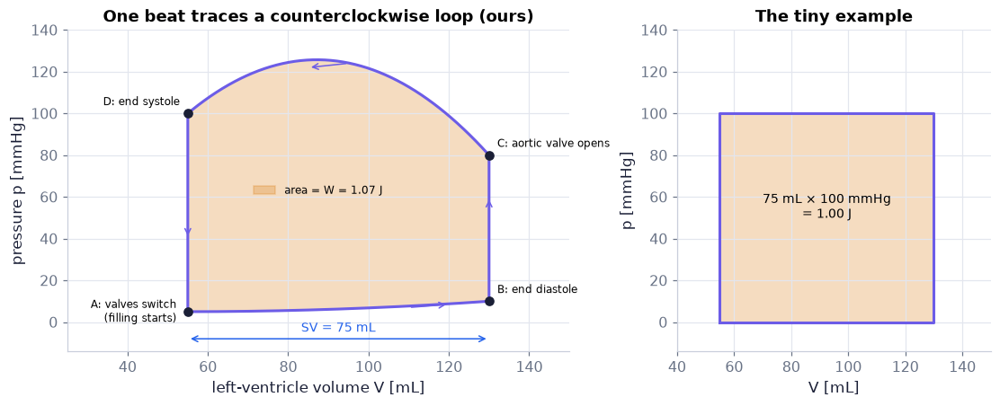

In [9]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 4.0), gridspec_kw=dict(width_ratios=[1.6, 1]))   # loop and the rectangle
Vml, pmm = loop["V"]*1e6, loop["p"]/MMHG                         # mL and mmHg for reading
ax.fill(Vml, pmm, color=COLORS["amber"], alpha=0.25, label=f"area = W = {w['work']:.2f} J")   # the work, shaded amber
ax.plot(np.r_[Vml, Vml[0]], np.r_[pmm, pmm[0]], color=COLORS["accent"], lw=2)   # the loop itself
names = {"A": "A: valves switch\n(filling starts)", "B": "B: end diastole", "C": "C: aortic valve opens", "D": "D: end systole"}   # corner labels (diastole/systole: N04 above)
offs = {"A": (-8, 0), "B": (6, 6), "C": (6, 6), "D": (-6, 6)}   # label offsets in points: A sits left of its corner, clear of the loop
for k, (Vc, pc) in loop["corners"].items():                      # label the four corners
    ax.plot(Vc*1e6, pc/MMHG, "o", color=COLORS["ink"])           # corner dot
    ax.annotate(names[k], (Vc*1e6, pc/MMHG), xytext=offs[k], textcoords="offset points",   # the corner's name beside its dot (text only, no arrow)
                ha="left" if k in "BC" else "right", va="center" if k == "A" else "baseline", fontsize=8)   # text alignment and size
for (x0, y0, x1, y1) in [(110, 7, 120, 8.5), (130, 40, 130, 60), (95, 124, 85, 122), (55, 60, 55, 40)]:   # direction arrows
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", color=COLORS["accent"]))   # an arrow with no text: the direction round the loop
ax.annotate("", xy=(130, -8), xytext=(55, -8), arrowprops=dict(arrowstyle="<->", color=COLORS["blue"]))   # width = SV
ax.text(92.5, -6, "SV = 75 mL", ha="center", va="bottom", color=COLORS["blue"], fontsize=9)   # a text label on the plot
ax.set(xlabel="left-ventricle volume V [mL]", ylabel="pressure p [mmHg]", ylim=(-14, 140), xlim=(25, 150),   # axis labels, limits and title
       title="One beat traces a counterclockwise loop (ours)")   # the figure's title: its message
ax.legend(loc="center", fontsize=8)   # the legend
bx.fill([55, 130, 130, 55], [0, 0, 100, 100], color=COLORS["amber"], alpha=0.25)   # the tiny example's rectangle
bx.plot([55, 130, 130, 55, 55], [0, 0, 100, 100, 0], color=COLORS["accent"])   # its outline: 75 mL wide, 100 mmHg tall
bx.text(92.5, 50, "75 mL × 100 mmHg\n= 1.00 J", ha="center", fontsize=9)   # a text label on the plot
bx.set(xlabel="V [mL]", ylabel="p [mmHg]", xlim=(40, 150), ylim=(-14, 140), title="The tiny example")   # axis labels, limits and title
savefig(fig, "ch16", "c01_pv_loop"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** Left: our schematic pressure–volume loop of the left ventricle, traced counterclockwise A → B → C → D, its
inside shaded amber; the blue arrow under it is the stroke volume. Right: the rectangle of the tiny example.

**How to read it.** The width (EDV − ESV) is the blood moved; the height is the pressure the ventricle must reach to open the aortic
valve; the shaded area is the work per beat, 1.07 J here. The two vertical sides (isovolumic phases) do no work although
the pressure changes most there — nothing moves.

**What would change if…** …the aorta were stiffer (C07)? The pressure during ejection would rise, lifting the top of the loop and its
area: the heart would work harder to push the same stroke volume.

In [10]:
nfr = 24 if FAST else 40                                      # frames for one beat
idx = np.linspace(0, len(loop["V"]) - 1, nfr).astype(int)     # points of the loop shown in turn
fig, (ax, bx) = plt.subplots(1, 2, figsize=(7.5, 3.4), gridspec_kw=dict(width_ratios=[1.6, 1]))   # a new figure and its axes
ax.plot(Vml, pmm, color=COLORS["grid"], lw=2)                 # the whole loop, faint
(trace,) = ax.plot([], [], color=COLORS["accent"], lw=2.5)    # the part traced so far
(dot,) = ax.plot([], [], "o", color=COLORS["orange"], ms=8)   # where the beat is now
ax.set(xlabel="V [mL]", ylabel="p [mmHg]", xlim=(40, 150), ylim=(-5, 140), title="The loop, traced over one beat (ours)")   # axis labels, limits and title
bx.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), aspect="equal"); bx.axis("off")   # the ventricle as a breathing chamber
chamber = plt.Circle((0, 0), 1.0, color=COLORS["rose"], alpha=0.4); bx.add_patch(chamber)   # a circle
label = bx.text(0, -1.15, "", ha="center", fontsize=9)   # a text label on the plot
def phase(k):                                                 # which valves are open at loop point k
    V_, p_ = loop["V"][k], loop["p"][k]                       # volume [m³] and pressure [Pa] at that point
    if np.isclose(V_, heart["EDV"]): return "both valves shut: contraction"   # right vertical leg (volume fixed at EDV)
    if np.isclose(V_, heart["ESV"]): return "both valves shut: relaxation"    # left vertical leg (volume fixed at ESV)
    return "aortic valve open: ejection" if p_ > 40*MMHG else "mitral valve open: filling"   # what this function hands back
def update(i):                                                # draw frame i
    k = idx[i]                                                # which loop point this frame shows
    trace.set_data(Vml[:k + 1], pmm[:k + 1]); dot.set_data([Vml[k]], [pmm[k]])   # move the artist to this frame
    chamber.set_radius((loop["V"][k]/heart["EDV"])**(1/3))    # chamber size ∝ V^(1/3)
    label.set_text(phase(k))   # move the artist to this frame
    return trace, dot, chamber, label   # what this function hands back
fig.canvas.draw(); fig.set_layout_engine("none")              # lay the figure out once, then freeze it (faster frames)
show_animation(animate(update, frames=nfr, fig=fig, interval=80), player="video")   # render the frames and embed the player

**What you see.** A dot runs round the loop over one beat while the chamber on the right swells (filling) and
shrinks (ejection); the line under the dot says which valves are open. **How to read it.** The chamber only changes size
on the bottom and top legs — on the vertical legs it stays the same size while the pressure jumps. **What would change
if…** a bigger stroke volume? The loop widens, the chamber's swing grows, and the area — the work — grows with it.

📝 **Note.** **N08 [B]** Pressures are quoted in mmHg; our illustrative 125/75 mmHg (systolic/diastolic, ours) = 16.7/10.0 kPa.
**N09 [B]** The pulse pressure $p_S-p_D$ = 50 mmHg is the size of the pressure wave; C07 shows how compliance sets it, C08 how
it travels.

In [11]:
print(ch16.mmHg_to_Pa(np.array([125, 75]))/1e3, "kPa")       # systolic and diastolic in kPa: 16.67, 10.0
print(ch16.pulse_pressure(heart["pS"], heart["pD"])/MMHG, "mmHg pulse pressure")   # p_S − p_D = 50 mmHg

[16.6653  9.9992] kPa
50.0 mmHg pulse pressure


> 📎 **Primer — the electrical analogy.** `P381` · A pressure difference drives a flow through a resistance as a voltage drives a
current: Δp ↔ V, Q ↔ I, R = Δp/Q ↔ Ohm's law. A vessel that stores volume when pressurised is a capacitor (compliance
K = dV/dp, C07); a tube's wave admittance Y = Q/p is the inverse of an impedance (C13). Resistors in series add; in parallel
their inverses add.

In [12]:
R = np.array([1.0, 2.0, 4.0])                  # three resistances (any units)
print(R.sum(), 1/np.sum(1/R))                  # series 7.0, parallel 0.571

7.0 0.5714285714285714


📝 **Note.** **N10 [B]** Mean pressure falls continuously from the aorta to the veins: each vessel class is a resistance in
series, $\Delta p_i=QR_i$ (ours). Below, our illustrative shares of the total resistance (labelled ours).

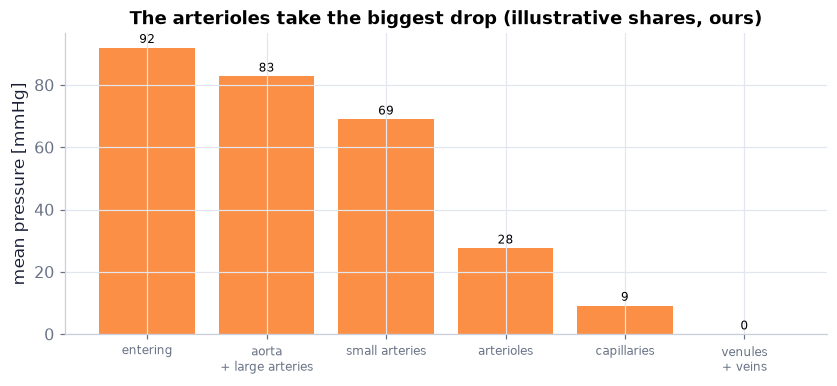

In [13]:
classes = ["aorta + large arteries", "small arteries", "arterioles", "capillaries", "venules + veins"]   # five classes in series
share = np.array([0.10, 0.15, 0.45, 0.20, 0.10])             # our illustrative shares of the total resistance
R_tot = 92*MMHG/CO                                            # total resistance that drops a 92 mmHg mean to 0 at our CO [Pa s/m³]
p_after = ch16.series_pressure_drop(list(share*R_tot), CO, 92*MMHG)   # pressure after each class [Pa]: p_in − Q ΣR_i
fig, ax = plt.subplots(figsize=(7.5, 3.4))   # a new figure and its axes
ax.bar(range(6), np.r_[92, p_after/MMHG], color=COLORS["orange"], alpha=0.8)   # pressure entering, then after each class
ax.set_xticks(range(6), ["entering"] + [c.replace(" + ", "\n+ ") for c in classes], fontsize=8)   # tick positions and their labels
ax.set(ylabel="mean pressure [mmHg]", title="The arterioles take the biggest drop (illustrative shares, ours)")   # axis labels, limits and title
for i, v in enumerate(np.r_[92, p_after/MMHG]): ax.text(i, v + 1.5, f"{v:.0f}", ha="center", fontsize=8)   # a text label on the plot
savefig(fig, "ch16", "c01_series_pressure"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** Orange bars: the mean pressure entering the arteries and after each vessel class, for our illustrative shares
of the total resistance.

**How to read it.** Each drop is the flow times that class's resistance, $\Delta p_i=QR_i$; the tallest step is across the
arterioles, which carry 45 % of the resistance in our split.

**What would change if…** …the arterioles narrowed by 10 %? Their resistance would grow by $1/0.9^4=1.52$ (C04): that is where the
body controls its blood pressure — C04 says why.

📝 **Note.** **N11 [B]** Continuity across the tree: the mean speed is $\bar u=Q/A_{tot}$ (ours). The capillaries are slow because
there are so many of them that their total area is huge.

> 🔁 **Recap — Mass conservation** (Ch. 4). What goes in comes out: for an incompressible fluid the flow rate Q is the same
through every level of the tree, so speed × total area is the same everywhere.

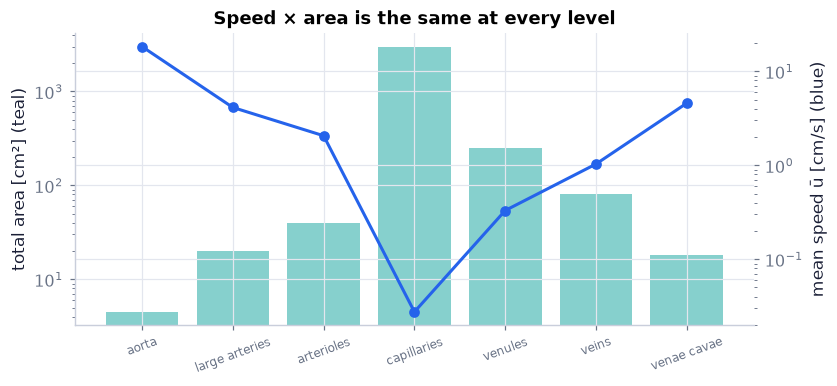

ū [cm/s]: [18.333  4.125  2.062  0.027  0.33   1.031  4.583]


In [14]:
lev = ["aorta", "large arteries", "arterioles", "capillaries", "venules", "veins", "venae cavae"]   # the levels of the tree, in flow order
A_tot = np.array([4.5, 20, 40, 3000, 250, 80, 18])*1e-4      # total cross-section of each level [m²] (illustrative orders of magnitude, ours)
u_bar = ch16.mean_speed(CO, A_tot)                            # ū = Q/A_tot [m/s]
fig, ax = plt.subplots(figsize=(7.5, 3.4)); bx = ax.twinx()  # area on the left axis, speed on the right
ax.bar(range(7), A_tot*1e4, color=COLORS["teal"], alpha=0.5, label="total area [cm²]")   # bars
bx.plot(range(7), u_bar*100, "o-", color=COLORS["blue"], label="mean speed [cm/s]")   # curve: mean speed [cm/s]
ax.set_yscale("log"); bx.set_yscale("log")   # logarithmic axis
ax.set_xticks(range(7), lev, fontsize=8, rotation=20)   # tick positions and their labels
ax.set(ylabel="total area [cm²] (teal)", title="Speed × area is the same at every level")   # axis labels, limits and title
bx.set_ylabel("mean speed ū [cm/s] (blue)")   # axis label or title
savefig(fig, "ch16", "c01_continuity"); plt.show()   # save to outputs/ch16/ and show the figure
print("ū [cm/s]:", np.round(u_bar*100, 3))                    # 18 cm/s in the aorta, 0.03 cm/s in the capillaries

**What you see.** Teal bars: total cross-section of each level of the tree (log scale, our orders of magnitude); blue dots: the mean
speed $\bar u=Q/A_{tot}$ at our cardiac output.

**How to read it.** The two curves are mirror images on log axes because their product is the same Q everywhere: the capillaries,
with by far the largest total area, are about 700 times slower than the aorta — time for exchange with the tissue.

**What would change if…** …the cardiac output doubled in exercise? Every blue dot would move up by a factor 2; the teal bars would
not move.

📝 **Note.** **N12 [B]** Total peripheral resistance $R=\dfrac{\Delta\bar p}{Q}$ (16.9) — the Ohm's law of the whole body; unit PRU = mmHg per cm³/s.
**N13 [B]** $\Delta\bar p=\bar p_A-\bar p_V$ (16.10) with $\bar p_V$ taken as 0 (trap T12). **N14 [B]** $\bar p_A=\tfrac13p_S+\tfrac23p_D$ (16.11): an estimate of the mean for a typical
waveform (trap T15).

In [15]:
pA = ch16.mean_arterial_pressure(heart["pS"], heart["pD"])  # (16.11): the ⅓-rule mean [Pa]
R_body = ch16.peripheral_resistance(pA, CO)                 # (16.9) with (16.10), venous pressure 0 [Pa s/m³]
print(f"mean ≈ {pA/MMHG:.1f} mmHg; R = {R_body:.3e} Pa s/m³ = {R_body/ch16.PRU:.2f} PRU (ours)")   # print the result

mean ≈ 91.7 mmHg; R = 1.481e+08 Pa s/m³ = 1.11 PRU (ours)


> ⚠️ **Common confusion:** (trap T15) $\bar p_A=\tfrac13p_S+\tfrac23p_D$ (16.11) is a rule of thumb for a typical waveform. C07 computes the true time mean of a model
waveform — the ⅓ rule is about 5 % low there.

📝 **Note.** **N05 [C]** Only a small fraction of the heart's metabolic power becomes pressure–volume work; most becomes heat. The
work per beat above (≈ 1 J) times the heart rate is the useful part.

**What would change if…** …the aorta were a rigid pipe? Then the pressure would follow the heart's ejection exactly and fall to zero between
beats. It does not — because the aorta stretches. C07 (the Windkessel) makes that precise; first, the fluid.

### 🧩 Blood thins when sheared: the Casson law $\sqrt{\dfrac{\tau}{\mu_p}}=k_c\sqrt{\dot\gamma}+\sqrt{\dfrac{\tau_y}{\mu_p}}$ (16.6) `C02`

*The question:* Is blood just thick water?

#### The problem in plain words

Honey is thick, water thin, and each has one viscosity whatever you do to it. Blood is different: stir it slowly and it
seems very thick, stir it fast and it thins. At rest its red cells stack into coin-like piles (rouleaux) that resist;
shearing breaks them up. And a tiny stress is needed before it flows at all — a **yield stress**.

#### The idea

```
√τ ↑        blood: a straight line that starts at √τ_y
   |       ╱
   |     ╱    ╱  Newtonian: a line through 0
   |   ╱    ╱
√τ_y ╱   ╱
   | ╱
   +──────────────► √γ̇
```

**A straight line in square roots, with an intercept** — that is Casson's law.

📝 **Note.** **N15 [B]** Blood in numbers (cited typical values, `ch16.BLOOD`): ρ = 1060 kg/m³, high-shear viscosity 3.5 mPa s,
plasma 1.2 mPa s, body temperature 310.15 K. **N16 [B]** A red cell is a flexible disc with far more surface than a sphere of
the same volume — a 90 µm³ cell would need only 97 µm² as a sphere (ours) — so it can fold through capillaries narrower than
itself (C05). **N17 [B]** Hematocrit H: the volume fraction of red cells, about 0.45 (45 %). Fraction in code, per cent in
prose (trap T13).

In [16]:
print(pd.Series(ch16.BLOOD).to_dict())                      # rho [kg/m³], mu [Pa s], mu_p [Pa s], T [K]
print(f"{ch16.equal_volume_sphere_area(90e-18)*1e12:.0f} µm²")   # area of a sphere holding 90 µm³: (36π V²)^(1/3) = 97 µm²
try:                                                        # a hematocrit passed as a per cent by mistake …
    ch16._check_hematocrit(45)                              # 45 instead of 0.45: the module's guard raises an error
except ValueError as e:                                     # … is refused with a message (trap T13)
    print("refused:", e)   # print the result

{'rho': 1060.0, 'mu': 0.0035, 'mu_p': 0.0012, 'T': 310.15}
97 µm²
refused: hematocrit must be a FRACTION (e.g. 0.45), not a percent (trap T13)


**What does the code above do?**

1. `pd.Series(...).to_dict()` prints the blood constants as a plain dictionary.
2. `equal_volume_sphere_area` gives the area of a sphere holding a red cell's volume: 97 µm², far less than the cell's.
3. `try` / `except ValueError` (Python's error handling, primed in earlier chapters): Python runs the `try` block; if a call
   inside it raises a `ValueError`, the notebook does not stop — it jumps to the `except` block, where `e` is the error and
   its message. Here the guard refuses a hematocrit of 45 (a per cent) because the code expects the fraction 0.45.

📝 **Note.** **N18 [B]** Non-Newtonian: the ratio of stress to shear rate is not a constant. The units box:
$1\,\mathrm{cP}=10^{-2}\,\mathrm P=10^{-2}\,\mathrm{dyn\,s/cm^2}=10^{-3}\,\mathrm{Pa\,s}$.

> ⚠️ **slip S27 — the book prints** the chain 1 cP = 0.01 P = 1 dyn s/cm² = 0.1 N s/m²; **the correct form is** $1\,\mathrm{cP}=10^{-2}\,\mathrm P=10^{-2}\,\mathrm{dyn\,s/cm^2}=10^{-3}\,\mathrm{Pa\,s}$
>
> The printed chain is 100 times too large from its third member on (1 P = 1 dyn s/cm² = 0.1 Pa s).

In [17]:
print(ch16.cP_to_Pa_s(1.0), UN.Q_(1, "cP").to("Pa*s"))    # 0.001 Pa s twice: the corrected chain

0.001 0.001 pascal * second


> 🔁 **Recap — Newton's law of viscosity `R01`** (Ch. 1 §1.5 (C12)). $\tau=\mu\dfrac{du}{dy}$ (1.3): stress proportional to shear rate, one constant μ. **New here:** for blood
τ/γ̇ is not constant — the Newtonian line becomes the ghost every figure of this block compares with.

In [18]:
print(ch01.newton_shear_stress(3.5e-3, 100.0), ch16.newtonian_stress(100.0, 3.5e-3))   # (1.3): 0.35 Pa twice (μ = 3.5 mPa s, γ̇ = 100 s⁻¹)

0.35000000000000003 0.35000000000000003


📝 **Note.** **N19 [B]** The yield stress: below τ_y blood does not shear at all. An empirical correlation $\sqrt{\tau_y}=(H-0.1)(C_F+0.5)$ (16.5) — with **hidden
units said aloud**: τ_y in dyn/cm², H a fraction above 0.1, fibrinogen $C_F$ in g/100 mL. The book's quoted range at H = 0.45
does not quite match what $\sqrt{\tau_y}=(H-0.1)(C_F+0.5)$ (16.5) gives over its stated $C_F$ range (slip S29).

In [19]:
ty_corr = ch16.yield_stress_correlation(0.45, 0.3)          # (16.5) at H = 0.45, C_F = 0.3 g/100 mL, converted to Pa
print(f"tau_y = {ty_corr:.3e} Pa = {ty_corr/0.1:.4f} dyn/cm²")   # 7.84e-3 Pa = 0.0784 dyn/cm²

tau_y = 7.840e-03 Pa = 0.0784 dyn/cm²


📝 **Note.** **N20 [C]** Why it thins: rouleaux break up as the shear rate rises; above a threshold the cells move singly. Drawn as two
shaded regions on the figure below; the asymptote is $K_c^2$ (D02).

> 🔁 **Tools from earlier chapters used in this block** (one line each; the full primers are in the chapters named)

- **ordinary derivative as a slope** — dy/dx is the slope of the tangent to the curve y(x); here it is the stress needed per extra unit of shear rate. *(Ch. 1, P19)*
- **power laws and log–log axes** — on log–log axes y = Cxⁿ is a straight line of slope n; here the resistance a⁻⁴ shows as slope −4 and the apparent viscosity bends toward its asymptote. *(Ch. 1, P13)*
- **`np.where` for a piecewise law** — `np.where(cond, A, B)` picks A where the condition holds and B elsewhere, element by element; here it gives zero shear rate below the yield stress. *(Ch. 1, P46)*

> 📎 **Primer — secant slope and tangent slope.** `P383` · On a curve y(x) the secant from the origin to a point has slope y/x; the
tangent at that point has slope dy/dx (P19). For a straight line through 0 they agree; for a bending curve they do not.
Blood's "apparent viscosity" τ/γ̇ is the secant (trap T27).

In [20]:
x = 4.0; y = lambda x: (0.07 + 0.053*np.sqrt(x))**2          # a Casson-like curve (lambda: a one-line function, Ch. 1 P29)
h = 1e-6                                                     # a small step for the centred difference
print(y(x)/x, (y(x + h) - y(x - h))/(2*h))                  # secant 0.00774 > tangent 0.00466

0.007743999999999999 0.004664000000445534


📝 **Note.** **N21 [B]** Apparent viscosity $\mu_{app}=\tau/\dot\gamma$ — the secant (`ch16.apparent_viscosity`); the tangent
$d\tau/d\dot\gamma$ is `ch16.differential_viscosity`.

#### 🧮 Derivation — The Casson apparent viscosity and its limits `D02` ★ (Eq. 16.6: $\sqrt{\dfrac{\tau}{\mu_p}}=k_c\sqrt{\dot\gamma}+\sqrt{\dfrac{\tau_y}{\mu_p}}$)

**What we want to show.** Find how thick blood *seems* at each shear rate according to Casson's law, and what happens when it is sheared very fast or hardly at all.

**Assumptions.** a homogeneous fluid obeying $\sqrt{\dfrac{\tau}{\mu_p}}=k_c\sqrt{\dot\gamma}+\sqrt{\dfrac{\tau_y}{\mu_p}}$ (16.6) at every shear rate (start).

**The plan.**

1. Write the law with one dimensional constant.
2. Square.
3. Divide by γ̇.
4. Take the two limits.

**Tools we use** (each explained before this point): secant against tangent (P383, primer in C02) · squaring a sum, $(x+y)^2=x^2+2xy+y^2$

**We start from**

$$ \sqrt{\tau/\mu_p}=k_c\sqrt{\dot\gamma}+\sqrt{\tau_y/\mu_p}\ \text{(16.6) and the definition}\ \mu_{app}=\tau/\dot\gamma $$

*In words:* a straight line in √τ against √γ̇; apparent viscosity is stress over rate

---

**Step 1 of 5 — Multiply the law by $\sqrt{\mu_p}$.**

$$ \sqrt\tau=\sqrt{\tau_y}+K_c\sqrt{\dot\gamma},\quad K_c=k_c\sqrt{\mu_p} $$

- *Why we can do this:* Multiplying both sides by the positive number √μ_p keeps the equality; it turns $\sqrt{\dfrac{\tau}{\mu_p}}=k_c\sqrt{\dot\gamma}+\sqrt{\dfrac{\tau_y}{\mu_p}}$ (16.6) into the form of $\tau^{1/2}=\tau_y^{1/2}+K_c\dot\gamma^{1/2}\ (\tau\ge\tau_y),\ \ \dot\gamma=0\ (\tau<\tau_y)$ (16.207). k_c is a pure number, K_c has units (Pa s)^½ (trap T14).
- *In words:* The book's two ways of writing Casson's law are one law.

---

**Step 2 of 5 — Square both sides.**

$$ \tau=\left(\sqrt{\tau_y}+K_c\sqrt{\dot\gamma}\right)^2 $$

- *Why we can do this:* Both sides are positive, so squaring keeps the equality; we need τ itself to form τ/γ̇.
- *In words:* The stress needed to shear blood at a rate γ̇.

---

**Step 3 of 5 — Divide by the shear rate.**

$$ \mu_{app}=\dfrac{\tau}{\dot\gamma}=\left(\sqrt{\dfrac{\tau_y}{\dot\gamma}}+K_c\right)^2 $$

- *Why we can do this:* The definition of the apparent viscosity — the slope of the secant from the origin (P383). Dividing a square by γ̇ divides each term inside by √γ̇.
- *In words:* How viscous the blood looks at this shear rate.

---

**Step 4 of 5 — Let the shear rate grow large.**

$$ \dot\gamma\to\infty:\ \ \mu_{app}\to K_c^2=k_c^2\mu_p $$

- *Why we can do this:* √(τ_y/γ̇) → 0; what is left is K_c². With Whitmore's $k_c=1.53$ of $\sqrt{\dfrac{\tau}{\mu_p}}=1.53\sqrt{\dot\gamma}+2.0$ (16.7), $K_c^2=2.34\,\mu_p$.
- *In words:* Sheared hard, blood behaves like a Newtonian liquid about 2.3 times as viscous as plasma.

---

**Step 5 of 5 — Let the shear rate go to zero.**

$$ \dot\gamma\to0:\ \ \mu_{app}\approx\dfrac{\tau_y}{\dot\gamma}\to\infty $$

- *Why we can do this:* Now √(τ_y/γ̇) dominates K_c, and its square is τ_y/γ̇: a finite stress divided by a vanishing rate.
- *In words:* Almost at rest, blood seems infinitely viscous: it can hold a small stress without flowing.

---

**Result**

$$ \mu_{app}=\left(\sqrt{\tau_y/\dot\gamma}+K_c\right)^2\ \text{(ours)} $$

*In words:* Falls from infinity at rest to $K_c^2$ at high shear

**What it means.** Blood is shear-thinning with a yield stress: slow flows (veins at rest, small vessels) feel a much higher viscosity than fast ones. Fails below a few per cent hematocrit (no yield stress) and in tubes so narrow that blood is not homogeneous (C05).

**Check it.** Units — √(Pa/s⁻¹) = (Pa s)^½, the same as K_c ✓; τ_y = 0 gives μ_app = K_c², a Newtonian fluid ✓; numbers with $\sqrt{\dfrac{\tau}{\mu_p}}=1.53\sqrt{\dot\gamma}+2.0$ (16.7) and μ_p = 1.2 mPa s: γ̇ = 4 s⁻¹ → μ_p(2/2 + 1.53)² = 6.40 μ_p = **7.68 mPa s**; γ̇ = 400 s⁻¹ → (0.1 + 1.53)² μ_p = **3.19 mPa s**; the tangent dτ/dγ̇ at 4 s⁻¹ is only 4.65 mPa s (T27).

> ⚠️ **Common confusion (traps in `D02`):** The apparent viscosity is the secant τ/γ̇, not the tangent dτ/dγ̇ (T27); 1.53 is k_c, dimensionless, not K_c (T14).

📝 **Note.** **N22 [B]** Whitmore's fit $\sqrt{\dfrac{\tau}{\mu_p}}=1.53\sqrt{\dot\gamma}+2.0$ (16.7): $k_c$ = 1.53 (a pure number) and $\sqrt{\tau_y/\mu_p}$ = 2.0 s$^{-1/2}$, so
$\tau_y=4\mu_p$ (in Pa when μ_p is in Pa s and the 2.0 in s$^{-1/2}$) and $K_c^2=1.53^2\mu_p=2.34\mu_p$. Two ways to write the
constants (trap T14):

| Constant | Units | In |
|---|---|---|
| $k_c$ | none | $\sqrt{\dfrac{\tau}{\mu_p}}=k_c\sqrt{\dot\gamma}+\sqrt{\dfrac{\tau_y}{\mu_p}}$ (16.6) |
| $K_c=k_c\sqrt{\mu_p}$ | (Pa s)$^{1/2}$ | $\tau^{1/2}=\tau_y^{1/2}+K_c\dot\gamma^{1/2}\ (\tau\ge\tau_y),\ \ \dot\gamma=0\ (\tau<\tau_y)$ (16.207) |

In [21]:
wc = ch16.whitmore_casson(np.array([4.0, 400.0]), blood["mu_p"], k_c=casson["k_c"], s0=casson["s0"])   # (16.7) at γ̇ = 4 and 400 s⁻¹
ty, Kc = wc["tau_y"], wc["Kc"]                               # yield stress [Pa] and K_c [(Pa s)^½]
print(f"tau_y = {ty*1e3:.2f} mPa, Kc = {Kc:.5f} (Pa s)^½, Kc² = {Kc**2*1e3:.3f} mPa s")   # print the result
print("mu_app [mPa s]:", np.round(wc["mu_app"]*1e3, 2), "| tangent [mPa s]:", np.round(wc["mu_tangent"]*1e3, 2))   # print the result

tau_y = 4.80 mPa, Kc = 0.05300 (Pa s)^½, Kc² = 2.809 mPa s
mu_app [mPa s]: [7.68 3.19] | tangent [mPa s]: [4.65 2.99]


#### ✏️ Tiny example: apparent viscosity at two shear rates

With Whitmore's constants and μ_p = 1.2 mPa s:
1. √τ_y = √($4.8$ × 10⁻³) = 0.0693; K_c = 1.53 × √0.0012 = 0.0530.
2. γ̇ = 4 s⁻¹: √τ = 0.0693 + 0.0530 × 2 = 0.1753, τ = 30.7 mPa, μ_app = 30.7/4 = **7.68 mPa s** ($6.4$ μ_p).
3. γ̇ = 400 s⁻¹: √τ = 0.0693 + 0.0530 × 20 = 1.129, τ = 1.275 Pa, μ_app = **3.19 mPa s** ($2.66$ μ_p).
4. γ̇ → ∞: μ_app → K_c² = **2.81 mPa s**.

Slow shear makes blood look 2.7 times as viscous as fast shear.

In [22]:
gd = np.logspace(-1, 3, 200)                                # shear rates 0.1 … 1000 s⁻¹
tau = ch16.casson_stress(gd, ty, Kc)                        # (16.207): (√τ_y + K_c √γ̇)² [Pa]
mu_app = ch16.casson_apparent_viscosity(gd, ty, Kc)         # secant τ/γ̇ = (√(τ_y/γ̇) + K_c)² [Pa s] (D02)
mu_tan = ch16.differential_viscosity(gd, ty, Kc)            # tangent dτ/dγ̇ [Pa s] (trap T27)
gd_back = ch16.casson_shear_rate(tau, ty, Kc)               # invert the law: γ̇ from τ
print("round trip max error:", np.max(np.abs(gd_back - gd)/gd))   # ≈ 1e-15
print("below yield:", ch16.casson_shear_rate(np.array([0.5*ty, 0.99*ty]), ty, Kc))   # zero shear rate under τ_y

round trip max error: 8.003391950652821e-16
below yield: [0. 0.]


In [23]:
tau_mine = (np.sqrt(ty) + Kc*np.sqrt(gd))**2                 # (16.207) by hand
gd_mine = np.where(tau_mine >= ty, ((np.sqrt(tau_mine) - np.sqrt(ty))/Kc)**2, 0.0)   # inverse, zero below yield (np.where, P46)
assert np.allclose(tau_mine, ch16.casson_stress(gd, ty, Kc))     # same stress
assert np.allclose(gd_mine, ch16.casson_shear_rate(tau_mine, ty, Kc))   # same inverse
print("from-scratch Casson law agrees")   # print the result

from-scratch Casson law agrees


**What does the code above do?**

The law written by hand in one line, its inverse with `np.where` (zero shear rate below the yield stress), and two
asserts: the library computes exactly this.

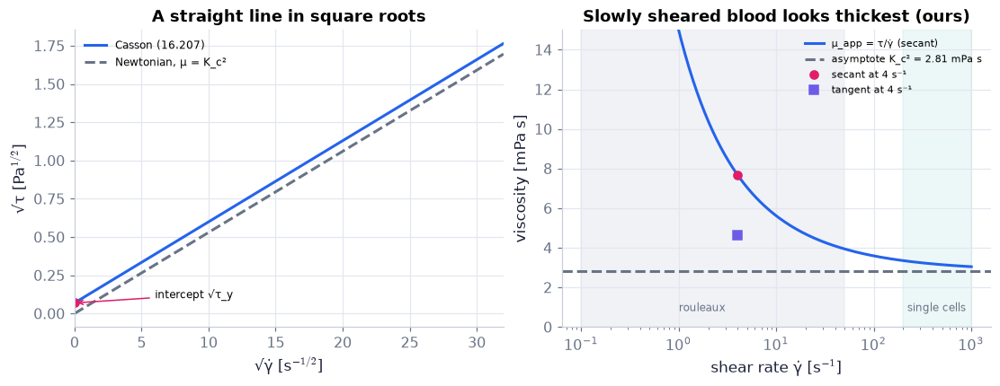

In [24]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.8))   # a new figure and its axes
sg = np.linspace(0, 32, 200)                                   # √γ̇ axis [s^-1/2]
ax.plot(sg, np.sqrt(ty) + Kc*sg, color=COLORS["blue"], lw=2, label="Casson (16.207)")   # curve: Casson (16.207)
ax.plot(sg, Kc*sg, "--", color=COLORS["muted"], label="Newtonian, μ = K_c²")   # curve: Newtonian, μ = K_c²
ax.plot(0, np.sqrt(ty), "o", color=COLORS["rose"]); ax.annotate("intercept √τ_y", (0, np.sqrt(ty)), xytext=(6, 0.1), fontsize=8,   # a label with an arrow
       arrowprops=dict(arrowstyle="->", color=COLORS["rose"]))   # rose dot and arrow: the yield-stress intercept √τ_y
ax.set(xlabel="√γ̇ [s$^{-1/2}$]", ylabel="√τ [Pa$^{1/2}$]", title="A straight line in square roots", xlim=(0, 32))   # axis labels, limits and title
ax.legend(fontsize=8)   # the legend
bx.semilogx(gd, mu_app*1e3, color=COLORS["blue"], lw=2, label="μ_app = τ/γ̇ (secant)")   # curve: μ_app = τ/γ̇ (secant)
bx.axhline(Kc**2*1e3, ls="--", color=COLORS["muted"], label=f"asymptote K_c² = {Kc**2*1e3:.2f} mPa s")   # a reference line
bx.plot(4, wc["mu_app"][0]*1e3, "o", color=COLORS["rose"], label="secant at 4 s⁻¹")   # curve: secant at 4 s⁻¹
bx.plot(4, wc["mu_tangent"][0]*1e3, "s", color=COLORS["accent"], label="tangent at 4 s⁻¹")   # curve: tangent at 4 s⁻¹
bx.axvspan(0.1, 50, color=COLORS["grid"], alpha=0.5); bx.text(1, 0.8, "rouleaux", fontsize=8, color=COLORS["muted"])   # a shaded band
bx.axvspan(200, 1000, color=COLORS["teal"], alpha=0.08); bx.text(220, 0.8, "single cells", fontsize=8, color=COLORS["muted"])   # a shaded band
bx.set(xlabel="shear rate γ̇ [s$^{-1}$]", ylabel="viscosity [mPa s]", ylim=(0, 15),   # axis labels, limits and title
       title="Slowly sheared blood looks thickest (ours)")   # the figure's title: its message
bx.legend(fontsize=7, loc="upper right")   # the legend
savefig(fig, "ch16", "c02_casson"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** Left: Casson's law as a straight blue line in √τ against √γ̇, cutting the axis at √τ_y; the Newtonian line of the
same high-shear viscosity passes through the origin (grey dashed). Right: the apparent viscosity (secant, blue) falling from
large values at low shear to the asymptote $K_c^2$; the rose dot and the purple square are the secant and tangent at
4 s⁻¹; the shaded bands mark (illustrative) the rouleaux and single-cell regimes.

**How to read it.** The intercept is the yield stress: you need a finite √τ before any shear starts. At 4 s⁻¹ the secant is 7.7 mPa s
but the tangent only 4.6 mPa s — they are different numbers, and "apparent viscosity" means the secant.

**What would change if…** …we doubled τ_y? Only the low-shear end of the right panel rises; the asymptote $K_c^2$ does not move, because
at high shear the yield term $\sqrt{\tau_y/\dot\gamma}$ vanishes.

In [25]:
ty_vals = list(np.round(np.linspace(0.0, 0.02, 25), 5))      # yield stresses 0 … 20 mPa (25 positions)
ty_vals[6] = round(ty, 5)                                     # include Whitmore's 4.8 mPa
def curves(t_y):                                              # three traces for one yield stress
    return {"μ_app (secant)": (gd, ch16.casson_apparent_viscosity(gd, t_y, Kc)*1e3),   # what this function hands back
            "K_c² (asymptote)": (gd, Kc**2*1e3 + 0*gd),   # (continued from the line above)
            "tangent dτ/dγ̇": (gd, ch16.differential_viscosity(gd, t_y, Kc)*1e3)}   # (continued from the line above)
fig = slider_figure(curves, "τ_y", ty_vals, unit="Pa", xlabel="shear rate γ̇ [1/s] (log)", ylabel="viscosity [mPa s]",   # build the slider figure (every position computed now)
                    title="The yield stress lifts only the slow-shear end", xrange=[-1, 3], yrange=[0, 30], active=6)   # the figure's title: its message
fig.update_xaxes(type="log")                                  # log shear-rate axis (its range is in powers of ten: 0.1 … 1000)
fig.show()   # display the figure
for t_y in (ty, 0.02):                                        # Whitmore's τ_y and the slider's largest, 20 mPa
    over = ch16.casson_apparent_viscosity(np.array([200.0, 1000.0]), t_y, Kc)/Kc**2 - 1   # how far above K_c² at 200 and 1000 s⁻¹
    print(f"τ_y = {t_y*1e3:.1f} mPa: μ_app is {100*over[0]:.0f} % above K_c² at 200 s⁻¹, {100*over[1]:.0f} % at 1000 s⁻¹")   # print the result

τ_y = 4.8 mPa: μ_app is 19 % above K_c² at 200 s⁻¹, 8 % at 1000 s⁻¹
τ_y = 20.0 mPa: μ_app is 41 % above K_c² at 200 s⁻¹, 18 % at 1000 s⁻¹


**Figure F1.** Slider: the yield stress τ_y from 0 to 20 mPa (opens on Whitmore's 4.8 mPa); every slider position
was computed in Python when the cell ran (P17), so the figure works on the web page. **What you see.** The secant (apparent)
and tangent viscosities against shear rate, with the asymptote $K_c^2$. **How to read it.** At τ_y = 0 the three lines are
one: a Newtonian fluid. **What would change if…** you slide τ_y up: the curves lift most at the left and approach $K_c^2$
only slowly at high shear — with Whitmore's τ_y the secant is still 19 % above $K_c^2$ at 200 s⁻¹ and 8 % above at
1000 s⁻¹, and with τ_y = 20 mPa 41 % and 18 % (printed under the figure), because the yield term
$\sqrt{\tau_y/\dot\gamma}$ fades only like $\dot\gamma^{-1/2}$.

📝 **Note.** **N23 [C]** Casson's law treats blood as a homogeneous fluid. In tubes below about a third of a millimetre the cells
leave a plasma layer at the wall — C05 models exactly that.

**What would change if…** …we pushed this blood through a pipe? The stress is zero on the axis and largest at the wall, so near the axis it is
below τ_y: the centre moves as a solid plug. C16 works that out; the explainer embedded there lets you watch it.

---

## 16.3 Modeling of Flow in Blood Vessels

**What is this section about?** The long modelling section, read in four arcs: steady flow (C04, C05); storage and waves in elastic tubes (C06–C08); oscillating flow (C09–C11); geometry and odd materials (C12–C16). One number, α, decides which arc's tools a vessel needs.

### 🧩 One number for every vessel: the Womersley number $\alpha=a\sqrt{\omega/\nu}$ (16.12) `C03`

*The question:* When can the pulsing flow in a vessel be treated as steady, and when not?

#### The problem in plain words

Shake a glass of water gently and the whole glass of water moves together; shake a bathtub and only the water near the
walls notices the walls. Viscosity spreads a disturbance only so far in one cycle — about $\sqrt{\nu/\omega}$. Compare that
distance with the vessel's radius: **that comparison is α**. A capillary is far thinner than this distance (α ≪ 1); the
aorta far wider (α ≫ 1).

#### The idea

```
|←──────── a ────────→|      the vessel radius
|←δ_e→|                      the Stokes layer √(2ν/ω): how far viscosity reaches in one cycle

small α:  the layer fills the tube       large α:  a thin skin at the wall, an inertial core
```

$\alpha=\sqrt2\,a/\delta_e$ (D03 below).

> 🔁 **Recap — Separation in an adverse pressure gradient `R02`** (Ch. 9 §9.7). A boundary layer pushed against a rising pressure can stop and
turn back (Ch. 9). **New here:** in a pulse the deceleration phase supplies that rising pressure every beat — reversal near
the wall in C09 is its oscillating cousin.

> 🔁 **Recap — Stokes' second problem** (Ch. 8 C11). $u(y,t)=U\exp\{-y\sqrt{\omega/2\nu}\}\cos(\omega t-y\sqrt{\omega/2\nu})$ (8.38): a wall oscillating in its own plane drags a layer whose
e-folding depth is $\delta_e=\sqrt{2\nu/\omega}$ (`LAM.stokes_layer`).

#### 🧮 Derivation — What the Womersley number compares `D03` ★ (Eq. 16.12: $\alpha=a\sqrt{\omega/\nu}$)

**What we want to show.** Show what the Womersley number compares — the oscillation's inertia with viscosity, or the vessel with its Stokes layer.

**Assumptions.** The book's definitions of Re and St (step 1, trap T6).

**The plan.**

1. Multiply Re by St.
2. Compare with α².
3. Write ω/ν with δ_e.
4. Substitute.

**Tools we use** (each explained before this point): algebra · the Stokes-layer depth of Ch. 8 (recap above)

**We start from**

$$ \begin{array}{l}\alpha=a\sqrt{\omega/\nu}\ \text{(16.12); the chapter's}\ Re=2au/\nu\ \text{and}\ St=2a\omega/u\ \text{(both on the diameter); the} \\ \text{Stokes-layer thickness}\ \delta_e=\sqrt{2\nu/\omega}\ \text{(Ch. 8, the e-folding depth of} \\ u(y,t)=U\exp\{-y\sqrt{\omega/2\nu}\}\cos(\omega t-y\sqrt{\omega/2\nu})\ \text{(8.38)).}\end{array} $$

---

**Step 1 of 4 — Multiply the two groups.**

$$ Re\cdot St=\dfrac{2au}{\nu}\cdot\dfrac{2a\omega}{u}=\dfrac{4a^2\omega}{\nu} $$

- *Why we can do this:* Plain multiplication; the speed u cancels, which is why α can be quoted for a vessel without knowing how fast the blood moves.
- *In words:* Unsteadiness times inertia over viscosity, with no speed left.

---

**Step 2 of 4 — Compare with α squared.**

$$ \alpha^2=\dfrac{a^2\omega}{\nu}=\dfrac{Re\cdot St}{4} $$

- *Why we can do this:* Square $\alpha=a\sqrt{\omega/\nu}$ (16.12) and divide step 1 by 4. Other sources define Re and St differently and write $\alpha^2=2\pi\,Re\,St$ (trap T6).
- *In words:* α² is a quarter of the product of the book's Reynolds and Strouhal numbers.

---

**Step 3 of 4 — Write ω/ν with the Stokes layer.**

$$ \dfrac{\omega}{\nu}=\dfrac{2}{\delta_e^2} $$

- *Why we can do this:* Square $\delta_e=\sqrt{2\nu/\omega}$ and invert; δ_e is how far an oscillation diffuses into a fluid in one radian of its cycle.
- *In words:* Frequency over viscosity is fixed by the Stokes-layer thickness.

---

**Step 4 of 4 — Substitute into (16.12).**

$$ \alpha=a\sqrt{\dfrac{2}{\delta_e^2}}=\sqrt2\,\dfrac{a}{\delta_e} $$

- *Why we can do this:* Replace ω/ν by step 3; the square root of 2/δ_e² is √2/δ_e.
- *In words:* α compares the vessel radius with the thickness of the viscous layer at its wall.

---

**Result**

$$ \alpha^2=Re\,St/4\ \text{and}\ \alpha=\sqrt2\,a/\delta_e\ \text{(ours).} $$

**What it means.** α ≪ 1: the viscous layer is wider than the vessel — viscosity controls every point (quasi-steady); α ≫ 1: the layer is a thin skin and the core moves by inertia. Fails as a guide when the flow is not periodic.

**Check it.** Both sides dimensionless ✓; easy numbers: a = 5 mm, ω = 4 rad/s, ν = 4 × 10⁻⁶ m²/s → α = 0.005 × √(10⁶) = **5**; with u = 0.2 m/s, Re = 500, St = 0.2, Re·St/4 = 25 = α² ✓; δ_e = √(2 × 4 × 10⁻⁶/4) = 1.414 mm and √2 × 5/1.414 = 5 ✓.

> ⚠️ **Common confusion (traps in `D03`):** Re and St on the diameter (T6); α is built from the radius.

#### ✏️ Tiny example: α for an artery

1. Radius a = 2 mm, heart rate 66 per minute → ω = 2π × 66/60 = 6.91 rad/s.
2. ν = μ/ρ = 3.5 × 10⁻³/1060 = 3.30 × 10⁻⁶ m²/s.
3. ω/ν = 2.09 × 10⁶ m⁻², its square root 1447 m⁻¹.
4. α = 0.002 × 1447 = **2.9**.
5. δ_e = √(2ν/ω) = **0.98 mm**: the viscous layer reaches halfway to the axis — neither limit.

In [26]:
omega = 2*np.pi*heart["HR"]/60                              # angular frequency of the heartbeat [rad/s]
nu = blood["mu"]/blood["rho"]                               # kinematic viscosity of blood [m²/s]
alpha_art = ch16.womersley_number(artery["a"], omega, nu)   # (16.12): α = a √(ω/ν) for our 2-mm artery
d_e = LAM.stokes_layer(nu, omega)["delta_e"]                # Stokes-layer depth √(2ν/ω) [m] (Ch. 8)
print(f"omega = {omega:.3f} rad/s, nu = {nu:.4e} m²/s, alpha = {alpha_art:.4f}, delta_e = {d_e*1e3:.3f} mm")   # print the result
print("sqrt(2) a/delta_e =", np.sqrt(2)*artery["a"]/d_e)    # D03: the same α another way
print("from Re, St:", ch16.womersley_from_re_st(500.0, 0.2), "| regime:", ch16.womersley_regime(alpha_art))   # √(Re·St/4) = 5
print("our aorta (a = 12 mm):", round(ch16.womersley_number(aorta["a0"], omega, nu), 1))   # print the result
tab = ch16.vessel_scales_table(HR=66.0)                     # cited typical vessel sizes (ours): Re, α, h/a per class
display(tab.round(4))                                       # the table, rounded to 4 decimals

omega = 6.912 rad/s, nu = 3.3019e-06 m²/s, alpha = 2.8936, delta_e = 0.977 mm
sqrt(2) a/delta_e = 2.8935779271979722
from Re, St: 5.0 | regime: transitional
our aorta (a = 12 mm): 17.4


,vessel,a,h,u_mean,Re,alpha,h_over_a,regime
0,aorta,0.0110,0.0016,0.2500,1665.7143,15.9147,0.1455,inertial
1,large artery,0.0015,0.0004,0.1200,109.0286,2.1702,0.3000,transitional
2,arteriole,0.0000,0.0000,0.0050,0.0606,0.0289,0.6000,quasi-steady
3,capillary,0.0000,0.0000,0.0005,0.0012,0.0058,0.1250,quasi-steady
4,venule,0.0000,0.0000,0.0020,0.0145,0.0174,0.0833,quasi-steady
5,vein,0.0020,0.0002,0.0500,60.5714,2.8936,0.1000,transitional
6,vena cava,0.0140,0.0011,0.1200,1017.6000,20.2550,0.0786,inertial


**What does the code above do?**

1. `womersley_number` evaluates $\alpha=a\sqrt{\omega/\nu}$ (16.12) for the artery: 2.89. `LAM.stokes_layer` (Ch. 8) gives the depth 0.98 mm, and
   $\sqrt2\,a/\delta_e$ gives the same α — D03 in numbers.
2. `womersley_from_re_st` uses the book's diameter-based Re and St: with Re = 500 and St = 0.2, α = √(100/4) = 5.
3. `vessel_scales_table` lists seven vessel classes with cited typical sizes and speeds (labelled cited/ours) and their Re
   and α at 66 beats per minute. Our 12-mm aorta gives 17.4; the table's 11-mm aorta 15.9.

📝 **Note.** **N24 [B]** (From §16.2, out of book order.) Vessel walls have three layers (intima, media, adventitia); sizes run from
centimetre aortas to micrometre capillaries; veins hold most of the blood. Our scales table uses cited typical sizes
(labelled cited/ours) and gives Re, α and h/a for each class — the table the figure below plots.

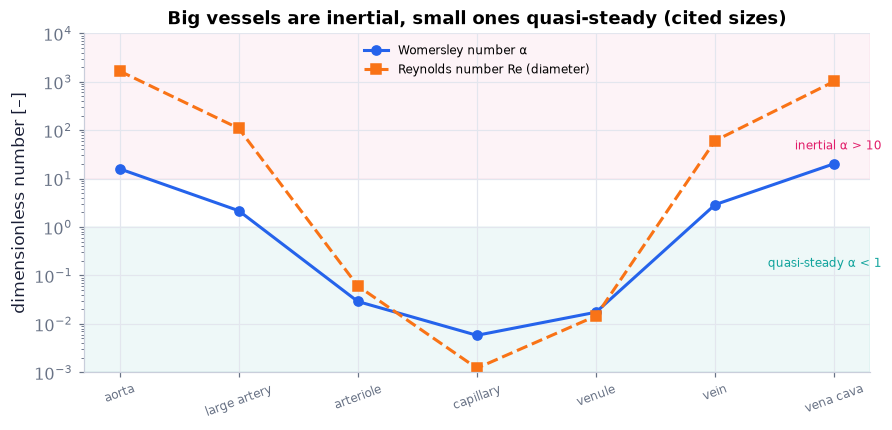

aorta → capillary: Re falls 6.1 decades, α falls 3.4 decades


In [27]:
fig, ax = plt.subplots(figsize=(8, 3.8))   # a new figure and its axes
xs = np.arange(len(tab))                                      # one position per vessel class
ax.semilogy(xs, tab["alpha"], "o-", color=COLORS["blue"], label="Womersley number α")   # curve: Womersley number α
ax.semilogy(xs, tab["Re"], "s--", color=COLORS["orange"], label="Reynolds number Re (diameter)")   # curve: Reynolds number Re (diameter)
ax.axhspan(1e-3, 1, color=COLORS["teal"], alpha=0.07); ax.axhspan(10, 1e4, color=COLORS["rose"], alpha=0.05)   # a shaded band
ax.text(len(tab) - 0.6, 0.15, "quasi-steady α < 1", ha="right", fontsize=8, color=COLORS["teal"])   # a text label on the plot
ax.text(len(tab) - 0.6, 40, "inertial α > 10", ha="right", fontsize=8, color=COLORS["rose"])   # a text label on the plot
ax.set_xticks(xs, tab["vessel"], rotation=20, fontsize=8)   # tick positions and their labels
ax.set(ylabel="dimensionless number [–]", ylim=(1e-3, 1e4), title="Big vessels are inertial, small ones quasi-steady (cited sizes)")   # axis labels, limits and title
ax.legend(fontsize=8, loc="upper center")   # the legend
savefig(fig, "ch16", "c03_alpha_re"); plt.show()   # save to outputs/ch16/ and show the figure
cap, ao = tab.set_index("vessel").loc["capillary"], tab.set_index("vessel").loc["aorta"]   # the two ends of the tree
print(f"aorta → capillary: Re falls {np.log10(ao['Re']/cap['Re']):.1f} decades, α falls {np.log10(ao['alpha']/cap['alpha']):.1f} decades")   # print the result

**What you see.** For seven vessel classes (cited typical sizes), the Womersley number (blue) and the diameter Reynolds number
(orange) on a log axis, with the quasi-steady band α < 1 and the inertial band α > 10 shaded.

**How to read it.** From the aorta to the capillaries the Reynolds number falls by about six decades (1666 → 0.0012) and α by about
3.4 decades ($15.9$ → 0.0058) — printed under the figure; Re falls faster because it carries the speed as well as the size
(Re ∝ ua, α ∝ a). The arterioles, capillaries and
venules sit deep in the quasi-steady band (Poiseuille at every instant); the aorta and venae cavae are inertial; medium
arteries and veins sit in between, where neither limit is good.

**What would change if…** …the heart rate doubled? Every α grows by √2 = 1.41 (α ∝ √ω): the bands do not move, the blue dots do; Re does
not depend on the heart rate at all.

> ⚠️ **Common confusion:** (trap T6) **Which Re and St?**

| Source | Definitions | Link to α |
|---|---|---|
| this chapter | $Re=2au/\nu$, $St=2a\omega/u$ (diameter) | $\alpha^2=Re\,St/4$ |
| other sources | Re and St on other length scales | $\alpha^2=2\pi\,Re\,St$ |
| Exercise 16.2 | $St=a\omega/U$ | yet another factor |

📝 **Note.** **N25 [C]** Three ideas named here are taught later: compliance (C07, N45), the pulse as a wave faster than the flow
(C08) and reflections at branches (C13).

**What would change if…** …α were large in every vessel? Steady Poiseuille flow would never apply. It applies in the small vessels, which is where
the body's resistance sits — C04.

### 🧩 Resistance grows as $a^{-4}$: $R=\dfrac{8\mu L}{\pi a^4}$ (16.20) `C04`

*The question:* Why do tiny changes in the radius of small arteries change blood pressure so much?

#### The problem in plain words

Pinch a garden hose to half its width and the flow drops far more than by half. Poiseuille's law says by how much: the flow
through a tube grows as the **fourth power** of its radius. Write it as "pressure drop = resistance × flow" and the
resistance carries $a^{-4}$. The body's arterioles use this lever.

#### The idea

```
pressure drop = resistance × flow rate        Δp = R Q
resistance of a tube ∝ 1 / radius⁴
radius × 0.8  ──►  R × 0.8⁻⁴ ≈ 2.4  ──►  2.4 × the pressure drop for the same flow
radius × 0.5  ──►  R × 16
```

**A tube's resistance is a steep power of its radius**: the tube's version of "voltage = resistance × current", with
the resistance $R=\dfrac{8\mu L}{\pi a^4}$ (16.20). A 20 % narrowing of the arterioles more than doubles the pressure needed to push the same flow.

> 🔁 **Recap — When Poiseuille's law holds `R03`** (Ch. 8 §8.2 (C03); Ch. 4 (C15)). Steady, fully developed, laminar flow of a Newtonian fluid in a straight rigid tube
(Ch. 8), with $Re=\rho\bar ud/\mu$ (`SIM.reynolds_number`). **New here:** a checklist of how wrong each assumption is in an
artery and which block relaxes it:

| Assumption | In an artery | Relaxed in |
|---|---|---|
| steady | pulsatile | C09–C11 |
| rigid | elastic | C06–C08 |
| straight | curved | C14 |
| unbranched | branches every few cm | C12, C13 |
| Newtonian | shear-thinning, yield stress | C02, C16 |
| fully developed | entrance lengths comparable with segments | R08, N27 |

> 🔁 **Recap — The Poiseuille profile `R04`** (Ch. 8 §8.2). $u(r)=\dfrac{r^2-a^2}{4\mu}\left(\dfrac{dp}{dx}\right)$ (16.13) — the same as $u_z=\dfrac{R^2-a^2}{4\mu}\dfrac{dp}{dz}$ (8.6). **New here:** written with the overall drop.

> 🔁 **Recap — Gradient from the overall drop `R05`** (Ch. 8). $\dfrac{dp}{dx}=-\dfrac{\Delta p}{L}$ (16.14), so $u(r)=\left(\dfrac{a^2\Delta p}{4\mu L}\right)\left(1-\dfrac{r^2}{a^2}\right)$ (16.15). $G=-dp/dx=\Delta p/L>0$ (trap T4).

> 🔁 **Recap — Centreline speed, flux and mean speed `R06`** (Ch. 8 (D06)). $u_{max}=\dfrac{\Delta p\,a^2}{4\mu L}$ (16.16), $Q=\dfrac{\pi a^4}{8\mu}\dfrac{\Delta p}{L}$ (16.17), $V=\dfrac{Q}{\pi a^2}=\dfrac{u_{max}}{2}$ (16.18). The integral is D04 step 2.

> 🔁 **Recap — Wall shear stress `R07`** (Ch. 8 (8.8)). $\tau=-\mu\left(\dfrac{du}{dr}\right)\Big\rvert_{r=a}=+\dfrac a2\dfrac{\Delta p}{L}$ (16.19, last member's sign corrected) (slip S1: the book's last member has the wrong sign): this chapter's τ is a
positive magnitude (trap T5), the Ch. 8 code uses signed τ, $\tau_0=\dfrac a2\dfrac{dp}{dz}$ (8.8).

In [28]:
r = np.linspace(0, artery["a"], 5)                          # five radii across the 2-mm artery [m]
u = ch16.poiseuille_velocity(r, artery["a"], 100.0, 0.1, blood["mu"])   # (16.15) with Δp = 100 Pa over L = 0.1 m [m/s]
u8 = LAM.pipe_poiseuille(r, artery["a"], mu=blood["mu"], G=100.0/0.1)   # Ch. 8's (8.6) with G = Δp/L
Q = ch16.poiseuille_flow_rate(artery["a"], 100.0, 0.1, blood["mu"])     # (16.17) [m³/s]
tau_w = ch16.poiseuille_wall_stress(artery["a"], 100.0, 0.1)            # (16.19), a positive magnitude [Pa]
print(np.allclose(u, u8), f"Q = {Q:.4e} m³/s = Ch. 8: {LAM.pipe_flow_rate(artery['a'], mu=blood['mu'], G=1000.0)[0]:.4e}; tau_w = {tau_w:.3f} Pa")   # print the result
print("Re of the mean flow:", SIM.reynolds_number(Q/(np.pi*artery["a"]**2), 2*artery["a"], nu=nu))   # ρūd/μ

True Q = 1.7952e-06 m³/s = Ch. 8: 1.7952e-06; tau_w = 1.000 Pa
Re of the mean flow: 173.06122448979596


**What does the code above do?**

1. `poiseuille_velocity` is $u(r)=\left(\dfrac{a^2\Delta p}{4\mu L}\right)\left(1-\dfrac{r^2}{a^2}\right)$ (16.15) and agrees with Ch. 8's `pipe_poiseuille` given $G=\Delta p/L$ (trap T4: G is the
   positive drop per length).
2. `poiseuille_flow_rate` and Ch. 8's `pipe_flow_rate` return the same Q; the wall stress is +1.0 Pa, a magnitude (trap T5).

> 🔁 **Recap — Entrance length `R08`** (Ch. 8 §8.2; Ch. 9 (C02)). A flat inlet profile needs a length to become parabolic; wall shear is higher there (Ch. 8
sketch, Ch. 9 boundary-layer growth). **New here:** some vessels are too short ever to be fully developed.

> 🔁 **Tools from earlier chapters used in this block** (one line each; the full primers are in the chapters named)

- **definite integral; a ring of area 2πr dr** — ∫ₐᵇ f dr adds f dr over a range; a thin ring of radius r and width dr has area 2πr dr, so a flux is ∫u 2πr dr. *(Ch. 1, P27)*

#### 🧮 Derivation — Vascular resistance from Poiseuille's flux `D04` ★ (Eq. 16.20: $R=\dfrac{8\mu L}{\pi a^4}$)

**What we want to show.** Turn Poiseuille's profile into a single "resistance" number, and see why it depends so strongly on the radius.

**Assumptions.** Steady, fully developed, Newtonian, rigid tube (R03).

**The plan.**

1. Add the flow of thin rings.
2. Integrate.
3. Divide the pressure drop by the flow.
4. Halve the radius.

**Tools we use** (each explained before this point): definite integral (P27, reminder) · a ring of area 2πr dr

**We start from**

$$ u(r)=\left(\dfrac{a^2\Delta p}{4\mu L}\right)\left(1-\dfrac{r^2}{a^2}\right)\ \text{(16.15)} $$

*In words:* The parabola of steady pipe flow (Ch. 8)

---

**Step 1 of 5 — Add the flow through thin rings.**

$$ Q=\displaystyle\int_0^au(r)\,2\pi r\,dr $$

- *Why we can do this:* A ring of radius r and width dr has area 2πr dr and passes u(r)·2πr dr each second; the integral adds all rings (P27).
- *In words:* Volume per second is the sum over rings.

---

**Step 2 of 5 — Substitute the profile and integrate.**

$$ Q=\dfrac{2\pi a^2\Delta p}{4\mu L}\left(\dfrac{a^2}{2}-\dfrac{a^2}{4}\right) $$

- *Why we can do this:* Constants come out of the integral; $\int_0^ar\,dr=a^2/2$ and $\int_0^ar^3\,dr/a^2=a^2/4$.
- *In words:* The two pieces of the parabola, added up.

---

**Step 3 of 5 — Simplify.**

$$ Q=\dfrac{\pi a^4}{8\mu}\dfrac{\Delta p}{L}\ \text{(16.17)} $$

- *Why we can do this:* $(2\pi a^2\Delta p/4\mu L)(a^2/4)=\pi a^4\Delta p/8\mu L$.
- *In words:* Poiseuille's law: flow grows as the fourth power of the radius.

---

**Step 4 of 5 — Divide the pressure drop by the flow.**

$$ R=\dfrac{\Delta\bar p}{Q}=\dfrac{8\mu L}{\pi a^4}\ \text{(16.20)} $$

- *Why we can do this:* The definition $R=\Delta\bar p/Q$ (16.9), applied to one tube: invert $Q=\dfrac{\pi a^4}{8\mu}\dfrac{\Delta p}{L}$ (16.17).
- *In words:* The resistance of one vessel.

---

**Step 5 of 5 — Halve the radius.**

$$ \dfrac{R(a/2)}{R(a)}=2^4=16 $$

- *Why we can do this:* R ∝ a⁻⁴, so a factor ½ in a gives a factor 2⁴ in R.
- *In words:* Narrow a vessel to half its radius and it resists 16 times more — the arterioles' lever on blood pressure.

---

**Result**

$$ R=\dfrac{8\mu L}{\pi a^4}\ \text{(16.20).} $$

**What it means.** The body controls flow mainly through radius, because of the fourth power. Fails in tubes too short to be fully developed (R08), for pulsatile flow at α > 1 (C09) and for non-Newtonian blood in small vessels (C05, C16).

**Check it.** Units Pa s × m / m⁴ = Pa s m⁻³ ✓ (pressure per flow); easy numbers μ = 4 mPa s, L = 0.1 m, a = 1 mm: R = 8 × 0.004 × 0.1/(π × 10⁻¹²) = **1.02 × 10⁹ Pa s m⁻³**; the from-scratch trapezoid of 2πru gives the same R to 10⁻⁶.

> ⚠️ **Common confusion (traps in `D04`):** The text says "diameter" but a is the radius; the book's last member of $\tau=-\mu\left(\dfrac{du}{dr}\right)\Big\rvert_{r=a}=+\dfrac a2\dfrac{\Delta p}{L}$ (16.19) has the wrong sign (S1).

#### ✏️ Tiny example: halve the radius

1. μ = 4 mPa s, L = 0.1 m, a = 1 mm: R = 8 × 0.004 × 0.1/(π × 10⁻¹²) = **1.02 × 10⁹ Pa s m⁻³**.
2. a = 0.5 mm: R × 2⁴ = **1.63 × 10¹⁰**.
3. Ten thousand such 0.5 mm tubes in parallel: R/10⁴ = 1.63 × 10⁶ — parallel paths divide the resistance (P381).

In [29]:
R1 = ch16.vascular_resistance(4e-3, 0.1, 1e-3)              # (16.20): a = 1 mm [Pa s/m³]
R2 = ch16.vascular_resistance(4e-3, 0.1, 0.5e-3)            # half the radius: 16 times the resistance
Rpar = ch16.network_resistance([R2]*10000, arrangement="parallel")   # 10 000 such tubes side by side
R_art = ch16.vascular_resistance(blood["mu"], arteriole["L"], arteriole["a"])   # one 25-µm, 2-mm arteriole
print(f"{R1:.4g}  {R2:.4g}  ratio {R2/R1:.1f}  parallel {Rpar:.4g}  arteriole {R_art:.3g} Pa s/m³")   # print the result

1.019e+09  1.63e+10  ratio 16.0  parallel 1.63e+06  arteriole 4.56e+13 Pa s/m³


In [30]:
a, mu_, L_, dp_ = 1e-3, 4e-3, 0.1, 100.0                     # tube radius [m], viscosity [Pa s], length [m], drop [Pa]
r = np.linspace(0, a, 2001)                                  # radii from the axis to the wall
u = a**2*dp_/(4*mu_*L_)*(1 - r**2/a**2)                      # (16.15) by hand [m/s]
Q_mine = np.trapezoid(2*np.pi*r*u, r)                        # flux = Σ u × ring area 2πr dr (D04 step 1)
assert np.isclose(dp_/Q_mine, ch16.vascular_resistance(mu_, L_, a), rtol=1e-6)   # R = Δp/Q matches (16.20)
assert np.isclose(ch16.vascular_resistance(mu_, L_, a/2)/ch16.vascular_resistance(mu_, L_, a), 16.0)   # the a⁻⁴ lever
print("R from the ring sum:", f"{dp_/Q_mine:.6g}")   # print the result

R from the ring sum: 1.01859e+09


**What does the code above do?**

The rings are added with `np.trapezoid` (the trapezoid rule, a sum of thin strips — P27): the resulting R = Δp/Q equals
$R=\dfrac{8\mu L}{\pi a^4}$ (16.20) to 10⁻⁶, and halving the radius multiplies R by exactly 16.

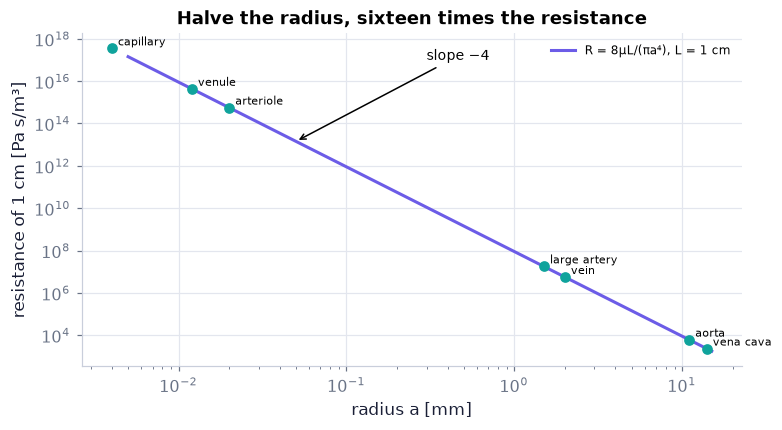

capillary / aorta resistance per length: (a_aorta/a_cap)⁴ = 5.72e+13


In [31]:
a_ = np.logspace(np.log10(5e-6), np.log10(15e-3), 200)       # radii 5 µm … 15 mm
Rr = ch16.vascular_resistance(blood["mu"], 0.01, a_)          # resistance of a 1-cm segment [Pa s/m³]
fig, ax = plt.subplots(figsize=(7, 3.8))   # a new figure and its axes
ax.loglog(a_*1e3, Rr, color=COLORS["accent"], lw=2, label="R = 8μL/(πa⁴), L = 1 cm")   # curve: R = 8μL/(πa⁴), L = 1 cm
for name, row in tab.set_index("vessel").iterrows():          # vessel classes of the scales table
    Rv = ch16.vascular_resistance(blood["mu"], 0.01, row["a"])   # `ch16.vascular_resistance` (the chapter module)
    ax.plot(row["a"]*1e3, Rv, "o", color=COLORS["teal"]); ax.annotate(name, (row["a"]*1e3, Rv), fontsize=7, xytext=(4, 2),   # a teal dot and its vessel name beside it (no arrow)
                                                                     textcoords="offset points")   # a teal dot and its vessel name
ax.annotate("slope −4", (0.05, ch16.vascular_resistance(blood["mu"], 0.01, 5e-5)), xytext=(0.3, 1e17), fontsize=9,   # a label with an arrow
            arrowprops=dict(arrowstyle="->"))   # the arrow's style
ax.set(xlabel="radius a [mm]", ylabel="resistance of 1 cm [Pa s/m³]", title="Halve the radius, sixteen times the resistance")   # axis labels, limits and title
ax.legend(fontsize=8)   # the legend
savefig(fig, "ch16", "c04_resistance"); plt.show()   # save to outputs/ch16/ and show the figure
v_ = tab.set_index("vessel")                                   # the scales table indexed by vessel name
print(f"capillary / aorta resistance per length: (a_aorta/a_cap)⁴ = {(v_.loc['aorta', 'a']/v_.loc['capillary', 'a'])**4:.2e}")   # print the result

**What you see.** The resistance of a 1-cm segment against its radius on log–log axes (a straight line of slope −4), with the
vessel classes of the scales table as teal dots.

**How to read it.** Each decade of radius is four decades of resistance: a 4-µm capillary segment resists about 10¹⁴ times
(6 × 10¹³, printed under the figure) more than an 11-mm aortic one of the same length. On log–log axes a power law is a
straight line whose slope is the exponent (P13).

**What would change if…** …an arteriole narrowed by 19 %? $1/0.81^4=2.3$ — its resistance would roughly double; that is how a small
change of tone controls the pressure.

📝 **Note.** **N27 [B]** Entrance length $\dfrac\ell d=0.06\,Re\ \text{(laminar)},\ \ \dfrac\ell d=0.693\,Re^{1/4}\ \text{(turbulent)}$ (16.37) (laminar for Re > 50). **Which correlation?** (slip S31)

| Source | laminar | turbulent |
|---|---|---|
| the book | $\ell/d=0.06\,Re$ | $\ell/d=0.693\,Re^{1/4}$ |
| Çengel (cited via Wikipedia) | $\ell/d\approx0.0575\,Re$ | $\ell/d=1.359\,Re^{1/4}$ |

In [32]:
print(ch16.entrance_length(500.0, 4e-3, regime="laminar"), "m")   # (16.37): 0.06 × 500 × 4 mm = 0.12 m

0.12 m


**What does this show?** At Re = 500 in a 4-mm artery the flow needs 12 cm to become parabolic — longer than many
arterial segments between branches, so Poiseuille's profile is an idealisation there.

📝 **Note.** **N26 [C]** Poiseuille's law fits muscular arteries best; heat transfer in perfused tissue is named in the book and not
treated here. **N28 [C]** In pulsatile flow the entrance length depends on Re and α; the wall shear settles sooner than the
centreline speed (α is C03, the oscillating profile C09).

**What would change if…** …the blood were not one fluid? In tubes below about 0.3 mm the cells crowd to the centre and leave plasma at the wall —
then a single μ no longer describes the flow: C05.

### 🧩 A plasma layer lubricates narrow tubes: $\mu_{app}=\mu_p\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]^{-1}$ (16.33) `C05`

*The question:* Why does blood seem less viscous in narrower tubes?

#### The problem in plain words

Measure blood's viscosity in glass tubes of shrinking diameter and, below about a third of a millimetre, it seems to get
*thinner*. The red cells drift away from the wall, leaving a thin layer of plain plasma. **The thick core slides on that
runny skin** — and the narrower the tube, the larger the skin's share.

#### The idea

```
wall ─────────────────────────────  u = 0
      plasma layer, μ_p, thickness δ    (runny skin: shears a lot)
─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─   r = a − δ: speed and stress continuous
      core, μ_c > μ_p                   (thick: nearly a plug)
axis ─────────────────────────────
```

📝 **Note.** **N29 [B]** (From §16.2.) The **Fåhræus–Lindqvist effect**: μ_app falls with diameter over a range of small tubes,
rising again in the very smallest. The **Fåhræus effect**: the tube hematocrit $H_T$ is below the discharge hematocrit
$H_D$ (= the feed $H_F$). The curve below uses the cited in-vitro law of Pries et al. via Secomb & Pries (2013),
`ch16.pries_relative_viscosity` (labelled cited).

📝 **Note.** **N30 [B]** (From §16.2.) Red cells and volume are conserved: $Q_FH_F=Q_cH_c,\ \ Q_c+Q_p=Q_F,\ \ H_Ta^2=H_c(a-\delta)^2$ (16.8). Eliminating $Q_F$ gives $H_c/H_F=1+Q_p/Q_c$
(result given): the core is richer in cells than the feed, and the tube holds fewer cells than flow through it, because the
cell-rich core moves faster than the mean.

In [33]:
cc = ch16.cell_conservation(1.0e-12, 0.2e-12, 0.5, 20e-6, 2e-6)   # (16.8): Q_c, Q_p [m³/s], H_c, a, δ [m]
print({k: float(f"{v:.4g}") for k, v in cc.items()})               # H_F = 0.417 < H_c = 0.5; H_T/H_D < 1 (Fåhræus effect)

{'Q_F': 1.2e-12, 'H_F': 0.4167, 'H_T': 0.405, 'Hc_over_HF': 1.2, 'HT_over_Hc': 0.81, 'HT_over_HD': 0.972}


📝 **Note.** **N31 [B]** The model: a core of viscosity $\mu_c$ inside a plasma layer of viscosity $\mu_p$ and thickness δ; stress
continuous at the interface; regular on the axis: $\tau_{xr}=-\mu_c\dfrac{du^c}{dr}=+\dfrac r2\dfrac{\Delta p}{L}$ (16.21, sign corrected), $\dfrac{du^c}{dr}=0\ \text{at}\ r=0$ (16.22), $\tau_{xr}\rvert_c=\tau_{xr}\rvert_p\ \text{at}\ r=a-\delta$ (16.23) — the printed $\tau_{xr}=-\mu_c\dfrac{du^c}{dr}=+\dfrac r2\dfrac{\Delta p}{L}$ (16.21, sign corrected) has the wrong sign on the
right (slip S2). **N32 [B]** $\tau_{xr}=-\mu_p\dfrac{du^p}{dr}=+\dfrac r2\dfrac{\Delta p}{L}$ (16.24, sign corrected), $u^c=u^p\ \text{at}\ r=a-\delta$ (16.25), $u^p=0\ \text{at}\ r=a$ (16.26).

> 🔁 **Tools from earlier chapters used in this block** (one line each; the full primers are in the chapters named)

- **substitution in an integral** — replace the integration variable by a new one, converting the differential and the limits too; here s = a² − r² turns ring integrals of the two-layer profile into simple powers. *(Ch. 3, P106)*
- **`scipy.integrate.quad`** — `quad(f, a, b)` integrates a function numerically and returns (value, error estimate); here it re-adds a profile's rings as a check of the closed-form flux. *(Ch. 3, P87)*
- **sympy symbols, `diff`, `integrate`, `simplify`, `solve`, `expand`** — sympy does algebra with symbols: `sp.symbols` names them, `sp.diff`/`sp.integrate` differentiate and integrate, `sp.solve` solves, `sp.simplify(a - b) == 0` proves two expressions equal; every ★★★ derivation below is re-run with it. *(Ch. 1, P40)*
- **first-order Taylor expansion and the binomial approximation** — f(x + ε) ≈ f(x) + f′(x)ε, and (1 + ε)ⁿ ≈ 1 + nε for small ε; here a thin plasma layer turns (1 − δ/a)⁴ into 1 − 4δ/a. *(Ch. 1, P26)*
- **`scipy.optimize.brentq`** — `brentq(f, a, b)` finds the root of f between a and b where f changes sign; here it closes the two-layer model by finding the core's hematocrit. *(Ch. 3, P108)*

#### 🧮 Derivation — The two-layer profiles `D05` ★★ (Eq. 16.27: $u^p=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac ra\right)^2\right]$)

**What we want to show.** Find the velocity in a tube whose core (cells, viscosity μ_c) is wrapped in a thin plasma layer (viscosity μ_p) of thickness δ.

**Assumptions.** Steady, fully developed, two Newtonian layers, a sharp interface (start).

**The plan.**

1. Why the stress is $r\Delta p/2L$ in both layers.
2. Integrate in the plasma, apply no slip.
3. Integrate in the core.
4. Match at the interface.

**Tools we use** (each explained before this point): free body of a fluid cylinder (Ch. 8 D07 recalled) · integrating a linear law twice

**We start from**

$$ \begin{array}{l}\tau_{xr}=-\mu_c\dfrac{du^c}{dr}=+\dfrac r2\dfrac{\Delta p}{L}\qquad\text{(16.21, sign corrected)} \\[6pt] \dfrac{du^c}{dr}=0\ \text{at}\ r=0\qquad\text{(16.22)} \\[6pt] \tau_{xr}\rvert_c=\tau_{xr}\rvert_p\ \text{at}\ r=a-\delta\qquad\text{(16.23)} \\[6pt] \tau_{xr}=-\mu_p\dfrac{du^p}{dr}=+\dfrac r2\dfrac{\Delta p}{L}\qquad\text{(16.24, sign corrected)} \\[6pt] u^c=u^p\ \text{at}\ r=a-\delta\qquad\text{(16.25)} \\[6pt] u^p=0\ \text{at}\ r=a\qquad\text{(16.26)}\end{array} $$

*In words:* Three conditions in the core and three in the plasma layer, with the signs of the two stress laws corrected (slip S2).

---

**Step 1 of 9 — Balance forces on a fluid cylinder.**

$$ \tau_{xr}(r)\,2\pi rL=\pi r^2\Delta p $$

- *Why we can do this:* Steady, fully developed: nothing accelerates, so the pressure push on the end faces equals the shear drag on the side (the free body of Ch. 8 D07). It holds across the interface because the stress is continuous there $\tau_{xr}\rvert_c=\tau_{xr}\rvert_p\ \text{at}\ r=a-\delta$ (16.23).
- *In words:* The stress at r carries the push on everything inside r.

---

**Step 2 of 9 — Solve for the stress.**

$$ \tau_{xr}=\dfrac r2\dfrac{\Delta p}{L} $$

- *Why we can do this:* Divide by 2πrL. This is the right side of $\tau_{xr}=-\mu_c\dfrac{du^c}{dr}=+\dfrac r2\dfrac{\Delta p}{L}$ (16.21) and $\tau_{xr}=-\mu_p\dfrac{du^p}{dr}=+\dfrac r2\dfrac{\Delta p}{L}$ (16.24) with the sign that (16.27)–(16.28) use; the book prints a minus there (slip S2).
- *In words:* The stress grows linearly from zero on the axis.

---

**Step 3 of 9 — Write the plasma layer's law.**

$$ -\mu_p\dfrac{du^p}{dr}=\dfrac r2\dfrac{\Delta p}{L}\ \text{(16.24, sign corrected)} $$

- *Why we can do this:* A Newtonian layer: τ = −μ du/dr, a positive magnitude here because u falls outward (trap T5).
- *In words:* In the plasma the speed drops outward at a rate set by μ_p.

---

**Step 4 of 9 — Integrate once in the plasma.**

$$ u^p=-\dfrac{r^2}{4\mu_p}\dfrac{\Delta p}{L}+C_p $$

- *Why we can do this:* $\int r\,dr=r^2/2$; divide by −μ_p; one constant appears.
- *In words:* A parabola of unknown height.

---

**Step 5 of 9 — Apply no slip at the wall.**

$$ u^p=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac ra\right)^2\right]\ \text{(16.27)} $$

- *Why we can do this:* $u^p=0\ \text{at}\ r=a$ (16.26): u^p(a) = 0 gives $C_p=a^2\Delta p/4\mu_pL$.
- *In words:* The plasma layer moves exactly as Poiseuille flow of plasma would.

---

**Step 6 of 9 — Integrate once in the core.**

$$ u^c=-\dfrac{r^2}{4\mu_c}\dfrac{\Delta p}{L}+C_c $$

- *Why we can do this:* The core law $\tau_{xr}=-\mu_c\dfrac{du^c}{dr}=+\dfrac r2\dfrac{\Delta p}{L}$ (16.21, sign corrected) integrated the same way. Its slope $-r\Delta p/2\mu_cL$ is zero at r = 0, so the regularity condition $\dfrac{du^c}{dr}=0\ \text{at}\ r=0$ (16.22) holds without a logarithm.
- *In words:* The core is a flatter parabola, because μ_c > μ_p.

---

**Step 7 of 9 — Match the speeds at the interface.**

$$ -\dfrac{(a-\delta)^2}{4\mu_c}\dfrac{\Delta p}{L}+C_c=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac{a-\delta}a\right)^2\right] $$

- *Why we can do this:* $u^c=u^p\ \text{at}\ r=a-\delta$ (16.25): the two fluids do not slip past each other, so the speeds agree at r = a − δ.
- *In words:* One equation for the core's constant.

---

**Step 8 of 9 — Solve for the core's constant.**

$$ C_c=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac{a-\delta}a\right)^2+\dfrac{\mu_p}{\mu_c}\left(\dfrac{a-\delta}a\right)^2\right] $$

- *Why we can do this:* Move the core term across; write $(a-\delta)^2/4\mu_c=(a^2/4\mu_p)(\mu_p/\mu_c)((a-\delta)/a)^2$ so that one factor comes out.
- *In words:* The core rides on the plasma layer's speed at the interface.

---

**Step 9 of 9 — Put the constant back.**

$$ u^c=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac{a-\delta}{a}\right)^2-\dfrac{\mu_p}{\mu_c}\left(\dfrac ra\right)^2+\dfrac{\mu_p}{\mu_c}\left(\dfrac{a-\delta}{a}\right)^2\right]\ \text{(16.28)} $$

- *Why we can do this:* Substitute step 8 into step 6 and write $r^2/4\mu_c=(a^2/4\mu_p)(\mu_p/\mu_c)(r/a)^2$.
- *In words:* The core profile: a plug speed plus a gentle parabola.

---

**Result**

$$ \begin{array}{l}u^p=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac ra\right)^2\right]\qquad\text{(16.27)} \\[6pt] u^c=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac{a-\delta}{a}\right)^2-\dfrac{\mu_p}{\mu_c}\left(\dfrac ra\right)^2+\dfrac{\mu_p}{\mu_c}\left(\dfrac{a-\delta}{a}\right)^2\right]\qquad\text{(16.28)}\end{array} $$

*In words:* Speeds match at the interface, slopes do not.

**What it means.** a thin, runny layer at the wall lets the whole core slide — the lubrication behind the Fåhræus–Lindqvist effect. Fails if the cells reach the wall (capillaries) or the interface is diffuse.

**Check it.** μ_c = μ_p turns $u^c=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac{a-\delta}{a}\right)^2-\dfrac{\mu_p}{\mu_c}\left(\dfrac ra\right)^2+\dfrac{\mu_p}{\mu_c}\left(\dfrac{a-\delta}{a}\right)^2\right]$ (16.28) into $u^p=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac ra\right)^2\right]$ (16.27): one Poiseuille parabola ✓; δ → 0 gives Poiseuille with μ_c ✓; the slopes at the interface differ by the factor μ_c/μ_p (the kink in C05's figure); `ch16.two_layer_velocity` satisfies (16.21)–(16.26) in the sympy test.

📝 **Notes taught inside `D05`:** **N33 [B]** the two profiles $u^p=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac ra\right)^2\right]$ (16.27) and $u^c=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac{a-\delta}{a}\right)^2-\dfrac{\mu_p}{\mu_c}\left(\dfrac ra\right)^2+\dfrac{\mu_p}{\mu_c}\left(\dfrac{a-\delta}{a}\right)^2\right]$ (16.28).

> ⚠️ **Common confusion (traps in `D05`):** The book's signs in $\tau_{xr}=-\mu_c\dfrac{du^c}{dr}=+\dfrac r2\dfrac{\Delta p}{L}$ (16.21), $\tau_{xr}=-\mu_p\dfrac{du^p}{dr}=+\dfrac r2\dfrac{\Delta p}{L}$ (16.24) (S2); continuous stress but not continuous shear rate.

#### 🧮 Derivation — The layer fluxes `D06` ★★ (Eq. 16.31: $Q=Q_p+Q_c=\dfrac{\pi a^4\Delta p}{8\mu_pL}\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]$)

**What we want to show.** Add up the flow in the plasma layer and in the core, and find the total.

**Assumptions.** As D05.

**The plan.**

1. Plasma ring integral.
2. The core as plug + parabola.
3. Add, then factor.

**Tools we use** (each explained before this point): definite integral (P27) · substitution in an integral (P106, reminder) · sympy (P40, reminder) in the cell that shows slip S3

**We start from**

$$ \begin{array}{l}u^p=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac ra\right)^2\right]\qquad\text{(16.27)} \\[6pt] u^c=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac{a-\delta}{a}\right)^2-\dfrac{\mu_p}{\mu_c}\left(\dfrac ra\right)^2+\dfrac{\mu_p}{\mu_c}\left(\dfrac{a-\delta}{a}\right)^2\right]\qquad\text{(16.28)}\end{array}\qquad b\equiv a-\delta $$

*In words:* The two layer profiles found in D05, with the shorthand b for the radius of the interface.

---

**Step 1 of 8 — Write the plasma flux as rings.**

$$ Q_p=2\pi\displaystyle\int_b^au^p\,r\,dr,\quad b\equiv a-\delta $$

- *Why we can do this:* D04 step 1, only over the plasma annulus from b to a.
- *In words:* Flow carried by the plasma layer.

---

**Step 2 of 8 — Integrate the plasma parabola.**

$$ Q_p=\dfrac{\pi\Delta p}{8\mu_pL}\left[a^2-(a-\delta)^2\right]^2\ \text{(16.29)} $$

- *Why we can do this:* With s = a² − r², ds = −2r dr: $\int_b^a(a^2-r^2)r\,dr=(a^2-b^2)^2/4$ (P106); times $2\pi\Delta p/4\mu_pL$.
- *In words:* The layer's flux grows as the square of its area fraction.

---

**Step 3 of 8 — Rewrite the core profile as plug plus parabola.**

$$ u^c=\dfrac{\Delta p}{4L}\left[\dfrac{a^2-b^2}{\mu_p}+\dfrac{b^2-r^2}{\mu_c}\right] $$

- *Why we can do this:* Multiply out $u^c=\dfrac{a^2}{4\mu_p}\dfrac{\Delta p}{L}\left[1-\left(\dfrac{a-\delta}{a}\right)^2-\dfrac{\mu_p}{\mu_c}\left(\dfrac ra\right)^2+\dfrac{\mu_p}{\mu_c}\left(\dfrac{a-\delta}{a}\right)^2\right]$ (16.28): $a^2[1-b^2/a^2]/\mu_p=(a^2-b^2)/\mu_p$ and the two μ_p/μ_c terms give $(b^2-r^2)/\mu_c$.
- *In words:* The core slides at the plasma's interface speed and adds its own parabola.

---

**Step 4 of 8 — Integrate the plug part.**

$$ 2\pi\displaystyle\int_0^b\dfrac{\Delta p}{4L}\dfrac{a^2-b^2}{\mu_p}r\,dr=\dfrac{\pi\Delta p}{4\mu_pL}(a^2-b^2)\,b^2 $$

- *Why we can do this:* A constant times $\int_0^br\,dr=b^2/2$. Integrating a constant over the core disc is the ring sum of D04 step 1; we do it because the plug part moves as one piece.
- *In words:* The plug carries its speed times the core area.

---

**Step 5 of 8 — Integrate the core parabola.**

$$ 2\pi\displaystyle\int_0^b\dfrac{\Delta p}{4L}\dfrac{b^2-r^2}{\mu_c}r\,dr=\dfrac{\pi\Delta p}{8\mu_cL}b^4 $$

- *Why we can do this:* $\int_0^b(b^2-r^2)r\,dr=b^4/4$, the substitution of step 2.
- *In words:* Poiseuille flow of the core fluid inside radius b.

---

**Step 6 of 8 — Add and factor $b^2$.**

$$ Q_c=\dfrac{\pi(a-\delta)^2\Delta p}{4\mu_pL}\left[a^2-\left(1-\dfrac{\mu_p}{2\mu_c}\right)(a-\delta)^2\right]\ \text{(16.30, corrected)} $$

- *Why we can do this:* $\dfrac{\pi\Delta p\,b^2}{4\mu_pL}\left[(a^2-b^2)+\dfrac{\mu_p}{2\mu_c}b^2\right]$, then collect b². The book prints a factor a² and $(a-\delta)^4/a^2$ (slip S3); only this form adds up to $Q=Q_p+Q_c=\dfrac{\pi a^4\Delta p}{8\mu_pL}\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]$ (16.31).
- *In words:* The core's flux.

---

**Step 7 of 8 — Add the two fluxes over a common factor.**

$$ Q=\dfrac{\pi\Delta p}{8\mu_pL}\left[a^4-b^4+\dfrac{\mu_p}{\mu_c}b^4\right] $$

- *Why we can do this:* $(a^2-b^2)^2+2b^2(a^2-b^2)=(a^2-b^2)(a^2+b^2)=a^4-b^4$; the parabola term is $(\pi\Delta p/8\mu_pL)(\mu_p/\mu_c)b^4$.
- *In words:* Total flow: a plasma-viscosity tube, minus what the slower core loses.

---

**Step 8 of 8 — Factor $a^4$.**

$$ Q=\dfrac{\pi a^4\Delta p}{8\mu_pL}\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]\ \text{(16.31)} $$

- *Why we can do this:* $b^4/a^4=(1-\delta/a)^4$; collect the two b⁴ terms.
- *In words:* Poiseuille's flux for plasma, reduced by a factor that the core's thickness and viscosity set.

---

**Result**

$$ \begin{array}{l}Q_p=\dfrac{\pi\Delta p}{8\mu_pL}\left[a^2-(a-\delta)^2\right]^2\qquad\text{(16.29)} \\[6pt] Q_c=\dfrac{\pi(a-\delta)^2\Delta p}{4\mu_pL}\left[a^2-\left(1-\dfrac{\mu_p}{2\mu_c}\right)(a-\delta)^2\right]\qquad\text{(16.30, corrected)} \\[6pt] Q=Q_p+Q_c=\dfrac{\pi a^4\Delta p}{8\mu_pL}\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]\qquad\text{(16.31)}\end{array} $$

*In words:* The plasma layer's flux, the core's flux (corrected form) and their sum.

**What it means.** The core carries almost all the flow but the plasma layer sets how easily it moves. Fails as D05.

**Check it.** δ → 0: $Q=\pi a^4\Delta p/8\mu_cL$ ✓; μ_c = μ_p: $Q=\pi a^4\Delta p/8\mu_pL$ ✓; the notebook cell: quad of 2πru equals $Q=Q_p+Q_c=\dfrac{\pi a^4\Delta p}{8\mu_pL}\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]$ (16.31) to 10⁻¹⁰, and printed $Q_c=\dfrac{\pi a^2\Delta p}{4\mu_pL}\left[a^2-\left(1-\dfrac{\mu_p}{2\mu_c}\right)\dfrac{(a-\delta)^4}{a^2}\right]$ (16.30, as printed) minus corrected (16.30) $=+\pi\Delta p\,a^2\delta(2a-\delta)/(4\mu_pL)>0$ — the printed form overstates the core's flux (slip S3).

📝 **Notes taught inside `D06`:** **N34 [B]** the plasma flux $Q_p=\dfrac{\pi\Delta p}{8\mu_pL}\left[a^2-(a-\delta)^2\right]^2$ (16.29), the core flux $Q_c=\dfrac{\pi(a-\delta)^2\Delta p}{4\mu_pL}\left[a^2-\left(1-\dfrac{\mu_p}{2\mu_c}\right)(a-\delta)^2\right]$ (16.30, corrected) and the total $Q=Q_p+Q_c=\dfrac{\pi a^4\Delta p}{8\mu_pL}\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]$ (16.31).

> ⚠️ **Common confusion (traps in `D06`):** Slip S3; forgetting that the core also moves with the interface speed (the plug part).

> ⚠️ **slip S3 — the book prints** $Q_c=\dfrac{\pi a^2\Delta p}{4\mu_pL}\left[a^2-\left(1-\dfrac{\mu_p}{2\mu_c}\right)\dfrac{(a-\delta)^4}{a^2}\right]$ (16.30, as printed); **the correct form is** $Q_c=\dfrac{\pi(a-\delta)^2\Delta p}{4\mu_pL}\left[a^2-\left(1-\dfrac{\mu_p}{2\mu_c}\right)(a-\delta)^2\right]$ (16.30, corrected)
>
> Only the corrected core flux adds to the plasma flux $Q_p=\dfrac{\pi\Delta p}{8\mu_pL}\left[a^2-(a-\delta)^2\right]^2$ (16.29) to give the total $Q=Q_p+Q_c=\dfrac{\pi a^4\Delta p}{8\mu_pL}\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]$ (16.31).
The printed core flux is too large: printed minus corrected is
$\dfrac{\pi\Delta p}{4\mu_pL}(a^4-a^2b^2)=+\dfrac{\pi\Delta p\,a^2\delta(2a-\delta)}{4\mu_pL}>0$ (with $b=a-\delta$), so the
printed form overstates the core's flux — by 75 % in our 40-µm tube (the cell below).

In [34]:
args = (micro["a"], micro["delta"], 1.0, 1e-3, blood["mu_p"], micro["mu_c"])   # a, δ [m], Δp [Pa], L [m], μ_p, μ_c [Pa s]
good = ch16.two_layer_flow_rates(*args)                     # (16.29), (16.30, corrected), (16.31)
bad = ch16.two_layer_flow_rates(*args, printed_16_30=True)  # the printed (16.30)
print(f"Qp + Qc - Q: corrected {good['Qp'] + good['Qc'] - good['Q']:.2e}, printed {bad['Qp'] + bad['Qc'] - good['Q']:.2e} m³/s")   # print the result
print(f"relative error of the printed core flux: {bad['Qc']/good['Qc'] - 1:+.3f}")   # print the result

Qp + Qc - Q: corrected 0.00e+00, printed 1.99e-14 m³/s
relative error of the printed core flux: +0.753


#### 🧮 Derivation — The apparent viscosity and its thin-layer limit `D07` ★ (Eq. 16.33: $\mu_{app}=\mu_p\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]^{-1}$)

**What we want to show.** Express the two-layer flow as one "apparent" viscosity and see how a thin layer lowers it.

**Assumptions.** δ ≪ a in steps 4–6.

**The plan.**

1. Define μ_app by Poiseuille's formula.
2. Equate and invert.
3. Expand for thin layers.

**Tools we use** (each explained before this point): binomial approximation $(1+\varepsilon)^n\approx1+n\varepsilon$ (Taylor series, Ch. 1, reminder)

**We start from**

$$ \begin{array}{l}Q=Q_p+Q_c=\dfrac{\pi a^4\Delta p}{8\mu_pL}\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]\qquad\text{(16.31)} \\[6pt] Q=\dfrac{\pi a^4\Delta p}{8\mu_{app}L}\qquad\text{(16.32)}\end{array} $$

*In words:* The total flux of the two-layer model and the definition of an apparent viscosity by Poiseuille's formula.

---

**Step 1 of 6 — Define the apparent viscosity.**

$$ Q=\dfrac{\pi a^4\Delta p}{8\mu_{app}L}\ \text{(16.32)} $$

- *Why we can do this:* By definition μ_app is the viscosity a uniform Newtonian fluid would need to pass the same Q through the same tube under the same Δp — what an experiment measures.
- *In words:* Pretend the blood is one fluid.

---

**Step 2 of 6 — Equate with (16.31).**

$$ \dfrac1{\mu_{app}}=\dfrac1{\mu_p}\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right] $$

- *Why we can do this:* Same Q, Δp, L and a: the common factor $\pi a^4\Delta p/8L$ cancels.
- *In words:* The reciprocal viscosity is the bracket over μ_p.

---

**Step 3 of 6 — Take reciprocals.**

$$ \mu_{app}=\mu_p\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]^{-1}\ \text{(16.33)} $$

- *Why we can do this:* Both sides positive. Taking reciprocals of two equal positive numbers keeps them equal, and it gives μ_app itself.
- *In words:* The two-layer apparent viscosity.

---

**Step 4 of 6 — Expand the fourth power.**

$$ \left(1-\dfrac\delta a\right)^4\approx1-4\dfrac\delta a $$

- *Why we can do this:* Binomial approximation with δ/a ≪ 1 (P26); the dropped terms are of order (δ/a)².
- *In words:* A thin layer removes a fraction 4δ/a of the core's fourth-power weight.

---

**Step 5 of 6 — Multiply out the bracket.**

$$ \mu_{app}\approx\mu_p\left[\dfrac{\mu_p}{\mu_c}+4\dfrac\delta a\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]^{-1} $$

- *Why we can do this:* $1-(1-4\delta/a)(1-\mu_p/\mu_c)=\mu_p/\mu_c+4(\delta/a)(1-\mu_p/\mu_c)$, exactly. Multiplying out a product is ordinary algebra (no approximation beyond step 4); it separates the core's share from the layer's.
- *In words:* The core's share plus the layer's correction.

---

**Step 6 of 6 — Factor out $\mu_p/\mu_c$.**

$$ \mu_{app}\approx\mu_c\left[1+4\dfrac\delta a\left(\dfrac{\mu_c}{\mu_p}-1\right)\right]^{-1}\ \text{(16.34)} $$

- *Why we can do this:* $(\mu_c/\mu_p)(1-\mu_p/\mu_c)=\mu_c/\mu_p-1$; $\mu_p\cdot\mu_c/\mu_p=\mu_c$. Factoring a common term out of a bracket changes nothing; it shows the core's viscosity as the reference value.
- *In words:* The core's viscosity, lowered by a factor that grows with δ/a.

---

**Result**

$$ \begin{array}{l}\mu_{app}=\mu_p\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]^{-1}\qquad\text{(16.33)} \\[6pt] \mu_{app}\approx\mu_c\left[1+4\dfrac\delta a\left(\dfrac{\mu_c}{\mu_p}-1\right)\right]^{-1}\qquad\text{(16.34)}\end{array} $$

*In words:* The two-layer apparent viscosity and its thin-layer approximation.

**What it means.** μ_app < μ_c whenever μ_c > μ_p, and the drop grows as the tube narrows at fixed δ — the Fåhræus–Lindqvist effect. Fails when δ is comparable with a (capillaries) and the curve depends on our choice of δ (T19).

**Check it.** δ = 0 → μ_c; μ_c = μ_p → μ_p ✓; easy numbers μ_p = 1, μ_c = 4, δ/a = 0.1: $\mu_{app}=\mu_p\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]^{-1}$ (16.33) gives **1.969**, $\mu_{app}\approx\mu_c\left[1+4\dfrac\delta a\left(\dfrac{\mu_c}{\mu_p}-1\right)\right]^{-1}$ (16.34) **1.818** (first order is 8 % low at δ/a = 0.1); our 40 µm tube: **2.22 mPa s** against 3.73 mPa s at 500 µm (expect).

> ⚠️ **Common confusion (traps in `D07`):** $\mu_{app}\approx\mu_c\left[1+4\dfrac\delta a\left(\dfrac{\mu_c}{\mu_p}-1\right)\right]^{-1}$ (16.34) is first order in δ/a; the effect needs the *less* viscous fluid at the wall.

#### ✏️ Tiny example: a 40 µm tube

Relative units μ_p = 1, μ_c = 4, δ/a = 0.1:
1. (1 − 0.1)⁴ = 0.6561.
2. 1 − μ_p/μ_c = 0.75.
3. Bracket 1 − 0.6561 × 0.75 = 0.508.
4. μ_app = 1/0.508 = **1.97** μ_p — half the core's 4.
5. The thin-layer form $\mu_{app}\approx\mu_c\left[1+4\dfrac\delta a\left(\dfrac{\mu_c}{\mu_p}-1\right)\right]^{-1}$ (16.34): 4/(1 + 0.4 × 3) = 1.82 (8 % low).

With our SI inputs (a = 20 µm, δ = 2 µm, μ_p = 1.2, μ_c = 4.0 mPa s): **2.22 mPa s**; in a 500 µm tube with the same δ,
3.73 mPa s.

In [35]:
r = np.linspace(0, micro["a"], 6)                           # six radii from the axis to the wall [m]
u2 = ch16.two_layer_velocity(r, micro["a"], micro["delta"], 1.0, 1e-3, blood["mu_p"], micro["mu_c"])   # (16.27)/(16.28) [m/s]
mu_two = ch16.apparent_viscosity_two_layer(micro["a"], micro["delta"], blood["mu_p"], micro["mu_c"])   # (16.33)
mu_thin = ch16.apparent_viscosity_thin_layer(micro["a"], micro["delta"], blood["mu_p"], micro["mu_c"]) # (16.34)
mu_500 = ch16.apparent_viscosity_two_layer(250e-6, micro["delta"], blood["mu_p"], micro["mu_c"])       # a 500-µm tube
print("u [mm/s]:", np.round(u2*1e3, 4))   # print the result
print(f"mu_app = {mu_two*1e3:.3f} mPa s (thin-layer {mu_thin*1e3:.3f}); in a 500-µm tube {mu_500*1e3:.2f} mPa s")   # print the result

u [mm/s]: [0.0361 0.0351 0.0321 0.0271 0.0201 0.    ]
mu_app = 2.219 mPa s (thin-layer 2.069); in a 500-µm tube 3.73 mPa s


In [36]:
a, d = micro["a"], micro["delta"]                             # radius, layer [m]
Q_quad = quad(lambda r: 2*np.pi*r*ch16.two_layer_velocity(r, a, d, 1.0, 1e-3, blood["mu_p"], micro["mu_c"]), 0, a,   # ∫ 2πr u dr from axis to wall [m³/s] …
              points=[a - d])[0]                              # … told about the kink at the interface r = a − δ; [0] keeps the value
assert np.isclose(Q_quad, good["Q"], rtol=1e-10)              # the closed-form total (16.31)
mu_hand = np.pi*a**4*1.0/(8*1e-3*Q_quad)                      # (16.32) solved for μ_app
assert np.isclose(mu_hand, mu_two, rtol=1e-10)                # equals (16.33)
print(f"quad flux {Q_quad:.6e} m³/s; mu_app by hand {mu_hand*1e3:.4f} mPa s")   # print the result

quad flux 2.831256e-14 m³/s; mu_app by hand 2.2192 mPa s


**What does the code above do?**

`quad` adds the profile's rings numerically (told where the kink is); the flux equals $Q=Q_p+Q_c=\dfrac{\pi a^4\Delta p}{8\mu_pL}\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]$ (16.31) to 10⁻¹⁰, and the
apparent viscosity solved from $Q=\dfrac{\pi a^4\Delta p}{8\mu_{app}L}$ (16.32) by hand equals $\mu_{app}=\mu_p\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]^{-1}$ (16.33).

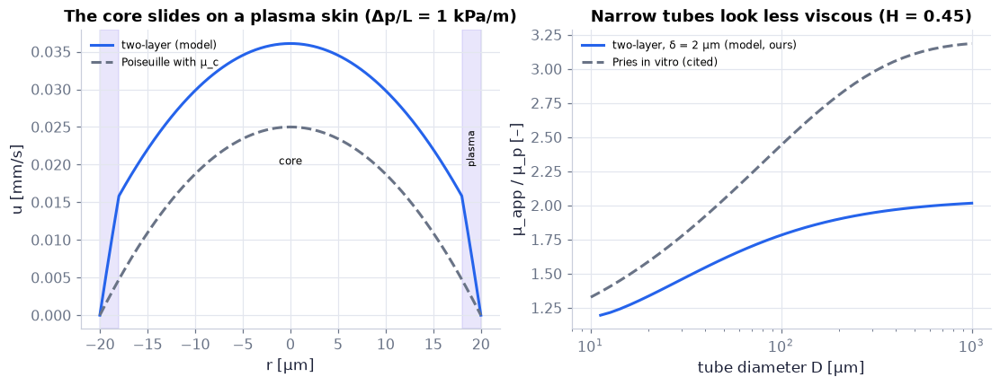

In [37]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.8))   # a new figure and its axes
rr = np.linspace(-micro["a"], micro["a"], 401)                # across the whole diameter [m]
ux = ch16.two_layer_velocity(np.abs(rr), micro["a"], micro["delta"], 1.0, 1e-3, blood["mu_p"], micro["mu_c"])   # `ch16.two_layer_velocity` (the chapter module)
ug = ch16.poiseuille_velocity(np.abs(rr), micro["a"], 1.0, 1e-3, micro["mu_c"])   # one fluid of the core's viscosity
ax.plot(rr*1e6, ux*1e3, color=COLORS["blue"], lw=2, label="two-layer (model)")   # curve: two-layer (model)
ax.plot(rr*1e6, ug*1e3, "--", color=COLORS["muted"], label="Poiseuille with μ_c")   # curve: Poiseuille with μ_c
for s in (-1, 1):                                             # the plasma layers at both walls
    ax.axvspan(s*(micro["a"] - micro["delta"])*1e6, s*micro["a"]*1e6, color=COLORS["accent"], alpha=0.15)   # a shaded band
ax.text(0, 0.02, "core", ha="center", fontsize=8); ax.text(micro["a"]*1e6*0.95, 0.02, "plasma", ha="center", fontsize=7, rotation=90)   # a text label on the plot
ax.set(xlabel="r [µm]", ylabel="u [mm/s]", title="The core slides on a plasma skin (Δp/L = 1 kPa/m)")   # axis labels, limits and title
ax.legend(fontsize=8, loc="upper left")   # the legend
D_um = np.logspace(1, 3, 40)                                  # diameters 10 … 1000 µm
def fl_rel(D, delta=micro["delta"]):                          # our closure's μ_app/μ_p (NaN if out of range)
    try:                                                      # the closure can fail when δ is too large for the tube …
        return ch16.fahraeus_lindqvist_model(D*0.5e-6, delta, 0.45, blood["mu_p"], blood["T"])["mu_app"]/blood["mu_p"]   # what this function hands back
    except ValueError:                                        # … then no point is drawn (NaN leaves a gap in the curve)
        return np.nan   # what this function hands back
bx.semilogx(D_um, [fl_rel(D) for D in D_um], color=COLORS["blue"], lw=2, label="two-layer, δ = 2 µm (model, ours)")   # curve: two-layer, δ = 2 µm (model, ours)
bx.semilogx(D_um, ch16.pries_relative_viscosity(D_um, 0.45), "--", color=COLORS["muted"], label="Pries in vitro (cited)")   # curve: Pries in vitro (cited)
bx.set(xlabel="tube diameter D [µm]", ylabel="μ_app / μ_p [–]", title="Narrow tubes look less viscous (H = 0.45)")   # axis labels, limits and title
bx.legend(fontsize=8)   # the legend
savefig(fig, "ch16", "c05_two_layer"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** Left: the two-layer profile across a 40-µm tube (blue), with the plasma layers shaded purple, and the Poiseuille
profile of a single fluid with the core's viscosity (grey dashed). Right: the relative apparent viscosity against diameter
for our model closure (blue, δ = 2 µm) and the cited in-vitro law (grey dashed).

**How to read it.** The blue profile is flatter in the middle and steeper in the layer: speeds match at the interface but slopes do
not (the kink). On the right both curves fall as the tube narrows: the model gets the direction and rough size of the
Fåhræus–Lindqvist effect.

**What would change if…** …we went below about 10 µm? The cited curve rises again (cells deform and plug the tube); our model has no
deforming cells and cannot show that.

📝 **Note.** **N35 [B]** The core's viscosity from its hematocrit: $\mu_c=\mu_p\dfrac{1}{1-\alpha_cH_c}$ (16.35) with $\alpha_c=0.070\exp\left[2.49H_c+\dfrac{1107}{T}\exp(-1.69H_c)\right]$ (16.36), T in kelvin, valid to $H_c$ = 0.6. $\alpha_c$
is not the Womersley number (trap T2).

In [38]:
print(f"{ch16.charm_kurland_core_viscosity(0.5, 310.15, 1.2e-3)*1e3:.3f} mPa s")   # (16.35)-(16.36) at H_c = 0.5, 37 °C

2.747 mPa s


📝 **Note.** **N36 [B]** Closing the model (ours): given a, δ, $H_F$, $\mu_p$, T, solve $H_c=H_F[1+Q_p/Q_c]$ with $\mu_c(H_c)$ from
$\mu_c=\mu_p\dfrac{1}{1-\alpha_cH_c}$ (16.35) — a monotone root find (`brentq`, P108).

In [39]:
fl = ch16.fahraeus_lindqvist_model(micro["a"], micro["delta"], 0.45, blood["mu_p"], blood["T"])   # closure (model, ours)
print({k: (round(v, 5) if isinstance(v, float) else v) for k, v in fl.items()})   # H_c, μ_c, μ_app, H_T, residual

{'H_c': 0.47661, 'mu_c': 0.0026, 'mu_app': 0.00186, 'mu_rel': 1.5467, 'H_T': 0.38606, 'Qp_over_Qc': 0.05914, 'residual': 0.0, 'in_range': True}


> ⚠️ **Common confusion:** (trap T19) The curve depends on our choice of δ, which the book leaves free — it is a model, not a prediction.

In [40]:
d_vals = list(np.round(np.linspace(0.5e-6, 5e-6, 19), 8))     # plasma-layer thickness 0.5 … 5 µm (19 positions)
D_f = np.logspace(1.2, 3, 30) if FAST else np.logspace(1.2, 3, 40)   # diameters [µm]
pries = ch16.pries_relative_viscosity(D_f, 0.45)              # the cited curve does not depend on δ
def fl_curve(delta):                                          # model curve for one layer thickness
    return {"two-layer model (ours)": (D_f, [fl_rel(D, delta) for D in D_f]), "Pries in vitro (cited)": (D_f, pries)}   # what this function hands back
fig = slider_figure(fl_curve, "δ", d_vals, unit="m", xlabel="tube diameter D [µm] (log)", ylabel="μ_app/μ_p [–]",   # build the slider figure (every position computed now)
                    title="A thicker plasma layer lowers the apparent viscosity", xrange=[1.2, 3], yrange=[1, 3.6],   # the figure's title: its message
                    active=d_vals.index(2e-6))   # fixed axis ranges and the slider position it opens on
fig.update_xaxes(type="log"); fig.show()   # logarithmic axis on the web figure

**Figure F2.** Slider: the plasma-layer thickness δ from 0.5 to 5 µm (opens on our 2 µm). **What you see.** Our model's
relative apparent viscosity against diameter beside the fixed cited curve. **How to read it.** A thicker layer pulls the
model curve down at every diameter, most in the narrow tubes. **What would change if…** δ shrank to zero: the model would
give the core viscosity at every diameter — no effect at all.

**What would change if…** …the wall were not rigid? A pressure inside an elastic tube stretches it, the radius grows and, with R ∝ a⁻⁴, the
resistance falls — C06.

### 🧩 An artery is a spring: the tube law $a=a_0\left[1-\dfrac{a_0}{Eh}(p-p_e)\right]^{-1}$ (16.41) `C06`

*The question:* How much does an artery widen when the pressure inside rises?

#### The problem in plain words

Blow into a long balloon: the higher the pressure, the wider it gets, and the rubber is stretched around its circumference.
Arteries are like that, with a stiffer rubber. **The stretch around the circumference — the hoop stress — balances the
pressure**; Hooke's law turns stretch into a wider radius.

**Three symbols for the rest of the chapter.** $p_e$ is the pressure **outside** the vessel (the surrounding tissue, or the
chamber of a lab rig; we take $p_e=0$ in most examples). The difference $p-p_e$, inside minus outside, is the **transmural
pressure** ("across the wall"): it is what stretches the wall — raise the inside and the outside by the same amount and
nothing happens to the vessel. $a_0$ is the vessel's radius when $p=p_e$, the unstretched radius from which every bulge is
measured.

#### The idea

```
 p_e (outside)          wall: thickness h, Young's modulus E
───────────────────────────────────────────
 p (inside)  ──►  p − p_e > 0 pushes the wall out:  a₀ → a > a₀
───────────────────────────────────────────
```

**The wall is a spring loaded by the transmural pressure**: the higher $p-p_e$, the larger the radius.

> 📎 **Primer — Young's modulus and Poisson's ratio.** `P379` · A solid bar stretched by a stress σ (force per area) stretches by the
strain ε = σ/E; E is Young's modulus (Pa) — rubber ~1 MPa, an artery wall ~0.1–1 MPa, steel 200 GPa. Stretching one way
thins the material the other way: Poisson's ratio ν̂ ($0.5$ for an incompressible wall, used in C11).

In [41]:
E = 0.4e6; sigma = 1.0e5                       # artery wall [Pa], a 100 kPa stress
print(sigma/E)                                 # strain 0.25: a 25 % stretch

0.25


> 📎 **Primer — a stretched curved membrane.** `P380` · A curved membrane under tension T (force per length) pushes inward with a pressure
T/a, a the radius of curvature — Laplace's law, the same law as the surface-tension jump of Ch. 1 (Δp = σ/R for a cylinder).
For a wall of thickness h, T = σh.

In [42]:
sigma, h, a = 1.0e5, 1.5e-3, 12e-3             # hoop stress [Pa], wall [m], radius [m]
print(sigma*h/a)                               # 12500 Pa ≈ 94 mmHg held

12500.0


#### 🧮 Derivation — The hoop stress and the tube law `D08` ★ (Eq. 16.41: $a=a_0\left[1-\dfrac{a_0}{Eh}(p-p_e)\right]^{-1}$)

**What we want to show.** Find how far a thin elastic artery widens under a pressure difference.

**Assumptions.** Thin wall h ≪ a; Hookean; radial stress in the wall neglected; the deformed radius a in the stress (step 4).

**The plan.**

1. Cut the tube in half and balance forces.
2. Integrate.
3. Apply Hooke's law.
4. Solve for a.

**Tools we use** (each explained before this point): Young's modulus and Hooke's law (P379, primer in C06) · a curved membrane under tension (P380, primer in C06)

**We start from**

$$ 2\sigma_{\theta\theta}h=\displaystyle\int_0^\pi(p-p_e)\,a\sin\theta\,d\theta\ \text{(16.38) and}\ e_{\theta\theta}=\dfrac{\sigma_{\theta\theta}}{E}=\dfrac{a-a_0}{a_0}\ \text{(16.40).} $$

---

**Step 1 of 6 — Cut the tube along a diameter.**

$$ 2\sigma_{\theta\theta}h=\displaystyle\int_0^\pi(p-p_e)\,a\sin\theta\,d\theta\ \text{(16.38)} $$

- *Why we can do this:* Free body of the upper half, per unit length (P380): the two cut walls pull down with σh each; the net pressure on a strip a dθ has upward component (p − p_e) a sin θ dθ.
- *In words:* The wall's tension holds the half-tube against the pressure.

---

**Step 2 of 6 — Do the integral.**

$$ 2\sigma_{\theta\theta}h=2(p-p_e)a $$

- *Why we can do this:* (p − p_e)a is the same all around; $\int_0^\pi\sin\theta\,d\theta=2$.
- *In words:* The pressure pushes on the projected width 2a.

---

**Step 3 of 6 — Solve for the hoop stress.**

$$ \sigma_{\theta\theta}=\dfrac{(p-p_e)a}{h}\ \text{(16.39)} $$

- *Why we can do this:* Divide by 2h. Dividing both sides by the positive number 2h keeps the balance true and leaves the hoop stress alone.
- *In words:* Laplace's law: a wide, thin, pressurised tube carries a large wall stress.

---

**Step 4 of 6 — Apply Hooke's law to the hoop.**

$$ \dfrac{(p-p_e)a}{Eh}=\dfrac{a-a_0}{a_0} $$

- *Why we can do this:* $e_{\theta\theta}=\dfrac{\sigma_{\theta\theta}}{E}=\dfrac{a-a_0}{a_0}$ (16.40): strain = stress/E (P379), and the hoop strain is the relative growth of the circumference 2πa. The book keeps the deformed a in the stress.
- *In words:* The circumference stretches in proportion to the hoop stress.

---

**Step 5 of 6 — Collect the terms in a.**

$$ a\left[\dfrac1{a_0}-\dfrac{p-p_e}{Eh}\right]=1 $$

- *Why we can do this:* Move $(p-p_e)a/Eh$ to the right and add 1 to both sides; the equation is linear in a.
- *In words:* One unknown, one linear equation.

---

**Step 6 of 6 — Solve for a.**

$$ a=a_0\left[1-\dfrac{a_0}{Eh}(p-p_e)\right]^{-1}\ \text{(16.41)} $$

- *Why we can do this:* Divide by the bracket and multiply top and bottom by a₀. Allowed only while $a_0(p-p_e)/Eh<1$; at 1 the radius would be infinite (trap T16).
- *In words:* The tube law.

---

**Result**

$$ \sigma_{\theta\theta}=\dfrac{(p-p_e)a}{h}\ \text{(16.39) and}\ a=a_0\left[1-\dfrac{a_0}{Eh}(p-p_e)\right]^{-1}\ \text{(16.41).} $$

**What it means.** An artery is a spring whose stiffness is Eh/a₀: everything later (compliance, pulse speed) follows. Fails for real arteries, which stiffen at large strain (collagen) rather than blow up.

**Check it.** Units Pa·m/m = Pa ✓ and $a_0p/Eh$ dimensionless ✓; small pressure: $a\approx a_0[1+a_0(p-p_e)/Eh]$, linear; easy numbers Eh/a₀ = 50 kPa, p − p_e = 10 kPa: a/a₀ = 1/(1 − 0.2) = **1.25** (linear 1.20); our aorta at 100 mmHg: **a = 16.36 mm**, σ = 145 kPa; singular at Eh/a₀ = 375 mmHg (expect).

📝 **Notes taught inside `D08`:** **N37 [B]** the half-tube balance $2\sigma_{\theta\theta}h=\displaystyle\int_0^\pi(p-p_e)\,a\sin\theta\,d\theta$ (16.38) and the hoop stress $\sigma_{\theta\theta}=\dfrac{(p-p_e)a}{h}$ (16.39) (steps 1–3).

> ⚠️ **Common confusion (traps in `D08`):** The singularity is an artefact of using the deformed radius with a linear law (T16); transmural, not absolute, pressure.

#### ✏️ Tiny example: an aorta at 100 mmHg

a₀ = 12 mm, h = 1.5 mm, E = 0.4 MPa:
1. Eh/a₀ = 0.4 × 10⁶ × 1.5/12 = 50 kPa (375 mmHg).
2. p − p_e = 100 mmHg = 13.3 kPa; a₀(p − p_e)/Eh = 13.3/50 = 0.267.
3. a = 12/(1 − 0.267) = **16.4 mm** (the linear estimate 12 × 1.267 = 15.2 mm).
4. Hoop stress (p − p_e)a/h = 13.3 × 16.4/1.5 = **145 kPa**.

In [43]:
a100 = ch16.tube_radius_hookean(100*MMHG, 0.0, aorta["a0"], aorta["E"], aorta["h"])   # (16.41) at 100 mmHg [m]
s100 = ch16.hoop_stress(100*MMHG, 0.0, a100, aorta["h"])    # (16.39) with the deformed radius [Pa]
print(f"a = {a100*1e3:.3f} mm, hoop stress = {s100/1e3:.1f} kPa")   # print the result
try:                                                        # beyond Eh/a0 = 375 mmHg the law has no solution …
    ch16.tube_radius_hookean(400*MMHG, 0.0, aorta["a0"], aorta["E"], aorta["h"])   # 400 mmHg: past the singular pressure
except ValueError as e:                                     # … and the function says so (trap T16)
    print("refused:", e)   # print the result

a = 16.363 mm, hoop stress = 145.4 kPa
refused: a0(p - pe)/(E h) = 1.067 >= 1: the Hookean tube law (16.41) has no finite radius (radius → ∞ as this ratio → 1; trap T16)


**What does the code above do?**

1. `tube_radius_hookean` is $a=a_0\left[1-\dfrac{a_0}{Eh}(p-p_e)\right]^{-1}$ (16.41): 16.36 mm at 100 mmHg; `hoop_stress` uses that deformed radius.
2. The `try` / `except ValueError` pattern of C02 again: at 400 mmHg the bracket $1-a_0(p-p_e)/Eh$ is negative, the law has
   no solution, and the function raises an error that the `except` block catches and prints (trap T16).

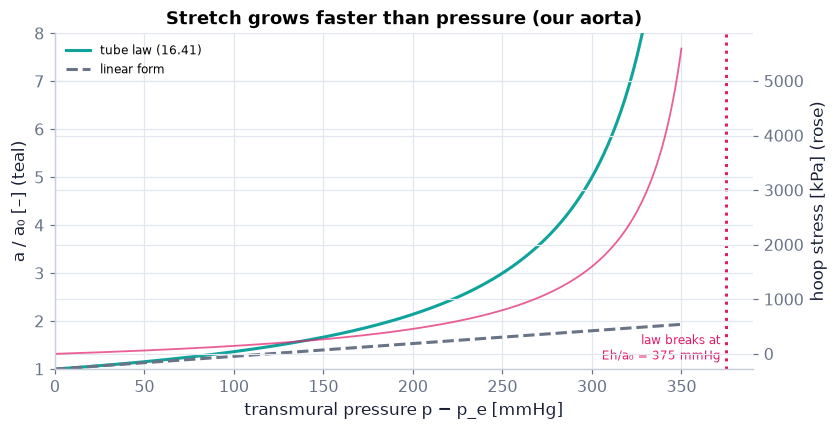

In [44]:
pp = np.linspace(0, 350, 300)*MMHG                            # transmural pressures 0 … 350 mmHg [Pa]
aa = ch16.tube_radius_hookean(pp, 0.0, aorta["a0"], aorta["E"], aorta["h"])   # (16.41) [m]
lin = aorta["a0"]*(1 + aorta["a0"]*pp/(aorta["E"]*aorta["h"]))  # linear (small-pressure) form [m]
fig, ax = plt.subplots(figsize=(7.5, 3.8)); bx = ax.twinx()   # a new figure and its axes
ax.plot(pp/MMHG, aa/aorta["a0"], color=COLORS["teal"], lw=2, label="tube law (16.41)")   # curve: tube law (16.41)
ax.plot(pp/MMHG, lin/aorta["a0"], "--", color=COLORS["muted"], label="linear form")   # curve: linear form
ps = aorta["E"]*aorta["h"]/aorta["a0"]/MMHG                   # singular pressure Eh/a0 [mmHg]
ax.axvline(ps, color=COLORS["rose"], ls=":"); ax.text(ps - 3, 1.2, f"law breaks at\nEh/a₀ = {ps:.0f} mmHg", ha="right", fontsize=8, color=COLORS["rose"])   # a reference line
bx.plot(pp/MMHG, ch16.hoop_stress(pp, 0.0, aa, aorta["h"])/1e3, color=COLORS["rose"], lw=1.2, alpha=0.7, label="hoop stress")   # curve: hoop stress
ax.set(xlabel="transmural pressure p − p_e [mmHg]", ylabel="a / a₀ [–] (teal)", xlim=(0, 390), ylim=(1, 8),   # axis labels, limits and title
       title="Stretch grows faster than pressure (our aorta)")   # the figure's title: its message
bx.set_ylabel("hoop stress [kPa] (rose)"); ax.legend(fontsize=8, loc="upper left")   # axis label or title
savefig(fig, "ch16", "c06_tube_law"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** The radius ratio a/a₀ of our aorta against transmural pressure (teal), its linear form (grey dashed), and the hoop
stress (rose, right axis); the dotted line marks the pressure Eh/a₀ where the law breaks.

**How to read it.** At small pressures the two radius curves agree; by 100 mmHg the full law is 8 % above the linear one, and it runs
away toward the singular pressure because the stress uses the deformed radius, which grows with the stress.

**What would change if…** …the wall were thicker (larger h)? Eh/a₀ grows, the curves flatten and the singular pressure moves right; real
arteries avoid the singularity differently — collagen stiffens them at large strain.

📝 **Note.** **N38 [B]** In a slowly widening tube each slice obeys Poiseuille's law with its own radius: $Q=-\dfrac{\pi}{8\mu}\left(\dfrac{dp}{dx}\right)a(x)^4$ (16.42), $\dfrac{dp}{dx}=-\dfrac{8\mu Q}{\pi a(x)^4}$ (16.43) — the
lubrication idea of Ch. 8 (C05).

> 🔁 **Recap — Lubrication: slowly varying channels** (Ch. 8 C05). When a channel changes width slowly compared with its
length, each cross-section carries the parallel-flow profile of its own width; only the pressure gradient varies.

In [45]:
x = np.linspace(0, 0.05, 6)                                 # positions along a 5-cm soft tube [m]
Qd = ch16.elastic_tube_flow_rate(20*MMHG, 10*MMHG, 0.0, 1e-3, 0.2e6, 0.1e-3, blood["mu"], 0.05)   # (16.46) [m³/s]
px = ch16.elastic_tube_pressure(x, Qd, 20*MMHG, 0.0, 1e-3, 0.2e6, 0.1e-3, blood["mu"])          # (16.44) integrated [Pa]
print("p(x) [mmHg]:", np.round(px/MMHG, 3))                 # falls from 20 to 10 mmHg, faster where the tube is narrower

p(x) [mmHg]: [20.    18.225 16.349 14.361 12.249 10.   ]


📝 **Note.** **N39 [B]** Put the tube law into $\dfrac{dp}{dx}=-\dfrac{8\mu Q}{\pi a(x)^4}$ (16.43) and separate: $\left[1-\dfrac{a_0}{Eh}(p-p_e)\right]^{-4}dp=-\dfrac{8\mu}{\pi a_0^4}Q\,dx$ (16.44, corrected); integrating gives $Q=\dfrac{\pi a_0^3Eh}{24\mu L}\left\{\left[1-\dfrac{a_0}{Eh}(p_1-p_e)\right]^{-3}-\left[1-\dfrac{a_0}{Eh}(p_2-p_e)\right]^{-3}\right\}$ (16.46) (result given).

> ⚠️ **slip S4 — the book prints** $\left[1-\dfrac{a_0}{Eh}(p-p_e)\right]^{-4}dp=-\dfrac{8\mu}{\pi a_0}Q\,dx$ (16.44, as printed) and the same $\pi a_0$ in its integral $\dfrac{Eh}{3a_0}\left\{\left[1-\dfrac{a_0}{Eh}(p_2-p_e)\right]^{-3}-\left[1-\dfrac{a_0}{Eh}(p_1-p_e)\right]^{-3}\right\}=-\dfrac{8\mu}{\pi a_0}LQ$ (16.45, as printed); **the correct form is** $\left[1-\dfrac{a_0}{Eh}(p-p_e)\right]^{-4}dp=-\dfrac{8\mu}{\pi a_0^4}Q\,dx$ (16.44, corrected) and $\dfrac{Eh}{3a_0}\left\{\left[1-\dfrac{a_0}{Eh}(p_2-p_e)\right]^{-3}-\left[1-\dfrac{a_0}{Eh}(p_1-p_e)\right]^{-3}\right\}=-\dfrac{8\mu}{\pi a_0^4}LQ$ (16.45, corrected)
>
> A units check catches it: $8\mu Q\,dx/(\pi a_0^4)$ is a pressure, $8\mu Q\,dx/(\pi a_0)$ is a pressure times m³. Solving
the corrected $\dfrac{Eh}{3a_0}\left\{\left[1-\dfrac{a_0}{Eh}(p_2-p_e)\right]^{-3}-\left[1-\dfrac{a_0}{Eh}(p_1-p_e)\right]^{-3}\right\}=-\dfrac{8\mu}{\pi a_0^4}LQ$ (16.45, corrected) for Q gives $Q=\dfrac{\pi a_0^3Eh}{24\mu L}\left\{\left[1-\dfrac{a_0}{Eh}(p_1-p_e)\right]^{-3}-\left[1-\dfrac{a_0}{Eh}(p_2-p_e)\right]^{-3}\right\}$ (16.46), which the book prints correctly.

In [46]:
mu_q, Q_q, dx_q, a_q = UN.Q_(3.5e-3, "Pa*s"), UN.Q_(1e-6, "m**3/s"), UN.Q_(1e-3, "m"), UN.Q_(1e-3, "m")   # quantities with units
print("corrected is a pressure:", UN.check_dimensions(8*mu_q*Q_q*dx_q/(np.pi*a_q**4), "[pressure]"))   # True
print("printed is a pressure:  ", UN.check_dimensions(8*mu_q*Q_q*dx_q/(np.pi*a_q), "[pressure]"))      # False
Qr = ch16.poiseuille_flow_rate(1e-3, 10*MMHG, 0.05, blood["mu"])   # a rigid tube of the unstretched radius
print(f"distensible / rigid flux: {Qd/Qr:.4f}")               # 1.53: the stretched tube passes more
Q_stiff = ch16.elastic_tube_flow_rate(20*MMHG, 10*MMHG, 0.0, 1e-3, 1e12, 0.1e-3, blood["mu"], 0.05)   # E → ∞
print(f"rigid limit: {Q_stiff/Qr - 1:.1e}")                   # back to Poiseuille (16.17)

corrected is a pressure: True
printed is a pressure:   False
distensible / rigid flux: 1.5311
rigid limit: 8.0e-08


In [47]:
E_vals = list(np.round(np.logspace(np.log10(0.05e6), np.log10(2e6), 20), -2))   # Young's modulus 0.05 … 2 MPa (log steps)
dps = np.linspace(0, 30, 61)*MMHG                             # pressure drops, outlet at p_e = 0 [Pa]
def flux(E):                                                  # distensible against rigid flux for one stiffness
    Qe = [ch16.elastic_tube_flow_rate(d, 0.0, 0.0, 1e-3, E, 0.1e-3, blood["mu"], 0.05) for d in dps]   # (16.46) for each drop [m³/s]
    Qr_ = ch16.poiseuille_flow_rate(1e-3, dps, 0.05, blood["mu"])   # (16.17), the rigid tube [m³/s]
    return {"distensible (16.46)": (dps/MMHG, np.array(Qe)*1e6), "rigid (16.17)": (dps/MMHG, Qr_*1e6)}   # what this function hands back
fig = slider_figure(flux, "E", E_vals, unit="Pa", xlabel="Δp = p₁ − p₂ [mmHg] (p₂ = p_e)", ylabel="Q [mL/s]",   # build the slider figure (every position computed now)
                    title="Softer walls pass more flow at high pressure", yrange=[0, 6], active=9)   # the figure's title: its message
fig.show()   # display the figure

**Figure F3.** Slider: Young's modulus of a 1-mm tube with a 0.1-mm wall, 0.05 to 2 MPa. **What you see.** The flux of
the distensible tube $Q=\dfrac{\pi a_0^3Eh}{24\mu L}\left\{\left[1-\dfrac{a_0}{Eh}(p_1-p_e)\right]^{-3}-\left[1-\dfrac{a_0}{Eh}(p_2-p_e)\right]^{-3}\right\}$ (16.46) against the pressure drop, beside the rigid line $Q=\dfrac{\pi a^4}{8\mu}\dfrac{\Delta p}{L}$ (16.17). **How to read it.** The rigid flux is
a straight line; the distensible one curves upward because the inlet end inflates. **What would change if…** you slide E
up: the curve straightens onto the rigid line — a stiff tube is a rigid tube.

📝 **Note.** **N40 [B]** (From the end of §16.3.) The lungs' vessels are soft: their resistance falls as the pulmonary pressure
rises — $Q=\dfrac{\pi a_0^3Eh}{24\mu L}\left\{\left[1-\dfrac{a_0}{Eh}(p_1-p_e)\right]^{-3}-\left[1-\dfrac{a_0}{Eh}(p_2-p_e)\right]^{-3}\right\}$ (16.46) at work.

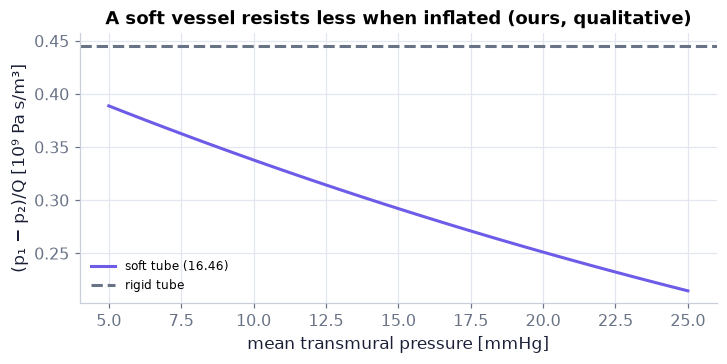

In [48]:
pm = np.linspace(5, 25, 41)*MMHG                              # mean transmural pressure of a soft vessel [Pa]
Reff = [ch16.elastic_tube_resistance(p + 2*MMHG, p - 2*MMHG, 0.0, 1e-3, 0.2e6, 0.1e-3, blood["mu"], 0.05) for p in pm]   # (p₁ − p₂)/Q for a 4 mmHg drop [Pa s/m³]
fig, ax = plt.subplots(figsize=(6.5, 3.2))   # a new figure and its axes
ax.plot(pm/MMHG, np.array(Reff)/1e9, color=COLORS["accent"], lw=2, label="soft tube (16.46)")   # the purple curve: effective resistance
ax.axhline(ch16.vascular_resistance(blood["mu"], 0.05, 1e-3)/1e9, ls="--", color=COLORS["muted"], label="rigid tube")   # a reference line
ax.set(xlabel="mean transmural pressure [mmHg]", ylabel="(p₁ − p₂)/Q [10⁹ Pa s/m³]",   # axis labels, limits and title
       title="A soft vessel resists less when inflated (ours, qualitative)"); ax.legend(fontsize=8)   # the figure's title: its message
savefig(fig, "ch16", "c06_soft_resistance"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** The effective resistance (p₁ − p₂)/Q of a soft 1-mm tube with a 4 mmHg drop against its mean pressure, and the
rigid tube's resistance (grey dashed).

**How to read it.** As the mean pressure rises the tube inflates and, through R ∝ a⁻⁴, its resistance falls well below the rigid
value — the reason the low-pressure pulmonary circulation copes with large flow changes.

**What would change if…** …E were doubled? The curve would flatten toward the rigid line: less inflation, less change.

📝 **Note.** **N41 [C]** The pulmonary circulation runs from the right ventricle through the lungs to the left atrium: larger,
softer, lower-resistance vessels (the loop sketch of N02). **N42 [C]** Its pressure pulses look like the systemic ones at a
lower pressure scale (C07).

**What would change if…** …the pressure changed in time? A stretchy vessel then stores blood when the pressure rises and gives it back when it
falls — the Windkessel, C07.

### 🧩 Store and drain: the Windkessel $Q(t)=\mathrm K\dfrac{dp}{dt}+\dfrac{p(t)}{R}$ (16.49) `C07`

*The question:* The heart pushes for a third of each beat — why doesn't the pressure drop to zero in between?

#### The problem in plain words

Fill a balloon from a tap that you open for one second in every three, while the balloon leaks through a pinhole: the jet
from the pinhole never stops, it only weakens a little between fills. The heart pushes blood out for only about a third of
each beat, yet your arterial pressure swings between about 80 and 120 mmHg instead of falling to zero. **The stretchy aorta
is the balloon, and the many small vessels downstream are the pinhole.**

📝 **Note.** **N43 [C]** The opening picture: old fire engines had an air chamber (German *Windkessel*) between the pump and the hose;
the pump's strokes compressed the air, which kept water flowing between strokes. Otto Frank (1899) saw the aorta doing the
same.

```
heart ──► [aorta: stretchy store K] ──► [small vessels: resistor R] ──► veins (p ≈ 0)
```

#### The idea

**A capacitor in parallel with a resistor** (P381): inflow = charging + leaking. During systole the inflow
charges the aorta; during diastole the stored blood leaks out through R, and the pressure decays slowly.

📝 **Note.** **N44 [B]** $Q(t)=\dfrac{dv}{dt}+Q_{out}(t)$ (16.47) in words: inflow into the aorta = rate of change of its volume + outflow into the periphery.
**N45 [B]** Compliance K = dv/dp; $\dfrac{dv}{dt}=\left(\dfrac{dv}{dp}\right)\left(\dfrac{dp}{dt}\right)=\mathrm K\dfrac{dp}{dt}$ (16.48). For a Hookean segment (ours): $dV/dp=2\pi a^3L/(Eh)$.

In [49]:
K_aorta = ch16.compliance_from_tube(100*MMHG, 0.0, aorta["a0"], aorta["E"], aorta["h"], aorta["L"])   # dV/dp of our aorta at 100 mmHg [m³/Pa]
print(f"K = {K_aorta:.3e} m³/Pa = {K_aorta*1e6*MMHG:.2f} mL/mmHg (our Windkessel uses {windkessel['K']:.1e} m³/Pa)")   # print the result

K = 1.376e-08 m³/Pa = 1.84 mL/mmHg (our Windkessel uses 1.2e-08 m³/Pa)


> 🔁 **Tools from earlier chapters used in this block** (one line each; the full primers are in the chapters named)

- **chain rule** — if v depends on t only through p(t), then dv/dt = (dv/dp)(dp/dt); here it turns the aorta's volume change into a pressure change. *(Ch. 1, P49)*
- **first-order linear ODE and the integrating factor** — y′ + Py = Q becomes d(y e^{∫P})/dx = Q e^{∫P} after multiplying by e^{∫P}, and one integration solves it; here y is the aortic pressure. *(Ch. 9, P210)*
- **product rule** — d(uv) = u dv + v du; here it shows that the integrating factor makes the left side an exact derivative, and it splits dp into three causes in a collapsible tube. *(Ch. 1, P38)*
- **`scipy.integrate.solve_ivp`** — `solve_ivp(rhs, (t0, t1), y0)` integrates dy/dt = rhs(t, y) numerically; here it marches the Windkessel and the collapsible tube. *(Ch. 1, P31)*
- **ipywidgets `live` and `_ = live(...)`** — `live(fn, a=(lo, hi, step), …)` draws sliders that re-run fn while a kernel runs; writing `_ = live(...)` keeps the cell from printing a stray object. *(Ch. 1, P17)*

#### 🧮 Derivation — The two-element Windkessel from a volume balance `D09` ★ (Eq. 16.49: $Q(t)=\mathrm K\dfrac{dp}{dt}+\dfrac{p(t)}{R}$)

**What we want to show.** Turn "the aorta stores blood in systole and releases it in diastole" into an equation for the aortic pressure.

**Assumptions.** Incompressible blood (step 1); the chamber volume depends on its pressure only (step 2); a steady peripheral resistor, venous pressure zero, transmural pressures (step 3, trap T12); no wave travel (N47).

**The plan.**

1. Write the balance.
2. Trade dv/dt for dp/dt.
3. Let the periphery be a resistor.
4. Substitute.

**Tools we use** (each explained before this point): control volume (Ch. 4 recap) · chain rule (P49, reminder) · the electrical analogy (P381, primer in C07)

**We start from**

$$ Q(t)=\dfrac{dv}{dt}+Q_{out}(t)\qquad\text{(16.47)} $$

*In words:* Inflow into the aorta = rate of change of the chamber's volume + outflow into the periphery.

---

**Step 1 of 4 — Write the volume balance.**

$$ Q(t)=\dfrac{dv}{dt}+Q_{out}(t)\ \text{(16.47)} $$

- *Why we can do this:* Blood is incompressible: what the heart pushes into the aortic chamber either stays there (v grows) or leaves through the periphery — a control-volume balance (Ch. 4).
- *In words:* Inflow = storage rate + outflow.

---

**Step 2 of 4 — Trade the volume rate for a pressure rate.**

$$ \dfrac{dv}{dt}=\left(\dfrac{dv}{dp}\right)\left(\dfrac{dp}{dt}\right)=\mathrm K\dfrac{dp}{dt}\ \text{(16.48)} $$

- *Why we can do this:* v depends on t only through p(t), so the chain rule applies (P49); K = dv/dp is the compliance, a capacitor (P381).
- *In words:* The aorta stores more blood when its pressure rises faster.

---

**Step 3 of 4 — Let the periphery be a resistor.**

$$ Q_{out}=\dfrac{p(t)-\bar p_V}{R}=\dfrac{p(t)}{R} $$

- *Why we can do this:* $R=\Delta\bar p/Q$ (16.9) used at every instant (the small vessels store nothing); pressures are transmural and the venous pressure is taken as zero (T12).
- *In words:* The higher the aortic pressure, the faster blood drains away.

---

**Step 4 of 4 — Substitute both into the balance.**

$$ Q(t)=\mathrm K\dfrac{dp}{dt}+\dfrac{p(t)}{R}\ \text{(16.49)} $$

- *Why we can do this:* Steps 2 and 3 in step 1.
- *In words:* The heart's inflow charges the capacitor and drains through the resistor.

---

**Result**

$$ Q(t)=\mathrm K\dfrac{dp}{dt}+\dfrac{p(t)}{R}\ \text{(16.49).} $$

**What it means.** One storage element and one resistor already explain why the aortic pressure never drops to zero between beats. Fails when the pulse's travel time matters (C08) or reflections shape the pressure (C13).

**Check it.** Units — K dp/dt: (m³/Pa)(Pa/s) = m³/s; p/R: Pa/(Pa s m⁻³) = m³/s ✓; K → 0 (a rigid aorta): p = QR, the pressure follows the inflow and falls to zero in diastole; constant Q: p → QR.

> ⚠️ **Common confusion (traps in `D09`):** p is transmural with p̄_V = 0 (T12); K here is the compliance, not Murray's cost or Dean's K (T2).

> 📎 **Primer — a sum of decaying kicks.** `P382` · For K dp/dt + p/R = Q(t) the solution adds up every past inflow Q(τ)dτ, each one
raising p by Q dτ/K and then fading as $e^{-(t-\tau)/RK}$ — a convolution. It extends the integrating factor of Ch. 9
(P210).

In [50]:
RK, K = 1.74, 1.2e-8                           # time constant [s], compliance [m³/Pa]
kick = 1e-6                                    # 1 mL injected at t = 0
for t in (0, 1.74, 3.48):
    print(t, kick/K*np.exp(-t/RK))             # 83 Pa, 31 Pa, 11 Pa: the kick fades by e per RK

0 83.33333333333333
1.74 30.65662009762019
3.48 11.277940269717725


#### 🧮 Derivation — The Windkessel pressure, the diastolic decay and the periodic state `D10` ★★ (Eq. 16.52: $p(t)=\dfrac1{\mathrm K}e^{-t/R\mathrm K}\displaystyle\int_0^tQ(\tau)e^{\tau/R\mathrm K}d\tau+p_0e^{-t/R\mathrm K}$)

**What we want to show.** Solve $Q(t)=\mathrm K\dfrac{dp}{dt}+\dfrac{p(t)}{R}$ (16.49) for the pressure, read off the decay between beats, and find the pressure the heartbeat settles into.

**Assumptions.** R and K constant (step 1); a periodic heartbeat (step 8).

**The plan.**

1. Standard form.
2. Integrating factor.
3. Integrate.
4. Switch the inflow off.
5. Ask for the same pressure after one beat.
6. Average.

**Tools we use** (each explained before this point): first-order linear ODE and the integrating factor (P210, reminder) · product rule (P38, reminder) · a sum of decaying kicks (P382, primer in C07)

**We start from**

$$ Q(t)=\mathrm K\dfrac{dp}{dt}+\dfrac{p(t)}{R}\ \text{(16.49) with}\ p(0)=p_0\ \text{.} $$

---

**Step 1 of 9 — Divide by K.**

$$ \dfrac{dp}{dt}+\dfrac{1}{R\mathrm K}p=\dfrac{Q(t)}{\mathrm K} $$

- *Why we can do this:* K > 0; this is the form $Q=\dfrac{dy}{dx}+Py$ (16.50) with y = p, x = t, P = 1/RK — and the book's "Q" of (16.50) is our forcing Q/K, not the flow.
- *In words:* The pressure relaxes at the rate 1/RK and is pushed by Q/K.

---

**Step 2 of 9 — Form the integrating factor.**

$$ e^{\int P\,dt}=e^{t/R\mathrm K} $$

- *Why we can do this:* P = 1/RK is constant, so its integral is t/RK (P210).
- *In words:* A factor that grows exactly as fast as the pressure decays.

---

**Step 3 of 9 — Multiply through by the factor.**

$$ \dfrac{d}{dt}\left(p\,e^{t/R\mathrm K}\right)=\dfrac{Q(t)}{\mathrm K}e^{t/R\mathrm K} $$

- *Why we can do this:* Product rule (P38): $\dfrac{d}{dt}(pe^{t/R\mathrm K})=e^{t/R\mathrm K}\left(\dfrac{dp}{dt}+\dfrac{p}{R\mathrm K}\right)$ — the left side of step 1 times the factor. This is $ye^{\int P\,dx}=A+\displaystyle\int Qe^{\int P\,dx}dx$ (16.51) in disguise.
- *In words:* The left side became one exact derivative.

---

**Step 4 of 9 — Integrate from 0 to t.**

$$ p(t)e^{t/R\mathrm K}-p_0=\dfrac1{\mathrm K}\displaystyle\int_0^tQ(\tau)e^{\tau/R\mathrm K}d\tau $$

- *Why we can do this:* Fundamental theorem of calculus with dummy variable τ; p(0) = p₀ plays the constant A of $ye^{\int P\,dx}=A+\displaystyle\int Qe^{\int P\,dx}dx$ (16.51).
- *In words:* Everything the heart put in, each piece weighted by when it came.

---

**Step 5 of 9 — Multiply by $e^{-t/R\mathrm K}$.**

$$ p(t)=\dfrac1{\mathrm K}e^{-t/R\mathrm K}\displaystyle\int_0^tQ(\tau)e^{\tau/R\mathrm K}d\tau+p_0e^{-t/R\mathrm K}\ \text{(16.52)} $$

- *Why we can do this:* Isolate p. Read as a convolution (P382): each kick Q(τ)dτ raises p by Q dτ/K and then fades as $e^{-(t-\tau)/R\mathrm K}$.
- *In words:* Today's pressure is the faded memory of every past stroke plus the faded initial pressure.

---

**Step 6 of 9 — Switch the inflow off for diastole.**

$$ p(t)=p(T_s)\,e^{-(t-T_s)/R\mathrm K},\quad T_s\le t<T $$

- *Why we can do this:* The aortic valve is shut, Q = 0; restart $p(t)=\dfrac1{\mathrm K}e^{-t/R\mathrm K}\displaystyle\int_0^tQ(\tau)e^{\tau/R\mathrm K}d\tau+p_0e^{-t/R\mathrm K}$ (16.52) at t = T_s: only its second term survives.
- *In words:* Between beats the pressure decays exponentially with time constant RK.

---

**Step 7 of 9 — Check with a constant inflow.**

$$ Q=\bar Q:\ \ p(t)=\bar QR\left(1-e^{-t/R\mathrm K}\right)+p_0e^{-t/R\mathrm K} $$

- *Why we can do this:* $\int_0^te^{\tau/R\mathrm K}d\tau=R\mathrm K(e^{t/R\mathrm K}-1)$; multiply by $(\bar Q/\mathrm K)e^{-t/R\mathrm K}$.
- *In words:* A steady inflow charges the aorta up to $\bar QR$ in a few RK.

---

**Step 8 of 9 — Demand the same pressure after one beat.**

$$ p_0=\dfrac{\dfrac1{\mathrm K}e^{-T/R\mathrm K}\displaystyle\int_0^TQ(\tau)e^{\tau/R\mathrm K}d\tau}{1-e^{-T/R\mathrm K}}\ \text{(ours)} $$

- *Why we can do this:* A steady heartbeat repeats, p(T) = p₀; $p(t)=\dfrac1{\mathrm K}e^{-t/R\mathrm K}\displaystyle\int_0^tQ(\tau)e^{\tau/R\mathrm K}d\tau+p_0e^{-t/R\mathrm K}$ (16.52) at t = T is linear in p₀; move $p_0e^{-T/R\mathrm K}$ left and divide by $1-e^{-T/R\mathrm K}\neq0$.
- *In words:* The end-diastolic pressure the circulation settles into.

---

**Step 9 of 9 — Average (16.49) over one beat.**

$$ \bar p=R\bar Q $$

- *Why we can do this:* Integrate $Q(t)=\mathrm K\dfrac{dp}{dt}+\dfrac{p(t)}{R}$ (16.49) from 0 to T: $\mathrm K[p(T)-p(0)]=0$ by step 8, leaving $\frac1T\int p/R\,dt=\frac1T\int Q\,dt$.
- *In words:* The mean pressure is set by R alone; compliance only shapes the swing.

---

**Result**

$$ \begin{array}{l}p(t)=\dfrac1{\mathrm K}e^{-t/R\mathrm K}\displaystyle\int_0^tQ(\tau)e^{\tau/R\mathrm K}d\tau+p_0e^{-t/R\mathrm K}\qquad\text{(16.52)}\\[4pt]p=p(T_s)\,e^{-(t-T_s)/R\mathrm K}\ \ (T_s\le t<T)\qquad\text{(diastole)}\\[4pt]p_0=\dfrac{\frac1{\mathrm K}e^{-T/R\mathrm K}\int_0^TQ\,e^{\tau/R\mathrm K}d\tau}{1-e^{-T/R\mathrm K}},\qquad\bar p=R\bar Q\qquad\text{(ours)}\end{array} $$

*In words:* Today's pressure is the faded memory of every past stroke; between beats it decays with time constant RK; a steady heartbeat settles to one starting pressure; the mean is set by R alone.

**What it means.** RK is the aorta's memory; with RK ≈ 2 beats the pressure has no time to fall far — a high diastolic pressure. A stiffer aorta (smaller K) shortens the memory and widens the swing at the same mean. Fails as D09.

**Check it.** Units of $\frac1{\mathrm K}\int Q\,d\tau$: (Pa/m³)(m³) = Pa ✓; K → ∞: p stays at p₀; our resting set (R = 1.45 × 10⁸ Pa s m⁻³, K = 1.2 × 10⁻⁸ m³/Pa, RK = 1.74 s, half-sine ejection, 66 beats/min) — **expect** periodic p_S = 106.0 mmHg, p_D = 74.5 mmHg, mean 89.7 mmHg = R Q̄ ✓, decay factor over diastole $e^{-(T-T_s)/R\mathrm K}=0.712$; the closed periodic form (`ch16.windkessel_summary`) equals the RK4 march to 10⁻⁶.

📝 **Notes taught inside `D10`:** **N46 [B]** the solution $p(t)=\dfrac1{\mathrm K}e^{-t/R\mathrm K}\displaystyle\int_0^tQ(\tau)e^{\tau/R\mathrm K}d\tau+p_0e^{-t/R\mathrm K}$ (16.52) through $Q=\dfrac{dy}{dx}+Py$ (16.50) and $ye^{\int P\,dx}=A+\displaystyle\int Qe^{\int P\,dx}dx$ (16.51) (steps 1–5).

> ⚠️ **Common confusion (traps in `D10`):** Divide by K before using $Q=\dfrac{dy}{dx}+Py$ (16.50); p₀ is the pressure at the start of ejection (the end of diastole), not the minimum (which comes a moment later).

#### ✏️ Tiny example: diastolic decay

R = 1.45 × 10⁸ Pa s m⁻³, K = 1.2 × 10⁻⁸ m³/Pa:
1. RK = 1.74 s.
2. The beat lasts 60/66 = 0.909 s; systole 0.35 of it = 0.318 s; diastole 0.591 s.
3. Over diastole p falls by $e^{-0.591/1.74}$ = **0.712**.
4. From 105 mmHg at the valve's closing to 105 × 0.712 = **75 mmHg** before the next beat — the diastolic pressure.

In [51]:
T = 60/heart["HR"]; Ts = heart["systole_share"]*T           # beat and systole durations [s]
Qin = lambda t: ch16.ejection_half_sine(t, SV, T, Ts)       # half-sine ejection of one stroke volume per beat [m³/s]
t = np.linspace(0, 8*T, 4001)                               # eight beats
p_ode = ch16.windkessel_ode(t, Qin, windkessel["R"], windkessel["K"], 60*MMHG)   # (16.49) integrated numerically, from 60 mmHg [Pa]
tq = t[::40]                                                # a coarser grid for the quadrature form
p_q = ch16.windkessel_pressure(tq, Qin, windkessel["R"], windkessel["K"], 60*MMHG)   # (16.52) by quadrature [Pa]
print("ODE vs (16.52):", np.max(np.abs(p_q - p_ode[::40]))/MMHG, "mmHg")   # print the result
s = ch16.windkessel_summary(SV=SV, HR=heart["HR"], systole_share=heart["systole_share"], **windkessel)   # periodic state, closed form
print({k: round(s[k]/MMHG, 2) for k in ("p0", "pS", "pD", "p_mean", "map_third")}, "mmHg; tau =", round(s["tau"], 3), "s")   # print the result
print(f"R × mean inflow = {windkessel['R']*SV/T/MMHG:.2f} mmHg = the mean (D10 step 9)")   # print the result

ODE vs (16.52): 3.865965442378109e-09 mmHg
{'p0': 74.92, 'pS': 106.03, 'pD': 74.51, 'p_mean': 89.73, 'map_third': 85.02} mmHg; tau = 1.74 s
R × mean inflow = 89.73 mmHg = the mean (D10 step 9)


**What does the code above do?**

1. `ejection_half_sine` is our inflow (ours): a half sine lasting 35 % of the beat that delivers one stroke volume.
2. `windkessel_ode` integrates $Q(t)=\mathrm K\dfrac{dp}{dt}+\dfrac{p(t)}{R}$ (16.49) with `solve_ivp`; `windkessel_pressure` evaluates the solution $p(t)=\dfrac1{\mathrm K}e^{-t/R\mathrm K}\displaystyle\int_0^tQ(\tau)e^{\tau/R\mathrm K}d\tau+p_0e^{-t/R\mathrm K}$ (16.52) by quadrature.
   They agree to about 10⁻⁸ mmHg.
3. `windkessel_summary` uses the closed periodic form of D10: the pressure settles to 106.0/74.5 mmHg, its true time mean
   is 89.7 mmHg = R × mean inflow, and the ⅓ rule $\bar p_A=\tfrac13p_S+\tfrac23p_D$ (16.11) would say 85.0 mmHg — 5 % low (trap T15).

In [52]:
dt = T/400; n = 8*400                                         # RK4 with 400 steps per beat, 8 beats
p_rk = np.empty(n + 1); p_rk[0] = 60*MMHG                     # start from 60 mmHg
f = lambda tt, pp: (Qin(tt) - pp/windkessel["R"])/windkessel["K"]   # dp/dt from (16.49)
for i in range(n):                                            # classical Runge–Kutta (Ch. 10)
    ti, pi_ = i*dt, p_rk[i]                                   # time [s] and pressure [Pa] at the start of step i
    k1 = f(ti, pi_); k2 = f(ti + dt/2, pi_ + dt*k1/2); k3 = f(ti + dt/2, pi_ + dt*k2/2); k4 = f(ti + dt, pi_ + dt*k3)   # four slopes dp/dt [Pa/s]: start, two midpoints, end
    p_rk[i + 1] = pi_ + dt*(k1 + 2*k2 + 2*k3 + k4)/6          # step with their weighted mean (weights 1, 2, 2, 1)
t_rk = np.arange(n + 1)*dt                                    # its times
assert np.allclose(p_rk, ch16.windkessel_ode(t_rk, Qin, windkessel["R"], windkessel["K"], 60*MMHG), rtol=1e-6)   # same as the library's solve_ivp run
tl = np.linspace(0, T, 2001)                                  # one beat of the periodic state
pl = ch16.windkessel_periodic_state(tl, SV=SV, HR=heart["HR"], systole_share=heart["systole_share"], **windkessel)   # `ch16.windkessel_periodic_state` (the chapter module)
assert abs(pl[-1] - pl[0]) < 1e-6*pl[0]                       # periodic: p(T) = p(0)
assert np.isclose(ch16.time_mean(pl, tl), windkessel["R"]*SV/T, rtol=1e-6)   # mean = R Q̄
print("RK4 march, periodicity and mean all agree")   # print the result

RK4 march, periodicity and mean all agree


**What does the code above do?**

A 20-line Runge–Kutta loop (the classical fourth-order scheme of Ch. 10: four slope samples per step) marches
$Q(t)=\mathrm K\dfrac{dp}{dt}+\dfrac{p(t)}{R}$ (16.49) by hand and matches the library to 10⁻⁶; the closed periodic state repeats after one beat and its mean is R times
the mean inflow.

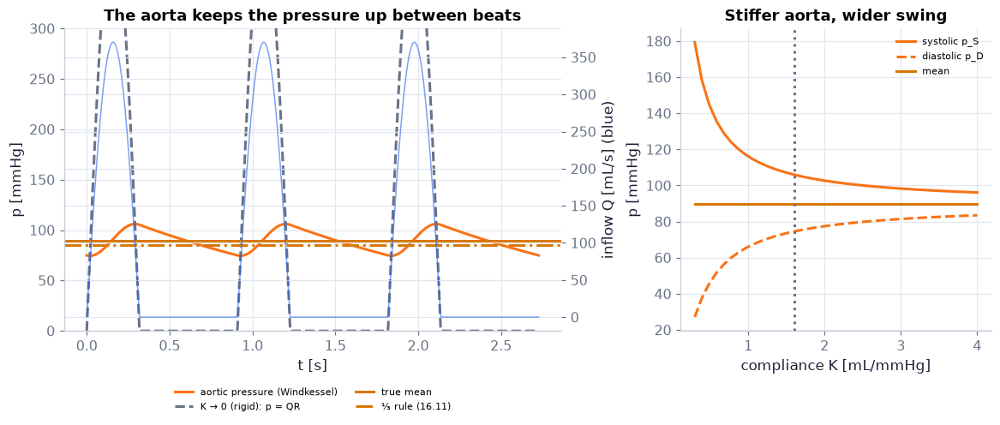

In [53]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 4.4), gridspec_kw=dict(width_ratios=[1.6, 1]))   # a new figure and its axes
t3 = np.linspace(0, 3*T, 1500)                                # three periodic beats
p3 = ch16.windkessel_periodic_state(t3, SV=SV, HR=heart["HR"], systole_share=heart["systole_share"], **windkessel)   # `ch16.windkessel_periodic_state` (the chapter module)
Q3 = Qin(t3)                                                  # inflow [m³/s]
ax.plot(t3, p3/MMHG, color=COLORS["orange"], lw=2, label="aortic pressure (Windkessel)")   # curve: aortic pressure (Windkessel)
ax.plot(t3, Q3*windkessel["R"]/MMHG, color=COLORS["muted"], ls="--", label="K → 0 (rigid): p = QR")   # curve: K → 0 (rigid): p = QR
ax.axhline(s["p_mean"]/MMHG, color=COLORS["amber"], label="true mean")   # a reference line
ax.axhline(s["map_third"]/MMHG, color=COLORS["amber"], ls="-.", label="⅓ rule (16.11)")   # a reference line
ax2 = ax.twinx(); ax2.plot(t3, Q3*1e6, color=COLORS["blue"], lw=1, alpha=0.6); ax2.set_ylabel("inflow Q [mL/s] (blue)")   # a second y-axis sharing the x-axis
ax.set(xlabel="t [s]", ylabel="p [mmHg]", ylim=(0, 300), title="The aorta keeps the pressure up between beats")   # axis labels, limits and title
ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)   # legend under the panel, clear of every curve
Ks = np.linspace(0.3, 4, 40)/(1e6*MMHG)                      # compliances 0.3 … 4 mL/mmHg [m³/Pa]
ss = [ch16.windkessel_summary(SV=SV, HR=heart["HR"], systole_share=heart["systole_share"], R=windkessel["R"], K=k) for k in Ks]   # periodic state for each K
bx.plot(Ks*1e6*MMHG, [x["pS"]/MMHG for x in ss], color=COLORS["orange"], label="systolic p_S")   # curve: systolic p_S
bx.plot(Ks*1e6*MMHG, [x["pD"]/MMHG for x in ss], color=COLORS["orange"], ls="--", label="diastolic p_D")   # curve: diastolic p_D
bx.plot(Ks*1e6*MMHG, [x["p_mean"]/MMHG for x in ss], color=COLORS["amber"], label="mean")   # curve: mean
bx.axvline(windkessel["K"]*1e6*MMHG, color=COLORS["muted"], ls=":")   # a reference line
bx.set(xlabel="compliance K [mL/mmHg]", ylabel="p [mmHg]", title="Stiffer aorta, wider swing"); bx.legend(fontsize=7)   # axis labels, limits and title
savefig(fig, "ch16", "c07_windkessel"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** Left: three periodic beats of our Windkessel — the inflow (blue, right axis), the aortic pressure (orange), what a
rigid aorta would give (grey dashed: p = QR, zero in diastole), the true mean (amber) and the ⅓-rule estimate (dash-dot).
Right: systolic, diastolic and mean pressure against the compliance at fixed R; the dotted line is our K.

**How to read it.** The pressure never falls to zero: during diastole it decays by $e^{-(T-T_s)/RK}=0.71$. On the right the mean is
flat — it is R times the mean inflow, whatever K — while the swing (the pulse pressure) widens as K falls.

**What would change if…** …the aorta stiffened with age (K halved)? The systolic pressure would rise and the diastolic fall at the same
mean — the isolated systolic hypertension of older people.

📝 **Note.** **N48 [B]** (From §16.2.) Along the circulation the large swings of the ventricle are damped: the ventricle's pressure
falls near zero each beat while the aorta stays high — our curves (a schematic ventricle and the Windkessel aorta), labelled
ours.

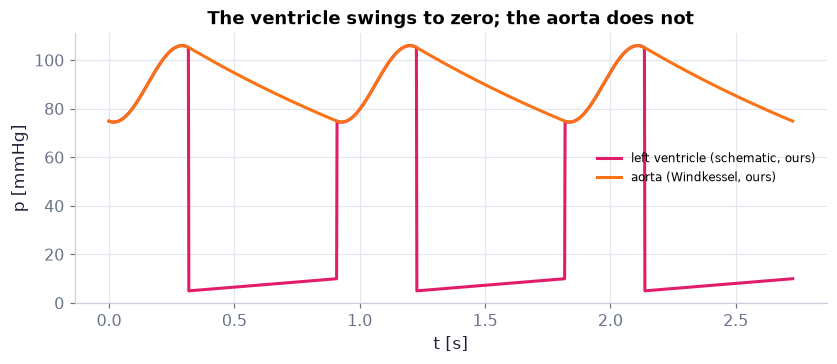

In [54]:
p_ao = ch16.windkessel_periodic_state(t3, SV=SV, HR=heart["HR"], systole_share=heart["systole_share"], **windkessel)   # aorta [Pa]
phase_ = (t3 % T)                                             # time within the beat [s]
p_lv = np.where(phase_ < Ts, np.maximum(p_ao, 5*MMHG + (p_ao - 5*MMHG)*np.abs(np.sin(np.pi*phase_/Ts))**0.3),   # ejection: ≈ aortic
                5*MMHG + 5*MMHG*(phase_ - Ts)/(T - Ts))      # filling: 5 → 10 mmHg (schematic, ours)
fig, ax = plt.subplots(figsize=(7.5, 3.2))   # a new figure and its axes
ax.plot(t3, p_lv/MMHG, color=COLORS["rose"], label="left ventricle (schematic, ours)")   # curve: left ventricle (schematic, ours)
ax.plot(t3, p_ao/MMHG, color=COLORS["orange"], lw=2, label="aorta (Windkessel, ours)")   # curve: aorta (Windkessel, ours)
ax.set(xlabel="t [s]", ylabel="p [mmHg]", title="The ventricle swings to zero; the aorta does not"); ax.legend(fontsize=8)   # axis labels, limits and title
savefig(fig, "ch16", "c07_ventricle_aorta"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** A schematic left-ventricle pressure (rose) and the Windkessel aortic pressure (orange) over three beats (both ours).

**How to read it.** While the aortic valve is open the two pressures nearly coincide; when it shuts the ventricle drops to a few
mmHg to refill, while the aorta, holding its stored blood, decays only slowly.

**What would change if…** …the aortic valve leaked? Blood would flow back into the ventricle in diastole and the aortic pressure would fall
faster — a wider pulse pressure.

> 📎 **Primer — `np.searchsorted`.** `P395` · `np.searchsorted(t, x)` takes a **sorted** array `t` and returns the index at which `x` would
have to be inserted to keep it sorted — the index of the first element ≥ x. The animations below use it to find how much of
a fine time grid has elapsed at each (coarser) frame time, and draw the trace up to there.

In [55]:
t_demo = np.array([0.0, 0.5, 1.0, 1.5])        # a sorted time grid [s]
print(np.searchsorted(t_demo, 0.7), np.searchsorted(t_demo, 1.0))   # 2 2: 0.7 s and 1.0 s both fall at index 2

2 2


In [56]:
nfr = 32 if FAST else 48                                      # frames over eight beats
tA = np.linspace(0, 8*T, nfr)                                 # frame times [s]
pA_t = ch16.windkessel_ode(t, Qin, windkessel["R"], windkessel["K"], 60*MMHG)   # the run from 60 mmHg (as above)
terms = ch16.windkessel_terms(tA % T, SV=SV, HR=heart["HR"], systole_share=heart["systole_share"], **windkessel)   # periodic split
fig, (ax, bx, cx) = plt.subplots(1, 3, figsize=(8, 3.0), gridspec_kw=dict(width_ratios=[2.2, 1, 1]))   # a new figure and its axes
ax.plot(t, pA_t/MMHG, color=COLORS["grid"]); (tr,) = ax.plot([], [], color=COLORS["orange"], lw=2)   # an empty line, filled in frame by frame by update()
ax.set(xlabel="t [s]", ylabel="p [mmHg]", xlim=(0, 8*T), ylim=(40, 120), title="Settling into the beat")   # axis labels, limits and title
bx.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect="equal"); bx.axis("off"); bx.set_title("aortic balloon", fontsize=9)   # axis labels, limits and title
ball = plt.Circle((0, 0), 1.0, color=COLORS["teal"], alpha=0.5); bx.add_patch(ball)   # a circle
bars = cx.bar([0, 1], [0, 0], color=[COLORS["teal"], COLORS["blue"]]); cx.set_xticks([0, 1], ["storage\nK dp/dt", "run-off\np/R"], fontsize=7)   # bars
cx.set(ylim=(-150, 350), ylabel="mL/s"); cx.set_title("inflow split (periodic)", fontsize=9)   # axis labels, limits and title
def update(i):                                                # frame i
    k = np.searchsorted(t, tA[i])                             # index of the first t ≥ this frame's time (primer P395 above)
    tr.set_data(t[:k + 1], pA_t[:k + 1]/MMHG)   # move the artist to this frame
    ball.set_radius(0.6 + 0.5*(pA_t[k]/MMHG - 40)/80)         # bigger when the pressure (stored volume) is higher
    for b, v in zip(bars, (terms["storage"][i], terms["runoff"][i])): b.set_height(v*1e6)   # move the artist to this frame
    return (tr, ball, *bars)   # what this function hands back
fig.canvas.draw(); fig.set_layout_engine("none")              # lay the figure out once, then freeze it (faster frames)
show_animation(animate(update, frames=nfr, fig=fig, interval=90), player="video")   # render the frames and embed the player

**Figure A1.** **What you see.** Eight beats starting from 60 mmHg: the pressure trace climbs and settles into the
periodic beat within about three time constants; the balloon breathes with the pressure; the bars split the inflow into
storage (K dp/dt, negative in diastole: the balloon gives blood back) and run-off (p/R, always positive). **How to read
it.** In diastole the inflow is zero, so storage = −run-off: the aorta feeds the periphery. **What would change if…** the
aorta were stiffer: RK shorter, the transient settles faster and the swing is larger.

> ▶️ **Live cell.** The widget below needs a running Python kernel. On the web page it is frozen — open this notebook in Colab (button at the top) or run it locally to drag the sliders.

In [57]:
def wk_live(R=1.45, K=1.6, HR=66.0, SV_mL=75.0):              # R in 1e8 Pa s/m³, K in mL/mmHg, HR in beats/min, SV in mL
    Kp = K/(1e6*MMHG)                                         # compliance in m³/Pa
    sm = ch16.windkessel_summary(SV=SV_mL*1e-6, HR=HR, systole_share=0.35, R=R*1e8, K=Kp)   # periodic state
    Tb = 60/HR; tt = np.linspace(0, 3*Tb, 900)                # three beats
    pp = ch16.windkessel_periodic_state(tt, SV=SV_mL*1e-6, HR=HR, systole_share=0.35, R=R*1e8, K=Kp)   # `ch16.windkessel_periodic_state` (the chapter module)
    fig, ax = plt.subplots(figsize=(6.5, 3)); ax.plot(tt, pp/MMHG, color=COLORS["orange"])   # a new figure and its axes
    ax.set(xlabel="t [s]", ylabel="p [mmHg]", ylim=(0, 250),   # axis labels, limits and title
           title=f"p_S/p_D = {sm['pS']/MMHG:.0f}/{sm['pD']/MMHG:.0f} mmHg, mean {sm['p_mean']/MMHG:.0f}, ⅓ rule error {100*(sm['map_third']/sm['p_mean'] - 1):+.1f} %")   # the figure's title: its message
    plt.show()                                                # draw this setting's figure
import ipywidgets as W                                        # slider widgets (kernel only); each opens on our resting values
sl = lambda lo, hi, st, v: W.FloatSlider(min=lo, max=hi, step=st, value=v, continuous_update=False)   # one slider: range lo…hi, step st, opening value v
_ = live(wk_live, R=sl(0.5, 3.0, 0.05, 1.45), K=sl(0.3, 4.0, 0.1, 1.6), HR=sl(40.0, 180.0, 2.0, 66.0), SV_mL=sl(40.0, 120.0, 1.0, 75.0))   # four sliders re-run wk_live; `_ =` keeps the cell from printing an object

interactive(children=(FloatSlider(value=1.45, continuous_update=False, description='R', max=3.0, min=0.5, step…

**What does the code above do?**

Four sliders (kernel only): R, K, heart rate and stroke volume; the title reports the periodic systolic/diastolic
pressure, the mean and the error of the ⅓ rule. The same idea runs on the web page in figure A1 above and in the explainer
below.

📝 **Note.** **N47 [C]** The model assumes the pressure is the same everywhere in the arteries at each instant — no travel time, no
reflection. C08 gives the pulse a finite speed; C13 adds reflections.

#### 🎮 Interactive: Why doesn't blood pressure fall to zero between beats?

**Why interactive rather than a static figure:** one clock drives the ventricle, the aortic balloon and the pressure trace; you change K and R and watch the beat
settle into a new rhythm, with the inflow split into storage and run-off at every instant — a static figure shows one
setting, the explainer shows the settling.

Start with the **Walkthrough**; the **Explain** tab works every number out with your settings, and the **Derivation** tab (where there is one) steps through the same derivation as above. Pressures are transmural and gauge (venous pressure 0), shown in mmHg; K is the compliance (not Murray's or Dean's K); every input is illustrative.

**What to try:**
- Press play and watch the pressure settle within a few beats.
- Halve K (stiff aorta): the pulse widens, the mean stays put.
- Raise the heart rate to 120: diastole shortens and p_D climbs.

In [58]:
show_viz("ch16", "windkessel_heartbeat")   # full-width explainer; ⤢ Full screen for more room

[explainer ch16/windkessel_heartbeat]

**What would change if…** …the aorta were long enough for the pressure to take time to travel along it? Then the pressure would be a wave, not a
single number — C08.

### 🧩 The pulse is a wave of wall stretch: $c=\sqrt{\dfrac{Eh}{2\rho a_0}}$ (16.62) `C08`

*The question:* Is the pulse you feel at your wrist the blood arriving?

#### The problem in plain words

Press your fingers on your wrist: the beat arrives about a tenth of a second after the heart's. The blood itself takes many
seconds to get there. **What travels is a bulge**: the heart's push stretches the aorta, the stretched wall squeezes the
blood ahead, which stretches the next piece of wall. A stiffer wall passes the push on faster.

#### The idea

```
wall stiffness (a spring)  +  blood inertia (a mass)  ──►  a wave,   c² = stiffness / inertia
```

📝 **Note.** **N49 [B]** Model: inviscid, incompressible blood in a long thin elastic tube; long waves; the pressure uniform over each
section. Area continuity $\dfrac{\partial A}{\partial t}+\dfrac{\partial(Au)}{\partial x}=0$ (16.53) — the area is now an unknown (Ch. 15's duct laws in time).

> 🔁 **Recap — The material derivative in one dimension** (Ch. 3). $Du/Dt=\partial u/\partial t+u\,\partial u/\partial x$: the
acceleration of a fluid particle, its local change plus the change it meets by moving.

📝 **Note.** **N50 [B]** Momentum per slice: $\rho A\left(\dfrac{\partial u}{\partial t}+u\dfrac{\partial u}{\partial x}\right)=-A\dfrac{\partial p}{\partial x}$ (16.54, corrected).

> ⚠️ **slip S5 — the book prints** $\rho A\left(\dfrac{\partial u}{\partial t}+u\dfrac{\partial u}{\partial x}\right)=-\dfrac{\partial((p-p_e)A)}{\partial x}$ (16.54, as printed); **the correct form is** $\rho A\left(\dfrac{\partial u}{\partial t}+u\dfrac{\partial u}{\partial x}\right)=-A\dfrac{\partial p}{\partial x}$ (16.54, corrected)
>
> The printed form misses the push of the sloping wall. Linearised, both give $\rho\dfrac{\partial u}{\partial t}=-\dfrac{\partial p}{\partial x}$ (16.57),
so the wave speed is unaffected; the nonlinear run below uses the corrected form.

📝 **Note.** **N51 [B]** The tube law in A: $p-p_e=\dfrac{Eh}{a_0}\left[1-\left(\dfrac{A_0}{A}\right)^{1/2}\right]$ (16.55) — the inverse of $a=a_0\left[1-\dfrac{a_0}{Eh}(p-p_e)\right]^{-1}$ (16.41) with A = πa².

In [59]:
A0a = np.pi*aorta["a0"]**2                                  # undisturbed area of our aorta [m²]
a_test = ch16.tube_radius_hookean(25*MMHG, 0.0, aorta["a0"], aorta["E"], aorta["h"])   # (16.41) at 25 mmHg
print(ch16.tube_law_hookean(np.pi*a_test**2, A0a, aorta["E"], aorta["h"], aorta["a0"])/MMHG, "mmHg")   # (16.55) gives 25 back

25.000000000000046 mmHg


> 🔁 **Tools from earlier chapters used in this block** (one line each; the full primers are in the chapters named)

- **limits and orders of smallness** — when a quantity ε is small, ε² is smaller still and is dropped beside ε; here products of two small disturbances are dropped to linearise the tube equations. *(Ch. 2, P68)*
- **Schwarz's theorem (mixed partials commute)** — for a smooth function ∂²u/∂t∂x = ∂²u/∂x∂t; here it lets the area law and the momentum law share one term so the velocity can be eliminated. *(Ch. 4, P121)*
- **the second-order wave equation and its two characteristic coordinates** — p_tt = c²p_xx is solved by any f(x − ct) + g(x + ct), two shapes sliding apart at ±c; the pulse in an artery is exactly this. *(Ch. 15, P357)*

#### 🧮 Derivation — The linearised tube equations `D11` ★★ (Eq. 16.58: $p-p_e=\dfrac{Eh}{2a_0A_0}(A-A_0)$)

**What we want to show.** Reduce the full one-dimensional laws of a blood-filled elastic tube to linear equations for a small pulse.

**Assumptions.** Small area change, small speed u ≪ c, long waves (steps 3–5); p_e constant (step 2).

**The plan.**

1. Split into rest + small parts.
2. The corrected momentum law.
3. Drop products.
4. Taylor-expand the tube law.

**Tools we use** (each explained before this point): basic state + small disturbance (Ch. 15 D01, recap) · orders of smallness (P68, reminder) · Taylor (P26, reminder)

**We start from**

$$ \begin{array}{l}\dfrac{\partial A}{\partial t}+\dfrac{\partial(Au)}{\partial x}=0\qquad\text{(16.53)} \\[6pt] \rho A\left(\dfrac{\partial u}{\partial t}+u\dfrac{\partial u}{\partial x}\right)=-A\dfrac{\partial p}{\partial x}\qquad\text{(16.54, corrected)} \\[6pt] p-p_e=\dfrac{Eh}{a_0}\left[1-\left(\dfrac{A_0}{A}\right)^{1/2}\right]\qquad\text{(16.55)}\end{array} $$

*In words:* Area conservation, the corrected momentum law and the Hookean tube law for a blood-filled elastic tube.

---

**Step 1 of 7 — Split each unknown into rest plus a small part.**

$$ A=A_0+A',\quad u=u',\quad p-p_e=p' $$

- *Why we can do this:* The undisturbed state is a tube of area A₀ with the blood at rest and zero transmural pressure; primes are small (basic state + disturbance, Ch. 15 D01).
- *In words:* A small pulse on a resting tube.

---

**Step 2 of 7 — Write momentum with the wall's push.**

$$ \rho A\left(\dfrac{\partial u}{\partial t}+u\dfrac{\partial u}{\partial x}\right)=-A\dfrac{\partial p}{\partial x}\ \text{(16.54, corrected)} $$

- *Why we can do this:* On a slice the end pressures give $-\partial(pA)/\partial x$ and the sloping wall pushes back with $+p\,\partial A/\partial x$: the sum is $-A\,\partial p/\partial x$. The book prints $-\partial((p-p_e)A)/\partial x$ (slip S5).
- *In words:* Blood accelerates down the pressure gradient.

---

**Step 3 of 7 — Linearise the area law.**

$$ \dfrac{\partial A'}{\partial t}+A_0\dfrac{\partial u'}{\partial x}=0\ \text{(16.56)} $$

- *Why we can do this:* $\partial(Au)/\partial x=A_0\,\partial u'/\partial x+\partial(A'u')/\partial x$; A'u' is a product of two small quantities, dropped (P68).
- *In words:* The tube swells where the flow converges.

---

**Step 4 of 7 — Divide momentum by A and drop the product.**

$$ \rho\dfrac{\partial u'}{\partial t}=-\dfrac{\partial p'}{\partial x}\ \text{(16.57)} $$

- *Why we can do this:* A > 0; $u'\partial u'/\partial x$ is second order (small because u ≪ c); p_e is constant, so $\partial p/\partial x=\partial p'/\partial x$. The extra term of the printed $\rho A\left(\dfrac{\partial u}{\partial t}+u\dfrac{\partial u}{\partial x}\right)=-\dfrac{\partial((p-p_e)A)}{\partial x}$ (16.54, as printed) would also drop here — slip S5 changes only the nonlinear model.
- *In words:* Newton's law for each slice.

---

**Step 5 of 7 — Expand the square root of the tube law.**

$$ \left(\dfrac{A_0}{A}\right)^{1/2}=\left(1+\dfrac{A'}{A_0}\right)^{-1/2}\approx1-\dfrac{A'}{2A_0} $$

- *Why we can do this:* Taylor (binomial) expansion for $A'/A_0\ll1$ (P26).
- *In words:* A small swelling changes the square root by half as much.

---

**Step 6 of 7 — Substitute into (16.55).**

$$ p-p_e=\dfrac{Eh}{2a_0A_0}(A-A_0)\ \text{(16.58)} $$

- *Why we can do this:* $\dfrac{Eh}{a_0}\left[1-\left(1-\dfrac{A'}{2A_0}\right)\right]=\dfrac{Eh}{a_0}\dfrac{A'}{2A_0}$. Replacing the square root by its expansion of step 5 keeps the law valid to first order; the result is linear in A′.
- *In words:* For small pulses the wall is a linear spring.

---

**Step 7 of 7 — Read off the stiffness.**

$$ \dfrac{\partial p}{\partial A}=\dfrac{Eh}{2a_0A_0}\ \text{(16.58)} $$

- *Why we can do this:* The derivative of the linear law.
- *In words:* How many pascals one more square metre of area costs.

---

**Result**

$$ \begin{array}{l}\dfrac{\partial A}{\partial t}+A_0\dfrac{\partial u}{\partial x}=0\qquad\text{(16.56)} \\[6pt] \rho\dfrac{\partial u}{\partial t}=-\dfrac{\partial p}{\partial x}\qquad\text{(16.57)} \\[6pt] p-p_e=\dfrac{Eh}{2a_0A_0}(A-A_0)\qquad\text{(16.58)}\end{array} $$

*In words:* Linear laws for a small pulse: area, momentum and a linear spring for the wall.

**What it means.** Small pulses obey linear laws, so they add and travel without changing shape (D12). Fails for large pulses (steepening, N54) or fast flow (u comparable with c, C15).

**Check it.** Units of Eh/(2a₀A₀): Pa·m/(m·m²) = Pa/m² ✓; our aorta with a 25 mmHg pulse: p′/(Eh/a₀) = **0.067**, u/c = **0.13** (expect; `ch16.linearisation_ratios`) — both small.

📝 **Notes taught inside `D11`:** **N52 [B]** what was dropped and how small it is (steps 3–5).

> ⚠️ **Common confusion (traps in `D11`):** Slip S5; dropping u ∂u/∂x needs u ≪ c, not merely a small pulse.

In [60]:
print(ch16.linearisation_ratios(25*MMHG, 100*MMHG, 0.65, 4.86, Eh_over_a0=50e3))   # pulse/mean, u/c, strain: 0.25, 0.13, 0.067

{'p_ratio': 0.25, 'u_over_c': 0.1337448559670782, 'strain': 0.06666119370750001}


#### 🧮 Derivation — The wave equation and the Moens–Korteweg speed `D12` ★★ (Eq. 16.62: $c=\sqrt{\dfrac{Eh}{2\rho a_0}}$)

**What we want to show.** Combine the linear laws into one wave equation for the pressure and read off its speed.

**Assumptions.** a uniform tube: A₀, E, h, a₀ constant (steps 1, 5).

**The plan.**

1. Differentiate across.
2. Swap the mixed derivative.
3. Eliminate u.
4. Turn area into pressure.

**Tools we use** (each explained before this point): cross-differentiation (Ch. 15 D02, recap) · Schwarz's theorem (P121, reminder) · chain rule (P49, reminder)

**We start from**

$$ \begin{array}{l}\dfrac{\partial A}{\partial t}+A_0\dfrac{\partial u}{\partial x}=0\qquad\text{(16.56)} \\[6pt] \rho\dfrac{\partial u}{\partial t}=-\dfrac{\partial p}{\partial x}\qquad\text{(16.57)} \\[6pt] p-p_e=\dfrac{Eh}{2a_0A_0}(A-A_0)\qquad\text{(16.58)}\end{array} $$

*In words:* The three linear laws of D11: area, momentum and the linear tube law.

---

**Step 1 of 7 — Differentiate the area law in time.**

$$ \dfrac{\partial^2A}{\partial t^2}+A_0\dfrac{\partial^2u}{\partial t\,\partial x}=0 $$

- *Why we can do this:* ∂/∂t of $\dfrac{\partial A}{\partial t}+A_0\dfrac{\partial u}{\partial x}=0$ (16.56); A₀ is constant.
- *In words:* How the swelling accelerates.

---

**Step 2 of 7 — Differentiate momentum in space.**

$$ \rho\dfrac{\partial^2u}{\partial x\,\partial t}=-\dfrac{\partial^2p}{\partial x^2} $$

- *Why we can do this:* ∂/∂x of $\rho\dfrac{\partial u}{\partial t}=-\dfrac{\partial p}{\partial x}$ (16.57).
- *In words:* How the acceleration changes along the tube.

---

**Step 3 of 7 — Swap the order of the mixed derivative.**

$$ \dfrac{\partial^2u}{\partial t\,\partial x}=\dfrac{\partial^2u}{\partial x\,\partial t} $$

- *Why we can do this:* Schwarz's theorem (P121) for a smooth u; it lets steps 1 and 2 share a term.
- *In words:* Same quantity, two orders.

---

**Step 4 of 7 — Eliminate the velocity.**

$$ \dfrac{\partial^2A}{\partial t^2}=\dfrac{A_0}{\rho}\dfrac{\partial^2p}{\partial x^2}\ \text{(16.59)} $$

- *Why we can do this:* Step 2 gives the mixed term as $-\frac1\rho\partial^2p/\partial x^2$; put it in step 1.
- *In words:* The tube swells faster where the pressure is curved.

---

**Step 5 of 7 — Turn area into pressure.**

$$ \dfrac{\partial^2p}{\partial t^2}=\dfrac{\partial p}{\partial A}\dfrac{\partial^2A}{\partial t^2}\ \text{(16.60)} $$

- *Why we can do this:* p depends on t only through A by $p-p_e=\dfrac{Eh}{2a_0A_0}(A-A_0)$ (16.58), with a constant slope ∂p/∂A, so the chain rule (P49) applied twice gives no extra term.
- *In words:* Pressure follows area with a fixed factor.

---

**Step 6 of 7 — Combine.**

$$ \dfrac{\partial^2p}{\partial t^2}=c^2\dfrac{\partial^2p}{\partial x^2},\quad c^2=\dfrac{A_0}{\rho}\dfrac{\partial p}{\partial A}\ \text{(16.61)} $$

- *Why we can do this:* Put $\dfrac{\partial^2A}{\partial t^2}=\dfrac{A_0}{\rho}\dfrac{\partial^2p}{\partial x^2}$ (16.59) into $\dfrac{\partial^2p}{\partial t^2}=\dfrac{\partial p}{\partial A}\dfrac{\partial^2A}{\partial t^2}$ (16.60); the constant is positive (a tube that resists swelling), so it is a speed squared.
- *In words:* The pressure obeys the wave equation of Ch. 15.

---

**Step 7 of 7 — Insert the Hookean slope.**

$$ c=\sqrt{\dfrac{A_0}{\rho}\dfrac{Eh}{2a_0A_0}}=\sqrt{\dfrac{Eh}{2\rho a_0}}\ \text{(16.62)} $$

- *Why we can do this:* $p-p_e=\dfrac{Eh}{2a_0A_0}(A-A_0)$ (16.58)'s slope; A₀ cancels. With a general tube law the second form $c^2=\dfrac A\rho\dfrac{dp}{dA}$ stays (Bramwell–Hill).
- *In words:* The Moens–Korteweg speed: wall stiffness against blood inertia.

---

**Result**

$$ \text{(16.61) with}\ c=\sqrt{\dfrac{Eh}{2\rho a_0}}=\sqrt{\dfrac A\rho\dfrac{dp}{dA}}\ \text{(16.62).} $$

**What it means.** The pulse is a wave of wall stretch; measuring its speed measures arterial stiffness (pulse-wave velocity). Fails at large α only slightly (C11) but at small α strongly (viscous waves are slow and damped).

**Check it.** Units Pa·m/(kg m⁻³·m) = m²/s² ✓; easy numbers E = 0.72 MPa, h/a₀ = 0.1, ρ = 1000 kg/m³: c² = 36, **c = 6 m/s**; our aorta **4.86 m/s** (thick-wall $c=\sqrt{\dfrac{Eh}{2\rho(a_0+h/2)}}$ (16.63): 4.71 m/s); E → ∞: c → ∞, the rigid tube of C09 (T23).

> ⚠️ **Common confusion (traps in `D12`):** Eh/(2ρa₀) uses the radius; with the diameter it reads Eh/(ρd) (T17); c is not the blood's speed.

#### ✏️ Tiny example: the pulse speed in an aorta

1. E = 0.72 MPa, h/a₀ = 0.1, ρ = 1000 kg/m³ (easy numbers): c² = 0.72 × 10⁶ × 0.1/2000 = 36, c = **6 m/s**.
2. Our aorta (E = 0.4 MPa, h/a₀ = 0.125, ρ = 1060): c = √($0.4$ × 10⁶ × 0.125/2120) = **4.86 m/s**.
3. Over 0.5 m to the wrist: 0.10 s.
4. Under a 25 mmHg crest the blood moves at p/(ρc) = 3333/(1060 × 4.86) = **0.65 m/s**, only while the crest passes.

In [61]:
c0 = ch16.moens_korteweg_speed(aorta["E"], aorta["h"], blood["rho"], aorta["a0"])   # (16.62) [m/s]
c_mid = ch16.moens_korteweg_speed(aorta["E"], aorta["h"], blood["rho"], aorta["a0"], midwall=True)   # (16.63) thick wall
dpdA = aorta["E"]*aorta["h"]/(2*aorta["a0"]*A0a)             # slope of the linear tube law (16.58) [Pa/m²]
c_bh = ch16.bramwell_hill_speed(A0a, dpdA, blood["rho"])     # c² = (A/ρ) dp/dA, the general form
E_back = ch16.youngs_modulus_from_pwv(c0, aorta["h"], blood["rho"], aorta["a0"])   # invert (16.62) from a measured speed
u_crest = ch16.velocity_from_pulse(25*MMHG, blood["rho"], c0)   # (16.68): u = p/(ρc) under a 25 mmHg crest
print(f"c0 = {c0:.4f} m/s, thick-wall {c_mid:.4f} m/s, Bramwell–Hill {c_bh:.4f} m/s, E back = {E_back:.4g} Pa, u = {u_crest:.3f} m/s")   # print the result

c0 = 4.8564 m/s, thick-wall 4.7114 m/s, Bramwell–Hill 4.8564 m/s, E back = 4e+05 Pa, u = 0.647 m/s


📝 **Note.** **N53 [B]** Thick walls: evaluate the strain at mid-wall, $c=\sqrt{\dfrac{Eh}{2\rho(a_0+h/2)}}$ (16.63) (result given) — 3 % slower for h/a₀ = 0.125.
Inverting $c=\sqrt{\dfrac{Eh}{2\rho a_0}}$ (16.62) gives E from a measured transit time (`youngs_modulus_from_pwv`).

> 🔁 **Recap — d'Alembert's solution `R09`** (Ch. 15 §15.2 (C02, D03)). $p'(x,t)=f(x-ct)+g(x+ct)$ (15.15): any two shapes sliding apart at ±c. **New here:** the book writes shapes in
time, $p=f_1\left(t-\dfrac xc\right)+f_2\left(t+\dfrac xc\right)$ (16.65) — a pressure trace recorded at one place.

In [62]:
F = lambda s: np.exp(-(s/0.1)**2)                           # a space shape [–] of width 0.1 m
f1 = lambda tau: F(-c0*tau)                                 # the same pulse as a time shape: f(x − ct) = f1(t − x/c)
xg = np.linspace(-0.5, 1.0, 7)                              # positions [m]
print(np.allclose(ch16.pulse_wave(xg, 0.1, c0, f1), AC.dalembert(xg, 0.1, c0, f=F)))   # (16.65) = (15.15): True

True


> 🔁 **Recap — Pressure and particle velocity `R10`** (Ch. 15 §15.2 (C02, D04)). $u_1'(x,t)=\dfrac1{\rho_0c}\left(f(x-ct)-g(x+ct)\right)$ (15.16). **New here:** $\hat p_1=\rho c\hat u_1,\ \ \hat p_2=-\rho c\hat u_2$ (16.68) with c the tube's wave speed — the seed of the
admittance of C13.

In [63]:
h_ = 1e-4                                                     # step for finite differences [m] and [s]
X_, T_ = np.meshgrid(np.linspace(-0.3, 0.9, 61), np.linspace(0.02, 0.12, 21))   # a grid of (x, t)
p = lambda x, t: F(x - c0*t)                                  # a right-going pulse
p_tt = (p(X_, T_ + h_) - 2*p(X_, T_) + p(X_, T_ - h_))/h_**2  # second time difference
p_xx = (p(X_ + h_, T_) - 2*p(X_, T_) + p(X_ - h_, T_))/h_**2  # second space difference
assert np.max(np.abs(p_tt - c0**2*p_xx)) < 1e-4*np.max(np.abs(p_tt))   # the wave equation (16.61) holds
assert np.allclose(ch16.pulse_wave(X_, T_, c0, f1), p(X_, T_))          # and the library's (16.65) is this pulse
print("residual of p_tt − c²p_xx:", np.max(np.abs(p_tt - c0**2*p_xx))/np.max(np.abs(p_tt)))   # print the result

residual of p_tt − c²p_xx: 1.1292462827876572e-05


**What does the code above do?**

Second differences of a sliding Gaussian on a grid (`np.meshgrid` builds every (x, t) pair) show
$p_{tt}=c^2p_{xx}$ to round-off; the library's $p=f_1\left(t-\dfrac xc\right)+f_2\left(t+\dfrac xc\right)$ (16.65) returns the same pulse.

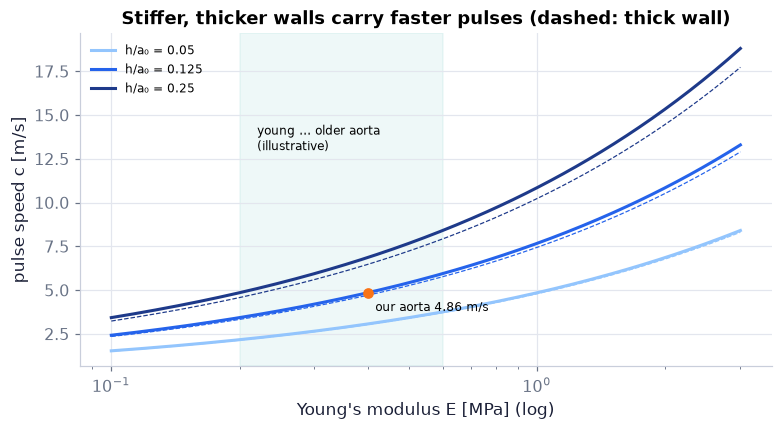

In [64]:
Es = np.logspace(5, np.log10(3e6), 200)                       # Young's modulus 0.1 … 3 MPa
fig, ax = plt.subplots(figsize=(7, 3.8))   # a new figure and its axes
for ratio, col in ((0.05, "#93c5fd"), (0.125, COLORS["blue"]), (0.25, "#1e3a8a")):   # wall-thickness ratios h/a0
    ax.semilogx(Es/1e6, ch16.moens_korteweg_speed(Es, ratio*aorta["a0"], blood["rho"], aorta["a0"]), color=col, label=f"h/a₀ = {ratio}")   # curve: h/a₀ = {ratio}
    ax.semilogx(Es/1e6, ch16.moens_korteweg_speed(Es, ratio*aorta["a0"], blood["rho"], aorta["a0"], midwall=True), "--", color=col, lw=0.8)   # dashed: the thick-wall form (16.63)
ax.axvspan(0.2, 0.6, color=COLORS["teal"], alpha=0.07); ax.text(0.22, 13, "young … older aorta\n(illustrative)", fontsize=8)   # a shaded band
ax.plot(aorta["E"]/1e6, c0, "o", color=COLORS["orange"]); ax.annotate(f"our aorta {c0:.2f} m/s", (aorta["E"]/1e6, c0), xytext=(5, -12), textcoords="offset points", fontsize=8)   # orange dot: our aorta, labelled with its speed
ax.set(xlabel="Young's modulus E [MPa] (log)", ylabel="pulse speed c [m/s]", title="Stiffer, thicker walls carry faster pulses (dashed: thick wall)")   # axis labels, limits and title
ax.legend(fontsize=8)   # the legend
savefig(fig, "ch16", "c08_pulse_speed"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** The Moens–Korteweg speed against Young's modulus for three wall-thickness ratios (solid), the thick-wall form
$c=\sqrt{\dfrac{Eh}{2\rho(a_0+h/2)}}$ (16.63) dashed, an illustrative band of aortic stiffnesses, and our aorta (orange dot).

**How to read it.** c ∝ √E: each factor 4 in stiffness doubles the speed; a thicker wall (larger h/a₀) is stiffer for the same E.
Pulse speeds of a few to ten metres per second — far faster than the blood itself.

**What would change if…** …E quadrupled (a stiff, old aorta)? The pulse speed doubles, the reflected wave returns earlier (C13) and the
systolic peak rises — pulse-wave velocity is a clinical measure of arterial stiffness.

In [65]:
nfr = 24 if FAST else 40                                      # frames
xs_ = np.linspace(0, 1.0, 300)                                # 1 m of artery [m]
tt_ = np.linspace(0, 0.16, nfr)                               # 0.16 s: the crest travels about 0.8 m
amp = 25*MMHG                                                 # crest pressure [Pa]
st0 = ch16.pulse_state(xs_, 0.0, c=c0, amplitude=amp, width=0.08, rho=blood["rho"], a0=aorta["a0"], E=aorta["E"], h=aorta["h"], x0=0.15)   # `ch16.pulse_state` (the chapter module)
xp = np.linspace(0.05, 0.95, 19)                              # tracer particles in the blood [m]
fig, ax = plt.subplots(figsize=(7.5, 3.0))   # a new figure and its axes
ex = 4.0                                                      # wall bulge drawn ×4
(top,) = ax.plot([], [], color=COLORS["teal"], lw=2); (bot,) = ax.plot([], [], color=COLORS["teal"], lw=2)   # an empty line, filled in frame by frame by update()
dots = ax.scatter(xp, np.zeros_like(xp), s=14, color=COLORS["blue"])   # markers (the tracers)
ax.set(xlim=(0, 1), ylim=(-2.2, 2.2), xlabel="x [m]", ylabel="r / a₀", title=f"The bulge runs at c = {c0:.2f} m/s; the blood barely moves (bulge ×{ex:.0f})")   # axis labels, limits and title
xp_now = xp.copy(); prev_t = 0.0                              # tracer positions now [m] and the time of the last frame [s]
def update(i):                                                # frame i
    global xp_now, prev_t   # the tracers' state is kept between frames
    st = ch16.pulse_state(xs_, tt_[i], c=c0, amplitude=amp, width=0.08, rho=blood["rho"], a0=aorta["a0"], E=aorta["E"], h=aorta["h"], x0=0.15)   # `ch16.pulse_state` (the chapter module)
    y = 1 + ex*(st["a"]/aorta["a0"] - 1)                      # exaggerated wall radius
    top.set_data(xs_, y); bot.set_data(xs_, -y)   # move the artist to this frame
    u_p = np.interp(xp_now, xs_, st["u"])                     # blood speed at each tracer [m/s]
    xp_now = xp_now + u_p*(tt_[i] - prev_t); prev_t = tt_[i]  # move the tracers (Euler step)
    dots.set_offsets(np.c_[xp_now, np.zeros_like(xp_now)])   # move the artist to this frame
    return top, bot, dots   # what this function hands back
fig.canvas.draw(); fig.set_layout_engine("none")              # lay the figure out once, then freeze it (faster frames)
show_animation(animate(update, frames=nfr, fig=fig, interval=60), player="video")   # render the frames and embed the player
print(f"true radius change under the crest: {(st0['a'].max()/aorta['a0'] - 1)*100:.1f} % (drawn ×{ex:.0f})")   # print the result
shift = st0["u"].max()*0.08*np.sqrt(np.pi)/c0                 # tracer shift = ∫u dt = (u_max/c)∫e^{−(x/w)²}dx = u_max w√π/c [m]
print(f"blood speed under the crest {st0['u'].max():.3f} m/s; each tracer moves on by {shift*100:.1f} cm as the pulse passes")   # print the result

true radius change under the crest: 7.1 % (drawn ×4)
blood speed under the crest 0.647 m/s; each tracer moves on by 1.9 cm as the pulse passes


**Figure A2.** **What you see.** A 25 mmHg pressure pulse travelling along 1 m of our aorta: the teal walls bulge
(drawn four times larger than the true 7 % — the printed line gives the true size) and the bulge runs at c = 4.86 m/s; the
blue tracers in the blood shift forward by about 2 cm (printed: $u_{max}w\sqrt\pi/c$ = 0.647 × 0.08 × 1.77/4.86 m) and
stop. **How to read it.** The wave moves, the blood hardly does: what reaches your wrist first is the bulge. **What would
change if…** the wall were four times stiffer: the bulge would run twice as fast ($c\propto\sqrt E$) and bulge only a
quarter as much for the same pressure (the radius change $a_0^2(p-p_e)/(Eh)$ is ∝ 1/E).

📝 **Note.** **N54 [B]** Measured pulses travel at a few metres per second in the aorta and faster in stiffer peripheral arteries;
waves in collapsible veins are slower still (C15); real pulses peak by reflection (C13), steepen (nonlinearity) and damp
(C11). Below, a large pulse in our nonlinear 1-D model (ours — **DEVIATION**: MacCormack's scheme of Ch. 10 with a small
artificial viscosity; the book stops at the linear wave equation).

> 🔁 **Recap — Riemann invariants** (Ch. 15 P358; characteristics Ch. 7 P174). In Ch. 15 a gas carried $u\pm\dfrac{2c}{\gamma-1}$
unchanged along its characteristics. The same idea holds for our elastic tube: the quantity $u\pm\displaystyle\int\frac{c\,dA}{A}$
keeps its value along the characteristics $\dfrac{dx}{dt}=u\pm c$. **Where the 4 comes from:** the Hookean tube law $p-p_e=\dfrac{Eh}{a_0}\left[1-\left(\dfrac{A_0}{A}\right)^{1/2}\right]$ (16.55)
gives $c=c_0\left(\dfrac{A_0}{A}\right)^{1/4}$, so $dc/c=-\tfrac14\,dA/A$, i.e. $\dfrac{c\,dA}{A}=-4\,dc$ and
$\displaystyle\int\frac{c\,dA}{A}=-4c$ (+ a constant). The invariant on the left-going characteristics $dx/dt=u-c$ is therefore
$u-(-4c)=u+4c$. If we start with $u+4c$ the same everywhere, every left-going characteristic carries the same value, so
**no left-going wave exists** — the pulse below is purely right-going. Check with easy numbers: at the foot $c=c_0$ and
$u=0$, so $u+4c=4c_0$; under the crest c is smaller, so $u=4(c_0-c)>0$ — the blood moves forward under the bulge.

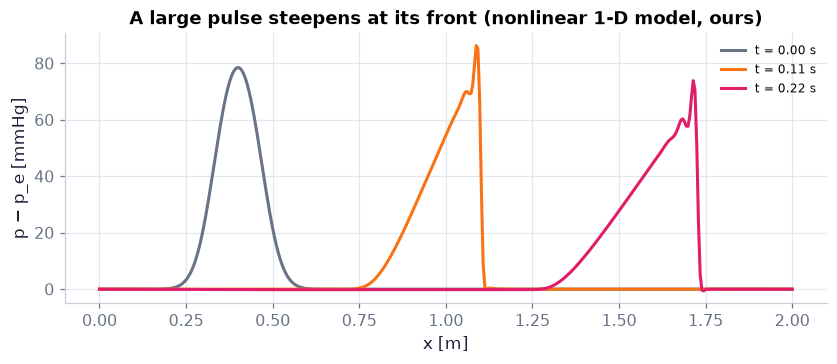

crest: c = 4.32 m/s (c/c₀ = 0.89), u = 2.15 m/s, u + c = 6.47 m/s; foot: u + c = c₀ = 4.86 m/s
the front breaks at t ≈ 0.061 s; peak p − p_e at t = 0, 0.11, 0.22 s: [78.5 86.3 73.9] mmHg
mass kept: -3.3e-16 (relative)


In [66]:
nx_ = 200 if FAST else 400                                    # grid points
x1 = np.linspace(0, 2.0, nx_)                                 # 2 m of tube [m]
A_in = A0a*(1 + 0.6*np.exp(-((x1 - 0.4)/0.08)**2))            # a large bulge: area up 60 % (ours)
p_in = ch16.tube_law_hookean(A_in, A0a, aorta["E"], aorta["h"], aorta["a0"])   # its pressure (16.55) [Pa]
c_in = c0*(A0a/A_in)**0.25                                    # local wave speed of the Hookean tube law: c = c₀(A₀/A)^{1/4} [m/s]
u_in = 4*(c0 - c_in)                                          # Riemann invariant u + 4c = 4c₀ everywhere (u + ∫c dA/A with ∫c dA/A = −4c), carried by the left-going characteristics u − c: uniform → no left-going wave [m/s]
run = ch16.tube1d_run(x1, A_in, u_in, A0a, aorta["E"], aorta["h"], aorta["a0"], blood["rho"], 0.22, snapshots=(0.0, 0.11, 0.22))   # `ch16.tube1d_run` (the chapter module)
fig, ax = plt.subplots(figsize=(7.5, 3.2))   # a new figure and its axes
for k, col in zip(range(3), (COLORS["muted"], COLORS["orange"], COLORS["rose"])):   # the three snapshot times, grey → orange → rose
    ax.plot(x1, run["snapshots"]["p"][k]/MMHG, color=col, label=f"t = {run['snapshots']['t'][k]:.2f} s")   # curve: t = {run['snapshots']['t'][k]:.2f} s
ax.set(xlabel="x [m]", ylabel="p − p_e [mmHg]", title="A large pulse steepens at its front (nonlinear 1-D model, ours)")   # axis labels, limits and title
ax.legend(fontsize=8)   # the legend
savefig(fig, "ch16", "c08_steepening"); plt.show()   # save to outputs/ch16/ and show the figure
lam = u_in + c_in                                              # characteristic speed u + c of each point of the start [m/s]
t_break = -1/np.min(np.gradient(lam, x1))                      # when the faster crest first catches the slower foot [s]
k_c = np.argmax(p_in)                                          # index of the crest
print(f"crest: c = {c_in[k_c]:.2f} m/s (c/c₀ = {c_in[k_c]/c0:.2f}), u = {u_in[k_c]:.2f} m/s, u + c = {lam[k_c]:.2f} m/s; foot: u + c = c₀ = {c0:.2f} m/s")   # print the result
print(f"the front breaks at t ≈ {t_break:.3f} s; peak p − p_e at t = 0, 0.11, 0.22 s:", np.round(run["snapshots"]["p"].max(axis=1)/MMHG, 1), "mmHg")   # print the result
print(f"mass kept: {run['mass']/run['mass0'] - 1:.1e} (relative)")   # print the result

**What you see.** Pressure along 2 m of our aorta at three times for a large right-going pulse in the nonlinear 1-D model (ours). The
start is a pure right-going wave. 🔁 Riemann invariant (Ch. 15 P358, which covered a gas, $u\pm2c/(\gamma-1)$):
$u\pm\int c\,dA/A$ keeps its value along $dx/dt=u\pm c$ (Ch. 7 P174); here $c\propto A^{-1/4}$ gives $\int c\,dA/A=-4c$, so
$u+4c$ rides the left-going characteristics — make it uniform and no left-going wave exists. So the blood speed is set so
that $u+4c$ is the same everywhere, $u=4(c_0-c)$ (zero at the foot, where $c=c_0$), and nothing travels left.

**How to read it.** The crest moves faster than the foot, so the front steepens and the back stretches. The reason is not that the
wave itself is faster in a wider tube: with the tube law $p-p_e=\dfrac{Eh}{a_0}\left[1-\left(\dfrac{A_0}{A}\right)^{1/2}\right]$ (16.55) the wave speed is $c^2=\dfrac{Eh}{2\rho a_0}\left(\dfrac{A_0}{A}\right)^{1/2}$,
which **falls** as the tube widens (c/c₀ = 0.89 under the crest, where A/A₀ = 1.6). What a point of the pulse travels at is
$u+c$, the wave speed plus the blood's own speed, and u rises faster than c falls: about 6.5 m/s at the crest against
4.86 m/s at the foot (printed). The front breaks at about t = 0.06 s; after that it is a jump the scheme cannot resolve, and
the peak printed above its starting 78.5 mmHg (84–86 mmHg at t = 0.11 s, depending on the grid), the small wiggles just
behind it and the slight dip below zero just ahead of it are MacCormack's numerical ringing at that jump, not physics — the
exact solution never raises the crest. The later fall of the peak is real in this
inviscid model: the jump eats into the crest. Total volume is conserved to round-off.

**What would change if…** …the pulse were small (a few mmHg)? u and the change of c would both be tiny, every point would travel at c₀, and
the pulse would keep its shape — the linear limit of D11–D12.

#### 🎮 Interactive: Is the pulse at your wrist the blood arriving?

**Why interactive rather than a static figure:** you release a pulse and watch the wall bulge race ahead while the blood barely moves; stiffness, thickness and radius
change the speed live — the separation between the wave and the blood is a motion, which a still image cannot show.

Start with the **Walkthrough**; the **Explain** tab works every number out with your settings, and the **Derivation** tab (where there is one) steps through the same derivation as above. The wall bulge is drawn exaggerated (the true radius change is stated in the readout); c is the wave speed, not the blood's speed.

**What to try:**
- Click under the crest: the blood moves at 0.6 m/s, the bulge at 4.9 m/s.
- Quadruple E: the speed doubles.
- Release a bump at rest: two half-height pulses run apart.

In [67]:
show_viz("ch16", "pulse_wave_artery")   # full-width explainer; ⤢ Full screen for more room

[explainer ch16/pulse_wave_artery]

**What would change if…** …the blood were viscous and the tube rigid? The "wave" speed becomes infinite (the whole column moves together) and the
question becomes the profile across the tube — C09.

### 🧩 Womersley's oscillating profile: $u(r,t)=\dfrac{Ga^2}{i\mu\alpha^2}\left(1-\dfrac{J_0(i^{3/2}\alpha r/a)}{J_0(i^{3/2}\alpha)}\right)e^{i\omega t}$ (16.82) `C09`

*The question:* What does the velocity profile look like when the pressure gradient swings back and forth?

#### The problem in plain words

Push a syringe in and out slowly and the liquid in the needle flows back and forth with a parabolic profile, in step with
your hand. Do it fast in a wide tube and something else happens: **the middle moves like a solid slug that cannot keep up,
and only a thin layer near the wall feels the wall**. Which picture applies is decided by α (C03).

#### The idea

```
α small (slow beat, narrow tube):  viscosity reaches the axis within one cycle
      ──► a Poiseuille parabola that rises and falls in step with the gradient
α large (fast beat, wide tube):    viscosity reaches only a wall layer about a/α thick
      ──► a flat core that sloshes like a slug, lagging the gradient by almost a quarter cycle
```

**α compares the radius with the distance viscosity spreads in one cycle**: $\alpha=a\sqrt{\omega/\nu}$ (16.12) is $a$ divided by
$\sqrt{\nu/\omega}$. Womersley's exact profile, derived below, joins the two pictures smoothly.

> 🔁 **Recap — Unsteady flow in a rigid tube `R11`** (Ch. 4 §4.5; Ch. 8 (C03, C11)). Rigid, axisymmetric, long-wave flow with the convective term dropped: $\rho\dfrac{\partial u}{\partial t}=-\dfrac{\partial p}{\partial x}+\mu\left[\dfrac{\partial^2u}{\partial r^2}+\dfrac1r\dfrac{\partial u}{\partial r}\right]$ (16.71)
(Ch. 4 cylindrical Navier–Stokes; Ch. 8 parallel flows). **New here:** u depends on r and t and p on x and t, so ∂p/∂x can
depend on t only (result given). ⚠️ (trap T23) In a rigid tube this is **not a wave**: the whole column moves at once — waves
need the elastic wall (C08, C11).

> 🔁 **Tools from earlier chapters used in this block** (one line each; the full primers are in the chapters named)

- **Laplacian in cylindrical coordinates** — for a field that depends on r only, ∇²u = u″ + u′/r; it is the viscous term of every pipe-flow equation in this chapter. *(Ch. 8, P186)*
- **complex amplitudes; Euler's formula** — e^{iθ} = cos θ + i sin θ, so a complex number times e^{iωt} carries an amplitude and a phase; the physical quantity is the real part. *(Ch. 7, P176)*
- **complex square roots and the quadratic formula** — aX² + bX + c = 0 has the roots (−b ± √(b² − 4ac))/2a also for complex coefficients; the principal square root has a positive real part. *(Ch. 6, P159)*
- **binomial approximation with a complex small quantity** — 1/(1 + ε) ≈ 1 − ε holds for a complex ε of small modulus too; here ε = iα²/4 at small Womersley number. *(Ch. 14, P342)*
- **linear second-order ODE: trying e^{λy}** — a constant-coefficient linear ODE is solved by e^{λy} with λ a root of the characteristic equation; here it gives the Stokes layer at the wall. *(Ch. 1, P44)*
- **Fourier modes** — a periodic signal is a sum of harmonics G_n e^{inωt}; for a linear equation each harmonic can be solved alone and the answers added. *(Ch. 5, P142)*
- **Crank–Nicolson check; `ch16.womersley_pde_solve`; caching** — Crank–Nicolson marches a diffusion equation in time with second-order accuracy; a slow result can be cached (`functools.lru_cache`) so it runs once per session — here the PDE route is an independent check of the Bessel profile. *(Ch. 10, P252)*

> ⚠️ **Common confusion:** (trap T1) **Two time conventions** in this chapter — never mix them in one formula:

| Problem | Convention | Bessel argument |
|---|---|---|
| rigid tube (this block, C10) | $\dfrac{\partial p}{\partial x}=-Ge^{i\omega t}$ (16.73), $u(r,t)=U(r)e^{i\omega t}$ (16.75): $e^{+i\omega t}$ | $i^{3/2}\alpha$ |
| elastic tube (C11) | $(u,v,p,\xi,\eta)=(\hat u(r),\hat v(r),\hat p,\hat\xi,\hat\eta)\,e^{i(kx-\omega t)}$ (16.116): $e^{i(kx-\omega t)}$ | $\hat\beta=e^{i\pi/4}\alpha$ |

The two are complex conjugates of each other.

📝 **Note.** **N55 [B]** One harmonic of the gradient: $\dfrac{\partial p}{\partial x}=-Ge^{i\omega t}$ (16.73) — the real part $-G\cos\omega t$ is meant (complex amplitudes, P176);
the trial $u(r,t)=U(r)e^{i\omega t}$ (16.75).

> 📎 **Primer — Bessel's equation and J₀, Y₀, J₁.** `P374` · The equation $y''+y'/z+y=0$ is what the Laplacian in a circle turns into for
oscillating problems. Its two solutions are $J_0(z)$, smooth at z = 0 (= 1 there), and $Y_0(z)$, infinite at z = 0. For real
z, J₀ wiggles and decays like a damped cosine; for a complex z such as $i^{3/2}\alpha$ it grows exponentially. Its power
series is $J_0(z)=\sum_m(-1)^m(z/2)^{2m}/(m!)^2$; $J_1$ is its partner, $J_0'=-J_1$.

In [68]:
from scipy.special import jv, yv               # Bessel functions of the first and second kind
print(jv(0, [0, 2.405, 5.0]), yv(0, 1e-3))     # 1, ≈0 (first zero), −0.178; Y0 is −4.47 near 0 (infinite at 0)

[ 1.     -0.0001 -0.1776] -4.471416611375924


> 📎 **Primer — powers of i.** `P377` · $i^{1/2}=e^{i\pi/4}=(1+i)/\sqrt2$ and $i^{3/2}=e^{3i\pi/4}=(-1+i)/\sqrt2$; also $i\cdot
i^{1/2}=i^{3/2}$ and $(i^{3/2})^2=i^3=-i$. numpy's `1j**1.5` takes the principal branch and gives the same number (P159, P45).

In [69]:
print(1j**0.5, 1j**1.5, np.exp(3j*np.pi/4))     # (0.707+0.707j) (−0.707+0.707j) twice
print((1j**1.5)**2)                             # −1j

(0.7071067811865476+0.7071067811865476j) (-0.7071067811865475+0.7071067811865476j) (-0.7071067811865475+0.7071067811865476j)
(-2.220446049250313e-16-1j)


> 📎 **Primer — scipy.special.jv with a complex argument.** `P375` · `jv(n, z)` evaluates $J_n$ for complex z. For a complex z such as
$i^{3/2}\alpha$ the values grow fast ($|J_0(i^{3/2}\alpha)|$ grows like $e^{\alpha/\sqrt2}$): plain `jv` stays finite and accurate
up to α ≈ 950 ($|J_0|\approx7\times10^{289}$) and returns `inf` only near α ≈ 1000, where it passes the largest double,
about $1.8\times10^{308}$. **Our own conservative habit**: once α passes about 30 we use `jve(n, z)` =
$J_n(z)e^{-|\mathrm{Im}\,z|}$ and take ratios, so the huge factors cancel before they can overflow (trap T25).

In [70]:
z = np.exp(3j*np.pi/4)*40.0                     # i^{3/2} α at α = 40
print(abs(jv(0, z)), abs(jve(0, z)))            # 1.21e11 and 0.0632: the same number, scaled by e^{−|Im z|} (e^{−28.3})

121490503414.32129 0.06321780378837343


#### 🧮 Derivation — Womersley's profile `D13` ★★★ (Eq. 16.82: $u(r,t)=\dfrac{Ga^2}{i\mu\alpha^2}\left(1-\dfrac{J_0(i^{3/2}\alpha r/a)}{J_0(i^{3/2}\alpha)}\right)e^{i\omega t}$)

**What we want to show.** Find the velocity profile of blood driven back and forth by an oscillating pressure gradient in a rigid tube.

**Assumptions.** Rigid tube, long wave, axisymmetric, convective inertia dropped (R11); convention $e^{+i\omega t}$ (trap T1).

**The plan.**

1. One harmonic of the gradient.
2. a profile that oscillates with it.
3. a Bessel equation with a constant forcing.
4. Regularity and no slip.
5. Write it with α.

**Tools we use** (each explained before this point): complex amplitudes (P176, reminder) · Bessel's equation, J₀ and Y₀ (P374, primer in C09) · powers of i (P377, primer in C09) · the Laplacian in cylindrical coordinates (P186, reminder)

**We start from**

$$ \mu\left[\dfrac{\partial^2u}{\partial r^2}+\dfrac1r\dfrac{\partial u}{\partial r}\right]-\rho\dfrac{\partial u}{\partial t}=\dfrac{\partial p}{\partial x}\ \text{(16.72)} $$

*In words:* Unsteady Poiseuille: viscosity and inertia against the gradient

---

**Step 1 of 13 — Impose one harmonic of the gradient.**

$$ \dfrac{\partial p}{\partial x}=-Ge^{i\omega t}\ \text{(16.73)} $$

- *Why we can do this:* Any periodic gradient is a sum of harmonics and $\mu\left[\dfrac{\partial^2u}{\partial r^2}+\dfrac1r\dfrac{\partial u}{\partial r}\right]-\rho\dfrac{\partial u}{\partial t}=\dfrac{\partial p}{\partial x}$ (16.72) is linear, so one harmonic is enough (N57); complex form (P176), the real part −G cos ωt is meant.
- *In words:* The pressure gradient swings back and forth with amplitude G.

---

**Step 2 of 13 — Try a profile that swings with it.**

$$ u(r,t)=U(r)e^{i\omega t}\ \text{(16.75)} $$

- *Why we can do this:* A linear equation forced at frequency ω settles into motion at that frequency; the complex U(r) carries amplitude and phase at each radius.
- *In words:* Every radius oscillates at the heart's frequency, each with its own size and delay.

---

**Step 3 of 13 — Substitute and cancel $e^{i\omega t}$.**

$$ \mu\left[U''+\dfrac{U'}r\right]-i\omega\rho U=-G $$

- *Why we can do this:* $\partial/\partial t\to i\omega$; $e^{i\omega t}\neq0$ divides out of every term.
- *In words:* An ordinary differential equation in r alone.

---

**Step 4 of 13 — Divide by μ.**

$$ \dfrac{d^2U}{dr^2}+\dfrac1r\dfrac{dU}{dr}-\dfrac{i\omega\rho}{\mu}U=-\dfrac G\mu\ \text{(16.76, right side corrected)} $$

- *Why we can do this:* μ > 0. The book prints +G/μ (slip S6); its own solution $U=C_1J_0(\lambda r)+C_2Y_0(\lambda r)+\dfrac{G}{\omega\rho i}$ (16.77) needs −G/μ.
- *In words:* The equation for the complex profile.

---

**Step 5 of 13 — Find the constant particular solution.**

$$ U_p=\dfrac{G}{i\omega\rho} $$

- *Why we can do this:* A constant has U'' = U' = 0, leaving $-(i\omega\rho/\mu)U_p=-G/\mu$.
- *In words:* Far from any wall the blood just accelerates under G: ρ iω U = G.

---

**Step 6 of 13 — Write the rest in Bessel's form.**

$$ U''+\dfrac{U'}r+\lambda^2U=0,\quad\lambda^2\equiv-\dfrac{i\omega\rho}{\mu} $$

- *Why we can do this:* The homogeneous part of $\dfrac{d^2U}{dr^2}+\dfrac1r\dfrac{dU}{dr}-\dfrac{i\omega\rho}{\mu}U=-\dfrac G\mu$ (16.76); with z = λr it becomes $y''+y'/z+y=0$, Bessel's equation of order 0 (P374).
- *In words:* The wall's influence obeys Bessel's equation.

---

**Step 7 of 13 — Take the square root of −i.**

$$ \lambda=i^{3/2}\sqrt{\dfrac{\omega\rho}{\mu}} $$

- *Why we can do this:* −i = i³, so λ² = i³ωρ/μ and $i^{3/2}=e^{3i\pi/4}$ (P377). The other root −λ gives the same J₀, which is even.
- *In words:* The Bessel argument is complex.

---

**Step 8 of 13 — Write the general solution.**

$$ U=C_1J_0(\lambda r)+C_2Y_0(\lambda r)+\dfrac{G}{\omega\rho i}\ \text{(16.77)} $$

- *Why we can do this:* J₀ and Y₀ are the two independent solutions of Bessel's equation (P374); add the particular solution of step 5. The book writes λ as $i\sqrt{i\omega\rho/\mu}$, the same number.
- *In words:* Two Bessel shapes plus the core's acceleration.

---

**Step 9 of 13 — Keep the velocity finite on the axis.**

$$ C_2=0 $$

- *Why we can do this:* Y₀(z) → −∞ as z → 0 (P374); a real flow is finite at r = 0.
- *In words:* Only J₀ survives.

---

**Step 10 of 13 — Apply no slip at the wall.**

$$ C_1J_0\left(i^{3/2}\sqrt{\omega\rho/\mu}\,a\right)+\dfrac{G}{\omega\rho i}=0\ \text{(16.78)} $$

- *Why we can do this:* Rigid wall: U(a) = 0. Blood sticks to a rigid wall that does not move (no slip), so the profile must vanish at r = a; this fixes C₁.
- *In words:* One equation for C₁.

---

**Step 11 of 13 — Name the argument with α and solve.**

$$ C_1=\dfrac{iG}{\omega\rho}\dfrac1{J_0(i^{3/2}\alpha)}\ \text{(16.79)} $$

- *Why we can do this:* $a\sqrt{\omega\rho/\mu}=a\sqrt{\omega/\nu}=\alpha$ by $\alpha=a\sqrt{\omega/\nu}$ (16.12); $-1/i=i$. Renaming a group by its definition changes nothing; dividing by J₀(i^{3/2}α), which is never zero, solves for C₁.
- *In words:* The Womersley number is the Bessel argument at the wall.

---

**Step 12 of 13 — Assemble the profile.**

$$ U(r)=-\dfrac{iG}{\omega\rho}\left(1-\dfrac{J_0(i^{3/2}\alpha\,r/a)}{J_0(i^{3/2}\alpha)}\right)\ \text{(16.80)} $$

- *Why we can do this:* Put C₁ into $U=C_1J_0(\lambda r)+C_2Y_0(\lambda r)+\dfrac{G}{\omega\rho i}$ (16.77) with $1/i=-i$ and $\lambda r=i^{3/2}\alpha r/a$; the ratio is $F_1(\alpha)=\dfrac{J_0(i^{3/2}\alpha\,r/a)}{J_0(i^{3/2}\alpha)}$ (16.81).
- *In words:* The core's acceleration, cut down near the wall by the Bessel ratio.

---

**Step 13 of 13 — Write the prefactor with α.**

$$ u(r,t)=\dfrac{Ga^2}{i\mu\alpha^2}(1-F_1(\alpha))e^{i\omega t}\ \text{(16.82)} $$

- *Why we can do this:* α² = a²ωρ/μ gives $a^2/(\mu\alpha^2)=1/(\omega\rho)$, and $-i/(\omega\rho)=1/(i\omega\rho)$; multiply by $e^{i\omega t}$ (16.75).
- *In words:* Womersley's oscillating profile.

---

**Result**

$$ u(r,t)=\dfrac{Ga^2}{i\mu\alpha^2}\left(1-\dfrac{J_0(i^{3/2}\alpha r/a)}{J_0(i^{3/2}\alpha)}\right)e^{i\omega t}\ \text{(16.82)} $$

*In words:* One formula for every α

**What it means.** α is the only parameter: the same formula gives the breathing parabola of a small artery and the flat, lagging plug of the aorta. Fails for elastic walls (C11), for non-Newtonian blood at low shear and near branches.

**Check it.** Units — Ga²/μ: (Pa/m)·m²/(Pa s) = m/s ✓; the sympy cell below gives a zero residual of $\dfrac{d^2U}{dr^2}+\dfrac1r\dfrac{dU}{dr}-\dfrac{i\omega\rho}{\mu}U=-\dfrac G\mu$ (16.76, corrected) and U(a) = 0; α → 0 gives Poiseuille (D14), α → ∞ a plug with a Stokes layer (D15); **expect** at α = 3 the centreline amplitude is 0.522 of Ga²/4μ and lags the gradient by 64.3°; the from-scratch series J₀ agrees with `scipy.special.jv` to 10⁻¹². The sympy cell below re-runs the derivation's own steps (every line is commented); it prints `0` and `0`.

In [71]:
import sympy as sp                                                    # symbolic algebra
r, a, w, rho, mu, G = sp.symbols('r a omega rho mu G', positive=True)  # radius, tube radius, ω, ρ, μ, G
lam = sp.exp(3*sp.I*sp.pi/4)*sp.sqrt(w*rho/mu)                        # step 7: λ = i^{3/2}√(ωρ/μ)
U = -sp.I*G/(w*rho)*(1 - sp.besselj(0, lam*r)/sp.besselj(0, lam*a))   # step 12: the profile (16.80)
lhs = sp.diff(U, r, 2) + sp.diff(U, r)/r - sp.I*w*rho/mu*U            # left side of (16.76)
print(sp.simplify(sp.expand(lhs + G/mu)))                             # residual with the corrected right side −G/μ → 0
print(sp.simplify(U.subs(r, a)))                                      # no slip at the wall → 0

0
0


📝 **Notes taught inside `D13`:** **N56 [B]** the Bessel equation $\dfrac{d^2U}{dr^2}+\dfrac1r\dfrac{dU}{dr}-\dfrac{i\omega\rho}{\mu}U=-\dfrac G\mu$ (16.76, right side corrected) (step 4) and its solution $U=C_1J_0(\lambda r)+C_2Y_0(\lambda r)+\dfrac{G}{\omega\rho i}$ (16.77)–$u(r,t)=\dfrac{Ga^2}{i\mu\alpha^2}\left(1-\dfrac{J_0(i^{3/2}\alpha r/a)}{J_0(i^{3/2}\alpha)}\right)e^{i\omega t}$ (16.82).

> ⚠️ **Common confusion (traps in `D13`):** Slip S6; the time convention $e^{+i\omega t}$ (T1); dropping Y₀ needs the axis inside the fluid; for α ≳ 30 use the scaled `jve` (T25).

> ⚠️ **slip S6 — the book prints** $\dfrac{d^2U}{dr^2}+\dfrac1r\dfrac{dU}{dr}-\dfrac{i\omega\rho}{\mu}U=+\dfrac G\mu$ (16.76, as printed); **the correct form is** $\dfrac{d^2U}{dr^2}+\dfrac1r\dfrac{dU}{dr}-\dfrac{i\omega\rho}{\mu}U=-\dfrac G\mu$ (16.76, right side corrected)
>
> The book's own solution, with the particular part $G/(\omega\rho i)$ of $U=C_1J_0(\lambda r)+C_2Y_0(\lambda r)+\dfrac{G}{\omega\rho i}$ (16.77), needs the
minus sign on the right.

In [72]:
res = ch16.womersley_ode_residual(0.5e-3, 1e-3, 2*np.pi, 1060.0, 3.5e-3, 1.0)   # left side of (16.76) for the coded profile, G = 1 Pa/m
print(res, "should be −G/μ =", -1.0/3.5e-3)                  # −285.7: the corrected right side

(-285.7142848895972+4.702179751348012e-06j) should be −G/μ = -285.7142857142857


#### ✏️ Tiny example: the centreline at α = 3

1. z = i^{3/2} × 3: z² = −9i.
2. J₀(z) from the series: 1 + 9i/4 − 81/64 − 729i/2304 + … = −0.2214 + 1.9376i (the series converges fast).
3. On the axis J₀(0) = 1, so F₁ = 1/J₀(z) = −0.0582 − 0.5095i.
4. 1 − F₁ = 1.0582 + 0.5095i.
5. u/(Ga²/4μ) = (4/(9i))($1.0582$ + 0.5095i) = 0.2264 − 0.4703i: amplitude **0.522** of Poiseuille's centre speed, lagging by
   arctan(0.4703/0.2264) = **64.3°**.

In [73]:
F1_axis = ch16.womersley_F1(0.0, 1.0, 3.0)                  # (16.81) on the axis at α = 3
u_c = ch16.womersley_velocity_nd(0.0, 0.0, 3.0)             # Re[u e^{iωt}]/(Ga²/4μ) on the axis at ωt = 0
u_c90 = ch16.womersley_velocity_nd(0.0, np.pi/2, 3.0)       # … a quarter period later
amp, lag = np.hypot(u_c, u_c90), np.degrees(np.arctan2(u_c90, u_c))   # amplitude √(x²+y²) and lag; np.arctan2(y, x) = angle of (x, y) in the right quadrant (Ch. 2 P70)
print(f"F1 = {F1_axis:.4f}; centre: {u_c:.4f} at ωt = 0, amplitude {amp:.3f}, lag {lag:.1f}°")   # print the result
r_ = np.linspace(0, artery["a"], 5)                          # radii of our artery [m]
print("u [mm/s] at ωt = 0 for G = 100 Pa/m:", np.round(ch16.womersley_velocity(r_, 0.0, artery["a"], omega, blood["rho"], blood["mu"], 100.0)*1e3, 3))   # print the result

F1 = -0.0582-0.5095j; centre: 0.2264 at ωt = 0, amplitude 0.522, lag 64.3°
u [mm/s] at ωt = 0 for G = 100 Pa/m: [7.405 7.406 7.029 5.146 0.   ]


**What does the code above do?**

1. `womersley_F1` is the Bessel ratio $F_1(\alpha)=\dfrac{J_0(i^{3/2}\alpha\,r/a)}{J_0(i^{3/2}\alpha)}$ (16.81); on the axis it is $1/J_0(i^{3/2}\alpha)$.
2. `womersley_velocity_nd` returns the real profile in units of Poiseuille's centre speed $Ga^2/4\mu$; evaluating it at ωt = 0
   and a quarter period later gives the real and (minus the) imaginary part, hence amplitude 0.522 and lag 64.3° — the tiny
   example.
3. `womersley_velocity` is the dimensional profile for our artery with a gradient amplitude of 100 Pa/m.

In [74]:
i32 = np.exp(3j*np.pi/4)                                       # i^{3/2}
J0 = lambda z: sum((-1)**m*(z/2)**(2*m)/math.factorial(m)**2 for m in range(60))   # power series of J0 (P374), complex z
s_ = np.linspace(0, 1, 11)                                     # r/a
for al in (0.5, 3.0, 8.0):                                     # three Womersley numbers
    u_mine = (4/(1j*al**2))*(1 - J0(i32*al*s_)/J0(i32*al))     # (16.82) in units of Ga²/4μ, complex
    assert np.allclose(u_mine.real, ch16.womersley_velocity_nd(s_, 0.0, al), rtol=1e-9, atol=1e-12)        # ωt = 0
    assert np.allclose(-u_mine.imag, ch16.womersley_velocity_nd(s_, np.pi/2, al), rtol=1e-9, atol=1e-12)   # ωt = π/2
    assert np.allclose(J0(i32*al), jv(0, i32*al), rtol=1e-12)  # the series is scipy's J0
@functools.lru_cache(maxsize=None)                             # remember the PDE run (P252): it runs once per session
def pde(nr):
    return ch16.womersley_pde_solve(1e-3, 2*np.pi, 1060.0, 3.5e-3, 100.0, nr=nr, periods=4 if FAST else 8)   # what this function hands back
sol = pde(80 if FAST else 200)                                 # Crank–Nicolson in r over several periods (ours)
RR, TT = np.meshgrid(sol["r"], sol["t"])                       # the same (r, t) points
u_bes = ch16.womersley_velocity(RR, TT, 1e-3, 2*np.pi, 1060.0, 3.5e-3, 100.0)   # the Bessel profile there
print(f"series = library at α = 0.5, 3, 8; PDE vs Bessel: max error {np.max(np.abs(sol['u'] - u_bes))/np.max(np.abs(u_bes)):.1e} of the peak")   # print the result

series = library at α = 0.5, 3, 8; PDE vs Bessel: max error 2.9e-05 of the peak


**What does the code above do?**

1. A 60-term power series of $J_0$ written by hand reproduces `scipy.special.jv` to 10⁻¹² and the library's profile at
   three Womersley numbers, at ωt = 0 and a quarter period later.
2. An independent route: march the PDE $\mu\left[\dfrac{\partial^2u}{\partial r^2}+\dfrac1r\dfrac{\partial u}{\partial r}\right]-\rho\dfrac{\partial u}{\partial t}=\dfrac{\partial p}{\partial x}$ (16.72) itself in time with a Crank–Nicolson scheme (`womersley_pde_solve`, ours,
   cached with `functools.lru_cache` so a re-run is free) until it forgets its start; its last period matches the Bessel
   profile to its grid error (printed).

#### 🧮 Derivation — The small-α (quasi-steady) limit `D14` ★★ (Eq. 16.87: $u_n(r)\approx\dfrac{G_na^2}{4\mu}\left(1-\dfrac{r^2}{a^2}\right)$)

**What we want to show.** Show that slow oscillations (α ≪ 1) give Poiseuille flow at every instant.

**Assumptions.** α ≪ 1 (step 3).

**The plan.**

1. First terms of J₀.
2. Square the argument.
3. Expand the ratio.
4. Substitute.

**Tools we use** (each explained before this point): J₀'s power series (P374) · $1/(1+\varepsilon)\approx1-\varepsilon$ for complex ε (P342, reminder)

**We start from**

$$ u(r,t)=\dfrac{Ga^2}{i\mu\alpha^2}\left(1-\dfrac{J_0(i^{3/2}\alpha r/a)}{J_0(i^{3/2}\alpha)}\right)e^{i\omega t}\qquad\text{(16.82)}\qquad J_0(z)=\sum_{m\ge0}\dfrac{(-1)^m(z/2)^{2m}}{(m!)^2} $$

*In words:* Womersley's profile and the power series of J₀ (primer P374).

---

**Step 1 of 6 — Write the first terms of J₀.**

$$ J_0(z)=1-\dfrac{z^2}{4}+\dfrac{z^4}{64}-\dots $$

- *Why we can do this:* The power series $J_0(z)=\sum(-1)^m(z/2)^{2m}/(m!)^2$ (P374); small |z| needs only the first terms.
- *In words:* Near zero J₀ is a downward parabola.

---

**Step 2 of 6 — Square the Bessel argument.**

$$ z=i^{3/2}\alpha\dfrac ra:\quad z^2=-i\alpha^2\dfrac{r^2}{a^2} $$

- *Why we can do this:* $(i^{3/2})^2=i^3=-i$. Squaring a product squares each factor; we need z² because the series of step 1 is in powers of z².
- *In words:* The squared argument is purely imaginary.

---

**Step 3 of 6 — Expand numerator and denominator of F₁.**

$$ F_1\approx\dfrac{1+i\alpha^2r^2/4a^2}{1+i\alpha^2/4} $$

- *Why we can do this:* Steps 1–2 with α ≪ 1; we keep the z² term because the 1's cancel in 1 − F₁, so z² is the leading term.
- *In words:* Both Bessel values are 1 plus a small imaginary correction.

---

**Step 4 of 6 — Divide to first order in α².**

$$ F_1\approx1-\dfrac{i\alpha^2}{4}\left(1-\dfrac{r^2}{a^2}\right) $$

- *Why we can do this:* $1/(1+\varepsilon)\approx1-\varepsilon$ with ε = iα²/4 (P342); multiply out and drop α⁴ terms.
- *In words:* F₁ is almost 1, short by a small imaginary parabola.

---

**Step 5 of 6 — Form 1 − F₁.**

$$ 1-F_1\approx\dfrac{i\alpha^2}{4}\left(1-\dfrac{r^2}{a^2}\right) $$

- *Why we can do this:* Subtract from 1. Subtracting both sides from 1 keeps the equation true; 1 − F₁ is the factor that multiplies the profile.
- *In words:* What drives the flow is that small parabola.

---

**Step 6 of 6 — Substitute into (16.82).**

$$ u\approx\dfrac{Ga^2}{4\mu}\left(1-\dfrac{r^2}{a^2}\right)e^{i\omega t}\ \text{(16.87)} $$

- *Why we can do this:* $\dfrac{Ga^2}{i\mu\alpha^2}\cdot\dfrac{i\alpha^2}4=\dfrac{Ga^2}{4\mu}$: the i and α² cancel. For harmonic n use G_n and α_n = α√n.
- *In words:* Poiseuille's parabola, in phase with the gradient.

---

**Result**

$$ u_n(r)\approx\dfrac{G_na^2}{4\mu}\left(1-\dfrac{r^2}{a^2}\right)\ \text{(16.87).} $$

**What it means.** Below α ≈ 1 the viscous layer fills the vessel and the flow keeps step with the pressure — arterioles, capillaries. Fails above α ≈ 1.

**Check it.** Compare $u_{max}=\dfrac{\Delta p\,a^2}{4\mu L}$ (16.16) with G = Δp/L ✓; **expect** at α = 0.5 the exact centreline amplitude is 0.9990 of Ga²/4μ and lags by 2.7° (the error of $u_n(r)\approx\dfrac{G_na^2}{4\mu}\left(1-\dfrac{r^2}{a^2}\right)$ (16.87) shrinks like α⁴ in amplitude and α² in phase).

> ⚠️ **Common confusion (traps in `D14`):** Stopping J₀ at "1" gives 1 − F₁ = 0 — keep the z² term.

> 🔁 **Recap — Stokes' second problem** (Ch. 8 C11). $u(y,t)=U\exp\{-y\sqrt{\omega/2\nu}\}\cos(\omega t-y\sqrt{\omega/2\nu})$ (8.38): a wall oscillating in its own plane drags a layer of fluid that
decays and turns its phase over the depth $\sqrt{2\nu/\omega}$ (`LAM.stokes_second_problem`).

#### 🧮 Derivation — The large-α limit by a thin wall layer `D15` ★★ (Eq. 16.88: $u\approx\dfrac{Ga^2}{i\mu\alpha^2}\left\{1-\exp\left[-\sqrt{\dfrac{\omega}{2\nu}}(1+i)(a-r)\right]\right\}e^{i\omega t}$)

**What we want to show.** Show that fast oscillations (α ≫ 1) give a flat core joined to the wall by a Stokes layer, without Bessel asymptotics.

**Assumptions.** α ≫ 1, so the layer is thin (step 2).

**The plan.**

1. Measure from the wall.
2. Drop the curvature term in a thin layer.
3. Solve a constant-coefficient equation.
4. Keep the root that decays.

**Tools we use** (each explained before this point): orders of smallness and a dominant balance (P68, reminder) · trying $e^{\lambda y}$ (P44, reminder) · √i (P377) · Stokes' second problem (Ch. 8 C11 recap)

**We start from**

$$ \dfrac{d^2U}{dr^2}+\dfrac1r\dfrac{dU}{dr}-\dfrac{i\omega\rho}{\mu}U=-\dfrac G\mu\ \text{(16.76, right side corrected).} $$

---

**Step 1 of 8 — Measure distance from the wall.**

$$ y=a-r,\quad\dfrac{d}{dr}=-\dfrac{d}{dy} $$

- *Why we can do this:* At large α everything happens close to the wall; y is the natural coordinate there.
- *In words:* Look outward from the wall.

---

**Step 2 of 8 — Compare the two viscous terms.**

$$ \left|\dfrac1r\dfrac{dU}{dr}\right|\Big/\left|\dfrac{d^2U}{dr^2}\right|\sim\dfrac{\delta}{a}\ll1 $$

- *Why we can do this:* If U changes over a thin layer of thickness δ, then U″ ~ U/δ² while U′/r ~ U/(aδ); their ratio is δ/a (a dominant balance, P68).
- *In words:* In a thin layer the wall looks flat.

---

**Step 3 of 8 — Drop the curvature term.**

$$ \dfrac{d^2U}{dy^2}-\dfrac{i\omega}{\nu}U\approx-\dfrac G\mu $$

- *Why we can do this:* Step 2; $d^2/dr^2=d^2/dy^2$ and ρ/μ = 1/ν.
- *In words:* The equation of an oscillating flat-wall layer (Ch. 8).

---

**Step 4 of 8 — Keep the core solution.**

$$ U_p=\dfrac{G}{i\omega\rho} $$

- *Why we can do this:* The same constant as D13 step 5: far from the wall the blood only accelerates.
- *In words:* The core is a plug.

---

**Step 5 of 8 — Try an exponential for the rest.**

$$ U_h=Ce^{\lambda y},\quad\lambda^2=\dfrac{i\omega}{\nu} $$

- *Why we can do this:* A constant-coefficient linear equation: $e^{\lambda y}$ works when λ² equals the coefficient (P44).
- *In words:* The wall's effect decays exponentially.

---

**Step 6 of 8 — Take the root that decays into the core.**

$$ \lambda=-(1+i)\sqrt{\dfrac{\omega}{2\nu}} $$

- *Why we can do this:* $\sqrt i=(1+i)/\sqrt2$ (P377), so $\lambda=\pm(1+i)\sqrt{\omega/2\nu}$; the + root grows without bound into the core, which is impossible.
- *In words:* The layer decays and turns its phase over the same length.

---

**Step 7 of 8 — Apply no slip.**

$$ C=-\dfrac{G}{i\omega\rho} $$

- *Why we can do this:* U(y = 0) = U_p + C = 0.
- *In words:* At the wall the layer cancels the plug.

---

**Step 8 of 8 — Assemble and write α in.**

$$ u\approx\dfrac{Ga^2}{i\mu\alpha^2}\left\{1-\exp\left[-\sqrt{\dfrac{\omega}{2\nu}}(1+i)(a-r)\right]\right\}e^{i\omega t}\ \text{(16.88)} $$

- *Why we can do this:* G/(iωρ) = Ga²/(iμα²) as in D13 step 13; for harmonic n replace ω by nω (the book keeps ω — slip S7).
- *In words:* A flat plug lagging the gradient by 90°, joined to the wall by a layer of thickness $\delta_e=\sqrt{2\nu/\omega}=\sqrt2a/\alpha$.

---

**Result**

$$ u\approx\dfrac{Ga^2}{i\mu\alpha^2}\left\{1-\exp\left[-\sqrt{\dfrac{\omega}{2\nu}}(1+i)(a-r)\right]\right\}e^{i\omega t}\qquad\text{(16.88)} $$

*In words:* A flat plug lagging by a quarter cycle, joined to the wall by a Stokes layer.

**What it means.** In the aorta the blood moves as a solid slug pushed by inertia; viscosity acts only in a skin about a millimetre thick, where reversal starts first. Fails below α ≈ 5 (the layer is not thin).

**Check it.** Units ✓; at the wall the bracket is 0 ✓; far from it, u → Ga²/(iμα²)$e^{iωt}$: magnitude G/(ωρ), a quarter cycle late (1/i = $e^{−iπ/2}$); seen from the plug's frame this is ch08's $u(y,t)=U\exp\{-y\sqrt{\omega/2\nu}\}\cos(\omega t-y\sqrt{\omega/2\nu})$ (8.38) with the wall oscillating against the plug (`LAM.stokes_second_problem`); **expect** at α = 20, r = 0.9a the asymptote's amplitude is about 0.1 % from the exact one (0.14 %; 1.3 % as a complex number, which also counts the phase), and the gap grows toward the wall (at 0.97a: 2.1 % complex, 1.1 % in amplitude), because the thin-layer form drops the wall's curvature — good near the wall, approximate further in.

📝 **Notes taught inside `D15`:** **N58 [B]** the large-α profile $u\approx\dfrac{Ga^2}{i\mu\alpha^2}\left\{1-\exp\left[-\sqrt{\dfrac{\omega}{2\nu}}(1+i)(a-r)\right]\right\}e^{i\omega t}$ (16.88); for harmonic
n the layer scale is $\sqrt{n\omega/2\nu}$ and the harmonic sum stops at N (the book keeps ω and sums to ∞ — slip S7).

> ⚠️ **Common confusion (traps in `D15`):** Keep the decaying root; harmonic n has $\sqrt{n\omega/2\nu}$ (S7).

In [75]:
for al in (0.5, 20.0):                                       # one small and one large Womersley number
    w_ = al**2*blood["mu"]/(blood["rho"]*artery["a"]**2)     # the ω that gives this α in our artery [rad/s]
    rr = np.array([0.0, 0.9])*artery["a"]                    # axis and 0.9 a
    ex_ = ch16.womersley_velocity(rr, 0.0, artery["a"], w_, blood["rho"], blood["mu"], 100.0)   # exact (16.82)
    sm_ = ch16.womersley_small_alpha(rr, 0.0, artery["a"], w_, blood["rho"], blood["mu"], 100.0) # (16.87)
    lg_ = ch16.womersley_large_alpha(rr, 0.0, artery["a"], w_, blood["rho"], blood["mu"], 100.0) # (16.88)
    amp = lambda f: np.hypot(f(rr, 0.0), f(rr, np.pi/(2*w_)))   # amplitude from two instants a quarter period apart [m/s]
    ex_, sm_, lg_ = (amp(lambda r, t, F=F: F(r, t, artery["a"], w_, blood["rho"], blood["mu"], 100.0))   # amplitudes [m/s] of …
                     for F in (ch16.womersley_velocity, ch16.womersley_small_alpha, ch16.womersley_large_alpha))   # … exact (16.82), (16.87), (16.88)
    print(f"α = {al}: amplitude relative to exact at r = 0, 0.9a — small-α {np.round(sm_/ex_, 3)}, large-α {np.round(lg_/ex_, 3)}")   # print the result

α = 0.5: amplitude relative to exact at r = 0, 0.9a — small-α [1.001 1.001], large-α [6.71 4.14]
α = 20.0: amplitude relative to exact at r = 0, 0.9a — small-α [100.     19.134], large-α [1.    0.999]


**What does this show?** Amplitudes relative to the exact profile: at α = 0.5 the quasi-steady parabola $u_n(r)\approx\dfrac{G_na^2}{4\mu}\left(1-\dfrac{r^2}{a^2}\right)$ (16.87) is within
0.1 % and the wall-layer form $u\approx\dfrac{Ga^2}{i\mu\alpha^2}\left\{1-\exp\left[-\sqrt{\dfrac{\omega}{2\nu}}(1+i)(a-r)\right]\right\}e^{i\omega t}$ (16.88) is useless; at α = 20 it is the other way round — the wall-layer form is within about 0.1 %
at these two radii (0.14 % at 0.9a) (it drops the wall's curvature, which matters most just inside the layer), the parabola is 20–100 times
too large.

📝 **Note.** **N57 [B]** A real pressure gradient is a sum of harmonics: $\dfrac{\partial p}{\partial x}=-\sum_{n=0}^NG_ne^{in\omega t}$ (16.83); because the equation is linear the velocity is the
sum of their profiles, $u_n(r)=\dfrac{G_na^2}{i\mu\alpha_n^2}(1-F_1(\alpha_n))$ (16.86) with $\alpha_n=\alpha\sqrt n$, and the mean (n = 0) is Poiseuille's $u_0(r)=\dfrac{G_0a^2}{4\mu}\left(1-\dfrac{r^2}{a^2}\right)$ (16.85) (result given).

In [76]:
G_n = [400.0, 900.0*np.exp(-0.3j), 450.0*np.exp(-1.6j), 200.0*np.exp(-2.6j)]   # a synthetic gradient (ours): mean + 3 harmonics [Pa/m]
rr = np.linspace(0, artery["a"], 4)                          # radii [m]
for wt in (0.0, np.pi/2, np.pi, 3*np.pi/2):                  # four instants of the beat
    print(f"ωt = {wt:.2f}: u [cm/s] =", np.round(ch16.womersley_harmonics(rr, wt/omega, artery["a"], omega, blood["rho"], blood["mu"], G_n)*100, 2))   # print the result

ωt = 0.00: u [cm/s] = [9.8  9.15 6.64 0.  ]
ωt = 1.57: u [cm/s] = [30.   26.91 16.92  0.  ]
ωt = 3.14: u [cm/s] = [5.55 4.21 1.4  0.  ]
ωt = 4.71: u [cm/s] = [0.36 0.38 0.44 0.  ]


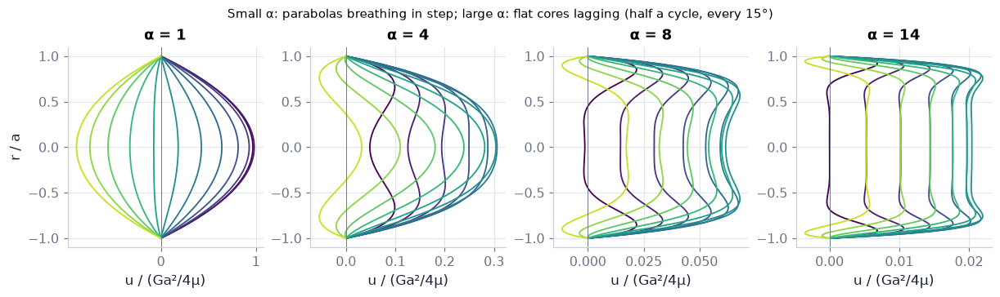

In [77]:
s_ = np.linspace(-1, 1, 201)                                  # across the whole diameter r/a (trap T20: the book's figure runs wall–centre)
fig, axs = plt.subplots(1, 4, figsize=(11, 3.2), sharey=False)   # a new figure and its axes
for ax, al in zip(axs, (1.0, 4.0, 8.0, 14.0)):                 # our four Womersley numbers
    for k, wt in enumerate(np.radians(np.arange(0, 180, 15))):  # every 15° of phase over half a cycle
        ax.plot(ch16.womersley_velocity_nd(np.abs(s_), wt, al), s_, color=plt.cm.viridis(k/12), lw=1.2)   # one profile; colour runs dark → light with phase
    ax.axvline(0, color=COLORS["muted"], lw=0.6)   # a reference line
    ax.set(title=f"α = {al:g}", xlabel="u / (Ga²/4μ)"); axs[0].set_ylabel("r / a")   # axis labels, limits and title
fig.suptitle("Small α: parabolas breathing in step; large α: flat cores lagging (half a cycle, every 15°)", fontsize=10)   # axis label or title
savefig(fig, "ch16", "c09_profiles"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** **N59 [B]** Velocity profiles across the full diameter at four Womersley numbers (our own values), drawn every 15° of
phase over half a cycle (colour from dark to light), in units of Poiseuille's centre speed for the same gradient
amplitude.

**How to read it.** At α = 1 the profiles are parabolas that grow and shrink in step with the gradient. At α = 8 and 14 the core is
flat, its speed is much smaller (the scale shrinks like 1/α²), and near the wall the profile reverses before the core does
— the wall layer turns first. Our figure shows the whole diameter; the book's runs wall–centre–wall mirrored (trap T20).

**What would change if…** …the heart rate doubled? Every α grows by √2: α = 4 would look like α = 5.7 — flatter and later.

📝 **Note.** **N60 [C]** Read twice in the book: reversal near the wall, a flat core, an almost solid core at the largest α.

In [78]:
nfr = 24 if FAST else 36                                      # frames for one cycle
wts = np.linspace(0, 2*np.pi, nfr, endpoint=False)            # phases of the gradient
fig, axs = plt.subplots(1, 3, figsize=(8, 3.0))   # a new figure and its axes
lines = []   # collect the artists / results
for ax, al in zip(axs, (1.0, 4.0, 12.0)):                      # three Womersley numbers side by side
    umax = 1.05*max(np.max(np.abs(ch16.womersley_velocity_nd(np.abs(s_), w, al))) for w in wts[::6])   # fixed axis per panel
    (ln,) = ax.plot([], [], color=COLORS["blue"], lw=2); lines.append((ln, al))   # an empty line, filled in frame by frame by update()
    ax.set(xlim=(-umax, umax), ylim=(-1, 1), title=f"α = {al:g}", xlabel="u/(Ga²/4μ)"); ax.axvline(0, color=COLORS["muted"], lw=0.6)   # a reference line
axs[0].set_ylabel("r / a")   # axis label or title
clock = fig.suptitle("", fontsize=10)                          # the gradient's phase, written out
def update(i):                                                # frame i
    for ln, al in lines:                                      # each panel's line and its Womersley number
        ln.set_data(ch16.womersley_velocity_nd(np.abs(s_), wts[i], al), s_)   # move the artist to this frame
    clock.set_text(f"gradient −∂p/∂x = G cos ωt at ωt = {np.degrees(wts[i]):.0f}° (largest at 0°)")   # move the artist to this frame
    return (*[l for l, _ in lines], clock)   # what this function hands back
fig.canvas.draw(); fig.set_layout_engine("none")              # lay the figure out once, then freeze it (faster frames)
show_animation(animate(update, frames=nfr, fig=fig, interval=60), player="video")   # render the frames and embed the player

**Figure A3.** **What you see.** One full cycle of the profile at α = 1, 4 and 12 (each panel with its own fixed axis),
with the gradient's phase written above. **How to read it.** At α = 1 the parabola peaks at ωt = 0° (in
phase); at α = 12 the flat core peaks almost a quarter cycle later and the wall layer reverses first. **What would change
if…** α were 30: the core would lag by nearly 90° and the wall layer would be a thin skin.

#### 🎮 Interactive: Is pulsing flow just Poiseuille flow sloshing?

**Why interactive rather than a static figure:** dragging α morphs the profile from a breathing parabola to a lagging plug while the phase runs; the two limits snap on
as ghosts and the vessel axis shows where each vessel sits — the morph between the limits is what a set of still curves
hides.

Start with the **Walkthrough**; the **Explain** tab works every number out with your settings, and the **Derivation** tab (where there is one) steps through the same derivation as above. Time convention e^{+iωt} (the rigid tube); profiles are in units of Poiseuille's centre speed Ga²/4μ for the same gradient amplitude.

**What to try:**
- Drag α from 0.5 to 17 and watch the profile flatten.
- Watch the purple near-wall trace turn before the centre.
- Click a radius to see the Bessel arithmetic.

In [79]:
show_viz("ch16", "womersley_profiles")   # full-width explainer; ⤢ Full screen for more room

[explainer ch16/womersley_profiles]

**What would change if…** …we asked for the total flow instead of the profile? Integrate $u(r,t)=\dfrac{Ga^2}{i\mu\alpha^2}\left(1-\dfrac{J_0(i^{3/2}\alpha r/a)}{J_0(i^{3/2}\alpha)}\right)e^{i\omega t}$ (16.82) over the section: C10.

### 🧩 How much flow, how late: $|Q|=\dfrac{\pi Ga^4}{\mu\alpha^2}\sqrt{X^2+Y^2}$ (16.99), $\tan\phi=\dfrac XY$ (16.100) `C10`

*The question:* Does the flow follow the pressure gradient?

#### The problem in plain words

Push a child on a swing gently and often: the swing moves with your hand. Push a heavy cart back and forth quickly: it
barely moves, and its motion trails your push by a quarter cycle — your force goes into accelerating it. **Blood in a large
artery is the cart.**

#### The idea

```
flow rate = pressure-gradient amplitude × (one complex number that depends only on α)
   its size   ──► how much flows
   its angle  ──► how late the flow peaks
α small:  Poiseuille's flux, in step with the gradient      (friction wins: the swing)
α large:  8/α² × Poiseuille's flux, a quarter cycle late    (inertia wins: the cart)
```

**Add the oscillating profile over the cross-section and you get one complex number**: its size gives the amplitude
$|Q|=\dfrac{\pi Ga^4}{\mu\alpha^2}\sqrt{X^2+Y^2}$ (16.99) and its angle the lag $\tan\phi=\dfrac XY$ (16.100). With the module: the lag is 2° at α = 0.5, 79° at α = 8 and 86° at α = 20.

> 🔁 **Tools from earlier chapters used in this block** (one line each; the full primers are in the chapters named)

- **the complex plane in numpy; `np.abs`, `np.angle`** — `np.abs(z)` is the modulus and `np.angle(z)` the argument of a complex number; here they read amplitude and phase off Womersley's complex flow. *(Ch. 6, P153)*
- **`np.arctan2`** — `np.arctan2(y, x)` returns the angle of the point (x, y) in the correct quadrant; here it gives the phase lag from X and Y. *(Ch. 2, P70)*
- **phase of a wave; lag in time** — a cosine shifted by φ, cos(ωt − φ), peaks φ/ω seconds later; here the flow peaks after the pressure gradient. *(Ch. 7, P165)*

> 📎 **Primer — two Bessel identities.** `P376` · $\dfrac{d}{dz}J_0(z)=-J_1(z)$ and $\displaystyle\int_0^zsJ_0(s)\,ds=zJ_1(z)$. The first
gives the wall shear, the second the flow rate. Both hold for complex z.

In [80]:
from scipy.integrate import quad               # numerical integral
z = 2.0; h = 1e-6
print((jv(0, z + h) - jv(0, z - h))/(2*h), -jv(1, z))      # −0.5767 twice
print(quad(lambda s: s*jv(0, s), 0, z)[0], z*jv(1, z))     # 1.1534 twice

-0.5767248077437337 -0.5767248077568736
1.1534496155137468 1.1534496155137473


#### 🧮 Derivation — The flow rate and F₂ `D16` ★★ (Eq. 16.90: $Q(t)=\dfrac{\pi a^4}{i\mu\alpha^2}G(1-F_2(\alpha))e^{i\omega t}$)

**What we want to show.** Add up Womersley's profile over the cross-section to get the oscillating flow rate.

**Assumptions.** As D13.

**The plan.**

1. Rings again.
2. The constant part.
3. The Bessel part by a substitution and an identity.
4. Collect.

**Tools we use** (each explained before this point): substitution in an integral (P106, reminder) · the Bessel identities (P376, primer in C10)

**We start from**

$$ u(r,t)=\dfrac{Ga^2}{i\mu\alpha^2}(1-F_1(\alpha))e^{i\omega t}\ \text{(16.82).} $$

---

**Step 1 of 7 — Integrate over rings.**

$$ Q=\dfrac{2\pi Ga^2}{i\mu\alpha^2}e^{i\omega t}\displaystyle\int_0^a(1-F_1)\,r\,dr $$

- *Why we can do this:* $Q=\int_0^au\,2\pi r\,dr$ (D04 step 1); everything not depending on r comes out of the integral.
- *In words:* Flow = profile summed over rings.

---

**Step 2 of 7 — Integrate the constant.**

$$ \displaystyle\int_0^ar\,dr=\dfrac{a^2}2 $$

- *Why we can do this:* Elementary. The power rule gives ∫₀ᵃ r dr = a²/2; it is the contribution of the constant 1 in 1 − F₁.
- *In words:* The plug part covers the whole area.

---

**Step 3 of 7 — Substitute $s=\lambda r$ in the Bessel term.**

$$ \displaystyle\int_0^aJ_0(\lambda r)\,r\,dr=\dfrac1{\lambda^2}\int_0^{\lambda a}sJ_0(s)\,ds,\quad\lambda=\dfrac{i^{3/2}\alpha}a $$

- *Why we can do this:* r = s/λ, dr = ds/λ (P106); the limits become 0 and λa = $i^{3/2}$α.
- *In words:* A standard Bessel integral appears.

---

**Step 4 of 7 — Use the Bessel integral identity.**

$$ \displaystyle\int_0^{z}sJ_0(s)\,ds=zJ_1(z) $$

- *Why we can do this:* P376: $\dfrac{d}{dz}[zJ_1(z)]=zJ_0(z)$, so zJ₁ is the antiderivative, and it vanishes at 0.
- *In words:* The area under sJ₀ is zJ₁.

---

**Step 5 of 7 — Collect the Bessel term.**

$$ \displaystyle\int_0^aF_1\,r\,dr=\dfrac{a^2}2\cdot\dfrac{2J_1(i^{3/2}\alpha)}{i^{3/2}\alpha J_0(i^{3/2}\alpha)}=\dfrac{a^2}2F_2(\alpha)\ \text{(16.91)} $$

- *Why we can do this:* Divide steps 3–4 by J₀($i^{3/2}$α): $\dfrac{\lambda aJ_1}{\lambda^2J_0}=\dfrac{a^2J_1}{i^{3/2}\alpha J_0}$; factor a²/2.
- *In words:* F₂ is the area-average of the Bessel ratio F₁.

---

**Step 6 of 7 — Put the pieces together.**

$$ Q=\dfrac{2\pi Ga^2}{i\mu\alpha^2}e^{i\omega t}\cdot\dfrac{a^2}2\left(1-F_2(\alpha)\right) $$

- *Why we can do this:* Steps 2 and 5 in step 1.
- *In words:* The flux is the plug flux reduced by the averaged wall effect.

---

**Step 7 of 7 — Simplify.**

$$ Q(t)=\dfrac{\pi a^4}{i\mu\alpha^2}G(1-F_2(\alpha))e^{i\omega t}\ \text{(16.90)} $$

- *Why we can do this:* $2\pi\cdot a^2/2=\pi a^2$. Multiplying the constants together is ordinary algebra; it gives the compact form of the book.
- *In words:* Womersley's oscillating flow rate.

---

**Result**

$$ \begin{array}{l}Q(t)=\dfrac{\pi a^4}{i\mu\alpha^2}G(1-F_2(\alpha))e^{i\omega t}\qquad\text{(16.90)} \\[6pt] F_2(\alpha)=\dfrac{2J_1(i^{3/2}\alpha)}{i^{3/2}\alpha J_0(i^{3/2}\alpha)}\qquad\text{(16.91)}\end{array} $$

*In words:* Womersley's oscillating flow rate, with F₂ the area average of the Bessel ratio.

**What it means.** At large α the same gradient buys far less flow, because most of the push goes into accelerating the blood back and forth. Fails as D13.

**Check it.** α → 0: $F_2\approx1-\dfrac{i\alpha^2}8$ (16.93), so $Q\to\dfrac{\pi Ga^4}{8\mu}e^{i\omega t}$ — Poiseuille's $|Q_0|=\dfrac{\pi Ga^4}{8\mu}$ (16.95) ✓; the from-scratch trapezoid of 2πru equals `ch16.womersley_flow_rate` to 10⁻⁸; **expect** |Q|/|Q₀| = 0.548 at α = 3 and 0.105 at α = 8.

📝 **Notes taught inside `D16`:** **N61 [B]** the flux $Q(t)=\dfrac{\pi a^4}{i\mu\alpha^2}G(1-F_2(\alpha))e^{i\omega t}$ (16.90) with $F_2(\alpha)=\dfrac{2J_1(i^{3/2}\alpha)}{i^{3/2}\alpha J_0(i^{3/2}\alpha)}$ (16.91).

> ⚠️ **Common confusion (traps in `D16`):** The constant term integrates to the full area πa²; collect the $i^{3/2}$ factors carefully.

#### 🧮 Derivation — Amplitude and phase lag `D17` ★★ (Eq. 16.100: $\tan\phi=\dfrac XY$)

**What we want to show.** Read off how big the oscillating flow is and how late it comes after the pressure gradient.

**Assumptions.** The physical gradient is the real part, $-\partial p/\partial x=G\cos\omega t$.

**The plan.**

1. Name 1 − F₂.
2. Multiply out with Euler's formula.
3. Write the real part as one shifted cosine.

**Tools we use** (each explained before this point): Euler's formula (P45, reminder) · the complex plane (P153, reminder) · amplitude–phase form (written out in step 5) · `np.arctan2` (P70, reminder)

**We start from**

$$ Q(t)=\dfrac{\pi a^4}{i\mu\alpha^2}G(1-F_2(\alpha))e^{i\omega t}\ \text{(16.90).} $$

---

**Step 1 of 7 — Name the complex factor.**

$$ 1-F_2(\alpha)=Z(\alpha)=X(\alpha)+iY(\alpha)\ \text{(16.97)} $$

- *Why we can do this:* A shorthand; X and Y are real numbers that depend only on α.
- *In words:* One complex number per α.

---

**Step 2 of 7 — Replace 1/i by −i.**

$$ Q=\dfrac{\pi Ga^4}{\mu\alpha^2}(-i)(X+iY)e^{i\omega t} $$

- *Why we can do this:* $1/i=-i$ (multiply top and bottom by i).
- *In words:* A quarter-turn of the complex factor.

---

**Step 3 of 7 — Multiply out with Euler's formula.**

$$ Q=\dfrac{\pi Ga^4}{\mu\alpha^2}(Y-iX)(\cos\omega t+i\sin\omega t) $$

- *Why we can do this:* $-i(X+iY)=Y-iX$; $e^{i\omega t}=\cos\omega t+i\sin\omega t$ (P45).
- *In words:* Two complex numbers to multiply.

---

**Step 4 of 7 — Separate real and imaginary parts.**

$$ Q=\dfrac{\pi Ga^4}{\mu\alpha^2}\left\{[Y\cos\omega t+X\sin\omega t]-i[X\cos\omega t-Y\sin\omega t]\right\}\ \text{(16.98)} $$

- *Why we can do this:* $(Y-iX)(\cos+i\sin)=Y\cos+X\sin+i(Y\sin-X\cos)$. Multiplying out two complex numbers and grouping terms is exact; the real part is the physical flow.
- *In words:* The real part is the flow that answers $G\cos\omega t$.

---

**Step 5 of 7 — Write the real part as one shifted cosine.**

$$ Y\cos\omega t+X\sin\omega t=\sqrt{X^2+Y^2}\cos(\omega t-\phi) $$

- *Why we can do this:* $R\cos(\omega t-\phi)=R\cos\phi\cos\omega t+R\sin\phi\sin\omega t$; match $R\cos\phi=Y$, $R\sin\phi=X$.
- *In words:* A sine and a cosine of the same frequency add to one cosine, shifted.

---

**Step 6 of 7 — Read off the amplitude.**

$$ |Q|=\dfrac{\pi Ga^4}{\mu\alpha^2}\sqrt{X^2+Y^2}\ \text{(16.99)} $$

- *Why we can do this:* The prefactor times R of step 5.
- *In words:* How much flow one unit of gradient buys.

---

**Step 7 of 7 — Read off the lag.**

$$ \tan\phi=\dfrac XY\ \text{(16.100),}\ \ \phi=\operatorname{arctan2}(X,Y) $$

- *Why we can do this:* From $R\sin\phi=X$, $R\cos\phi=Y$; arctan2 picks the right quadrant (P70). φ is how far the flow's peak trails the gradient's peak.
- *In words:* The flow arrives φ/ω seconds late.

---

**Result**

$$ \begin{array}{l}|Q|=\dfrac{\pi Ga^4}{\mu\alpha^2}\sqrt{X^2+Y^2}\qquad\text{(16.99)} \\[6pt] \tan\phi=\dfrac XY\qquad\text{(16.100)}\end{array}\qquad\dfrac{|Q|}{|Q_0|}=\dfrac{8\sqrt{X^2+Y^2}}{\alpha^2}\ \text{(ours)} $$

*In words:* How much flow and how late, as functions of α only.

**What it means.** Small α: a driven damper — viscosity limits the flow, in phase with the push. Large α: a driven mass — inertia limits it, a quarter cycle late, amplitude ∝ 1/α². Fails as D13.

**Check it.** α → 0: Z ≈ iα²/8, so X → 0, φ → 0 and |Q|/|Q₀| → 1 ✓; α → ∞: Z → 1, φ → 90°, |Q|/|Q₀| ≈ 8/α² ✓; **expect** at α = 8: X = 0.8228, Y = 0.1608, |Q|/|Q₀| = 0.1048, φ = 78.9° — at 66 beats/min the flow peaks **199 ms** after the gradient.

> ⚠️ **Common confusion (traps in `D17`):** Tan φ = X/Y, not Y/X; φ is the lag of Q behind $-\partial p/\partial x$, not behind p.

#### ✏️ Tiny example: α = 8

1. F₂(8) = 0.1772 − 0.1608i (`womersley_F2`).
2. Z = 1 − F₂ = 0.8228 + 0.1608i: X = 0.8228, Y = 0.1608.
3. √(X² + Y²) = 0.8384.
4. |Q|/|Q₀| = 8 × 0.8384/64 = **0.105** — a tenth of the steady flow for the same gradient amplitude.
5. φ = arctan2(0.8228, 0.1608) = **78.9°**; at 66 beats per minute (ω = 6.91 rad/s) the flow peaks 1.378/6.91 = **0.199 s**
   after the gradient.

(The book's own worked example does not quite match $F_2(\alpha)=\dfrac{2J_1(i^{3/2}\alpha)}{i^{3/2}\alpha J_0(i^{3/2}\alpha)}$ (16.91) — slip S11; the comparison stays private; ours is computed.)

In [81]:
F2 = ch16.womersley_F2(8.0)                                  # (16.91) at α = 8
X8, Y8 = ch16.womersley_XY(8.0)                              # (16.97): 1 − F2 = X + iY
ratio8 = ch16.womersley_flow_ratio(8.0)                      # |Q|/|Q0| = 8√(X²+Y²)/α² (ours, from (16.99) and (16.95))
phi8 = ch16.womersley_phase_lag(8.0)                         # (16.100): lag of Q behind −∂p/∂x [rad]
print(f"F2 = {F2:.4f}, X = {X8:.4f}, Y = {Y8:.4f}, |Q|/|Q0| = {ratio8:.4f}, phi = {np.degrees(phi8):.2f}°, delay = {phi8/omega:.3f} s")   # print the result
tq_ = np.linspace(0, 2*np.pi/omega, 5)                       # five instants of one beat [s]
print("Q(t) [mL/s] in our artery, G = 100 Pa/m:", np.round(ch16.womersley_flow_rate(tq_, artery["a"], omega, blood["rho"], blood["mu"], 100.0)*1e6, 4))   # print the result

F2 = 0.1772-0.1608j, X = 0.8228, Y = 0.1608, |Q|/|Q0| = 0.1048, phi = 78.94°, delay = 0.199 s
Q(t) [mL/s] in our artery, G = 100 Pa/m: [ 0.0628  0.082  -0.0628 -0.082   0.0628]


In [82]:
rr = np.linspace(0, artery["a"], 2001)                        # radii [m]
for t0 in (0.0, 0.1, 0.37):                                   # three instants [s]
    u_ = ch16.womersley_velocity(rr, t0, artery["a"], omega, blood["rho"], blood["mu"], 100.0)   # the profile (16.82)
    Q_mine = np.trapezoid(2*np.pi*rr*u_, rr)                  # add the rings
    assert np.isclose(Q_mine, ch16.womersley_flow_rate(t0, artery["a"], omega, blood["rho"], blood["mu"], 100.0), rtol=1e-6)   # = (16.90)
print("ring sums equal the flux (16.90)")   # print the result

ring sums equal the flux (16.90)


**What does the code above do?**

At three instants the trapezoid sum of $2\pi r u$ over the profile equals the closed-form flux $Q(t)=\dfrac{\pi a^4}{i\mu\alpha^2}G(1-F_2(\alpha))e^{i\omega t}$ (16.90) (to the
trapezoid rule's error).

📝 **Note.** **N62 [B]** Wall shear: $\tau_w=-\mu\dfrac{\partial u}{\partial r}\Big\rvert_a=\dfrac{G_0a}2+\dfrac a2\sum_1^NG_nF_2(\alpha_n)e^{in\omega t}$ (16.92, corrected) (result given, from $dJ_0/dz=-J_1$).

> ⚠️ **slip S8 — the book prints** this as a shear *rate* $\partial u/\partial r$ with an unnamed F; **the correct form is** $\tau_w=-\mu\dfrac{\partial u}{\partial r}\Big\rvert_a=\dfrac{G_0a}2+\dfrac a2\sum_1^NG_nF_2(\alpha_n)e^{in\omega t}$ (16.92, corrected) — the wall shear *stress* $-\mu\,\partial u/\partial r$ with $F_2$

In [83]:
a_, hh = artery["a"], 1e-7                                   # wall radius, small step [m]
for t0 in (0.0, 0.2):                                        # two instants [s]
    uu = ch16.womersley_velocity(np.array([a_, a_ - hh, a_ - 2*hh]), t0, a_, omega, blood["rho"], blood["mu"], 100.0)   # `ch16.womersley_velocity` (the chapter module)
    tau_fd = -blood["mu"]*(3*uu[0] - 4*uu[1] + uu[2])/(2*hh)  # −μ ∂u/∂r at the wall, one-sided second-order difference
    tau_lib = ch16.womersley_wall_shear(t0, a_, omega, blood["rho"], blood["mu"], [0, 100.0])   # (16.92, corrected)
    print(f"t = {t0}: FD {tau_fd:.6f} Pa, (16.92) {tau_lib:.6f} Pa")   # print the result

t = 0.0: FD 0.052172 Pa, (16.92) 0.052172 Pa
t = 0.2: FD 0.045732 Pa, (16.92) 0.045732 Pa


**What does this show?** The finite-difference wall stress of the profile equals the corrected $\tau_w=-\mu\dfrac{\partial u}{\partial r}\Big\rvert_a=\dfrac{G_0a}2+\dfrac a2\sum_1^NG_nF_2(\alpha_n)e^{in\omega t}$ (16.92, corrected) — a stress
in Pa, not a shear rate. The wall shear leads the flow (it responds to the thin wall layer, which turns first).

📝 **Note.** **N63 [B]** Small α: $F_2(\alpha)\approx1-\dfrac{i\alpha^2}8$ (16.93), so the flow tends to $Q=\dfrac{\pi Ga^4}{8\mu}e^{i\omega t}$ (16.94, single-mode exponent) with magnitude $|Q_0|=\dfrac{\pi Ga^4}{8\mu}$ (16.95) — Poiseuille's flux for the gradient
amplitude G. (The book writes the exponent as $e^{in\omega t}$, $Q=\dfrac{\pi Ga^4}{8\mu}e^{in\omega t}$ (16.94, as printed), for this single mode — slip S9.)

In [84]:
als = np.array([0.25, 0.5, 1.0])                             # small Womersley numbers
err = np.abs(ch16.womersley_F2(als) - ch16.womersley_F2_series(als))   # error of 1 − iα²/8
print("errors:", err, "| slopes:", np.round(np.diff(np.log(err))/np.diff(np.log(als)), 2))   # ≈ 4: the next term is α⁴

errors: [0.0001 0.0013 0.0205] | slopes: [4.   3.98]


📝 **Note.** **N64 [B]** Large α: $F_2(\alpha)\approx\dfrac{2}{i^{1/2}\alpha}\left(1+\dfrac{i^{3/2}}{2\alpha}\right)$ (16.96, corrected).

> ⚠️ **slip S10 — the book prints** $F_2(\alpha)\approx\dfrac{2}{i^{1/2}\alpha}\left(1+\dfrac1{2\alpha}\right)$ (16.96, as printed); **the correct form is** $F_2(\alpha)\approx\dfrac{2}{i^{1/2}\alpha}\left(1+\dfrac{i^{3/2}}{2\alpha}\right)$ (16.96, corrected)
>
> The printed real correction is worse than no correction at all (table below).

In [85]:
rows = []                                                    # one row of errors per α
for al in (10.0, 30.0, 100.0):                               # large Womersley numbers
    ex = ch16.womersley_F2(al)                                # exact (16.91)
    lead = 2/(1j**0.5*al)                                     # the leading term only
    rows.append(dict(alpha=al, leading=abs(lead - ex)/abs(ex), corrected=abs(ch16.womersley_F2_asymptote(al) - ex)/abs(ex),   # (continued)
                     printed=abs(ch16.womersley_F2_asymptote(al, printed_16_96=True) - ex)/abs(ex)))   # (continued from the line above)
display(pd.DataFrame(rows).style.format({"leading": "{:.1e}", "corrected": "{:.1e}", "printed": "{:.1e}"}))   # relative errors

,alpha,leading,corrected,printed
0,10.000000,5.3e-02,1.4e-03,9.6e-02
1,30.000000,1.7e-02,1.4e-04,3.1e-02
2,100.000000,5.0e-03,1.3e-05,9.3e-03


**What does this show?** Relative error of three approximations of F₂: the leading term (∝ 1/α), the corrected
$F_2(\alpha)\approx\dfrac{2}{i^{1/2}\alpha}\left(1+\dfrac{i^{3/2}}{2\alpha}\right)$ (16.96, corrected) (∝ 1/α², much better) and the printed form (larger than the leading term's: its "correction" points the wrong way).

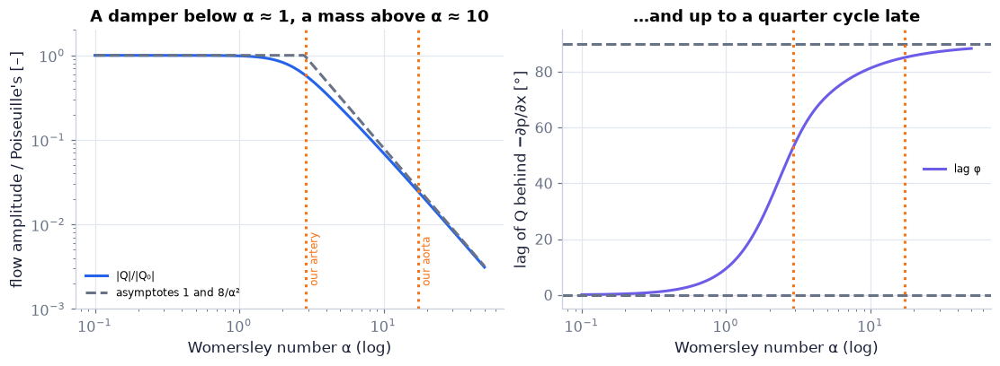

In [86]:
al_ = np.logspace(-1, np.log10(50), 300)                      # Womersley numbers 0.1 … 50
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.6))   # a new figure and its axes
ax.loglog(al_, ch16.womersley_flow_ratio(al_), color=COLORS["blue"], lw=2, label="|Q|/|Q₀|")   # curve: |Q|/|Q₀|
ax.loglog(al_, np.minimum(1, 8/al_**2), "--", color=COLORS["muted"], label="asymptotes 1 and 8/α²")   # curve: asymptotes 1 and 8/α²
bx.semilogx(al_, np.degrees(ch16.womersley_phase_lag(al_)), color=COLORS["accent"], lw=2, label="lag φ")   # curve: lag φ
bx.axhline(90, ls="--", color=COLORS["muted"]); bx.axhline(0, ls="--", color=COLORS["muted"])   # a reference line
for name, al0 in (("our artery", alpha_art), ("our aorta", ch16.womersley_number(aorta["a0"], omega, nu))):   # mark our two vessels
    ax.axvline(al0, color=COLORS["orange"], ls=":"); bx.axvline(al0, color=COLORS["orange"], ls=":")   # a reference line
    ax.text(al0*1.05, 2e-3, name, rotation=90, fontsize=8, color=COLORS["orange"])   # a text label on the plot
ax.set(xlabel="Womersley number α (log)", ylabel="flow amplitude / Poiseuille's [–]", ylim=(1e-3, 2), title="A damper below α ≈ 1, a mass above α ≈ 10")   # axis labels, limits and title
bx.set(xlabel="Womersley number α (log)", ylabel="lag of Q behind −∂p/∂x [°]", ylim=(-5, 95), title="…and up to a quarter cycle late")   # axis labels, limits and title
ax.legend(fontsize=8); bx.legend(fontsize=8)   # the legend
savefig(fig, "ch16", "c10_bode"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** Left: the flow amplitude relative to Poiseuille's for the same gradient amplitude, against α (log–log), with the
asymptotes 1 and 8/α². Right: the phase lag of the flow behind the gradient, from 0° to 90°. Dotted: our artery and our
aorta.

**How to read it.** Below α ≈ 1 the flow is Poiseuille's and in step (a driven damper: viscosity limits it). Above α ≈ 10 the flow
falls as 8/α² and lags by almost 90° (a driven mass: inertia limits it). Our 2-mm artery sits in the transition; the aorta
is well inside the inertial regime.

**What would change if…** …the vessel were twice as wide? α doubles: in the inertial regime the flow amplitude relative to Poiseuille's
falls four times — though Poiseuille's own flux grows sixteen times.

#### 🎮 Interactive: Does the flow follow the pressure?

**Why interactive rather than a static figure:** dragging α moves a cursor on the amplitude and lag curves while the time traces slide apart and the complex number Z
turns — the link between the curve, the traces and the complex plane is the point.

Start with the **Walkthrough**; the **Explain** tab works every number out with your settings, and the **Derivation** tab (where there is one) steps through the same derivation as above. |Q|/|Q₀| is the flow amplitude over Poiseuille's at the same gradient amplitude; φ is the lag of Q behind −∂p/∂x = G cos ωt.

**What to try:**
- Set α = 1: flow and gradient peak together.
- Set α = 20: the flow is 2 % of Poiseuille's and 86° late.
- Switch the asymptote to the printed $F_2(\alpha)\approx\dfrac{2}{i^{1/2}\alpha}\left(1+\dfrac1{2\alpha}\right)$ (16.96, as printed) at α = 10 and compare the errors.

In [87]:
show_viz("ch16", "womersley_flow_phase")   # full-width explainer; ⤢ Full screen for more room

[explainer ch16/womersley_flow_phase]

**What would change if…** …the tube were elastic as well? Then the pressure travels (C08) and the viscous profile of C09 rides on it: C11.

### 🧩 Where waves meet viscosity: the characteristic quadratic $X^2\left[2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}-4\right]+X\left[4\hat\nu-1-2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}\right]+(1-\hat\nu^2)=0$ (16.136) `C11`

*The question:* How much do viscosity and the vessel wall slow the pulse and make it fade?

#### The problem in plain words

C08 gave the pulse a speed from the wall's stiffness, ignoring viscosity. C09 gave the oscillating profile, ignoring the
wall's give. A real artery has both: **the pulse drags a viscous layer along the wall, which slows it and makes it fade
with distance**. How much depends — once more — on α.

#### The idea

```
wall stiffness  ──► sets the speed c₀ (C08)
viscous layer   ──► a complex wavenumber k = k₁ + i k₂: slower (c = ω/k₁ < c₀) and fading (e^{−k₂x})
α large: thin layer         ──► c ≈ c₀, little fading per wavelength     (α = 20: c/c₀ = 0.98)
α small: layer fills tube   ──► much slower, strongly damped              (α = 1:  c/c₀ = 0.53)
```

**The wall sets the speed, the viscous layer trims it and damps it.** Both come out of one quadratic for the
unknown $X$ (which carries $k^2$), $X^2\left[2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}-4\right]+X\left[4\hat\nu-1-2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}\right]+(1-\hat\nu^2)=0$ (16.136); α decides how thick the layer is, so α decides the trim (numbers from
`ch16.elastic_tube_wave`).

> ⚠️ **Common confusion:** (trap T1, repeated) This block uses $(u,v,p,\xi,\eta)=(\hat u(r),\hat v(r),\hat p,\hat\xi,\hat\eta)\,e^{i(kx-\omega t)}$ (16.116), the opposite sign to C09's $u(r,t)=U(r)e^{i\omega t}$ (16.75): here $\partial/\partial t\to
-i\omega$, so +iωρ/μ appears where C09 had −iωρ/μ. The two-row table of C09 again: rigid tube $e^{+i\omega t}$ with
$i^{3/2}\alpha$; elastic tube $e^{i(kx-\omega t)}$ with $\hat\beta=e^{i\pi/4}\alpha$.

> 🔁 **Recap — Continuity and Navier–Stokes in (r, x) `R12`** (Ch. 4 §4.5; Appendix B). $\dfrac{\partial u}{\partial x}+\dfrac1r\dfrac{\partial(rv)}{\partial r}=0$ (16.101) and $\rho\dfrac{\partial u}{\partial t}=-\dfrac{\partial p}{\partial x}+\mu\left(\dfrac{\partial^2u}{\partial r^2}+\dfrac1r\dfrac{\partial u}{\partial r}+\dfrac{\partial^2u}{\partial x^2}\right)$ (16.102), linearised. **New here:** the radial velocity v
is kept, because the wall moves.

📝 **Note.** **N65 [B]** The wall is a membrane with displacements η (radial) and ξ (axial); its tensions follow Hooke's law with
Poisson's ratio: $T_\theta=\dfrac{Eh}{1-\hat\nu^2}\left(\dfrac\eta{a_0}+\hat\nu\dfrac{\partial\xi}{\partial x}\right)$ (16.104); its radial motion $\rho_wh\dfrac{\partial^2\eta}{\partial t^2}=\sigma_{rr}\rvert_a-\dfrac{T_\theta}{a_0}$ (16.106) — the hoop tension's inward push T/a (P380) (stated).

📝 **Note.** **N66 [B]** With the fluid's stresses $\sigma_{rr}=+p-2\mu\dfrac{\partial v}{\partial r}$ (16.110) and $\sigma_{rx}=\mu\left(\dfrac{\partial u}{\partial r}+\dfrac{\partial v}{\partial x}\right)$ (16.111) put in, the wall equations become $\rho_wh\dfrac{\partial^2\eta}{\partial t^2}=+p\rvert_{r=a}-2\mu\dfrac{\partial v}{\partial r}\Big\rvert_{r=a}-\dfrac{Eh}{1-\hat\nu^2}\left(\dfrac\eta{a_0^2}+\dfrac{\hat\nu}{a_0}\dfrac{\partial\xi}{\partial x}\right)$ (16.112) and $\rho_wh\dfrac{\partial^2\xi}{\partial t^2}=-\mu\left(\dfrac{\partial u}{\partial r}+\dfrac{\partial v}{\partial x}\right)\Big\rvert_{r=a}+\dfrac{Eh}{1-\hat\nu^2}\left(\dfrac{\partial^2\xi}{\partial x^2}+\dfrac{\hat\nu}{a_0}\dfrac{\partial\eta}{\partial x}\right)$ (16.113); in
mode form they are D19's start, $-\rho_wh\omega^2\hat\eta=\hat p-2\mu\dfrac{d\hat v}{dr}\Big\rvert_{a_0}-\dfrac{Eh}{1-\hat\nu^2}\left(\dfrac{\hat\eta}{a_0^2}+\dfrac{i\hat\nu k}{a_0}\hat\xi\right)$ (16.126) and $-\rho_wh\omega^2\hat\xi=-\mu\left(\dfrac{d\hat u}{dr}+ik\hat v\right)\Big\rvert_{a_0}+\dfrac{Eh}{1-\hat\nu^2}\left(-k^2\hat\xi+\dfrac{i\hat\nu k}{a_0}\hat\eta\right)$ (16.127). The book's $\rho_wh\dfrac{\partial^2\eta}{\partial t^2}=\sigma_{rr}\rvert_a-\dfrac{Eh}{1-\hat\nu^2}\left(\dfrac{\eta}{a_0^2}+\dfrac{\hat\nu}{a_0}\dfrac{\partial\xi}{\partial x}\right)$ (16.108) prints 1 − ν̂ for 1 − ν̂² (slip S12). This chapter counts a
normal stress positive in compression here. **N67 [B]** No slip at the moving wall, applied at the undisturbed radius:
$u\rvert_{a_0}=\dfrac{\partial\xi}{\partial t}$ (16.114), $v\rvert_{a_0}=\dfrac{\partial\eta}{\partial t}$ (16.115) — Ch. 7's linearised boundary condition.

> 📎 **Primer — a complex wavenumber.** `P385` · With $k=k_1+ik_2$, the wave $e^{i(kx-\omega t)}=e^{-k_2x}e^{i(k_1x-\omega t)}$ travels at
$c=\omega/k_1$ and its amplitude falls by $e^{-2\pi k_2/k_1}$ over one wavelength — the spatial twin of the complex
frequency of Ch. 11 (growth in time).

In [88]:
k1, k2 = 1.0, 0.0622                           # per metre (α = 8 below)
print(np.exp(-2*np.pi*k2/k1))                  # 0.677: a third lost per wavelength

0.6765058891372191


#### 🧮 Derivation — The long-wave normal-mode reduction `D18` ★★ (Eq. 16.123: $\dfrac{d^2\hat u}{dr^2}+\dfrac1r\dfrac{d\hat u}{dr}+\dfrac{i\omega\rho}{\mu}\hat u=\dfrac{ik\hat p}{\mu}$)

**What we want to show.** Reduce the viscous flow in an elastic tube to ordinary differential equations in r for one travelling wave.

**Assumptions.** Long waves, $a_0|k|\ll1$ (steps 3–5); small disturbances (start).

**The plan.**

1. Normal modes with a complex wavenumber.
2. Size of v.
3. Drop what long waves make small.
4. Substitute the modes.

**Tools we use** (each explained before this point): complex amplitudes (P176) · a complex wavenumber (P385, primer in C11) · orders of smallness (P68)

**We start from**

$$ \begin{array}{l}\dfrac{\partial u}{\partial x}+\dfrac1r\dfrac{\partial(rv)}{\partial r}=0\qquad\text{(16.101)} \\[6pt] \rho\dfrac{\partial u}{\partial t}=-\dfrac{\partial p}{\partial x}+\mu\left(\dfrac{\partial^2u}{\partial r^2}+\dfrac1r\dfrac{\partial u}{\partial r}+\dfrac{\partial^2u}{\partial x^2}\right)\qquad\text{(16.102)} \\[6pt] \rho\dfrac{\partial v}{\partial t}=-\dfrac{\partial p}{\partial r}+\mu\left(\dfrac{\partial^2v}{\partial r^2}+\dfrac1r\dfrac{\partial v}{\partial r}-\dfrac{v}{r^2}+\dfrac{\partial^2v}{\partial x^2}\right)\qquad\text{(16.103)} \\[6pt] u\rvert_{a_0}=\dfrac{\partial\xi}{\partial t}\qquad\text{(16.114)} \\[6pt] v\rvert_{a_0}=\dfrac{\partial\eta}{\partial t}\qquad\text{(16.115)}\end{array} $$

*In words:* Linearised continuity and the two momentum equations in (r, x), and the no-slip conditions at the moving wall.

---

**Step 1 of 9 — Choose travelling-wave modes.**

$$ (u,v,p,\xi,\eta)=(\hat u(r),\hat v(r),\hat p,\hat\xi,\hat\eta)\,e^{i(kx-\omega t)}\ \text{(16.116)} $$

- *Why we can do this:* The equations are linear with coefficients that do not depend on x or t, so each Fourier mode evolves alone (P176). The book now uses $e^{i(kx-\omega t)}$, the opposite sign to C09 (trap T1).
- *In words:* One wave of frequency ω and wavenumber k.

---

**Step 2 of 9 — Let the wavenumber be complex.**

$$ k=k_1+ik_2:\quad e^{i(kx-\omega t)}=e^{-k_2x}e^{i(k_1x-\omega t)} $$

- *Why we can do this:* P385: an imaginary part of k makes the amplitude fall with distance; speed $c=\omega/k_1$, $|k|=\sqrt{k_1^2+k_2^2}$ (the book prints $\sqrt{k_1+k_2}$, S13).
- *In words:* A wave that travels at ω/k₁ and fades over 1/k₂.

---

**Step 3 of 9 — Size the radial velocity from continuity.**

$$ \left|\dfrac{v}{u}\right|=O(|ak|)\ \text{(16.117)} $$

- *Why we can do this:* In $\dfrac{\partial u}{\partial x}+\dfrac1r\dfrac{\partial(rv)}{\partial r}=0$ (16.101) $\partial u/\partial x\sim|k|u$ and $(1/r)\partial(rv)/\partial r\sim v/a$ must balance.
- *In words:* For long waves the blood moves mostly along the tube.

---

**Step 4 of 9 — Drop the axial diffusion.**

$$ \left|\dfrac{\partial^2u}{\partial x^2}\right|\Big/\left|\dfrac{\partial^2u}{\partial r^2}\right|=O(a^2|k|^2)\ll1 $$

- *Why we can do this:* ∂²/∂x² brings k², ∂²/∂r² brings at least 1/a²; long waves (P68).
- *In words:* Viscosity acts across the tube, not along it.

---

**Step 5 of 9 — Drop the radial pressure change.**

$$ \dfrac{\partial p}{\partial r}=0\ \text{(16.120)} $$

- *Why we can do this:* Every term of the radial momentum $\rho\dfrac{\partial v}{\partial t}=-\dfrac{\partial p}{\partial r}+\mu\left(\dfrac{\partial^2v}{\partial r^2}+\dfrac1r\dfrac{\partial v}{\partial r}-\dfrac{v}{r^2}+\dfrac{\partial^2v}{\partial x^2}\right)$ (16.103) carries v = O(ak)u, so the pressure change across the radius is O(a²k²) of the change along the tube.
- *In words:* The pressure is the same over each cross-section.

---

**Step 6 of 9 — Write the reduced axial momentum.**

$$ \rho\dfrac{\partial u}{\partial t}=-\dfrac{\partial p}{\partial x}+\mu\left(\dfrac{\partial^2u}{\partial r^2}+\dfrac1r\dfrac{\partial u}{\partial r}\right)\ \text{(16.119)} $$

- *Why we can do this:* $\rho\dfrac{\partial u}{\partial t}=-\dfrac{\partial p}{\partial x}+\mu\left(\dfrac{\partial^2u}{\partial r^2}+\dfrac1r\dfrac{\partial u}{\partial r}+\dfrac{\partial^2u}{\partial x^2}\right)$ (16.102) without the term of step 4.
- *In words:* The rigid-tube equation $\mu\left[\dfrac{\partial^2u}{\partial r^2}+\dfrac1r\dfrac{\partial u}{\partial r}\right]-\rho\dfrac{\partial u}{\partial t}=\dfrac{\partial p}{\partial x}$ (16.72) again — now with a pressure that travels.

---

**Step 7 of 9 — Put the modes into continuity.**

$$ \dfrac{d(r\hat v)}{dr}=-ikr\hat u\ \text{(16.122)} $$

- *Why we can do this:* $\partial/\partial x\to ik$ in $\dfrac{\partial u}{\partial x}+\dfrac1r\dfrac{\partial(rv)}{\partial r}=0$ (16.101); multiply by r.
- *In words:* Radial flow fills in for the change of axial flow.

---

**Step 8 of 9 — Put the modes into momentum.**

$$ \dfrac{d^2\hat u}{dr^2}+\dfrac1r\dfrac{d\hat u}{dr}+\dfrac{i\omega\rho}{\mu}\hat u=\dfrac{ik\hat p}{\mu}\ \text{(16.123)} $$

- *Why we can do this:* $\partial/\partial t\to-i\omega$, $\partial/\partial x\to ik$ in $\rho\dfrac{\partial u}{\partial t}=-\dfrac{\partial p}{\partial x}+\mu\left(\dfrac{\partial^2u}{\partial r^2}+\dfrac1r\dfrac{\partial u}{\partial r}\right)$ (16.119); divide by μ and move terms.
- *In words:* C09's Bessel-type equation, with +iωρ/μ because of the other time convention.

---

**Step 9 of 9 — Apply the wall conditions at the undisturbed wall.**

$$ \hat u(a_0)=-i\omega\hat\xi,\quad\hat v(a_0)=-i\omega\hat\eta\ \text{(16.124), (16.125)} $$

- *Why we can do this:* (16.114)–(16.115): the fluid moves with the wall; for small displacements the condition is applied at r = a₀ instead of a₀ + η (the linearised boundary condition of Ch. 7); $\partial/\partial t\to-i\omega$.
- *In words:* The blood at the wall moves exactly as the wall does.

---

**Result**

$$ \begin{array}{l}\dfrac{\partial p}{\partial r}=0\qquad\text{(16.120)} \\[6pt] \dfrac{d(r\hat v)}{dr}=-ikr\hat u\qquad\text{(16.122)} \\[6pt] \dfrac{d^2\hat u}{dr^2}+\dfrac1r\dfrac{d\hat u}{dr}+\dfrac{i\omega\rho}{\mu}\hat u=\dfrac{ik\hat p}{\mu}\qquad\text{(16.123)} \\[6pt] \hat u(a_0)=-i\omega\hat\xi\qquad\text{(16.124)} \\[6pt] \hat v(a_0)=-i\omega\hat\eta\qquad\text{(16.125)}\end{array} $$

*In words:* Ordinary differential equations in r for one travelling mode, with the pressure uniform over each section.

**What it means.** The long-wave idea keeps the cross-section physics of C09 and adds a pressure that varies along the tube. Fails for short waves (λ comparable with a).

**Check it.** With k real and the wall rigid ($\hat\xi=\hat\eta=0$) $\dfrac{d^2\hat u}{dr^2}+\dfrac1r\dfrac{d\hat u}{dr}+\dfrac{i\omega\rho}{\mu}\hat u=\dfrac{ik\hat p}{\mu}$ (16.123) is the complex conjugate of D13's equation (opposite time convention); every dropped term is $O(a^2k^2)$ or $O(ak)$.

📝 **Notes taught inside `D18`:** **N68 [B]** the travelling-wave modes $(u,v,p,\xi,\eta)=(\hat u(r),\hat v(r),\hat p,\hat\xi,\hat\eta)\,e^{i(kx-\omega t)}$ (16.116) with $|k|=\sqrt{k_1^2+k_2^2}$ (the
book prints $\sqrt{k_1+k_2}$ — slip S13); **N69 [B]** the long-wave ordering $\left|\dfrac{v}{u}\right|=O(|ak|)$ (16.117), $\dfrac{\partial p}{\partial r}=0$ (16.120).

> ⚠️ **Common confusion (traps in `D18`):** T1 (the sign of iω flips); S13 the modulus of k.

#### 🧮 Derivation — The reduced wall equations `D19` ★★★ (Eq. 16.128: $\hat p=\dfrac{Eh}{a_0^2}\hat\eta-\dfrac{i\hat\nu}{a_0k}\mu\dfrac{d\hat u}{dr}\Big\rvert_{a_0}$)

**What we want to show.** Do the "considerable algebra" the book skips: simplify the wall's two equations of motion and eliminate its axial displacement.

**Assumptions.** Thin wall h ≪ a₀, ρ_w ~ ρ, long waves a₀k ≪ 1, α ≫ 1 (steps 1–4).

**The plan.**

1. Size and drop wall inertia.
2. Drop two small fluid stresses.
3. Solve the axial equation for ξ̂.
4. Substitute into the radial one.

**Tools we use** (each explained before this point): Poisson's ratio (P379) · orders of smallness (P68) · linear elimination

**We start from**

$$ \begin{array}{l}-\rho_wh\omega^2\hat\eta=\hat p-2\mu\dfrac{d\hat v}{dr}\Big\rvert_{a_0}-\dfrac{Eh}{1-\hat\nu^2}\left(\dfrac{\hat\eta}{a_0^2}+\dfrac{i\hat\nu k}{a_0}\hat\xi\right)\ \text{(16.126) and} \\ -\rho_wh\omega^2\hat\xi=-\mu\left(\dfrac{d\hat u}{dr}+ik\hat v\right)\Big\rvert_{a_0}+\dfrac{Eh}{1-\hat\nu^2}\left(-k^2\hat\xi+\dfrac{i\hat\nu k}{a_0}\hat\eta\right)\ \text{(16.127).}\end{array} $$

---

**Step 1 of 10 — Compare wall inertia with wall stiffness.**

$$ \dfrac{\rho_wh\omega^2}{Eh/a_0^2}=\dfrac{\rho_w}{\rho}\dfrac{h}{a_0}\dfrac{(ka_0)^2}{2} $$

- *Why we can do this:* Ratio of the left side of $-\rho_wh\omega^2\hat\eta=\hat p-2\mu\dfrac{d\hat v}{dr}\Big\rvert_{a_0}-\dfrac{Eh}{1-\hat\nu^2}\left(\dfrac{\hat\eta}{a_0^2}+\dfrac{i\hat\nu k}{a_0}\hat\xi\right)$ (16.126) to its elastic term; with $E=2\rho a_0c^2/h$ from $c=\sqrt{\dfrac{Eh}{2\rho a_0}}$ (16.62) and ω = kc. Each factor is small.
- *In words:* A thin wall's own mass hardly matters.

---

**Step 2 of 10 — Drop wall inertia in both equations.**

$$ 0=\hat p-2\mu\dfrac{d\hat v}{dr}\Big\rvert_{a_0}-\dfrac{Eh}{1-\hat\nu^2}\left(\dfrac{\hat\eta}{a_0^2}+\dfrac{i\hat\nu k}{a_0}\hat\xi\right) $$

- *Why we can do this:* Step 1; the same estimate holds for $-\rho_wh\omega^2\hat\xi=-\mu\left(\dfrac{d\hat u}{dr}+ik\hat v\right)\Big\rvert_{a_0}+\dfrac{Eh}{1-\hat\nu^2}\left(-k^2\hat\xi+\dfrac{i\hat\nu k}{a_0}\hat\eta\right)$ (16.127).
- *In words:* The wall is in balance at every instant.

---

**Step 3 of 10 — Drop the viscous normal stress.**

$$ 2\mu\left|\dfrac{d\hat v}{dr}\right|\ll|\hat p| $$

- *Why we can do this:* $v=O(ak)u$ (16.117), so $2\mu\,dv/dr\sim2\mu|k|u$, while $p\sim\rho cu$; their ratio $2\nu|k|/c$ is small for α ≫ 1 and ak ≪ 1.
- *In words:* The wall feels the blood's pressure, not its viscous squeeze.

---

**Step 4 of 10 — Keep only the main shear.**

$$ \mu\left(\dfrac{d\hat u}{dr}+ik\hat v\right)\approx\mu\dfrac{d\hat u}{dr} $$

- *Why we can do this:* $|k\hat v|\sim a|k|^2|\hat u|$ while $|d\hat u/dr|\ge|\hat u|/a$: the ratio is O(a²k²). The text names μ∂v/∂x as the survivor (slip S14).
- *In words:* The wall is dragged by the change of u across the radius.

---

**Step 5 of 10 — Write the reduced axial equation.**

$$ 0=-\mu\dfrac{d\hat u}{dr}\Big\rvert_{a_0}+\dfrac{Eh}{1-\hat\nu^2}\left(-k^2\hat\xi+\dfrac{i\hat\nu k}{a_0}\hat\eta\right) $$

- *Why we can do this:* $-\rho_wh\omega^2\hat\xi=-\mu\left(\dfrac{d\hat u}{dr}+ik\hat v\right)\Big\rvert_{a_0}+\dfrac{Eh}{1-\hat\nu^2}\left(-k^2\hat\xi+\dfrac{i\hat\nu k}{a_0}\hat\eta\right)$ (16.127) with steps 2 and 4.
- *In words:* The blood's drag stretches the wall lengthwise.

---

**Step 6 of 10 — Solve it for the axial displacement.**

$$ \hat\xi=\dfrac{i\hat\nu}{ka_0}\hat\eta-\dfrac{1-\hat\nu^2}{Ehk^2}\mu\dfrac{d\hat u}{dr}\Big\rvert_{a_0}\ \text{(16.129)} $$

- *Why we can do this:* Move the shear term across and divide by $-k^2Eh/(1-\hat\nu^2)$; $(i\hat\nu k/a_0)/k^2=i\hat\nu/(ka_0)$.
- *In words:* The wall slides because the hoop stretch squeezes it lengthwise (Poisson) and because the blood drags it.

---

**Step 7 of 10 — Write the reduced radial equation for p̂.**

$$ \hat p=\dfrac{Eh}{1-\hat\nu^2}\left(\dfrac{\hat\eta}{a_0^2}+\dfrac{i\hat\nu k}{a_0}\hat\xi\right) $$

- *Why we can do this:* Step 2 with step 3, solved for p̂. The book's $\rho_wh\dfrac{\partial^2\eta}{\partial t^2}=\sigma_{rr}\rvert_a-\dfrac{Eh}{1-\hat\nu^2}\left(\dfrac{\eta}{a_0^2}+\dfrac{\hat\nu}{a_0}\dfrac{\partial\xi}{\partial x}\right)$ (16.108) prints 1 − ν̂ (slip S12).
- *In words:* The pressure is held by the hoop and the lengthwise strain.

---

**Step 8 of 10 — Multiply (16.129) by $i\hat\nu k/a_0$.**

$$ \dfrac{i\hat\nu k}{a_0}\hat\xi=-\dfrac{\hat\nu^2}{a_0^2}\hat\eta-\dfrac{i\hat\nu(1-\hat\nu^2)}{a_0Ehk}\mu\dfrac{d\hat u}{dr}\Big\rvert_{a_0} $$

- *Why we can do this:* $i\cdot i=-1$ in the first term; k/k² = 1/k in the second.
- *In words:* The piece of step 7 that contains ξ̂.

---

**Step 9 of 10 — Add $\hat\eta/a_0^2$.**

$$ \dfrac{\hat\eta}{a_0^2}+\dfrac{i\hat\nu k}{a_0}\hat\xi=\dfrac{(1-\hat\nu^2)\hat\eta}{a_0^2}-\dfrac{i\hat\nu(1-\hat\nu^2)}{a_0Ehk}\mu\dfrac{d\hat u}{dr}\Big\rvert_{a_0} $$

- *Why we can do this:* $1-\hat\nu^2$ now multiplies both terms. Adding η̂/a₀² to both sides of step 8 keeps it true; it builds the bracket of step 7 so that it can be replaced.
- *In words:* The bracket of step 7, worked out.

---

**Step 10 of 10 — Multiply by $Eh/(1-\hat\nu^2)$.**

$$ \hat p=\dfrac{Eh}{a_0^2}\hat\eta-\dfrac{i\hat\nu}{a_0k}\mu\dfrac{d\hat u}{dr}\Big\rvert_{a_0}\ \text{(16.128)} $$

- *Why we can do this:* Step 7 with step 9; the factor $1-\hat\nu^2$ cancels exactly.
- *In words:* Hoop stiffness holds the pressure; a small Poisson term couples it to the blood's shear.

---

**Result**

$$ \begin{array}{l}\hat p=\dfrac{Eh}{a_0^2}\hat\eta-\dfrac{i\hat\nu}{a_0k}\mu\dfrac{d\hat u}{dr}\Big\rvert_{a_0}\qquad\text{(16.128)} \\[6pt] \hat\xi=\dfrac{i\hat\nu}{ka_0}\hat\eta-\dfrac{1-\hat\nu^2}{Ehk^2}\mu\dfrac{d\hat u}{dr}\Big\rvert_{a_0}\qquad\text{(16.129)}\end{array} $$

*In words:* Hoop stiffness holds the pressure; the axial wall motion follows from Poisson coupling and the blood's drag.

**What it means.** The wall is a massless spring whose stretch holds the pressure; viscosity reaches it only through the shear at the wall. Fails for thick or heavy walls.

**Check it.** ν̂ = 0: $\hat p=Eh\hat\eta/a_0^2$, the linear tube law $p-p_e=\dfrac{Eh}{2a_0A_0}(A-A_0)$ (16.58) written with η ($A-A_0\approx2\pi a_0\eta$) ✓; units of each term Pa ✓. The sympy cell below re-runs the derivation's own steps (every line is commented); it prints `0` and `0`.

In [89]:
import sympy as sp                                                       # symbolic algebra
eta, xi, p, k, E, h, a0, nu, mu, Up = sp.symbols('eta xi p k E h a0 nuhat mu Uprime')   # Up = dû/dr at the wall
D = E*h/(1 - nu**2)                                                      # membrane stiffness Eh/(1 − ν̂²)
axial = sp.Eq(0, -mu*Up + D*(-k**2*xi + sp.I*nu*k*eta/a0))               # step 5: reduced (16.127)
xi_sol = sp.solve(axial, xi)[0]                                          # step 6: solve for ξ̂
print(sp.simplify(xi_sol - (sp.I*nu/(k*a0)*eta - (1 - nu**2)/(E*h*k**2)*mu*Up)))   # equals (16.129) → 0
radial = sp.Eq(0, p - D*(eta/a0**2 + sp.I*nu*k*xi/a0))                   # step 7: reduced (16.126)
p_sol = sp.solve(radial.subs(xi, xi_sol), p)[0]                          # steps 8–10: substitute and solve for p̂
print(sp.simplify(p_sol - (E*h/a0**2*eta - sp.I*nu/(a0*k)*mu*Up)))      # equals (16.128) → 0

0


0


📝 **Notes taught inside `D19`:** **N70 [B]** $\hat p=\dfrac{Eh}{a_0^2}\hat\eta-\dfrac{i\hat\nu}{a_0k}\mu\dfrac{d\hat u}{dr}\Big\rvert_{a_0}$ (16.128), $\hat\xi=\dfrac{i\hat\nu}{ka_0}\hat\eta-\dfrac{1-\hat\nu^2}{Ehk^2}\mu\dfrac{d\hat u}{dr}\Big\rvert_{a_0}$ (16.129) (the shear that survives is $\mu\,d\hat u/dr$ — slip S14).

> ⚠️ **Common confusion (traps in `D19`):** S12 (the missing square), S14 (which shear survives); the 1 − ν̂² cancels only after ξ̂ is eliminated.

#### 🧮 Derivation — The mode solution `D20` ★★★ (Eq. 16.131: $\hat u(r)=AJ_0(\beta r)+\dfrac k\omega\dfrac{Eh}{\rho a_0^2}\hat\eta-\dfrac{\hat\nu}{\beta a_0}AJ_1(\beta a_0)$)

**What we want to show.** Solve the axial-velocity equation with the wall's pressure law, and get the radial velocity from continuity.

**Assumptions.** Finite û on the axis (step 3).

**The plan.**

1. Substitute p̂.
2. Homogeneous Bessel part.
3. Constant particular part that contains the wall slope.
4. Integrate continuity.

**Tools we use** (each explained before this point): Bessel's equation (P374) · $dJ_0/dz=-J_1$ and $\int sJ_0\,ds=zJ_1$ (P376) · principal square root (P159, reminder)

**We start from**

$$ \begin{array}{l}\dfrac{d^2\hat u}{dr^2}+\dfrac1r\dfrac{d\hat u}{dr}+\dfrac{i\omega\rho}{\mu}\hat u=\dfrac{ik\hat p}{\mu}\qquad\text{(16.123)} \\[6pt] \hat p=\dfrac{Eh}{a_0^2}\hat\eta-\dfrac{i\hat\nu}{a_0k}\mu\dfrac{d\hat u}{dr}\Big\rvert_{a_0}\qquad\text{(16.128)} \\[6pt] \dfrac{d(r\hat v)}{dr}=-ikr\hat u\qquad\text{(16.122)}\end{array} $$

*In words:* The mode equation for the axial velocity, the wall's pressure law of D19 and continuity in mode form.

---

**Step 1 of 10 — Substitute (16.128) into (16.123).**

$$ \dfrac{d^2\hat u}{dr^2}+\dfrac1r\dfrac{d\hat u}{dr}+\dfrac{i\omega\rho}{\mu}\hat u=\dfrac{ik}{\mu}\dfrac{Eh}{a_0^2}\hat\eta+\dfrac{\hat\nu}{a_0}\dfrac{d\hat u}{dr}\Big\rvert_{a_0}\ \text{(16.130)} $$

- *Why we can do this:* $(ik/\mu)\cdot(-i\hat\nu\mu/(a_0k))=\hat\nu/a_0$ because $i\cdot(-i)=1$. Substituting one equation into another is allowed; the factors of i cancel and only a constant is left on the right.
- *In words:* The forcing on the right does not depend on r — it is a constant.

---

**Step 2 of 10 — Name the Bessel parameter.**

$$ \beta^2=\dfrac{i\omega}{\nu},\quad\beta=\sqrt{\dfrac{i\omega}{\nu}}=e^{i\pi/4}\dfrac{\alpha}{a_0} $$

- *Why we can do this:* ρ/μ = 1/ν; the principal root of i is $e^{i\pi/4}$ (P159); α = a₀√(ω/ν). So $\hat\beta\equiv\beta a_0=e^{i\pi/4}\alpha$.
- *In words:* α again sets the Bessel argument.

---

**Step 3 of 10 — Solve the homogeneous part.**

$$ \hat u_h=AJ_0(\beta r) $$

- *Why we can do this:* $\hat u''+\hat u'/r+\beta^2\hat u=0$ is Bessel's equation in z = βr (P374); Y₀ is excluded because û is finite on the axis.
- *In words:* The wall layer's shape.

---

**Step 4 of 10 — Find the constant particular part.**

$$ \hat u_p=\dfrac{\text{right side of (16.130)}}{\beta^2} $$

- *Why we can do this:* For a constant, only $\beta^2\hat u_p$ survives on the left.
- *In words:* The core's response to the travelling pressure.

---

**Step 5 of 10 — Differentiate at the wall.**

$$ \dfrac{d\hat u}{dr}\Big\rvert_{a_0}=-A\beta J_1(\beta a_0) $$

- *Why we can do this:* $dJ_0/dz=-J_1$ (P376) and the chain rule; the constant part has no slope.
- *In words:* The wall slope depends on A alone.

---

**Step 6 of 10 — Write the particular part out.**

$$ \hat u_p=\dfrac{k}{\omega}\dfrac{Eh}{\rho a_0^2}\hat\eta-\dfrac{\hat\nu}{\beta a_0}AJ_1(\beta a_0) $$

- *Why we can do this:* $\dfrac{ik}{\mu}\dfrac{Eh\hat\eta}{a_0^2}\cdot\dfrac{\mu}{i\omega\rho}=\dfrac{kEh\hat\eta}{\omega\rho a_0^2}$; $\dfrac{\hat\nu}{a_0}(-A\beta J_1)\dfrac1{\beta^2}=-\dfrac{\hat\nu AJ_1}{\beta a_0}$.
- *In words:* The travelling pressure accelerates the core; the Poisson term corrects it.

---

**Step 7 of 10 — Add the two parts.**

$$ \hat u(r)=AJ_0(\beta r)+\dfrac k\omega\dfrac{Eh}{\rho a_0^2}\hat\eta-\dfrac{\hat\nu}{\beta a_0}AJ_1(\beta a_0)\ \text{(16.131)} $$

- *Why we can do this:* A linear ODE: general solution = homogeneous + particular.
- *In words:* The axial velocity of the mode.

---

**Step 8 of 10 — Integrate continuity from the axis.**

$$ \hat v=-\dfrac{ik}{r}\displaystyle\int_0^rs\,\hat u(s)\,ds\ \text{(16.132)} $$

- *Why we can do this:* Integrate $\dfrac{d(r\hat v)}{dr}=-ikr\hat u$ (16.122) from 0 to r; $r\hat v=0$ on the axis.
- *In words:* Radial flow fills in the axial flow's change.

---

**Step 9 of 10 — Integrate the Bessel term.**

$$ \displaystyle\int_0^rsJ_0(\beta s)\,ds=\dfrac r\beta J_1(\beta r) $$

- *Why we can do this:* P376 after s → βs, as in D16 steps 3–4.
- *In words:* The same Bessel identity again.

---

**Step 10 of 10 — Integrate the constants and assemble.**

$$ \hat v(r)=-\dfrac{ikA}{\beta}J_1(\beta r)-\dfrac{ik^2}{\omega}\dfrac{Eh\hat\eta}{\rho a_0^2}\dfrac r2+\dfrac{ik\hat\nu}{\beta a_0}A\dfrac r2J_1(\beta a_0)\ \text{(16.133)} $$

- *Why we can do this:* $\int_0^rs\,ds=r^2/2$; multiply everything by −ik/r. Integrating each constant and multiplying the whole by the same factor keeps the equality; it completes the integral of step 8.
- *In words:* The radial velocity of the mode.

---

**Result**

$$ \begin{array}{l}\hat u(r)=AJ_0(\beta r)+\dfrac k\omega\dfrac{Eh}{\rho a_0^2}\hat\eta-\dfrac{\hat\nu}{\beta a_0}AJ_1(\beta a_0)\qquad\text{(16.131)} \\[6pt] \hat v(r)=-\dfrac{ikA}{\beta}J_1(\beta r)-\dfrac{ik^2}{\omega}\dfrac{Eh\hat\eta}{\rho a_0^2}\dfrac r2+\dfrac{ik\hat\nu}{\beta a_0}A\dfrac r2J_1(\beta a_0)\qquad\text{(16.133)}\end{array}\qquad\beta=\sqrt{i\omega/\nu} $$

*In words:* The axial and radial velocity of the mode.

**What it means.** The mode is C09's Bessel profile riding on a pressure that the wall's stretch sets. Fails as D18.

**Check it.** The sympy cell below puts $\hat u(r)=AJ_0(\beta r)+\dfrac k\omega\dfrac{Eh}{\rho a_0^2}\hat\eta-\dfrac{\hat\nu}{\beta a_0}AJ_1(\beta a_0)$ (16.131) back into $\dfrac{d^2\hat u}{dr^2}+\dfrac1r\dfrac{d\hat u}{dr}+\dfrac{i\omega\rho}{\mu}\hat u=\dfrac{ik}{\mu}\dfrac{Eh}{a_0^2}\hat\eta+\dfrac{\hat\nu}{a_0}\dfrac{d\hat u}{dr}\Big\rvert_{a_0}$ (16.130) (residual 0) and (16.131) into $\hat v=-\dfrac{ik}{r}\displaystyle\int_0^rs\,\hat u(s)\,ds$ (16.132) (equals $\hat v(r)=-\dfrac{ikA}{\beta}J_1(\beta r)-\dfrac{ik^2}{\omega}\dfrac{Eh\hat\eta}{\rho a_0^2}\dfrac r2+\dfrac{ik\hat\nu}{\beta a_0}A\dfrac r2J_1(\beta a_0)$ (16.133)); rigid wall and ν̂ = 0: û is C09's profile with the conjugate convention. The sympy cell below re-runs the derivation's own steps (every line is commented); it prints `0` and `0`.

In [90]:
import sympy as sp                                                       # symbolic algebra
r, w, rho, k, E, h, a0, nu, nuk, A, eta = sp.symbols('r omega rho k E h a0 nuhat nu_k A eta')   # nu_k = kinematic ν
beta = sp.sqrt(sp.I*w/nuk)                                               # step 2: β = √(iω/ν)
u = A*sp.besselj(0, beta*r) + k/w*E*h/(rho*a0**2)*eta - nu/(beta*a0)*A*sp.besselj(1, beta*a0)   # (16.131)
slope = sp.diff(u, r).subs(r, a0)                                        # dû/dr at the wall (step 5)
res = sp.diff(u, r, 2) + sp.diff(u, r)/r + sp.I*w/nuk*u - (sp.I*k/(rho*nuk)*E*h/a0**2*eta + nu/a0*slope)   # residual of (16.130): left side minus right side
print(sp.simplify(sp.expand(res)))                                       # (16.130) residual → 0
s = sp.symbols('s', positive=True)                                       # integration variable
v = -sp.I*k/r*sp.integrate(s*u.subs(r, s), (s, 0, r))                   # (16.132)
v133 = (-sp.I*k*A/beta*sp.besselj(1, beta*r) - sp.I*k**2/w*E*h*eta/(rho*a0**2)*r/2   # (16.133) written out, to compare
        + sp.I*k*nu/(beta*a0)*A*r/2*sp.besselj(1, beta*a0))              # (16.133)
print(sp.simplify(v - v133))                                             # → 0

0

0


📝 **Notes taught inside `D20`:** **N71 [B]** $\hat u(r)=AJ_0(\beta r)+\dfrac k\omega\dfrac{Eh}{\rho a_0^2}\hat\eta-\dfrac{\hat\nu}{\beta a_0}AJ_1(\beta a_0)$ (16.131) and $\hat v(r)=-\dfrac{ikA}{\beta}J_1(\beta r)-\dfrac{ik^2}{\omega}\dfrac{Eh\hat\eta}{\rho a_0^2}\dfrac r2+\dfrac{ik\hat\nu}{\beta a_0}A\dfrac r2J_1(\beta a_0)$ (16.133).

> ⚠️ **Common confusion (traps in `D20`):** The "constant" contains the wall slope, which depends on A — solve for it, do not treat it as known; principal root of i (β, not −β; J₀ is even, J₁ odd, so the sign matters in the J₁ terms).

> 📎 **Primer — choosing a root by continuation.** `P386` · A quadratic has two roots; which one is "the" wave? Start where the answer is
known (here α → ∞: X → 1, the inviscid wave of C08), then lower α in small steps, each time picking the root nearest the
previous one. It extends the complex quadratic formula of Ch. 6 (P159).

In [91]:
def roots(b, c): d = np.sqrt(b*b - 4*c + 0j); return (-b + d)/2, (-b - d)/2   # roots of X² + bX + c
prev = 1.0                                     # the known root at eps = 0
for eps in (0.0, 0.1, 0.2):                    # a family X² − (1 + eps(1+1j))X + 0 = 0
    r = roots(-(1 + eps*(1 + 1j)), 0.0); prev = min(r, key=lambda z: abs(z - prev)); print(prev)   # follow the root near 1

(1+0j)
(1.1+0.1j)
(1.2+0.2j)


> 🔁 **Tools from earlier chapters used in this block** (one line each; the full primers are in the chapters named)

- **non-trivial solutions of a homogeneous 2 × 2 system** — two linear equations with zero right side have a solution other than zero only if their determinant vanishes; here that condition picks the allowed wavenumbers. *(Ch. 13, P330)*

#### 🧮 Derivation — The characteristic quadratic `D21` ★★★ (Eq. 16.136: $X^2\left[2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}-4\right]+X\left[4\hat\nu-1-2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}\right]+(1-\hat\nu^2)=0$)

**What we want to show.** Apply the wall conditions to the mode and find which wavenumbers k a wave of frequency ω may have.

**Assumptions.** As D18–D20.

**The plan.**

1. Two conditions → two homogeneous equations in (η̂, A).
2. Write them with X and β̂.
3. The determinant must vanish.
4. Expand into a quadratic.
5. Pick the root.

**Tools we use** (each explained before this point): non-trivial solutions of a homogeneous 2 × 2 system (P330, reminder) · the quadratic formula with complex coefficients (P159, reminder) · choosing a root by continuation (P386, primer in C11) · sympy (P40)

**We start from**

$$ \begin{array}{l}\hat u(r)=AJ_0(\beta r)+\dfrac k\omega\dfrac{Eh}{\rho a_0^2}\hat\eta-\dfrac{\hat\nu}{\beta a_0}AJ_1(\beta a_0)\qquad\text{(16.131)} \\[6pt] \hat v(r)=-\dfrac{ikA}{\beta}J_1(\beta r)-\dfrac{ik^2}{\omega}\dfrac{Eh\hat\eta}{\rho a_0^2}\dfrac r2+\dfrac{ik\hat\nu}{\beta a_0}A\dfrac r2J_1(\beta a_0)\qquad\text{(16.133)} \\[6pt] \hat u(a_0)=-i\omega\hat\xi\qquad\text{(16.124)} \\[6pt] \hat v(a_0)=-i\omega\hat\eta\qquad\text{(16.125)} \\[6pt] \hat\xi=\dfrac{i\hat\nu}{ka_0}\hat\eta-\dfrac{1-\hat\nu^2}{Ehk^2}\mu\dfrac{d\hat u}{dr}\Big\rvert_{a_0}\qquad\text{(16.129)}\end{array} $$

*In words:* The mode solution of D20, the two wall conditions and the axial wall displacement of D19.

---

**Step 1 of 13 — Apply the radial condition.**

$$ -\dfrac{ikA}{\beta}J_1(\hat\beta)-\dfrac{ik^2Eh}{2\omega\rho a_0}\hat\eta+\dfrac{ik\hat\nu}{2\beta}AJ_1(\hat\beta)=-i\omega\hat\eta $$

- *Why we can do this:* $\hat v(a_0)=-i\omega\hat\eta$ (16.125) with $\hat v(r)=-\dfrac{ikA}{\beta}J_1(\beta r)-\dfrac{ik^2}{\omega}\dfrac{Eh\hat\eta}{\rho a_0^2}\dfrac r2+\dfrac{ik\hat\nu}{\beta a_0}A\dfrac r2J_1(\beta a_0)$ (16.133) at r = a₀, $\hat\beta=\beta a_0$; $\dfrac{a_0}{2a_0^2}=\dfrac1{2a_0}$.
- *In words:* The blood's radial speed at the wall equals the wall's.

---

**Step 2 of 13 — Divide by −iω and collect.**

$$ \hat\eta\left[1-\dfrac{k^2Eh}{\omega^22\rho a_0}\right]=AJ_1(\hat\beta)\left[\dfrac{k}{\omega\beta}-\dfrac{k\hat\nu}{2\omega\beta}\right]\ \text{(16.135)} $$

- *Why we can do this:* Divide every term by −iω; move the η̂ terms to the left.
- *In words:* First homogeneous equation in η̂ and A.

---

**Step 3 of 13 — Write the axial condition with (16.129).**

$$ -i\omega\hat\xi=\dfrac{\omega\hat\nu}{ka_0}\hat\eta-\dfrac{i\omega\mu(1-\hat\nu^2)}{Ehk^2}A\beta J_1(\hat\beta) $$

- *Why we can do this:* $\hat u(a_0)=-i\omega\hat\xi$ (16.124) needs $-i\omega\hat\xi$; $\hat\xi=\dfrac{i\hat\nu}{ka_0}\hat\eta-\dfrac{1-\hat\nu^2}{Ehk^2}\mu\dfrac{d\hat u}{dr}\Big\rvert_{a_0}$ (16.129) times −iω, with the wall slope $-A\beta J_1(\hat\beta)$ (D20 step 5).
- *In words:* The wall's axial speed.

---

**Step 4 of 13 — Equate with û at the wall.**

$$ \begin{array}{l}\hat\eta\left[\dfrac\omega k\dfrac{\hat\nu}{a_0}-\dfrac{kEh}{\omega\rho a_0^2}\right]=A\left[J_0(\hat\beta)+J_1(\hat\beta)\left\{\dfrac{i\beta\omega\mu(1-\hat\nu^2)}{Ehk^2}-\dfrac{\hat\nu}{\hat\beta}\right\}\right] \\ \text{(16.134)}\end{array} $$

- *Why we can do this:* $\hat u(r)=AJ_0(\beta r)+\dfrac k\omega\dfrac{Eh}{\rho a_0^2}\hat\eta-\dfrac{\hat\nu}{\beta a_0}AJ_1(\beta a_0)$ (16.131) at r = a₀ equals step 3; η̂ terms to the left, A terms to the right.
- *In words:* Second homogeneous equation.

---

**Step 5 of 13 — Introduce X.**

$$ X\equiv\dfrac{k^2}{\omega^2}\dfrac{Eh}{2\rho a_0}=\left(\dfrac{k}{k_0}\right)^2,\quad k_0=\dfrac\omega{c_0} $$

- *Why we can do this:* The combination that appears in $\hat\eta\left[1-\dfrac{k^2Eh}{\omega^22\rho a_0}\right]=AJ_1(\hat\beta)\left[\dfrac{k}{\omega\beta}-\dfrac{k\hat\nu}{2\omega\beta}\right]$ (16.135); with $c_0^2=\dfrac{Eh}{2\rho a_0}$ (16.62) it is (k/k₀)², so X = 1 is the inviscid wave of C08.
- *In words:* X compares the wave with the Moens–Korteweg wave.

---

**Step 6 of 13 — Hide μ inside β̂.**

$$ \dfrac{i\beta\omega\mu(1-\hat\nu^2)}{Ehk^2}=-\dfrac{1-\hat\nu^2}{2\hat\beta X} $$

- *Why we can do this:* μ = ρν = ρiω/β² (step 2 of D20); $i\cdot i=-1$; $Ehk^2/(\omega^2\rho)=2a_0X$.
- *In words:* Viscosity enters only through β̂, that is through α.

---

**Step 7 of 13 — Rewrite (16.134) with X and β̂.**

$$ \hat\eta\,\dfrac{\omega}{ka_0}(\hat\nu-2X)=A\left[J_0-\dfrac{\hat\nu}{\hat\beta}J_1-\dfrac{1-\hat\nu^2}{2\hat\beta X}J_1\right] $$

- *Why we can do this:* Factor ω/(ka₀) from the left bracket: $\dfrac{kEh}{\omega\rho a_0^2}=\dfrac{\omega}{ka_0}2X$; step 6 on the right; J's at β̂.
- *In words:* The axial condition in the new variables.

---

**Step 8 of 13 — Rewrite (16.135) with X and β̂.**

$$ \hat\eta\,(1-X)=AJ_1\,\dfrac{ka_0}{\omega\hat\beta}\left(1-\dfrac{\hat\nu}2\right) $$

- *Why we can do this:* $\dfrac{k}{\omega\beta}=\dfrac{ka_0}{\omega\hat\beta}$; factor $1-\hat\nu/2$. Rewriting a coefficient by an identity changes nothing; it puts the radial condition in the variables of step 7.
- *In words:* The radial condition in the new variables.

---

**Step 9 of 13 — Require a non-zero solution.**

$$ \dfrac{\omega}{ka_0}(\hat\nu-2X)\cdot J_1\dfrac{ka_0}{\omega\hat\beta}\left(1-\dfrac{\hat\nu}2\right)-(1-X)\left[J_0-\dfrac{\hat\nu}{\hat\beta}J_1-\dfrac{1-\hat\nu^2}{2\hat\beta X}J_1\right]=0 $$

- *Why we can do this:* Two homogeneous linear equations in η̂ and A have a solution other than zero only if their determinant vanishes (P330).
- *In words:* Only special k allow a wave at all.

---

**Step 10 of 13 — Multiply by $2\hat\beta X/J_1$.**

$$ X(2-\hat\nu)(\hat\nu-2X)-(1-X)\left[2Xg-2\hat\nu X-(1-\hat\nu^2)\right]=0,\quad g\equiv\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)} $$

- *Why we can do this:* $\dfrac{\omega}{ka_0}\cdot\dfrac{ka_0}{\omega\hat\beta}=\dfrac1{\hat\beta}$ and $2(1-\hat\nu/2)=2-\hat\nu$; J₁(β̂) ≠ 0 for complex β̂.
- *In words:* A polynomial equation in X.

---

**Step 11 of 13 — Expand and collect powers of X.**

$$ X^2\left[2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}-4\right]+X\left[4\hat\nu-1-2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}\right]+(1-\hat\nu^2)=0\ \text{(16.136)} $$

- *Why we can do this:* X²: $-2(2-\hat\nu)+2g-2\hat\nu=2g-4$; X: $\hat\nu(2-\hat\nu)-2g+2\hat\nu-1+\hat\nu^2=4\hat\nu-1-2g$; constant $1-\hat\nu^2$.
- *In words:* The characteristic quadratic — the book's result, checked.

---

**Step 12 of 13 — Check the inviscid limit.**

$$ \alpha\to\infty:\ g\approx\hat\beta\to\infty,\quad X^2-X\approx0\ \Rightarrow\ X=1 $$

- *Why we can do this:* For large |β̂| with Im β̂ > 0, J₀/J₁ → −i, so |g| grows like α and the g terms dominate; dividing by 2g leaves X² − X = 0.
- *In words:* Without viscosity the wave is exactly Moens–Korteweg's.

---

**Step 13 of 13 — Choose the root and read speed and damping.**

$$ \dfrac{k}{k_0}=\sqrt X\ (\mathrm{Re}>0),\quad\dfrac{c}{c_0}=\dfrac1{\mathrm{Re}\sqrt X},\quad\dfrac{k_2}{k_1}=\dfrac{\mathrm{Im}\sqrt X}{\mathrm{Re}\sqrt X} $$

- *Why we can do this:* Two roots (trap T7): the pressure wave is the one that tends to X = 1 (step 12); follow it down in α by continuation (P386). Re > 0: a wave travelling in +x.
- *In words:* Slower than c₀ and fading as it goes.

---

**Result**

$$ X^2\left[2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}-4\right]+X\left[4\hat\nu-1-2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}\right]+(1-\hat\nu^2)=0\qquad\text{(16.136)}\qquad\dfrac{c}{c_0}=\dfrac1{\mathrm{Re}\sqrt X},\ \ \dfrac{k_2}{k_1}=\dfrac{\mathrm{Im}\sqrt X}{\mathrm{Re}\sqrt X} $$

*In words:* The characteristic quadratic; the pressure root gives the speed and damping of the viscous pulse.

**What it means.** Viscosity slows the pulse and makes it fade with distance, by amounts that shrink like 1/α — small in the aorta, large in small arteries. Fails for short waves, thick walls and non-Newtonian blood.

**Check it.** **expect** (ν̂ = 0.5): α = 8 → c/c₀ = 0.954, k₂/k₁ = 0.0622 (the amplitude falls to 0.68 in one wavelength); α = 20 → 0.981, 0.0218; α = 3 → 0.910, 0.252; the other root at α = 8 has c/c₀ = 4.93 (fast, heavily damped — excluded); 1 − c/c₀ ∝ 1/α at large α; the independent ODE route `elastic_tube_determinant_numeric` vanishes at the closed-form root to 10⁻⁸. The sympy cell below re-runs the derivation's own steps (every line is commented); it prints `1.3j` three times (to 10⁻¹⁵) — the determinant is $i\omega J_1(\hat\beta)/(2\hat\beta X)$ times $X^2\left[2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}-4\right]+X\left[4\hat\nu-1-2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}\right]+(1-\hat\nu^2)=0$ (16.136), so it vanishes exactly where (16.136) does.

In [92]:
import sympy as sp                                                       # symbolic algebra
r, w, rho, k, E, h, a0, nu, nuk, A, eta, X, bh = sp.symbols('r omega rho k E h a0 nuhat nu_k A eta X betahat')   # the symbols of D18–D21
beta, mu = sp.sqrt(sp.I*w/nuk), rho*nuk                                  # β = √(iω/ν), μ = ρν
u = A*sp.besselj(0, beta*r) + k/w*E*h/(rho*a0**2)*eta - nu/(beta*a0)*A*sp.besselj(1, beta*a0)   # (16.131)
s = sp.symbols('s', positive=True)   # integration variable
v = -sp.I*k/r*sp.integrate(s*u.subs(r, s), (s, 0, r))                   # (16.132) → (16.133)
slope = sp.diff(u, r).subs(r, a0)                                        # dû/dr at the wall
xi = sp.I*nu/(k*a0)*eta - (1 - nu**2)/(E*h*k**2)*mu*slope               # (16.129)
c124 = sp.expand(u.subs(r, a0) + sp.I*w*xi)                              # (16.124): û(a0) + iω ξ̂ = 0
c125 = sp.expand(v.subs(r, a0) + sp.I*w*eta)                             # (16.125): v̂(a0) + iω η̂ = 0
M = sp.Matrix([[c124.diff(eta), c124.diff(A)], [c125.diff(eta), c125.diff(A)]])   # coefficients of (η̂, A)
det = M.det()                                                            # step 9: must vanish
g = bh*sp.besselj(0, bh)/sp.besselj(1, bh)                               # β̂ J0/J1
quadratic = X**2*(2*g - 4) + X*(4*nu - 1 - 2*g) + (1 - nu**2)                 # (16.136)
vals = {w: 1.3, nuk: 0.07, rho: 1.1, E: 2.0, h: 0.05, a0: 0.4, nu: 0.45} # arbitrary test numbers
b = complex(sp.N(sp.sqrt(sp.I*vals[w]/vals[nuk])*vals[a0]))              # β̂ for them
for kv in (0.7+0.1j, 1.3-0.2j, 2.0+0.5j):                                # three complex wavenumbers
    Xv = kv**2*vals[E]*vals[h]/(2*vals[rho]*vals[a0]*vals[w]**2)         # step 5: X
    ratio = complex(sp.N(det.subs(vals).subs(k, kv)))*2*b*Xv/(complex(sp.N(sp.besselj(1, b)))*complex(sp.N(quadratic.subs({X: Xv, nu: 0.45, bh: b}))))   # determinant over (16.136), scaled: should be the same constant
    print(ratio)                                                         # the same constant iω every time

(1.6877155161438698e-16+1.3000000000000005j)
(2.8414607433975523e-16+1.300000000000001j)
(2.9124775011223357e-16+1.2999999999999994j)


> ⚠️ **Common confusion (traps in `D21`):** T7 (two roots); μ is hidden in β̂; Re √X > 0 picks the wave travelling in +x in this convention (T1).

#### ✏️ Tiny example: α = 8, ν̂ = 0.5

1. β̂ = e^{iπ/4} × 8 = 5.657 + 5.657i; g = β̂J₀(β̂)/J₁(β̂) = 6.19 − 5.62i (`jv`).
2. $X^2\left[2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}-4\right]+X\left[4\hat\nu-1-2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}\right]+(1-\hat\nu^2)=0$ (16.136) has two roots; the one near 1 is X = 1.094 + 0.137i.
3. √X = 1.048 + 0.065i: c/c₀ = 1/1.048 = **0.954** — 5 % slower than Moens–Korteweg.
4. k₂/k₁ = 0.065/1.048 = **0.062**: the amplitude falls to e^{−2π × 0.062} = **0.68** in one wavelength.
5. In the aorta-like α = 17 the pulse would lose only about a fifth per wavelength; at α = 3 it loses four fifths.

In [93]:
print(ch16.elastic_tube_roots(8.0, 0.5))                    # both roots of (16.136), labelled by continuation (trap T7)
for al in (3.0, 8.0, 20.0):                                  # three Womersley numbers
    wv = ch16.elastic_tube_wave(al, c0=1.0, poisson=0.5)     # pressure root → c/c0, k2/k1, damping per wavelength
    print(f"α = {al:4.1f}: c/c0 = {wv['c_over_c0']:.4f}, k2/k1 = {wv['k2_over_k1']:.4f}, kept per wavelength = {wv['damping_per_wavelength']:.3f}")   # print the result
wo = ch16.elastic_tube_wave(8.0, c0=1.0, poisson=0.5, branch="other")   # the other root (excluded)
print(f"other root at α = 8: c/c0 = {wo['c_over_c0']:.2f}, kept per wavelength = {wo['damping_per_wavelength']:.2e}")   # print the result

{'pressure': (1.0943683613556083+0.13659851063779754j), 'other': (0.03360392139088975+0.035007685506367715j), 'wall': (0.03360392139088975+0.035007685506367715j)}
α =  3.0: c/c0 = 0.9098, k2/k1 = 0.2524, kept per wavelength = 0.205
α =  8.0: c/c0 = 0.9541, k2/k1 = 0.0622, kept per wavelength = 0.677
α = 20.0: c/c0 = 0.9806, k2/k1 = 0.0218, kept per wavelength = 0.872
other root at α = 8: c/c0 = 4.93, kept per wavelength = 6.87e-02


**What does the code above do?**

1. `elastic_tube_roots` solves the quadratic and labels the root that tends to X = 1 as α → ∞ ("pressure") by following it
   down in α (P386); the other root is a fast, heavily damped wall mode (trap T7).
2. `elastic_tube_wave` turns X into the speed ratio c/c₀ = 1/Re√X and the damping k₂/k₁ = Im√X/Re√X.

In [94]:
Xp = ch16.elastic_tube_roots(8.0, 0.5)["pressure"]          # the closed-form root
d_root = ch16.elastic_tube_determinant_numeric(Xp, 8.0, 0.5)    # mode ODEs integrated numerically, no Bessel closed form (ours)
d_one = ch16.elastic_tube_determinant_numeric(1.0, 8.0, 0.5)    # the same determinant at X = 1 (the inviscid guess)
assert abs(d_root) < 1e-8*abs(d_one)                          # vanishes at the root, not at X = 1
print(f"|det| at the root {abs(d_root):.1e}, at X = 1 {abs(d_one):.1e}")   # print the result

|det| at the root 1.2e-15, at X = 1 1.0e+00


**What does the code above do?**

An independent route: the mode equations of D18–D20 are integrated numerically from the axis (no Bessel
functions) and the 2 × 2 wall determinant is evaluated; it vanishes at the closed-form root of $X^2\left[2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}-4\right]+X\left[4\hat\nu-1-2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}\right]+(1-\hat\nu^2)=0$ (16.136) and not at X = 1.

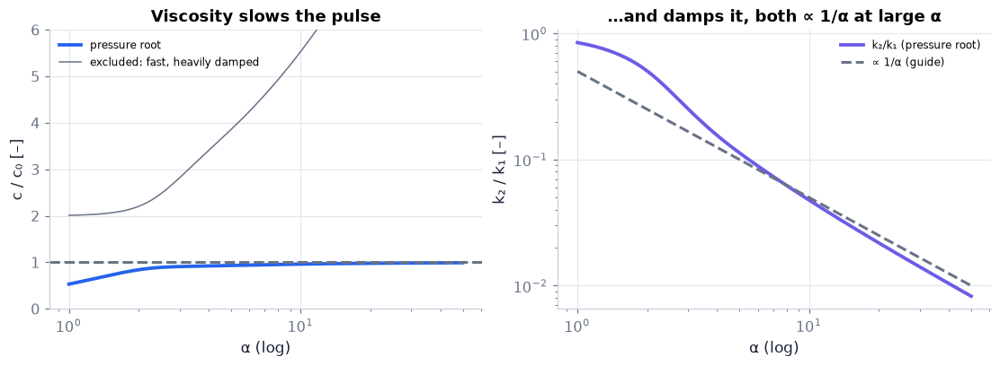

In [95]:
al_ = np.logspace(0, np.log10(50), 200)                       # Womersley numbers 1 … 50
pw = ch16.elastic_tube_wave_curve(al_, poisson=0.5)           # pressure root along the whole curve (continuation)
ow = ch16.elastic_tube_wave_curve(al_, poisson=0.5, branch="other")   # the other root
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.6))   # a new figure and its axes
ax.semilogx(al_, pw["c_over_c0"], color=COLORS["blue"], lw=2.5, label="pressure root")   # curve: pressure root
ax.semilogx(al_, ow["c_over_c0"], color=COLORS["muted"], lw=1, label="excluded: fast, heavily damped")   # curve: excluded: fast, heavily damped
ax.axhline(1, ls="--", color=COLORS["muted"]); ax.set(ylim=(0, 6), xlabel="α (log)", ylabel="c / c₀ [–]", title="Viscosity slows the pulse")   # a reference line
bx.loglog(al_, pw["k2_over_k1"], color=COLORS["accent"], lw=2.5, label="k₂/k₁ (pressure root)")   # curve: k₂/k₁ (pressure root)
bx.loglog(al_, 0.5/al_, "--", color=COLORS["muted"], label="∝ 1/α (guide)")   # curve: ∝ 1/α (guide)
bx.set(xlabel="α (log)", ylabel="k₂ / k₁ [–]", title="…and damps it, both ∝ 1/α at large α")   # axis labels, limits and title
ax.legend(fontsize=8); bx.legend(fontsize=8)   # the legend
savefig(fig, "ch16", "c11_viscous_waves"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** Left: the wave speed relative to Moens–Korteweg's for the pressure root (bold blue) and the excluded root (faint);
right: the damping ratio k₂/k₁ of the pressure root with a 1/α guide.

**How to read it.** At large α the pressure wave approaches c₀ and its damping falls like 1/α — the aorta carries nearly the inviscid
wave. Toward α ≈ 1–3 the wave slows markedly and loses most of its amplitude within a wavelength. The excluded root is far
faster and dies within a fraction of a wavelength — not the pulse.

**What would change if…** …the wall were viscoelastic (N72)? Both curves shift toward more damping at every α.

In [96]:
nus = [0.3, 0.325, 0.35, 0.375, 0.4, 0.425, 0.45, 0.475, 0.5]   # Poisson's ratio (9 positions)
al_p = np.logspace(0, np.log10(50), 120)                      # α grid
def roots_curves(nu_):                                        # both roots for one Poisson ratio
    p_ = ch16.elastic_tube_wave_curve(al_p, poisson=nu_); o_ = ch16.elastic_tube_wave_curve(al_p, poisson=nu_, branch="other")   # `ch16.elastic_tube_wave_curve` (the chapter module)
    return {"c/c₀ pressure root": (al_p, p_["c_over_c0"]), "k₂/k₁ pressure root": (al_p, p_["k2_over_k1"]),   # what this function hands back
            "c/c₀ other root": (al_p, o_["c_over_c0"]), "k₂/k₁ other root": (al_p, o_["k2_over_k1"])}   # (continued from the line above)
fig = slider_figure(roots_curves, "ν̂", nus, xlabel="Womersley number α (log)", ylabel="ratio [–]",   # build the slider figure (every position computed now)
                    title="Poisson's ratio barely moves the pulse", xrange=[0, np.log10(50)], yrange=[0, 2.5], active=8)   # the figure's title: its message
fig.update_xaxes(type="log"); fig.show()   # logarithmic axis on the web figure

**Figure F4.** Slider: Poisson's ratio of the wall, 0.3 to 0.5 (opens on 0.5, an incompressible wall). **What you
see.** Speed ratio and damping of both roots against α. **How to read it.** The pressure root's curves hardly move with
ν̂; the other root (cut at 2.5) changes more. **What would change if…** ν̂ = 0: the Poisson coupling disappears and the
wall acts only through its hoop stiffness.

In [97]:
nfr = 24 if FAST else 40                                      # frames for one period
xw = np.linspace(0, 3*2*np.pi, 400)                           # three inviscid wavelengths (k0 = 1, so x in units of 1/k0)
wts = np.linspace(0, 2*np.pi, nfr, endpoint=False)            # phases ωt
waves = {}   # collect the artists / results
for al in (3.0, 15.0):                                        # a small artery and an aorta-like case
    sX = np.sqrt(ch16.elastic_tube_roots(al, 0.5)["pressure"])   # k/k0 = √X (Re > 0)
    waves[al] = sX                                            # keep the complex wavenumber ratio for this α
fig, axs = plt.subplots(2, 1, figsize=(7.5, 3.6), sharex=True)   # a new figure and its axes
lines = []   # collect the artists / results
for ax, al in zip(axs, (3.0, 15.0)):                          # top panel α = 3, bottom α = 15
    ax.plot(xw, np.exp(-waves[al].imag*xw), ":", color=COLORS["rose"], lw=0.8)   # the decaying envelope e^{−k2 x}
    (lv,) = ax.plot([], [], color=COLORS["blue"], lw=2, label=f"viscous, α = {al:g}")   # an empty line, filled in frame by frame by update()
    (li,) = ax.plot([], [], "--", color=COLORS["muted"], label="inviscid (C08)")   # an empty line, filled in frame by frame by update()
    lines.append((lv, li, al)); ax.set(ylim=(-1.1, 1.1), ylabel="p / p_in"); ax.legend(fontsize=7, loc="upper right")   # axis labels, limits and title
axs[1].set_xlabel("distance k₀x [rad]")   # axis label or title
def update(i):                                                # frame i
    out = []   # collect the artists / results
    for lv, li, al in lines:                                  # viscous line, inviscid line and α of each panel
        lv.set_data(xw, np.real(np.exp(1j*(waves[al]*xw - wts[i]))))   # Re e^{i(kx − ωt)} (16.116)
        li.set_data(xw, np.cos(xw - wts[i])); out += [lv, li]   # move the artist to this frame
    return out   # what this function hands back
fig.canvas.draw(); fig.set_layout_engine("none")              # lay the figure out once, then freeze it (faster frames)
show_animation(animate(update, frames=nfr, fig=fig, interval=70), player="video")   # render the frames and embed the player

**Figure A5.** **What you see.** One period of a pressure wave along three inviscid wavelengths for α = 3 (top) and
α = 15 (bottom), against the inviscid wave of the same frequency (grey dashed); the dotted line is the envelope
$e^{-k_2x}$. **How to read it.** At α = 3 the wave falls behind the inviscid one and fades within a wavelength; at α = 15 it
almost keeps pace and keeps most of its amplitude. **What would change if…** α = 50: the two curves would nearly coincide
over the three wavelengths.

📝 **Note.** **N72 [B]** A viscoelastic wall: replace E and ν̂ by $E^*=E-i\omega E',\ \ \hat\nu^*=\hat\nu-i\omega\hat\nu'$ (16.137). This is the **Kelvin–Voigt** model of a material: a spring
and a damper side by side, so the wall's stress is $E\varepsilon+E'\,d\varepsilon/dt$ — the elastic part plus a part
proportional to the rate of stretching. For a mode $e^{-i\omega t}$, $d/dt\to-i\omega$, which gives the complex modulus
$E-i\omega E'$ (the sign of the imaginary part belongs to the convention, trap T1).

In [98]:
for Er in (1.0, 1 - 0.1j):                                   # elastic, and a wall with 10 % viscous modulus
    wv = ch16.elastic_tube_wave(8.0, E_ratio=Er)             # (16.136) with E* = E·E_ratio (16.137)
    print(f"E*/E = {Er}: c/c0 = {wv['c_over_c0']:.4f}, kept per wavelength = {wv['damping_per_wavelength']:.3f}")   # more damping

E*/E = 1.0: c/c0 = 0.9541, kept per wavelength = 0.677
E*/E = (1-0.1j): c/c0 = 0.9606, kept per wavelength = 0.494


📝 **Note.** **N73 [C]** A steady stream adds to the wave speed downstream and subtracts upstream (Ch. 15's U ± c, `AC.wave_speeds`);
small in arteries.

**What would change if…** …the tube branched? A pulse meeting a fork is partly reflected — C13. But first: why are the branches the sizes they
are? C12.

### 🧩 Murray's law: $a=\left[\dfrac{16\mu}{\pi^2K}\right]^{1/6}Q^{1/3}$ (16.140, corrected) and $a_0^3=a_1^3+a_2^3$ (16.144) `C12`

*The question:* Why are blood vessels the width they are?

#### The problem in plain words

A wider pipe is easier to push water through — so why not make every vessel wide? Because blood is expensive: the body must
make it, warm it and carry it around. Murray asked which radius makes **the total cost — pumping plus upkeep — smallest**.
The answer is a rule you can test with a ruler on any cast of a vascular tree.

#### The idea

```
cost ↑  pumping ∝ a⁻⁴ ╲                ╱ upkeep ∝ a²
        ╲             ╱
          ╲_minimum__╱
        ──────────────────────────► radius a
```

A falling power plus a rising power has one minimum (P349, Ch. 14).

📝 **Note.** **N74 [B]** The cost of a segment: pumping power Δp·Q = RQ² with R from $R=\dfrac{8\mu L}{\pi a^4}$ (16.20), plus an upkeep power K per unit volume of
blood (W/m³ — the book's K, not the compliance; trap T2): $\hat E_1=\dfrac{8\mu L}{\pi a^4}Q^2+K\pi a^2L$ (16.138).

In [99]:
print(ch16.murray_cost(5e-3, CO, murray["L"], murray["mu"], murray["b_metabolic"]), "W")   # (16.138) for a 5-mm, 10-cm segment carrying our CO

0.017559886683490622 W


> 🔁 **Tools from earlier chapters used in this block** (one line each; the full primers are in the chapters named)

- **the minimum of a falling plus a rising power** — a/xⁿ + bxᵐ has one minimum, where the derivative vanishes; at that point the two terms stand in the fixed ratio m : n — here pumping : upkeep = 1 : 2. *(Ch. 14, P349)*
- **level sets and the directional derivative** — the rate of change of f along a unit direction m is ∇f·m; here the change of a length when the branch point moves. *(Ch. 2, P75)*
- **the cosine rule** — in a triangle with sides p, q, s, s² = p² + q² − 2pq cos(angle between p and q); here three weighted pulls close a triangle and fix the branch angles. *(Ch. 14, P340)*

#### 🧮 Derivation — Murray's optimal radius and the minimum cost `D22` ★★ (Eq. 16.140, corrected: $a=\left[\dfrac{16\mu}{\pi^2K}\right]^{1/6}Q^{1/3}$)

**What we want to show.** Find the radius that makes a blood vessel cheapest to run, given the flow it must carry.

**Assumptions.** Poiseuille flow in the segment (step 1); upkeep proportional to blood volume (step 2).

**The plan.**

1. Price the pumping.
2. Price the upkeep.
3. Add.
4. Set the slope to zero.
5. Solve.
6. Check it is a minimum.
7. Evaluate.

**Tools we use** (each explained before this point): derivative = 0 at a minimum and the second derivative test · the minimum of a falling plus a rising power (P349, reminder)

**We start from**

$$ P_{pump}=\Delta p\,Q,\qquad P_{up}=K\times(\text{volume of blood held}) $$

*In words:* The two costs of a segment — pumping blood through it and keeping its blood alive.

---

**Step 1 of 8 — Price the pumping.**

$$ P_{pump}=\Delta p\,Q=RQ^2=\dfrac{8\mu L}{\pi a^4}Q^2 $$

- *Why we can do this:* Power = pressure drop × volume flow; with $R=\dfrac{8\mu L}{\pi a^4}$ (16.20) the drop is RQ.
- *In words:* Narrow vessels are expensive to push blood through.

---

**Step 2 of 8 — Price the upkeep.**

$$ P_{up}=K\,\pi a^2L $$

- *Why we can do this:* The body pays a power K per unit volume of blood held (W/m³ — the book's K, not the compliance, trap T2); the segment holds πa²L.
- *In words:* Wide vessels are expensive to fill and maintain.

---

**Step 3 of 8 — Add the two.**

$$ \hat E_1=\dfrac{8\mu L}{\pi a^4}Q^2+K\pi a^2L\ \text{(16.138)} $$

- *Why we can do this:* Total power to run the segment.
- *In words:* One falling and one rising term.

---

**Step 4 of 8 — Set the slope to zero.**

$$ \dfrac{\partial\hat E_1}{\partial a}=-\dfrac{32\mu L}{\pi}Q^2a^{-5}+2K\pi La=0\ \text{(16.139)} $$

- *Why we can do this:* At a minimum of a smooth function the derivative vanishes; power rule: $d(a^{-4})/da=-4a^{-5}$, $d(a^2)/da=2a$.
- *In words:* At the best radius widening saves as much pumping as it adds upkeep.

---

**Step 5 of 8 — Solve for $a^6$.**

$$ a^6=\dfrac{16\mu Q^2}{\pi^2K} $$

- *Why we can do this:* Multiply $\dfrac{\partial\hat E_1}{\partial a}=-\dfrac{32\mu L}{\pi}Q^2a^{-5}+2K\pi La=0$ (16.139) by $a^5/(2\pi KL)$: $\dfrac{32\mu Q^2}{\pi\cdot2\pi K}=\dfrac{16\mu Q^2}{\pi^2K}$.
- *In words:* One power of a, isolated.

---

**Step 6 of 8 — Take the sixth root.**

$$ a=\left[\dfrac{16\mu}{\pi^2K}\right]^{1/6}Q^{1/3}\ \text{(16.140, corrected)} $$

- *Why we can do this:* $(Q^2)^{1/6}=Q^{1/3}$. The book prints $\left[\dfrac{16\mu}{\pi^2}K\right]^{1/6}$ — K upside down (slip S15); units decide: μQ²/K = (Pa s)(m⁶/s²)/(Pa/s) = m⁶ ✓.
- *In words:* Murray's law: the flow grows as the cube of the radius.

---

**Step 7 of 8 — Check it is a minimum.**

$$ \dfrac{\partial^2\hat E_1}{\partial a^2}=\dfrac{160\mu L}{\pi}Q^2a^{-6}+2K\pi L>0 $$

- *Why we can do this:* Both terms are positive for every a > 0, so the stationary point is the minimum.
- *In words:* Any other radius costs more.

---

**Step 8 of 8 — Evaluate the cost at the optimum.**

$$ \hat E_{1,\min}=\dfrac{3\pi}2KLa^2\ \text{(16.141)} $$

- *Why we can do this:* Step 5 gives $\dfrac{8\mu LQ^2}{\pi a^4}=\dfrac{\pi}{2}KLa^2$: the pumping is half the upkeep; add $\pi KLa^2$.
- *In words:* At the optimum one third of the cost is pumping, two thirds upkeep.

---

**Result**

$$ a=\left[\dfrac{16\mu}{\pi^2K}\right]^{1/6}Q^{1/3}\ \text{(16.140, corrected),}\ \hat E_{1,\min}=\dfrac{3\pi}2KLa^2\ \text{(16.141).} $$

**What it means.** Nature sizes vessels so that flow ∝ radius³ — the most testable claim of the chapter. Fails where the flow is pulsatile or non-Newtonian, or the cost is not proportional to volume.

**Check it.** Units ✓ (step 6); **expect** Q = 82.5 mL/s, μ = 3.5 mPa s, K = 1000 W/m³: a = **5.81 mm**; the printed $a=\left[\dfrac{16\mu}{\pi^2}K\right]^{1/6}Q^{1/3}$ (16.140, as printed) gives 58.1 mm (ten times too big here, and the wrong K-dependence); pumping 5.31 mW and upkeep 10.62 mW per 10 cm (ratio ½ ✓); a grid search over a finds the same optimum.

> ⚠️ **Common confusion (traps in `D22`):** S15; K here is a cost per volume (T2); the ½ ratio is a property of the optimum, not of any radius.

> ⚠️ **slip S15 — the book prints** $a=\left[\dfrac{16\mu}{\pi^2}K\right]^{1/6}Q^{1/3}$ (16.140, as printed) and the same bracket in (16.143); **the correct form is** $a=\left[\dfrac{16\mu}{\pi^2K}\right]^{1/6}Q^{1/3}$ (16.140, corrected)
>
> A units check catches it: μ/K has units s², so
$(\mu Q^2/K)^{1/6}$ is a length; the printed $(\mu KQ^2)^{1/6}$ is not.

In [100]:
mu_q, Q_q, K_q = UN.Q_(3.5e-3, "Pa*s"), UN.Q_(CO, "m**3/s"), UN.Q_(1000.0, "W/m**3")   # viscosity, flow, upkeep with units
print("corrected is a length:", UN.check_dimensions(((16*mu_q*Q_q**2/(np.pi**2*K_q)).to_base_units())**(1/6), "[length]"))   # True: μQ²/K is m⁶
print("printed is a length:  ", UN.check_dimensions(((16*mu_q*K_q*Q_q**2/np.pi**2).to_base_units())**(1/6), "[length]"))      # False
print("units of the printed a:", ((16*mu_q*K_q*Q_q**2/np.pi**2).to_base_units())**(1/6))   # not metres

corrected is a length: True
printed is a length:   False
units of the printed a: 0.05813879547665453 kilogram ** 0.333333 * meter ** 0.666667 / second


#### ✏️ Tiny example: an aorta-sized optimum

Q = 82.5 mL/s, μ = 3.5 mPa s, K = 1000 W/m³:
1. 16μ/(π²K) = 0.056/9870 = 5.67 × 10⁻⁶ s² (μ/K is (Pa s)/(Pa/s)); its sixth root 0.1335 s^{1/3}.
2. Q^{1/3} = ($8.25$ × 10⁻⁵)^{1/3} = 0.04355 m s^{−1/3}.
3. a = 0.1335 × 0.04355 = **5.81 mm** (ours).
4. Over 10 cm: pumping 5.31 mW, upkeep 10.62 mW — exactly 1 : 2.
5. The printed formula would give 58.1 mm.

In [101]:
a_star = ch16.murray_radius(CO, murray["mu"], murray["b_metabolic"])                 # (16.140, corrected) [m]
terms = ch16.murray_terms(a_star, CO, murray["L"], murray["mu"], murray["b_metabolic"])   # pumping and upkeep at the optimum [W]
E_min = ch16.murray_min_cost(CO, murray["L"], murray["mu"], murray["b_metabolic"])   # (16.141) [W]
a_bad = ch16.murray_radius(CO, murray["mu"], murray["b_metabolic"], printed_16_140=True)   # the printed (16.140)
print(f"a* = {a_star*1e3:.4f} mm; pumping {terms['pumping']*1e3:.3f} mW, upkeep {terms['upkeep']*1e3:.3f} mW (ratio {terms['pumping']/terms['upkeep']:.3f}); "   # print the result
      f"min cost {E_min*1e3:.3f} mW; printed formula {a_bad*1e3:.2f} mm")   # (continued from the line above)

a* = 5.8139 mm; pumping 5.309 mW, upkeep 10.619 mW (ratio 0.500); min cost 15.928 mW; printed formula 58.14 mm


In [102]:
a = np.linspace(1e-3, 20e-3, 20001)                            # candidate radii [m]
cost = 8*murray["mu"]*murray["L"]*CO**2/(np.pi*a**4) + murray["b_metabolic"]*np.pi*a**2*murray["L"]   # (16.138) by hand [W]
assert abs(a[np.argmin(cost)] - a_star) < 2e-6                 # the grid minimum is Murray's radius
assert ch16.murray_cost(a_bad, CO, murray["L"], murray["mu"], murray["b_metabolic"]) > 10*E_min   # the printed radius costs > 10×
print(f"grid minimum at {a[np.argmin(cost)]*1e3:.4f} mm")   # print the result

grid minimum at 5.8136 mm


**What does the code above do?**

A brute-force search over 20 001 radii finds the minimum of $\hat E_1=\dfrac{8\mu L}{\pi a^4}Q^2+K\pi a^2L$ (16.138) exactly where $a=\left[\dfrac{16\mu}{\pi^2K}\right]^{1/6}Q^{1/3}$ (16.140, corrected) puts it; the printed
radius costs more than ten times the minimum.

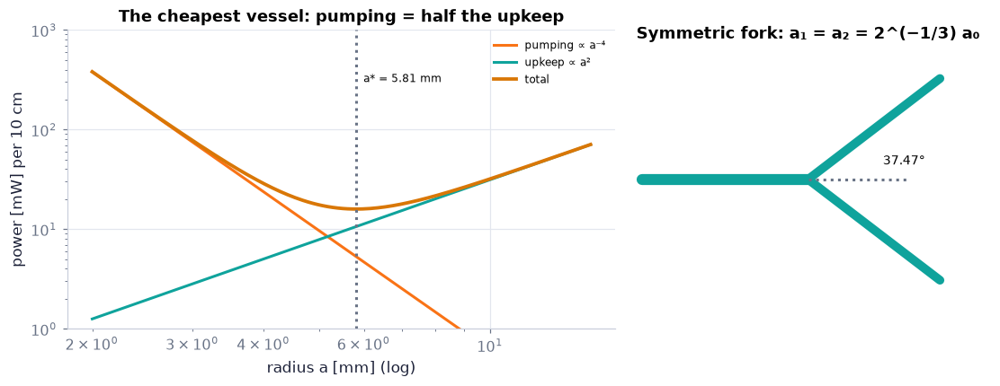

a = 0.7 a*: +71 % above the minimum cost (formula ⅓x⁻⁴ + ⅔x² − 1 = +71 %)
a = 1.3 a*: +24 % above the minimum cost (formula ⅓x⁻⁴ + ⅔x² − 1 = +24 %)


In [103]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw=dict(width_ratios=[1.5, 1]))   # a new figure and its axes
aa = np.logspace(np.log10(2e-3), np.log10(15e-3), 200)         # radii [m]
tt_ = ch16.murray_terms(aa, CO, murray["L"], murray["mu"], murray["b_metabolic"])   # the two costs [W]
ax.loglog(aa*1e3, tt_["pumping"]*1e3, color=COLORS["orange"], label="pumping ∝ a⁻⁴")   # curve: pumping ∝ a⁻⁴
ax.loglog(aa*1e3, tt_["upkeep"]*1e3, color=COLORS["teal"], label="upkeep ∝ a²")   # curve: upkeep ∝ a²
ax.loglog(aa*1e3, tt_["total"]*1e3, color=COLORS["amber"], lw=2.5, label="total")   # curve: total
ax.axvline(a_star*1e3, color=COLORS["muted"], ls=":"); ax.text(a_star*1e3*1.03, 300, f"a* = {a_star*1e3:.2f} mm", fontsize=8)   # a reference line
ax.set(xlabel="radius a [mm] (log)", ylabel="power [mW] per 10 cm", ylim=(1, 1e3), title="The cheapest vessel: pumping = half the upkeep")   # axis labels, limits and title
ax.legend(fontsize=8)   # the legend
th = ch16.murray_symmetric_angle()                             # arccos 2^{-1/3} [rad]
for s in (1, -1):                                              # a symmetric Murray fork drawn to scale
    bx.plot([0, 2*np.cos(th)], [0, s*2*np.sin(th)], color=COLORS["teal"], lw=8*2**(-1/3), solid_capstyle="round")   # a daughter, line width ∝ radius
bx.plot([-2, 0], [0, 0], color=COLORS["teal"], lw=8, solid_capstyle="round")   # the parent vessel
bx.plot([0, 1.2], [0, 0], ":", color=COLORS["muted"])          # the parent's extension, from which the angles are measured
bx.text(0.9, 0.18, f"{np.degrees(th):.2f}°", fontsize=9); bx.set(xlim=(-2.2, 2.2), ylim=(-1.6, 1.6), aspect="equal", title="Symmetric fork: a₁ = a₂ = 2^(−1/3) a₀")   # a text label on the plot
bx.axis("off")   # no axes: a drawing, not a graph
savefig(fig, "ch16", "c12_murray"); plt.show()   # save to outputs/ch16/ and show the figure
for x_ in (0.7, 1.3):                                          # radii 30 % below and above the optimum
    extra = ch16.murray_cost(x_*a_star, CO, murray["L"], murray["mu"], murray["b_metabolic"])/E_min - 1   # (16.138) over (16.141)
    print(f"a = {x_:.1f} a*: {100*extra:+.0f} % above the minimum cost (formula ⅓x⁻⁴ + ⅔x² − 1 = {100*(x_**-4/3 + 2*x_**2/3 - 1):+.0f} %)")   # print the result

**What you see.** Left: pumping (orange), upkeep (teal) and total (amber) power of a 10-cm segment carrying our cardiac output, against
its radius, with the optimum marked. Right: a symmetric Murray fork drawn to scale, each daughter leaving at 37.47° from the
parent's extension.

**How to read it.** The total cost has one minimum where the pumping curve sits at half the upkeep curve (step 8 of D22). It is
lopsided: relative to the optimum a segment of radius $x\,a^*$ costs $\tfrac13x^{-4}+\tfrac23x^2$ times the minimum, so a
vessel 30 % too wide costs 24 % more but one 30 % too narrow costs 71 % more (printed) — the steep $a^{-4}$ pumping side
punishes narrowing hardest. The printed formula's tenfold radius costs more than ten times the minimum.

**What would change if…** …the flow were eight times larger? The optimum would move to twice the radius ($Q\propto a^3$) — slide it in F5.

In [104]:
Qs_ = list(np.round(np.logspace(np.log10(1e-6), np.log10(200e-6), 25), 9))   # flows 1 … 200 mL/s
aa_p = np.logspace(np.log10(0.5e-3), np.log10(20e-3), 200)    # radii [m]
def costs(Q_):                                                 # three costs for one flow
    tt = ch16.murray_terms(aa_p, Q_, murray["L"], murray["mu"], murray["b_metabolic"])   # `ch16.murray_terms` (the chapter module)
    return {"pumping": (aa_p*1e3, tt["pumping"]*1e3), "upkeep": (aa_p*1e3, tt["upkeep"]*1e3), "total": (aa_p*1e3, tt["total"]*1e3)}   # what this function hands back
fig = slider_figure(costs, "Q", Qs_, unit="m³/s", xlabel="radius a [mm] (log)", ylabel="power [mW] per 10 cm (log)",   # build the slider figure (every position computed now)
                    title="The optimum slides as Q^(1/3)", xrange=[np.log10(0.5), np.log10(20)], yrange=[-3, 3],   # the figure's title: its message
                    active=int(np.argmin(np.abs(np.array(Qs_) - CO))))   # fixed axis ranges and the slider position it opens on
fig.update_xaxes(type="log"); fig.update_yaxes(type="log"); fig.show()   # logarithmic axis on the web figure

**Figure F5.** Slider: the flow carried, 1 to 200 mL/s (opens near our 82.5 mL/s). **What you see.** The three costs
against radius. **How to read it.** The minimum of the total moves right by a factor 2 for every factor 8 in Q. **What would
change if…** blood were cheaper (smaller K): the upkeep line drops and every optimum widens as $K^{-1/6}$.

#### 🧮 Derivation — The cube law `D23` ★ (Eq. 16.144: $a_0^3=a_1^3+a_2^3$)

**What we want to show.** Find how the radii at a fork must be related if every segment is optimal.

**Assumptions.** The same μ and K in every segment (step 1).

**The plan.**

1. Invert for Q_i.
2. Conserve flow.
3. Cancel.

**Tools we use** (each explained before this point): mass conservation at a node

**We start from**

$$ a_i=\left[\dfrac{16\mu}{\pi^2K}\right]^{1/6}Q_i^{1/3}\ \text{(16.143, with the corrected bracket) for i = 0, 1, 2.} $$

---

**Step 1 of 3 — Invert the optimum for each segment.**

$$ Q_i=\left[\dfrac{\pi^2K}{16\mu}\right]^{1/2}a_i^3,\quad i=0,1,2 $$

- *Why we can do this:* Cube both sides of $a_i=\left[\dfrac{16\mu}{\pi^2K}\right]^{1/6}Q_i^{1/3}$ (16.143) and solve for Q_i; the constant is the same for all three.
- *In words:* Each segment's flow is a constant times its radius cubed.

---

**Step 2 of 3 — Conserve flow at the fork.**

$$ Q_0=Q_1+Q_2 $$

- *Why we can do this:* Incompressible blood; nothing stored at the junction.
- *In words:* What enters the fork leaves it.

---

**Step 3 of 3 — Substitute and cancel the constant.**

$$ a_0^3=a_1^3+a_2^3\ \text{(16.144)} $$

- *Why we can do this:* Step 1 in step 2; divide by the common constant.
- *In words:* Murray's cube law.

---

**Result**

$$ a_0^3=a_1^3+a_2^3\qquad\text{(16.144)} $$

*In words:* Murray's cube law.

**What it means.** The law needs only the radii — a test you can make on a cast of a vascular tree. Fails as D22.

**Check it.** Symmetric fork: $a_1=a_2=2^{-1/3}a_0=0.794a_0$; the daughters' total area is $2\times0.630=1.26$ times the parent's, so the mean speed falls by that factor.

📝 **Notes taught inside `D23`:** **N75 [B]** the cube law $a_0^3=a_1^3+a_2^3$ (16.144).

> ⚠️ **Common confusion (traps in `D23`):** Cubes, not squares (area conservation would be a₀² = a₁² + a₂²).

In [105]:
a1, a2 = ch16.murray_daughters(a_star, 0.5)                  # an even split: each daughter 2^{-1/3} a0
print(f"{a1/a_star:.4f}, {a2/a_star:.4f}; check a0³ − a1³ − a2³ = {a_star**3 - a1**3 - a2**3:.1e}")   # 0.7937; cube law holds

0.7937, 0.7937; check a0³ − a1³ − a2³ = 2.6e-23


> 📎 **Primer — scipy.optimize.minimize for a point in the plane.** `P387` · `minimize(f, x0, method='Nelder-Mead')` finds a minimum of a
function of several variables by moving a small triangle downhill; no derivatives needed. Here it finds the cheapest
branch point B. `minimize_scalar` (P170) did the one-variable case.

In [106]:
from scipy.optimize import minimize            # several-variable minimiser
f = lambda B: (B[0] - 1)**2 + (B[1] + 2)**2    # a bowl centred at (1, −2)
print(minimize(f, [0, 0], method="Nelder-Mead").x)   # ≈ [1, −2]

[ 1. -2.]


> 📎 **Primer — the weighted Fermat point.** `P388` · Move a point B by a small step ds in a direction m: its distance to a fixed point P
changes by −(unit vector from B to P)·m ds (a directional derivative, P75). So the weighted sum Σwᵢ|Pᵢ − B| is least where
the weighted unit vectors wᵢeᵢ add to zero — they close a triangle of "forces", whose angles the cosine rule (P340)
gives.

In [107]:
w = np.array([1.0, 0.63, 0.63])                 # weights a_i² of a symmetric Murray fork
print(np.degrees(np.arccos((w[0]**2 + w[1]**2 - w[2]**2)/(2*w[0]*w[1]))))   # 37.47°

37.47199518281389


#### 🧮 Derivation — The branching angles `D24` ★★★ (Eq. 16.147: $\cos\theta=\dfrac{a_0^4+a_1^4-(a_0^3-a_1^3)^{4/3}}{2a_0^2a_1^2}$)

**What we want to show.** Find where the branch point B of a fork should sit, and so the angles of the daughters, when A, C and D are fixed.

**Assumptions.** a planar fork; radii fixed by the flows (D23); A, C, D fixed.

**The plan.**

1. The cost as a weighted length.
2. How each length changes when B moves.
3. Set the change to zero for every direction.
4. a triangle of "forces".
5. The cosine rule.

**Tools we use** (each explained before this point): the directional derivative of a length and the weighted Fermat point (P388, primer in C12, built on P75) · the cosine rule (P340, reminder) · `scipy.optimize.minimize` (P387, primer in C12) for the numeric check

**We start from**

$$ \delta\hat E_{2,\min}=\dfrac{3\pi}2K\left(\delta L_0\,a_0^2+\delta L_1\,a_1^2+\delta L_2\,a_2^2\right)\ \text{(16.145)} $$

*In words:* Moving B changes only the lengths

---

**Step 1 of 11 — Write the fork's cost as a weighted length.**

$$ \hat E_{2,\min}=\dfrac{3\pi}2K\left(a_0^2L_0+a_1^2L_1+a_2^2L_2\right)\ \text{(16.142)} $$

- *Why we can do this:* $\hat E_{1,\min}=\dfrac{3\pi}2KLa^2$ (16.141) for each optimal segment, added; only the lengths L_i depend on where B is.
- *In words:* Each segment costs its length times its radius squared.

---

**Step 2 of 11 — Name the unit vectors of the segments.**

$$ \mathbf e_0=\dfrac{B-A}{L_0},\quad\mathbf e_1=\dfrac{C-B}{L_1},\quad\mathbf e_2=\dfrac{D-B}{L_2} $$

- *Why we can do this:* Directions of flow along each segment; they set the angles we want.
- *In words:* Three arrows along the parent and the two daughters.

---

**Step 3 of 11 — Move B a small step ds along a direction m.**

$$ \delta L_0=\mathbf e_0\cdot\mathbf m\,ds,\quad\delta L_1=-\mathbf e_1\cdot\mathbf m\,ds,\quad\delta L_2=-\mathbf e_2\cdot\mathbf m\,ds $$

- *Why we can do this:* P388: a distance from a fixed point grows at the rate (unit vector away from that point)·m; e₀ points away from A, while e₁, e₂ point toward C and D.
- *In words:* Moving B toward C shortens L₁ and lengthens L₀.

---

**Step 4 of 11 — Put them into (16.145).**

$$ \delta\hat E_{2,\min}=\dfrac{3\pi}2K\left(a_0^2\mathbf e_0-a_1^2\mathbf e_1-a_2^2\mathbf e_2\right)\cdot\mathbf m\,ds $$

- *Why we can do this:* Each δL_i of step 3 times its weight $a_i^2$.
- *In words:* The cost change is a dot product with the direction of the move.

---

**Step 5 of 11 — Demand no change in any direction.**

$$ a_0^2\mathbf e_0=a_1^2\mathbf e_1+a_2^2\mathbf e_2 $$

- *Why we can do this:* At the optimum δÊ = 0 for every m (the book's "displacements one at a time"); a vector whose dot product with every m vanishes is zero.
- *In words:* Three pulls of sizes a₀², a₁², a₂² balance: they close a triangle.

---

**Step 6 of 11 — Define the angles.**

$$ \cos\theta=\mathbf e_0\cdot\mathbf e_1,\quad\cos\phi=\mathbf e_0\cdot\mathbf e_2 $$

- *Why we can do this:* θ and φ are measured from the extension of the parent, as the book's Fig. 16.15 does (not from the parent itself).
- *In words:* How far each daughter turns.

---

**Step 7 of 11 — Isolate one daughter and square.**

$$ a_2^4=\left|a_0^2\mathbf e_0-a_1^2\mathbf e_1\right|^2 $$

- *Why we can do this:* Step 5 gives $a_2^2\mathbf e_2=a_0^2\mathbf e_0-a_1^2\mathbf e_1$; |e₂| = 1.
- *In words:* One side of the triangle from the other two.

---

**Step 8 of 11 — Expand the square.**

$$ a_2^4=a_0^4+a_1^4-2a_0^2a_1^2\cos\theta $$

- *Why we can do this:* $|\mathbf u-\mathbf v|^2=|\mathbf u|^2+|\mathbf v|^2-2\mathbf u\cdot\mathbf v$ — the cosine rule (P340).
- *In words:* The triangle's sides fix its angles.

---

**Step 9 of 11 — Solve for the three cosines.**

$$ \cos\theta=\dfrac{a_0^4+a_1^4-a_2^4}{2a_0^2a_1^2},\quad\cos\phi=\dfrac{a_0^4-a_1^4+a_2^4}{2a_0^2a_2^2},\quad\cos(\theta+\phi)=\dfrac{a_0^4-a_1^4-a_2^4}{2a_1^2a_2^2}\ \text{(16.146)} $$

- *Why we can do this:* The first from step 8; the second by isolating $a_1^2\mathbf e_1$ instead; the third by squaring step 5 itself, with $\mathbf e_1\cdot\mathbf e_2=\cos(\theta+\phi)$ (the daughters leave on opposite sides).
- *In words:* The angles depend only on the radii.

---

**Step 10 of 11 — Eliminate a₂ with the cube law.**

$$ \cos\theta=\dfrac{a_0^4+a_1^4-(a_0^3-a_1^3)^{4/3}}{2a_0^2a_1^2}\ \text{(16.147)} $$

- *Why we can do this:* $a_0^3=a_1^3+a_2^3$ (16.144): $a_2^3=a_0^3-a_1^3$, so $a_2^4=(a_0^3-a_1^3)^{4/3}$. Replacing a quantity by an equal one keeps the equation true; the angle then depends on a₀ and a₁ only.
- *In words:* One daughter's radius sets its angle.

---

**Step 11 of 11 — Take the symmetric fork.**

$$ a_1=a_2=2^{-1/3}a_0:\quad\cos\theta=2^{-1/3},\ \ \theta=37.47^\circ\ \text{(ours)} $$

- *Why we can do this:* $a_1^4=a_2^4$ cancel; $\dfrac{a_0^4}{2a_0^2a_1^2}=\dfrac{2^{2/3}}2=2^{-1/3}$. Setting a₁ = a₂ is a special case of the general result; the fourth powers then cancel exactly.
- *In words:* Each daughter leaves at 37.5°: 75° between them.

---

**Result**

$$ \begin{array}{l}\cos\theta=\dfrac{a_0^4+a_1^4-a_2^4}{2a_0^2a_1^2},\ \cos\phi=\dfrac{a_0^4-a_1^4+a_2^4}{2a_0^2a_2^2},\ \cos(\theta+\phi)=\dfrac{a_0^4-a_1^4-a_2^4}{2a_1^2a_2^2}\qquad\text{(16.146)} \\[6pt] \cos\theta=\dfrac{a_0^4+a_1^4-(a_0^3-a_1^3)^{4/3}}{2a_0^2a_1^2}\qquad\text{(16.147)}\end{array}\qquad\text{symmetric: }\theta=\arccos2^{-1/3}=37.47^\circ\ \text{(ours)} $$

*In words:* Branch angles fixed by the radii alone.

**What it means.** Branch angles are not free: the optimum is a balance of three "pulls" proportional to radius squared, so thick daughters stay close to the parent's line. Fails if the ends are not fixed or the fork is not planar.

**Check it.** a₂ → 0: a₁ → a₀, cos θ → 1, θ → 0 — a tiny side branch does not bend the main vessel ✓; a 70/30 split: a₁ = 0.888a₀, a₂ = 0.669a₀, θ = **25.7°**, φ = **49.7°** (expect) — the thinner daughter turns more; the numeric minimisation of the weighted length reproduces θ to 10⁻⁶ rad. The sympy cell below re-runs the derivation's own steps (every line is commented); it prints `0` and `25.705664149955744 25.70566416239578` (the numeric optimum and $\cos\theta=\dfrac{a_0^4+a_1^4-a_2^4}{2a_0^2a_1^2},\ \cos\phi=\dfrac{a_0^4-a_1^4+a_2^4}{2a_0^2a_2^2},\ \cos(\theta+\phi)=\dfrac{a_0^4-a_1^4-a_2^4}{2a_1^2a_2^2}$ (16.146) agree to 10⁻⁸ degree).

In [108]:
import sympy as sp, numpy as np                                          # symbols, then a numeric optimisation
from scipy.optimize import minimize                                      # P387
a0, a1, a2, th = sp.symbols('a0 a1 a2 theta', positive=True)   # radii and the angle θ
lhs = a2**4                                                              # step 7: |a2² e2|²
rhs = (a0**2 - a1**2*sp.cos(th))**2 + (a1**2*sp.sin(th))**2              # |a0² e0 − a1² e1|² with e0 = (1, 0)
cos_th = sp.solve(sp.Eq(lhs, sp.expand(sp.trigsimp(rhs))), sp.cos(th))[0]   # steps 8–9
print(sp.simplify(cos_th - (a0**4 + a1**4 - a2**4)/(2*a0**2*a1**2)))     # (16.146) → 0
A, C, D = np.array([0.0, 0.0]), np.array([3.0, 1.2]), np.array([2.6, -1.5])   # fixed ends (arbitrary)
r0, r1 = 1.0, 0.7**(1/3); r2 = (1.0 - 0.7)**(1/3)                        # a 70/30 split by the cube law
cost = lambda B: r0**2*np.linalg.norm(B - A) + r1**2*np.linalg.norm(C - B) + r2**2*np.linalg.norm(D - B)   # (16.142)/(3πK/2)
B = minimize(cost, [1.5, 0.0], method="Nelder-Mead", options=dict(xatol=1e-12, fatol=1e-14, maxiter=20000)).x   # the cheapest branch point, found numerically (P387)
e0, e1 = (B - A)/np.linalg.norm(B - A), (C - B)/np.linalg.norm(C - B)   # step 2
print(np.degrees(np.arccos(e0 @ e1)), np.degrees(np.arccos((r0**4 + r1**4 - r2**4)/(2*r0**2*r1**2))))   # equal

0

25.705664149955744 25.70566416239578


📝 **Notes taught inside `D24`:** **N76 [B]** the angles $\cos\theta=\dfrac{a_0^4+a_1^4-a_2^4}{2a_0^2a_1^2},\ \cos\phi=\dfrac{a_0^4-a_1^4+a_2^4}{2a_0^2a_2^2},\ \cos(\theta+\phi)=\dfrac{a_0^4-a_1^4-a_2^4}{2a_1^2a_2^2}$ (16.146) and $\cos\theta=\dfrac{a_0^4+a_1^4-(a_0^3-a_1^3)^{4/3}}{2a_0^2a_1^2}$ (16.147).

> ⚠️ **Common confusion (traps in `D24`):** The weights are a², not a; angles from the parent's extension.

In [109]:
a0_, a1_, a2_ = 1.0, 0.7**(1/3), 0.3**(1/3)                   # a 70/30 split by the cube law (radii relative to the parent)
ang = ch16.murray_angles(a0_, a1_, a2_)                       # (16.146) [rad]
bp = ch16.bifurcation_point(np.array([0.0, 0.0]), np.array([3.0, 1.2]), np.array([2.6, -1.5]), a0_, a1_, a2_)   # numerical optimum (ours)
print(f"symmetric: {np.degrees(ch16.murray_symmetric_angle()):.3f}°; 70/30: θ = {np.degrees(ang['theta']):.2f}°, φ = {np.degrees(ang['phi']):.2f}°; "   # print the result
      f"numeric θ = {np.degrees(bp['theta']):.2f}°, (16.147) θ = {np.degrees(ch16.murray_theta(a0_, a1_)):.2f}°")   # (continued from the line above)

symmetric: 37.467°; 70/30: θ = 25.71°, φ = 49.73°; numeric θ = 25.71°, (16.147) θ = 25.71°


#### 🎮 Interactive: Why isn't a wider vessel always better?

**Why interactive rather than a static figure:** you drag the radius past the minimum and watch the two cost bars trade, then drag the branch point and see the cost
bottom out exactly where three weighted pulls close a triangle — the balance is found by moving, which a picture cannot
do.

Start with the **Walkthrough**; the **Explain** tab works every number out with your settings, and the **Derivation** tab (where there is one) steps through the same derivation as above. Here K is the upkeep cost per volume of blood (W/m³), not the compliance; angles are measured from the extension of the parent.

**What to try:**
- Put the radius cursor at the minimum: pumping is half the upkeep.
- Pick the 70/30 split: the thin daughter turns more.
- Switch to the printed $a=\left[\dfrac{16\mu}{\pi^2}K\right]^{1/6}Q^{1/3}$ (16.140, as printed) and raise K.

In [110]:
show_viz("ch16", "murray_branching")   # full-width explainer; ⤢ Full screen for more room

[explainer ch16/murray_branching]

**What would change if…** …a pressure pulse arrived at this fork? Its daughters, Murray-sized, are almost matched to the parent — C13 says what
"matched" means.

### 🧩 Echoes at a fork: $\mathrm R=\dfrac{p_R}{p_I}=\dfrac{Y_1-\sum Y_j}{Y_1+\sum Y_j},\ \ \mathrm T=\dfrac{p_{Tj}}{p_I}=\dfrac{2Y_1}{Y_1+\sum Y_j}$ (16.153) `C13`

*The question:* When a pulse reaches a branch, how much comes back?

#### The problem in plain words

Send a wave along a rope tied to a thinner rope: part of it bounces back. Tie it to a thicker one and the echo comes back
upside down. At an arterial fork the "thickness" that matters is not the radius alone but **how easily each tube accepts
flow for a given pressure — its admittance**.

#### The idea

```
incoming pulse ──►  ┌ junction ┐ ──► transmitted into each daughter
            ◄── echo└──────────┘
daughters together accept less flow than the parent  ──► like a closed end ──► upright echo   (R > 0)
daughters accept exactly as much                       ──► matched          ──► no echo        (R = 0)
daughters accept more                                  ──► like an open end ──► inverted echo  (R < 0)
```

**Only the mismatch of admittances matters.** A tube's admittance $Y=A/(\rho c)$ (cross-section area over density
times wave speed) is the flow it accepts per unit pressure in a travelling wave; the echo's share is $\mathrm R=\dfrac{p_R}{p_I}=\dfrac{Y_1-\sum Y_j}{Y_1+\sum Y_j},\ \ \mathrm T=\dfrac{p_{Tj}}{p_I}=\dfrac{2Y_1}{Y_1+\sum Y_j}$ (16.153).

📝 **Note.** **N77 [B]** At the junction the pressure is single-valued and flux is conserved: $p_I+p_R=p_{T1}=p_{T2}$ (16.148), $Q_I-Q_R=Q_{T1}+Q_{T2}$ (16.149) (the book's minus with
a negative $Q_R$ counts the sign twice — slip S16; we keep signs once, D25). **N78 [B]** Multiply $\hat p_1=\rho c\hat u_1,\ \ \hat p_2=-\rho c\hat u_2$ (16.68) by A/(ρc):
$Q=Au=\pm Yp=\pm\dfrac pZ$ (16.151), admittance Y = A/(ρc), impedance Z = ρc/A — the electrical analogy (P381).

In [111]:
A_art = np.pi*artery["a"]**2                                  # parent area [m²]
Y1 = ch16.tube_admittance(A_art, blood["rho"], c0)            # Y = A/(ρc) [m⁴ s/kg]
print(f"Y = {Y1:.3e}, Z = {ch16.tube_impedance(A_art, blood['rho'], c0):.3e}, Y·Z = {Y1*ch16.tube_impedance(A_art, blood['rho'], c0):.1f}")   # print the result

Y = 2.441e-09, Z = 4.097e+08, Y·Z = 1.0


#### 🧮 Derivation — Reflection and transmission at a junction `D25` ★ (Eq. 16.153: $\mathrm R=\dfrac{p_R}{p_I}=\dfrac{Y_1-\sum Y_j}{Y_1+\sum Y_j},\ \ \mathrm T=\dfrac{p_{Tj}}{p_I}=\dfrac{2Y_1}{Y_1+\sum Y_j}$)

**What we want to show.** Find how much of a pressure pulse bounces back from a fork and how much goes on.

**Assumptions.** Inviscid long waves; no storage at the junction (step 2).

**The plan.**

1. Each wave's flux with its sign.
2. Flux conservation.
3. Common pressure.
4. Solve one linear equation.

**Tools we use** (each explained before this point): the electrical analogy and admittance (P381) · the water-hammer relation $\hat p_1=\rho c\hat u_1$, $\hat p_2=-\rho c\hat u_2$ (16.68, R10)

**We start from**

$$ p_I+p_R=p_{T1}=p_{T2}\ \text{(16.148) and}\ Q=Au=\pm Yp=\pm\dfrac pZ\ \text{(16.151).} $$

---

**Step 1 of 6 — Write each wave's flux with its direction.**

$$ Q_I=Y_1p_I,\quad Q_R=-Y_1p_R,\quad Q_{Tj}=Y_jp_{Tj} $$

- *Why we can do this:* $Q=Au=\pm Yp=\pm\dfrac pZ$ (16.151): a wave moving in +x carries Q = +Yp, the reflected wave moving back carries Q = −Yp — the sign of $\hat p_1=\rho c\hat u_1,\ \ \hat p_2=-\rho c\hat u_2$ (16.68). We keep Q_R signed and add; the book's $Q_I-Q_R=Q_{T1}+Q_{T2}$ (16.149) subtracts as well and so counts the sign twice (slip S16).
- *In words:* A pressure pulse pushes blood the way it travels.

---

**Step 2 of 6 — Conserve flux at the junction.**

$$ Y_1(p_I-p_R)=\sum_jY_jp_{Tj}\ \text{(16.152)} $$

- *Why we can do this:* Nothing is stored at the node: the parent's flux equals the daughters' (step 1 substituted).
- *In words:* Blood in = blood out at the fork.

---

**Step 3 of 6 — Use the common pressure.**

$$ p_{Tj}=p_I+p_R $$

- *Why we can do this:* $p_I+p_R=p_{T1}=p_{T2}$ (16.148): the pressure has one value at the junction.
- *In words:* Both daughters start with the parent's total pressure.

---

**Step 4 of 6 — Substitute and collect $p_R$.**

$$ p_R\left(Y_1+\sum Y_j\right)=p_I\left(Y_1-\sum Y_j\right) $$

- *Why we can do this:* $Y_1p_I-Y_1p_R=\sum Y_j(p_I+p_R)$; move terms. Adding the same terms to both sides keeps the equation true; it gathers the unknown p_R on one side.
- *In words:* One equation for the reflected pressure.

---

**Step 5 of 6 — Divide.**

$$ \mathrm R=\dfrac{p_R}{p_I}=\dfrac{Y_1-\sum Y_j}{Y_1+\sum Y_j}\ \text{(16.153)} $$

- *Why we can do this:* $Y_1+\sum Y_j>0$. Dividing both sides by the sum of admittances is allowed because the sum is positive; it leaves the ratio p_R/p_I.
- *In words:* Reflection is set by the admittance mismatch.

---

**Step 6 of 6 — Get the transmission from step 3.**

$$ \mathrm T=\dfrac{p_{Tj}}{p_I}=1+\mathrm R=\dfrac{2Y_1}{Y_1+\sum Y_j}\ \text{(16.153)} $$

- *Why we can do this:* $p_{Tj}=p_I+p_R$; common denominator. With Z = 1/Y the same reads $\dfrac{p_R}{p_I}=\dfrac{Z_1^{-1}-\sum Z_j^{-1}}{Z_1^{-1}+\sum Z_j^{-1}}$ (16.154).
- *In words:* The pressure that goes on.

---

**Result**

$$ \begin{array}{l}\mathrm R=\dfrac{p_R}{p_I}=\dfrac{Y_1-\sum Y_j}{Y_1+\sum Y_j},\ \ \mathrm T=\dfrac{p_{Tj}}{p_I}=\dfrac{2Y_1}{Y_1+\sum Y_j}\qquad\text{(16.153)} \\[6pt] \dfrac{p_R}{p_I}=\dfrac{Z_1^{-1}-\sum Z_j^{-1}}{Z_1^{-1}+\sum Z_j^{-1}}\qquad\text{(16.154)}\end{array} $$

*In words:* Reflection and transmission set by the admittance mismatch.

**What it means.** a fork reflects only if its daughters together are "stiffer" or "softer" than the parent; Murray's forks are close to matched. Fails when the junction stores blood or the waves are short.

**Check it.** ΣY_j = Y₁ → R = 0, T = 1 (matched); ΣY_j → 0 → R → +1, T → 2 (closed end: the pressure doubles, trap T18); ΣY_j → ∞ → R → −1 (open end); **expect** two daughters of radius 0.8a with equal wave speed: ΣY/Y₁ = 1.28, R = **−0.123**, T = 0.877; a Murray-optimal symmetric fork: R = −0.115.

> ⚠️ **Common confusion (traps in `D25`):** S16; T = 1 + R, not 1 − R.

#### 🧮 Derivation — Energy at a junction `D26` ★★ (Eq. 16.163: $\dfrac{p_{T2}^2/Z_2+p_{T3}^2/Z_3}{p_I^2/Z_1}=\dfrac{Z_2^{-1}+Z_3^{-1}}{Z_1^{-1}}\mathrm T^2$)

**What we want to show.** Check that the reflected and transmitted waves carry exactly the energy of the incident one.

**Assumptions.** As D25; equal daughter pressures (step 4).

**The plan.**

1. Power of each wave.
2. The shares.
3. Add them.
4. a perfect square.

**Tools we use** (each explained before this point): the acoustic energy flux of Ch. 15 (recap) · $\mathrm R=\dfrac{p_R}{p_I}=\dfrac{Y_1-\sum Y_j}{Y_1+\sum Y_j},\ \ \mathrm T=\dfrac{p_{Tj}}{p_I}=\dfrac{2Y_1}{Y_1+\sum Y_j}$ (16.153)

**We start from**

$$ \text{power of a travelling wave}=p\,Q,\qquad Q=Yp $$

*In words:* A travelling wave's power is pressure × flux, with Q = Yp.

---

**Step 1 of 6 — Write a wave's power.**

$$ \text{power}=pQ=Yp^2=\dfrac{p^2}{Z} $$

- *Why we can do this:* Power = pressure × volume flux (the acoustic intensity p′u′ of Ch. 15 times the area); Q = Yp for a travelling wave.
- *In words:* A pulse carries energy in proportion to p².

---

**Step 2 of 6 — Incident power.**

$$ \text{incident}=\dfrac{p_I^2}{Z_1}\ \text{(16.161)} $$

- *Why we can do this:* Step 1 in the parent. Applying the power formula of step 1 to the incident wave in the parent tube (impedance Z₁) is direct substitution.
- *In words:* What arrives.

---

**Step 3 of 6 — Reflected power.**

$$ \text{reflected}=\dfrac{(\mathrm Rp_I)^2}{Z_1}=\mathrm R^2\dfrac{p_I^2}{Z_1}\ \text{(16.162)} $$

- *Why we can do this:* The reflected wave is in the parent, with $p_R=\mathrm Rp_I$; we count its power as a magnitude.
- *In words:* R² is the energy reflection coefficient.

---

**Step 4 of 6 — Transmitted share.**

$$ \dfrac{p_{T2}^2/Z_2+p_{T3}^2/Z_3}{p_I^2/Z_1}=\dfrac{Z_2^{-1}+Z_3^{-1}}{Z_1^{-1}}\mathrm T^2\ \text{(16.163)} $$

- *Why we can do this:* $p_{T2}=p_{T3}=\mathrm Tp_I$ by $p_I+p_R=p_{T1}=p_{T2}$ (16.148); factor T².
- *In words:* Not T² alone: the daughters' admittance matters.

---

**Step 5 of 6 — Add the two shares.**

$$ \mathrm R^2+\dfrac{S}{Y_1}\mathrm T^2=\dfrac{(Y_1-S)^2+4SY_1}{(Y_1+S)^2},\quad S\equiv\sum Y_j $$

- *Why we can do this:* Square $\mathrm R=\dfrac{p_R}{p_I}=\dfrac{Y_1-\sum Y_j}{Y_1+\sum Y_j},\ \ \mathrm T=\dfrac{p_{Tj}}{p_I}=\dfrac{2Y_1}{Y_1+\sum Y_j}$ (16.153): $\dfrac{S}{Y_1}\dfrac{4Y_1^2}{(Y_1+S)^2}=\dfrac{4SY_1}{(Y_1+S)^2}$; common denominator.
- *In words:* Everything over one fraction.

---

**Step 6 of 6 — Recognise a perfect square.**

$$ \mathrm R^2+\dfrac{\sum Y_j}{Y_1}\mathrm T^2=1\ \text{(ours)} $$

- *Why we can do this:* $(Y_1-S)^2+4SY_1=Y_1^2+2SY_1+S^2=(Y_1+S)^2$. Expanding the square shows the numerator equals the denominator, and a fraction with equal top and bottom is 1.
- *In words:* The junction neither stores nor loses energy.

---

**Result**

$$ \mathrm R^2+\dfrac{\sum Y_j}{Y_1}\mathrm T^2=1\ \text{(ours).} $$

**What it means.** a pressure wave can grow on reflection (T up to 2) without creating energy, because the energy is pressure × flow and the flow shrinks. Fails with losses at the junction (viscosity, turbulence).

**Check it.** Radius ratio 0.8: 0.0151 + 1.28 × 0.7695 = 0.0151 + 0.9849 = **1** ✓; closed end (S = 0): R² = 1 — all reflected.

📝 **Notes taught inside `D26`:** **N80 [B]** the energy shares $\text{incident power}=\dfrac{p_I^2}{Z_1}$ (16.161), $\text{reflected power}=\mathrm R^2\dfrac{p_I^2}{Z_1}$ (16.162), $\dfrac{p_{T2}^2/Z_2+p_{T3}^2/Z_3}{p_I^2/Z_1}=\dfrac{Z_2^{-1}+Z_3^{-1}}{Z_1^{-1}}\mathrm T^2$ (16.163).

> ⚠️ **Common confusion (traps in `D26`):** The transmitted share is not T²; equal pressures in both daughters.

#### ✏️ Tiny example: a symmetric fork

Daughters of radius 0.8a, same wave speed:
1. Y_j/Y₁ = (A_j/A₁)(c₁/c_j) = 0.64 each; ΣY/Y₁ = 1.28.
2. R = (1 − 1.28)/(1 + 1.28) = **−0.123**: a small inverted echo.
3. T = 1 + R = 0.877.
4. Energy: R² = 0.015 reflected, 1.28 × 0.877² = 0.985 transmitted; sum 1.
5. A Murray fork (daughters $2^{-1/3}a$): ΣY/Y₁ = 1.26, R = **−0.115** — nearly matched.

In [112]:
Rj, Tj = ch16.junction_coefficients(1.0, [0.64, 0.64])        # (16.153) with admittances relative to the parent
en = ch16.junction_energy(1.0, [0.64, 0.64])                  # reflected R², transmitted (ΣY/Y1)T², total
geo = ch16.junction_from_geometry(artery["a"], [0.8*artery["a"]]*2, c0, [c0, c0], blood["rho"])   # the same from radii and speeds
print(f"R = {Rj:.4f}, T = {Tj:.4f}; energy {en['reflected']:.4f} + {en['transmitted']:.4f} = {en['total']:.4f}; from geometry R = {geo['R']:.4f}")   # print the result
print("Murray fork:", round(ch16.junction_coefficients(1.0, [2**(-2/3)]*2)[0], 4))   # Y ∝ a² at equal c: 2 × 2^{-2/3} = 1.26

R = -0.1228, T = 0.8772; energy 0.0151 + 0.9849 = 1.0000; from geometry R = -0.1228
Murray fork: -0.115


In [113]:
Y1_, Yd = 1.0, [0.64, 0.64]                                    # parent and daughter admittances
sol = np.linalg.solve([[1.0, -1.0], [Y1_, sum(Yd)]], [-1.0, Y1_])   # p_I + p_R = p_T and Y1(p_I − p_R) = ΣY p_T, per unit p_I
assert np.allclose(sol, [Rj, Tj])                              # (p_R, p_T) = (R, T)
rng = np.random.default_rng(0)                                 # random admittances (reproducible)
for _ in range(1000):                                          # 1000 random forks with 1–4 daughters
    y1, ys = rng.uniform(0.1, 5), list(rng.uniform(0.01, 5, rng.integers(1, 5)))   # a random parent admittance and 1–4 random daughter admittances
    r_, t_ = ch16.junction_coefficients(y1, ys)   # `ch16.junction_coefficients` (the chapter module)
    assert abs(r_**2 + sum(ys)/y1*t_**2 - 1) < 1e-13          # the energy identity of D26
print("linear solve = (16.153); energy identity holds for 1000 random forks")   # print the result

linear solve = (16.153); energy identity holds for 1000 random forks


**What does the code above do?**

`np.linalg.solve` solves the two junction conditions as a 2 × 2 linear system and returns R and T; then 1000 random
forks (`np.random.default_rng(0)`: a reproducible random generator) satisfy $\mathrm R^2+(\sum Y_j/Y_1)\mathrm T^2=1$ to
10⁻¹³.

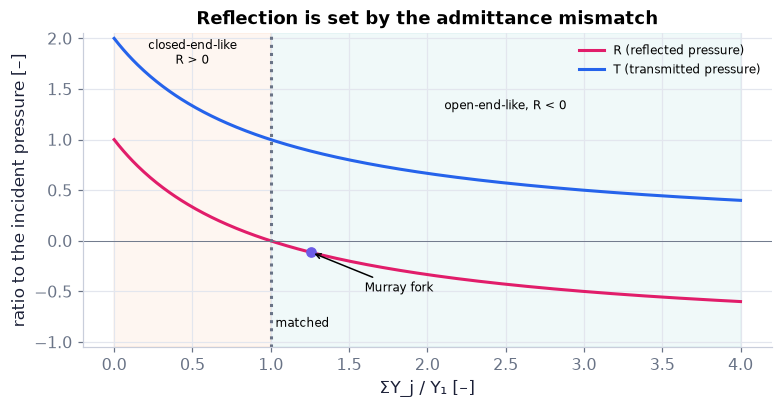

In [114]:
s_ = np.linspace(0, 4, 400)                                    # ΣY_j/Y1
fig, ax = plt.subplots(figsize=(7, 3.6))   # a new figure and its axes
ax.plot(s_, (1 - s_)/(1 + s_), color=COLORS["rose"], lw=2, label="R (reflected pressure)")   # curve: R (reflected pressure)
ax.plot(s_, 2/(1 + s_), color=COLORS["blue"], lw=2, label="T (transmitted pressure)")   # curve: T (transmitted pressure)
ax.axhline(0, color=COLORS["muted"], lw=0.6); ax.axvline(1, color=COLORS["muted"], ls=":")   # a reference line
ax.axvspan(0, 1, color=COLORS["orange"], alpha=0.06); ax.axvspan(1, 4, color=COLORS["teal"], alpha=0.06)   # a shaded band
ax.text(0.5, 1.75, "closed-end-like\nR > 0", ha="center", fontsize=8); ax.text(2.5, 1.3, "open-end-like, R < 0", ha="center", fontsize=8)   # a text label on the plot
ax.text(1.03, -0.85, "matched", fontsize=8)   # a text label on the plot
ax.plot(2**(1/3), (1 - 2**(1/3))/(1 + 2**(1/3)), "o", color=COLORS["accent"]); ax.annotate("Murray fork", (2**(1/3), -0.115), xytext=(1.6, -0.5), arrowprops=dict(arrowstyle="->"), fontsize=8)   # purple dot: a Murray fork, ΣY/Y₁ = 2^{1/3}
ax.set(xlabel="ΣY_j / Y₁ [–]", ylabel="ratio to the incident pressure [–]", ylim=(-1.05, 2.05), title="Reflection is set by the admittance mismatch")   # axis labels, limits and title
ax.legend(fontsize=8, loc="upper right")   # the legend
savefig(fig, "ch16", "c13_reflection"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** R (rose) and T (blue) of $\mathrm R=\dfrac{p_R}{p_I}=\dfrac{Y_1-\sum Y_j}{Y_1+\sum Y_j},\ \ \mathrm T=\dfrac{p_{Tj}}{p_I}=\dfrac{2Y_1}{Y_1+\sum Y_j}$ (16.153) against the daughters' total admittance relative to the parent's, with the
closed-end-like and open-end-like regimes shaded and our Murray fork marked.

**How to read it.** At ΣY_j = Y₁ there is no echo. Daughters that accept less flow than the parent (left) reflect an upright echo and
transmit a pressure up to twice the incident one; daughters that accept more (right) reflect an inverted echo. The Murray
fork sits close to matched.

**What would change if…** …the daughters were stiffer than the parent (larger c_j)? Their admittance A/(ρc) falls, the point moves left and
the echo becomes upright — one reason pressure pulses grow toward the periphery.

📝 **Note.** **N79 [B]** In the parent the pressure and flux are $\dfrac p{P_I}=f\left(t-\dfrac x{c_1}\right)+\dfrac{P_R}{P_I}f\left(t+\dfrac x{c_1}\right)$ (16.159) and $Q=Y_1P_I\left[f\left(t-\dfrac x{c_1}\right)-\dfrac{P_R}{P_I}f\left(t+\dfrac x{c_1}\right)\right]$ (16.160): once the echo returns, p and Q no longer share a
shape. (The book writes the reflected shape as f; it equals f here only because R does not depend on frequency — slip
S17.)

In [115]:
fpulse = lambda s: np.exp(-(s/0.05)**2)                       # time shape of the incident pulse (width 0.05 s)
ts = np.linspace(-0.1, 0.4, 6)                                # instants [s]
wf = [ch16.junction_waveforms(-0.5, tt, fpulse, 5.0, Rj) for tt in ts]   # (16.159)-(16.160) at x = −0.5 m in the parent
print("p/P_I:", np.round([w_["p"] for w_ in wf], 3)); print("Q/(Y1 P_I):", np.round([w_["Q"] for w_ in wf], 3))   # print the result

p/P_I: [ 1.     0.016 -0.123 -0.002 -0.    -0.   ]
Q/(Y1 P_I): [1.    0.021 0.123 0.002 0.    0.   ]


**What does this show?** At the probe the incident pulse passes first (p and Q equal), then the inverted echo
returns: p dips by R while Q rises by −R — the two traces part ways.

📝 **Note.** **N81 [B]** Three regimes (trap T18):

| Daughters | R | Name |
|---|---|---|
| ΣY_j < Y₁ | R > 0 | closed-end-like — the pressure rises at the fork (a closed end, ΣY = 0, doubles it: R = +1) |
| ΣY_j = Y₁ | 0 | matched |
| ΣY_j > Y₁ | R < 0 | open-end-like |

Reflections from the leg arteries help make the aortic pressure peak; repeated forks make a tree.

In [116]:
nfr = 20 if FAST else 30                                      # frames (the reader steps through them)
net = ch16.network_pulse_run(1.0, [1.0, 1.0], 5.0, [5.0, 5.0], 1.0, [0.64, 0.64], width=0.03, n_frames=nfr)   # grid run (ours)
xp_, xd_ = net["x"]["parent"], net["x"]["daughters"][0]       # parent x < 0, a daughter x > 0 [m]
fig, (ax, bx) = plt.subplots(1, 2, figsize=(8.5, 3.0), gridspec_kw=dict(width_ratios=[1.6, 1]))   # a new figure and its axes
(lp,) = ax.plot([], [], color=COLORS["orange"], lw=2, label="parent"); (ld,) = ax.plot([], [], color=COLORS["teal"], lw=2, label="each daughter")   # an empty line, filled in frame by frame by update()
ax.axvline(0, color=COLORS["muted"], ls=":"); ax.axvline(net["x_probe"], color=COLORS["accent"], ls="--", lw=0.8)   # a reference line
ax.set(xlim=(-1, 1), ylim=(-0.3, 1.1), xlabel="x [m] (fork at 0)", ylabel="p / P_I", title="A pulse meets a fork (grid run, ours)"); ax.legend(fontsize=7)   # axis labels, limits and title
(pp,) = bx.plot([], [], color=COLORS["orange"], label="p at the probe"); (qq,) = bx.plot([], [], color=COLORS["blue"], label="Q/Y₁ at the probe")   # an empty line, filled in frame by frame by update()
bx.set(xlim=(0, net["probe_t"][-1]), ylim=(-0.3, 1.3), xlabel="t [s]", title="probe (dashed line)"); bx.legend(fontsize=7)   # axis labels, limits and title
def update(i):                                                # frame i
    lp.set_data(xp_, net["p_parent"][i]); ld.set_data(xd_, net["p_daughters"][0][i])   # move the artist to this frame
    k = np.searchsorted(net["probe_t"], net["t"][i])          # how many probe samples have been recorded by this frame (P395)
    pp.set_data(net["probe_t"][:k], net["probe_p"][:k]); qq.set_data(net["probe_t"][:k], net["probe_Q"][:k]/1.0)   # move the artist to this frame
    return lp, ld, pp, qq   # what this function hands back
fig.canvas.draw(); fig.set_layout_engine("none")              # lay the figure out once, then freeze it (faster frames)
show_animation(animate(update, frames=nfr, fig=fig, interval=150), player="frames")   # render the frames and embed the player
print(f"grid R = {net['R_measured']:.4f}, theory {net['R_theory']:.4f}")   # print the result

grid R = -0.1228, theory -0.1228


**Figure A4** (frame player — step through it). **What you see.** A pressure pulse runs down the parent (orange) into two
equal daughters (teal); at the fork a small inverted echo returns while 88 % of the pressure goes on in each daughter; the
right panel records pressure and flow at the probe. **How to read it.** Stop on the frame where the echo reaches the probe:
the pressure dips below zero while the flow rises above zero — the echo carries flow backward with a negative pressure.
**What would change if…** the daughters were narrower (ΣY < Y₁): the echo would come back upright.

#### 🎮 Interactive: When does a fork send the pulse back?

**Why interactive rather than a static figure:** changing the daughters' radius or stiffness you watch the echo shrink, vanish and flip while the energy bars always add
to the incident pulse — the sign change of the echo is a motion through zero, best seen live.

Start with the **Walkthrough**; the **Explain** tab works every number out with your settings, and the **Derivation** tab (where there is one) steps through the same derivation as above. R and T are pressure ratios; the energy bars use R² and (ΣY_j/Y₁)T², which always add to 1.

**What to try:**
- Find the radius ratio with no echo.
- Make the daughters narrow: the echo comes back upright.
- Watch the probe: p and Q part ways when the echo arrives.

In [117]:
show_viz("ch16", "junction_reflection")   # full-width explainer; ⤢ Full screen for more room

[explainer ch16/junction_reflection]

**What would change if…** …the vessel curved instead of branching? A bend does not reflect a long pulse much, but it reshapes the steady flow inside
it — C14.

### 🧩 A bend makes two vortices: Dean's expansion $w=\sum\kappa^{2n}w_n,\ \ \psi=\kappa\sum\kappa^{2n}\psi_n$ (16.177) `C14`

*The question:* What does a bend do to the flow inside a pipe?

📝 **Note.** **N82 [C]** The scene: the aortic arch turns the blood through half a circle (and out of plane). Curvature distorts the
profile, sets up secondary motions, raises dissipation and delays turbulence; Ch. 11 (N69) named Dean flow among the
centrifugal instabilities.

#### The problem in plain words

Stir tea and the leaves gather in the middle of the bottom — a secondary flow. In a bent pipe the fast fluid at the centre
is flung toward the outside of the bend harder than the slow fluid near the walls; it piles up at the outer wall and returns
along the walls: **two counter-rotating vortices, and the fastest axial flow sits off-centre, toward the outer wall**.

#### The idea

```
centre of the pipe:  fast fluid ──► strong centrifugal push ──► flung toward the outer wall
near the walls:      slow fluid ──► weak push              ──► squeezed back inward along the walls
result: two counter-rotating cells (Dean vortices), fastest axial flow shifted toward the outer wall
```

**A bend sorts the fluid by speed**: the centrifugal push grows with the square of the speed, so the fast core wins
and the slow wall fluid gives way. How strong the secondary flow is depends on the speed and on how tight the bend is,
combined in one number defined below; the book solves the flow as a series in that number, $w=\sum\kappa^{2n}w_n,\ \ \psi=\kappa\sum\kappa^{2n}\psi_n$ (16.177).

> 📎 **Primer — toroidal coordinates of a curved pipe.** `P389` · Inside a pipe bent into a circle of radius R: r and α locate a point in the
cross-section (α = 0 toward the outside of the bend here), s runs along the centreline. The axial speed w is carried round
the bend, so it feels a centrifugal acceleration w²/R pointing outward — that is the term $-w^2\cos\alpha$ of the radial
momentum equation of the curved pipe, written out in full in N86 below (trap T2: this α is an angle).

In [118]:
w, R = 0.3, 0.05                               # axial speed [m/s], bend radius [m]
print(w**2/R)                                  # 1.8 m/s²: a fifth of g

1.7999999999999998


📝 **Note.** **N83 [B]** The secondary flow forms Dean vortices; for a developed flow the axial maximum skews to the outer wall (for a
potential-vortex entrance flow, to the inner wall); heart–lung machines use coiled tubes for mixing.

```
            inner wall (α = π)
          ╭───────────────╮
         │  ↖    ⟲    ↙   │      upper cell turns one way,
         │ ←  ←  ←  ←  ←  │      fluid returns along the walls
  axis ──│ →  →  →  → ●→  │──    the core is flung outward (●: fastest axial flow)
         │ ←  ←  ←  ←  ←  │
         │  ↙    ⟳    ↖   │      lower cell the other way
          ╰───────────────╯
            outer wall (α = 0) is on the right of the bend
```

**N84 [B]** Curvature ratio $\delta=\dfrac aR$ (16.164) — not the cell-free layer δ of C05 (trap T2).

In [119]:
print(ch16.curvature_ratio(12.5e-3, 50e-3))                  # (16.164): δ = a/R for our illustrative arch: 0.25

0.25


📝 **Note.** **N85 [B]** The book rescales so that centrifugal, inertial and viscous terms are the same size (√δ scaling) and splits the
pressure $p=p_0(s)+\delta p_1(r,\alpha,s)+\dots$ (16.165) (stated). **N86 [B]** The resulting equations, stated (u, v the secondary velocities along r and α, w the
axial one, $p_1$ the cross-section pressure, all rescaled) — continuity, radial and angular momentum, axial momentum and
the wall conditions:

$$ \begin{array}{l}\dfrac{\partial u}{\partial r}+\dfrac ur+\dfrac1r\dfrac{\partial v}{\partial\alpha}=0\qquad\text{(16.166)} \\[6pt] u\dfrac{\partial u}{\partial r}+\dfrac vr\dfrac{\partial u}{\partial\alpha}-\dfrac{v^2}r-w^2\cos\alpha=-\dfrac{\partial p_1}{\partial r}-\dfrac2\kappa\dfrac1r\dfrac{\partial}{\partial\alpha}\left(\dfrac{\partial v}{\partial r}+\dfrac vr-\dfrac1r\dfrac{\partial u}{\partial\alpha}\right)\qquad\text{(16.167)} \\[6pt] u\dfrac{\partial v}{\partial r}+\dfrac vr\dfrac{\partial v}{\partial\alpha}+\dfrac{uv}r+w^2\sin\alpha=-\dfrac1r\dfrac{\partial p_1}{\partial\alpha}+\dfrac2\kappa\dfrac{\partial}{\partial r}\left(\dfrac{\partial v}{\partial r}+\dfrac vr-\dfrac1r\dfrac{\partial u}{\partial\alpha}\right)\qquad\text{(16.168)} \\[6pt] u\dfrac{\partial w}{\partial r}+\dfrac vr\dfrac{\partial w}{\partial\alpha}=-\dfrac{\partial p_0}{\partial s}+\dfrac2\kappa\left(\dfrac{\partial^2w}{\partial r^2}+\dfrac1r\dfrac{\partial w}{\partial r}+\dfrac1{r^2}\dfrac{\partial^2w}{\partial\alpha^2}\right)\qquad\text{(16.169)} \\[6pt] u=v=w=0\ \text{at}\ r=1,\quad\text{no singularity at}\ r=0\qquad\text{(16.170)}\end{array} $$

The one term that drives everything is the centrifugal push $-w^2\cos\alpha$ in the radial equation (and its partner
$w^2\sin\alpha$ in the angular one): without the axial flow w there is no secondary flow. **N88 [B]** A stream function for the secondary flow:
$u=\dfrac1r\dfrac{\partial\psi}{\partial\alpha},\ \ v=-\dfrac{\partial\psi}{\partial r}$ (16.172) (Ch. 4's stream function), and the axial equation $\nabla_1^2w-\dfrac\kappa2\dfrac{\partial p_0}{\partial s}=\dfrac\kappa{2r}\left(\dfrac{\partial\psi}{\partial\alpha}\dfrac{\partial w}{\partial r}-\dfrac{\partial\psi}{\partial r}\dfrac{\partial w}{\partial\alpha}\right)$ (16.173) with $p_0=-Gs$. **N89 [B]** The vorticity equation
$\dfrac2\kappa\nabla_1^4\psi+\dfrac1r\left(\dfrac{\partial\psi}{\partial r}\dfrac{\partial}{\partial\alpha}-\dfrac{\partial\psi}{\partial\alpha}\dfrac{\partial}{\partial r}\right)\nabla_1^2\psi=-2w\left(\sin\alpha\dfrac{\partial w}{\partial r}+\dfrac{\cos\alpha}r\dfrac{\partial w}{\partial\alpha}\right)$ (16.174, advection sign corrected — S34) with $\nabla_1^2=\dfrac{\partial^2}{\partial r^2}+\dfrac1r\dfrac{\partial}{\partial r}+\dfrac1{r^2}\dfrac{\partial^2}{\partial\alpha^2}$ (16.175) and $\psi=\dfrac{\partial\psi}{\partial r}=w=0\ \text{at}\ r=1$ (16.176). Read its right side in words: the axial speed's own gradient drives the secondary
vorticity.

> ⚠️ **slip S34 — the book prints** $\dfrac2\kappa\nabla_1^4\psi-\dfrac1r\left(\dfrac{\partial\psi}{\partial r}\dfrac{\partial}{\partial\alpha}-\dfrac{\partial\psi}{\partial\alpha}\dfrac{\partial}{\partial r}\right)\nabla_1^2\psi=-2w\left(\sin\alpha\dfrac{\partial w}{\partial r}+\dfrac{\cos\alpha}r\dfrac{\partial w}{\partial\alpha}\right)$ (16.174, as printed); **the correct form is** $\dfrac2\kappa\nabla_1^4\psi+\dfrac1r\left(\dfrac{\partial\psi}{\partial r}\dfrac{\partial}{\partial\alpha}-\dfrac{\partial\psi}{\partial\alpha}\dfrac{\partial}{\partial r}\right)\nabla_1^2\psi=-2w\left(\sin\alpha\dfrac{\partial w}{\partial r}+\dfrac{\cos\alpha}r\dfrac{\partial w}{\partial\alpha}\right)$ (16.174, advection sign corrected — S34)
>
> Found when we checked the algebra: eliminating the pressure $p_1$ from the radial and
angular momentum equations of N86 — the ones carrying $-w^2\cos\alpha$ (16.167) and $+w^2\sin\alpha$ (16.168) — with
$u=\dfrac1r\dfrac{\partial\psi}{\partial\alpha},\ \ v=-\dfrac{\partial\psi}{\partial r}$ (16.172) gives **+** in front of the advection term. ψ₀, w₁ and the K² coefficient 1541/50400
are unchanged (the term first enters at order κ²); the K⁴ coefficient of $\dfrac{Q}{\pi a^2\bar W}=1-0.0306\left(\dfrac K{576}\right)^2+0.0120\left(\dfrac K{576}\right)^4+O(K^6)$ (16.178) becomes
6471982981/542442700800 = 0.0119312 instead of the 0.0121130 the printed sign gives. The book's own 0.0120 sits between
them; we show 0.0119312 beside it (`ch16.DEAN_C4_DERIVED`).

📝 **Note.** **N87 [B]** The Dean number $\kappa=\sqrt\delta\,\dfrac{2a\bar W_0}\nu$ (16.171). **Which Dean number?** (trap T8)

| Name | Definition | Relation |
|---|---|---|
| κ | $\kappa=\sqrt\delta\,\dfrac{2a\bar W_0}\nu$ (16.171) | — |
| K | used in $\dfrac{Q}{\pi a^2\bar W}=1-0.0306\left(\dfrac K{576}\right)^2+0.0120\left(\dfrac K{576}\right)^4+O(K^6)$ (16.178) | $K=2\kappa^2$ |
| D | $D=\sqrt{2\delta}\,\dfrac{\hat Ga^2}{\mu}\dfrac a\nu$ (16.179) | $K=D^2/16$ |
| De (literature) | $Re\sqrt\delta$ with the diameter Re | = κ |

With the chapter's diameter Re, (16.171) reads $\kappa=\sqrt\delta\,Re$ (the book writes $\sqrt\delta\,2Re$ with a radius
Re — slip S18).

In [120]:
kap = ch16.dean_number(0.25, 5e-3, 12.5e-3, 3.3e-6, convention="kappa")   # (16.171) at W̄ = 5 mm/s in our arch
print(f"kappa = {kap:.3f}, K = {ch16.dean_number(0.25, 5e-3, 12.5e-3, 3.3e-6, convention='K'):.1f}, D = {ch16.dean_number(0.25, 5e-3, 12.5e-3, 3.3e-6, convention='D'):.2f}")   # print the result
print("K = 576 is D =", ch16.dean_convert(576.0, from_="K", to="D"))   # 96

kappa = 18.939, K = 717.4, D = 107.14
K = 576 is D = 96.0


> 📎 **Primer — a regular perturbation series.** `P391` · When a small parameter ε appears in an equation, write the answer as
$f=f_0+\varepsilon f_1+\varepsilon^2f_2+\dots$, put it in, and collect equal powers of ε: each power gives a simpler equation,
solved in turn. Ch. 2's orders of smallness (P68) only dropped terms; here we keep and solve them.

In [121]:
eps, x = sp.symbols('epsilon x')                # a small parameter and the unknown
root = sp.solve(x**2 + eps*x - 1, x)[1]          # the root that is x = 1 at eps = 0 (exact, with a square root)
print(sp.series(root, eps, 0, 3))                 # 1 − eps/2 + eps²/8 + …: the terms a perturbation series finds one order at a time

1 - epsilon/2 + epsilon**2/8 + O(epsilon**3)


> 📎 **Primer — the biharmonic operator in polar coordinates.** `P390` · $\nabla^4=\nabla^2\nabla^2$. On $r^n\sin\alpha$ the polar
Laplacian gives $(n^2-1)r^{n-2}\sin\alpha$, so ∇⁴ lowers the power by four; a polynomial forcing is matched term by term
(undetermined coefficients), and the terms ∇⁴ kills (r, r³) carry the boundary conditions. Ch. 8's Stokes operator E² (P199)
is a different operator.

In [122]:
r, a = sp.symbols('r alpha', positive=True)     # radius and angle
lap = lambda F: sp.diff(F, r, 2) + sp.diff(F, r)/r + sp.diff(F, a, 2)/r**2   # polar Laplacian
print(sp.simplify(lap(lap(r**5*sp.sin(a)))))    # 192*r*sin(alpha)

192*r*sin(alpha)


**Integration by parts** (used in step 13 below; Ch. 9): $\int_0^1 f\,g'\,dr=[fg]_0^1-\int_0^1 f'g\,dr$ — it moves a
derivative from one factor to the other.

#### 🧮 Derivation — Dean's leading orders and the flux coefficient `D27` ★★★ (Eq. 16.178: $\dfrac{Q}{\pi a^2\bar W}=1-0.0306\left(\dfrac K{576}\right)^2+0.0120\left(\dfrac K{576}\right)^4+O(K^6)$)

**What we want to show.** Solve the curved-pipe equations order by order for a slow flow, find the secondary vortices and the skewed axial flow, and reproduce the book's flux coefficient 0.0306.

**Assumptions.** δ ≪ 1 (the equations), κ small (the series); fixed pressure gradient.

**The plan.**

1. Order κ⁰: Poiseuille.
2. Leading ψ: the vortex pair.
3. Order κ²: the skewed axial correction.
4. Order κ⁴: the mean change and the flux.

**Tools we use** (each explained before this point): a regular perturbation series (P391, primer in C14) · toroidal coordinates (P389, primer in C14) · the biharmonic operator in polar coordinates and polynomial solutions (P390, primer in C14) · sympy (P40) · integration by parts

**We start from**

$$ \begin{array}{l}\nabla_1^2w-\dfrac\kappa2\dfrac{\partial p_0}{\partial s}=\dfrac\kappa{2r}\left(\dfrac{\partial\psi}{\partial\alpha}\dfrac{\partial w}{\partial r}-\dfrac{\partial\psi}{\partial r}\dfrac{\partial w}{\partial\alpha}\right)\qquad\text{(16.173)} \\[6pt] \dfrac2\kappa\nabla_1^4\psi+\dfrac1r\left(\dfrac{\partial\psi}{\partial r}\dfrac{\partial}{\partial\alpha}-\dfrac{\partial\psi}{\partial\alpha}\dfrac{\partial}{\partial r}\right)\nabla_1^2\psi=-2w\left(\sin\alpha\dfrac{\partial w}{\partial r}+\dfrac{\cos\alpha}r\dfrac{\partial w}{\partial\alpha}\right)\qquad\text{(16.174, advection sign corrected - S34)} \\[6pt] \psi=\dfrac{\partial\psi}{\partial r}=w=0\ \text{at}\ r=1\qquad\text{(16.176)} \\[6pt] w=\sum\kappa^{2n}w_n,\ \ \psi=\kappa\sum\kappa^{2n}\psi_n\qquad\text{(16.177)}\end{array} $$

*In words:* The axial and vorticity equations of the curved pipe, written with the advection sign of (16.174) corrected (slip S34, found when we re-derived it: eliminating the pressure from the two momentum equations gives +), the wall conditions and Dean's series in κ.

---

**Step 1 of 14 — Insert the series; keep order κ⁰ of (16.173).**

$$ \nabla_1^2w_0=\dfrac\kappa2\dfrac{\partial p_0}{\partial s}\equiv-8 $$

- *Why we can do this:* P391: the right side of $\nabla_1^2w-\dfrac\kappa2\dfrac{\partial p_0}{\partial s}=\dfrac\kappa{2r}\left(\dfrac{\partial\psi}{\partial\alpha}\dfrac{\partial w}{\partial r}-\dfrac{\partial\psi}{\partial r}\dfrac{\partial w}{\partial\alpha}\right)$ (16.173) starts at κ·κ; the gradient term is a constant ($p_0=-Gs$), scaled so the straight-pipe mean speed is 1.
- *In words:* At lowest order the bend does nothing.

---

**Step 2 of 14 — Solve for the straight-pipe flow.**

$$ w_0=2(1-r^2) $$

- *Why we can do this:* Axisymmetric: $\frac1r(rw_0')'=-8$ gives $w_0=-2r^2+C$; w = 0 at r = 1 $\psi=\dfrac{\partial\psi}{\partial r}=w=0\ \text{at}\ r=1$ (16.176) gives C = 2; its mean $\int_0^12(1-r^2)2r\,dr=1$.
- *In words:* Poiseuille, mean speed 1, maximum 2.

---

**Step 3 of 14 — Keep the leading order of (16.174).**

$$ 2\nabla_1^4\psi_0=-2w_0\left(\sin\alpha\dfrac{\partial w_0}{\partial r}+\dfrac{\cos\alpha}r\dfrac{\partial w_0}{\partial\alpha}\right) $$

- *Why we can do this:* $(2/\kappa)\nabla^4(\kappa\psi_0)=2\nabla^4\psi_0$; the nonlinear ψψ term is O(κ²), smaller.
- *In words:* The axial flow's centrifugal push drives the secondary flow.

---

**Step 4 of 14 — Evaluate the forcing.**

$$ \nabla_1^4\psi_0=8r(1-r^2)\sin\alpha $$

- *Why we can do this:* $\partial w_0/\partial r=-4r$, $\partial w_0/\partial\alpha=0$: $-2\cdot2(1-r^2)\sin\alpha\cdot(-4r)=16r(1-r^2)\sin\alpha$; divide by 2.
- *In words:* Strongest where the fast fluid is flung hardest.

---

**Step 5 of 14 — Separate the angle.**

$$ \psi_0=f(r)\sin\alpha,\quad\nabla_1^2(f\sin\alpha)=\left(f''+\dfrac{f'}r-\dfrac f{r^2}\right)\sin\alpha $$

- *Why we can do this:* The forcing is ∝ sin α and $\partial^2_\alpha\sin\alpha=-\sin\alpha$ (P390).
- *In words:* One radial function to find.

---

**Step 6 of 14 — Try an odd polynomial.**

$$ f=c_1r+c_3r^3+c_5r^5+c_7r^7 $$

- *Why we can do this:* P390: $\nabla_1^2(r^n\sin\alpha)=(n^2-1)r^{n-2}\sin\alpha$, so ∇⁴ lowers the power by 4; the forcing has r and r³, so powers up to 7; odd powers keep ψ₀ smooth on the axis.
- *In words:* Undetermined coefficients.

---

**Step 7 of 14 — Match the forcing and the wall.**

$$ c_5=\tfrac1{24},\ c_7=-\tfrac1{144};\quad c_1=\tfrac1{36},\ c_3=-\tfrac1{16} $$

- *Why we can do this:* $\nabla^4r^5\to192r$, $\nabla^4r^7\to1152r^3$: 192c₅ = 8, 1152c₇ = −8; r and r³ are killed by ∇⁴ and fixed by $f(1)=f'(1)=0$ (16.176).
- *In words:* Four numbers, four conditions.

---

**Step 8 of 14 — Factor the result.**

$$ \psi_0=\dfrac{r}{144}(1-r^2)^2(4-r^2)\sin\alpha\ \text{(ours)} $$

- *Why we can do this:* $144f=4r-9r^3+6r^5-r^7=r(1-r^2)^2(4-r^2)$ (multiply out to check). Factoring a polynomial changes nothing; the factored form shows at once that ψ₀ and its slope vanish at r = 1.
- *In words:* Two counter-rotating cells, one on each side of the plane of the bend.

---

**Step 9 of 14 — Keep order κ² of (16.173).**

$$ \nabla_1^2w_1=\dfrac1{2r}\left(\dfrac{\partial\psi_0}{\partial\alpha}\dfrac{\partial w_0}{\partial r}-\dfrac{\partial\psi_0}{\partial r}\dfrac{\partial w_0}{\partial\alpha}\right) $$

- *Why we can do this:* The right side of $\nabla_1^2w-\dfrac\kappa2\dfrac{\partial p_0}{\partial s}=\dfrac\kappa{2r}\left(\dfrac{\partial\psi}{\partial\alpha}\dfrac{\partial w}{\partial r}-\dfrac{\partial\psi}{\partial r}\dfrac{\partial w}{\partial\alpha}\right)$ (16.173) with ψ = κψ₀ and w = w₀ is κ² times this bracket.
- *In words:* The secondary flow carries fast fluid across the section.

---

**Step 10 of 14 — Evaluate the right side.**

$$ \nabla_1^2w_1=-2f(r)\cos\alpha $$

- *Why we can do this:* $\partial\psi_0/\partial\alpha=f\cos\alpha$, $\partial w_0/\partial r=-4r$, $\partial w_0/\partial\alpha=0$.
- *In words:* Negative where cos α > 0.

---

**Step 11 of 14 — Solve with $w_1(1)=0$.**

$$ w_1=+\dfrac{r(1-r^2)(19-21r^2+9r^4-r^6)}{5760}\cos\alpha\ \text{(ours)} $$

- *Why we can do this:* $w_1=g(r)\cos\alpha$ with $g''+g'/r-g/r^2=-2f$, an odd polynomial to r⁹ (sympy in the cell). Positive where cos α > 0 — **plus sign** (the fastest fluid moves to the outer side).
- *In words:* The fast core is pushed toward α = 0, the outer wall.

---

**Step 12 of 14 — Find the part of $w_2$ that carries flux.**

$$ \dfrac1r\dfrac{d}{dr}\left(r\dfrac{d\overline{w_2}}{dr}\right)=\dfrac{(fg)'}{4r} $$

- *Why we can do this:* Only the α-average $\overline{w_2}$ changes the flux. Averaging $\nabla_1^2w-\dfrac\kappa2\dfrac{\partial p_0}{\partial s}=\dfrac\kappa{2r}\left(\dfrac{\partial\psi}{\partial\alpha}\dfrac{\partial w}{\partial r}-\dfrac{\partial\psi}{\partial r}\dfrac{\partial w}{\partial\alpha}\right)$ (16.173)'s right side at κ⁴ over α: cos²α and sin²α give ½, the ψ₁ terms (∝ cos α, cos 2α) give 0: $\frac1{2r}\cdot\frac12(fg'+f'g)$.
- *In words:* The mean correction, from ψ₀ and w₁ alone.

---

**Step 13 of 14 — Integrate over the section.**

$$ \displaystyle\int_0^1\overline{w_2}\,2r\,dr=-\dfrac14\int_0^1rfg\,dr=-\dfrac14\cdot\dfrac{1541}{1045094400} $$

- *Why we can do this:* One integration gives $r\overline{w_2}'=fg/4$ (regular on the axis); then by parts $\int\overline{w_2}2r\,dr=[r^2\overline{w_2}]_0^1-\int r^2\overline{w_2}'dr$, with $\overline{w_2}(1)=0$; sympy gives the exact integral.
- *In words:* The bend lowers the flux at order κ⁴.

---

**Step 14 of 14 — Convert to Dean's K.**

$$ \dfrac{Q}{\pi a^2\bar W}=1-\dfrac{1541}{50400}\left(\dfrac K{576}\right)^2\ \text{,}\ \dfrac{1541}{50400}=0.030575\ \text{(16.178)} $$

- *Why we can do this:* The flux ratio is $1+\kappa^4\int\overline{w_2}2r\,dr$; K = 2κ² so κ⁴ = K²/4; $\dfrac{576^2\cdot1541}{16\cdot1045094400}=\dfrac{1541}{50400}$.
- *In words:* The book's 0.0306, reproduced exactly.

---

**Result**

$$ \begin{array}{l}\psi_0=\dfrac{r}{144}(1-r^2)^2(4-r^2)\sin\alpha,\qquad w_1=+\dfrac{r(1-r^2)(19-21r^2+9r^4-r^6)}{5760}\cos\alpha\qquad\text{(ours)}\\[6pt]\dfrac{Q}{\pi a^2\bar W}=1-\underbrace{0.0306}_{=1541/50400}\left(\dfrac K{576}\right)^2+\underbrace{0.0120}_{\text{printed; }0.0119312\text{ with S34}}\left(\dfrac K{576}\right)^4+O(K^6)\qquad\text{(16.178)}\end{array} $$

*In words:* The vortex pair, the outward-skewed axial correction and the flux coefficient 1541/50400 = 0.030575 of $\dfrac{Q}{\pi a^2\bar W}=1-0.0306\left(\dfrac K{576}\right)^2+0.0120\left(\dfrac K{576}\right)^4+O(K^6)$ (16.178); the K⁴ coefficient is printed 0.0120, and 0.0119312 once the advection sign of $\dfrac2\kappa\nabla_1^4\psi+\dfrac1r\left(\dfrac{\partial\psi}{\partial r}\dfrac{\partial}{\partial\alpha}-\dfrac{\partial\psi}{\partial\alpha}\dfrac{\partial}{\partial r}\right)\nabla_1^2\psi=-2w\left(\sin\alpha\dfrac{\partial w}{\partial r}+\dfrac{\cos\alpha}r\dfrac{\partial w}{\partial\alpha}\right)$ (16.174) is corrected (slip S34).

**What it means.** Curvature flings the fast core outward; it returns along the walls as two vortices; the flux falls only at order K², so gentle bends cost little — but the secondary flow mixes the blood and raises the wall shear on the outer side. Fails beyond small K (the series diverges; our reliability test `ch16.dean_series_reliability` asks that the K⁴ term stay below a quarter of the K² term).

**Check it.** ψ₀ = ∂ψ₀/∂r = 0 and w₁ = 0 at r = 1 ✓; **expect** ψ₀ is largest (0.00757) at r = 0.429; at K = 576 the axial maximum sits 0.187a toward the outer wall and Q/(πa²W̄) = 0.9814; the resistance ratio $\lambda=1+0.0306\left(\dfrac K{576}\right)^2-0.0110\left(\dfrac K{576}\right)^4$ (16.182) is its reciprocal (coefficient $0.0306^2-0.0120=-0.0111$). The sympy cell below re-runs the derivation's own steps (every line is commented); it prints `-8`; `-r*(r - 2)*(r - 1)**2*(r + 1)**2*(r + 2)/144`; `r*(r - 1)*(r + 1)*(r**6 - 9*r**4 + 21*r**2 - 19)/5760` (= the plus sign); `1541/1045094400`; `1541/50400` (1.2 s).

In [123]:
import sympy as sp                                                       # symbolic algebra
r, al = sp.symbols('r alpha', positive=True)                             # radius (a = 1) and the toroidal angle
lap = lambda F: sp.diff(F, r, 2) + sp.diff(F, r)/r + sp.diff(F, al, 2)/r**2   # ∇₁² of (16.175)
w0 = 2*(1 - r**2); print(lap(w0))                                        # steps 1–2: −8
c = sp.symbols('c1 c3 c5 c7'); f = c[0]*r + c[1]*r**3 + c[2]*r**5 + c[3]*r**7   # step 6
rhs = -2*w0*sp.sin(al)*sp.diff(w0, r)                                    # steps 3–4: right side of 2∇⁴ψ₀
eqs = sp.Poly(sp.expand((2*lap(lap(f*sp.sin(al))) - rhs)/sp.sin(al)), r).coeffs()   # coefficients of each power of r must vanish (step 7)
f = sp.factor(f.subs(sp.solve(list(eqs) + [f.subs(r, 1), sp.diff(f, r).subs(r, 1)], c)))   # step 7
print(f)                                                                 # step 8: r(1 − r²)²(4 − r²)/144
d = sp.symbols('d1 d3 d5 d7 d9'); g = sum(di*r**(2*i + 1) for i, di in enumerate(d))   # step 11 ansatz
rhs1 = sp.diff(f*sp.sin(al), al)*sp.diff(w0, r)/(2*r)                    # steps 9–10
eqs = sp.Poly(sp.simplify(sp.expand((lap(g*sp.cos(al)) - rhs1)/sp.cos(al))), r).coeffs()   # the same matching for w1 (step 11)
g = sp.factor(g.subs(sp.solve(list(eqs) + [g.subs(r, 1)], d)))           # w1 = g cos α
print(g)                                                                 # +r(1 − r²)(19 − 21r² + 9r⁴ − r⁶)/5760
I = sp.integrate(r*f*g, (r, 0, 1)); print(I)                             # step 13: 1541/1045094400
K = sp.symbols('K', positive=True)   # Dean's K
print(sp.nsimplify(((K**2/4)*I/4)/(K/576)**2))                           # step 14: 1541/50400

-8


-r*(r - 2)*(r - 1)**2*(r + 1)**2*(r + 2)/144


r*(r - 1)*(r + 1)*(r**6 - 9*r**4 + 21*r**2 - 19)/5760
1541/1045094400
1541/50400


📝 **Notes taught inside `D27`:** **N90 [B]** ψ₀ and w₁ (ours; **w₁ with the plus sign**, so the fast core sits toward the outer wall) and **N91 [B]** the flux
$\dfrac{Q}{\pi a^2\bar W}=1-0.0306\left(\dfrac K{576}\right)^2+0.0120\left(\dfrac K{576}\right)^4+O(K^6)$ (16.178) with its K² coefficient reproduced exactly as 1541/50400; its K⁴ coefficient is printed 0.0120, and 0.0119312 with
the advection sign of $\dfrac2\kappa\nabla_1^4\psi+\dfrac1r\left(\dfrac{\partial\psi}{\partial r}\dfrac{\partial}{\partial\alpha}-\dfrac{\partial\psi}{\partial\alpha}\dfrac{\partial}{\partial r}\right)\nabla_1^2\psi=-2w\left(\sin\alpha\dfrac{\partial w}{\partial r}+\dfrac{\cos\alpha}r\dfrac{\partial w}{\partial\alpha}\right)$ (16.174, advection sign corrected — S34) corrected (slip S34).

> ⚠️ **Common confusion (traps in `D27`):** The κ, K, D conventions (T8); ψ = ∂ψ/∂r = 0 at the wall; sin α forcing for ψ₀, cos α for w₁; α is an angle here (T2).

#### ✏️ Tiny example: the flux loss at K = 576

1. K/576 = 1.
2. Q/(πa²W̄) = 1 − 0.0306 + 0.0120 = **0.9814** (with the exact 1541/50400 and the printed 0.0120: 0.98142; with 0.0119312
   from slip S34: 0.98136).
3. The resistance ratio $\lambda=\dfrac{\lambda_c}{\lambda_s}=1+0.0306\left(\dfrac K{576}\right)^2-0.0110\left(\dfrac K{576}\right)^4+\dots$ (16.182): 1 + 0.0306 − 0.0110 = 1.0196.
4. In D: K = D²/16 gives D = 96, and $\dfrac Q{\pi a^2\bar W}=1-0.0306\left(\dfrac D{96}\right)^4+0.0120\left(\dfrac D{96}\right)^8+O(D^{12})$ (16.181) gives the same numbers.
5. For our arch (a = 12.5 mm, δ = 0.25, ν = 3.3 × 10⁻⁶ m²/s) K = 576 needs a mean speed of only W̄ = κν/(2a√δ) = 16.97 ×
   3.3 × 10⁻⁶/(2 × 0.0125 × 0.5) ≈ **4.5 mm/s** — the series is a slow-flow theory; real arch flows are far beyond it.

In [124]:
r_, al_ = np.array([0.5]), np.array([0.0])                   # a point halfway out on the outer side
print(ch16.dean_secondary_streamfunction(r_, np.pi/2), ch16.dean_axial_correction(r_, al_))   # ψ0 at α = π/2; w1 = +0.00093 (plus sign)
print("w at r = 0.5, α = 0 and π, K = 288:", ch16.dean_axial_velocity(np.array([0.5, 0.5]), np.array([0.0, np.pi]), 288.0))   # print the result
Ks_ = np.array([100.0, 288.0, 576.0])                        # three Dean numbers K
print("flux ratio (book 0.0120):  ", [f"{v:.6f}" for v in ch16.dean_flux_ratio(Ks_, exact=True)])   # 1541/50400 and the printed K⁴ coefficient
print("flux ratio (S34 0.0119312):", [f"{v:.6f}" for v in ch16.dean_flux_ratio(Ks_, exact=True, exact_c4=True)], float(ch16.DEAN_C4_DERIVED))   # print the result
print("lambda(576) =", ch16.curved_resistance_ratio(576.0), "| reliability (ours):", ch16.dean_series_reliability(576.0, threshold=0.25))   # print the result

[0.0073] [0.0009]
w at r = 0.5, α = 0 and π, K = 288: [1.634 1.366]
flux ratio (book 0.0120):   ['0.999089', '0.993106', '0.981425']
flux ratio (S34 0.0119312): ['0.999089', '0.993102', '0.981356'] 0.011931182724839055
lambda(576) = 1.0196 | reliability (ours): {'ratio': 0.3921568627450981, 'reliable': False}


**What does the code above do?**

1. `dean_secondary_streamfunction` and `dean_axial_correction` are ψ₀ and w₁ of D27 (ours); w₁ is positive on the outer side
   (α = 0) — the plus sign.
2. `dean_axial_velocity` = $w_0+\kappa^2w_1$ with κ² = K/2: at K = 288 the outer point is faster than the inner one.
3. `dean_flux_ratio` evaluates $\dfrac{Q}{\pi a^2\bar W}=1-0.0306\left(\dfrac K{576}\right)^2+0.0120\left(\dfrac K{576}\right)^4+O(K^6)$ (16.178) with the exact 1541/50400; `exact_c4=True` uses the corrected K⁴ coefficient.
4. `dean_series_reliability` is our own criterion (the K⁴ term over the K² term, threshold ¼ passed explicitly): K = 576 is
   past it.

In [125]:
h_ = 1e-3                                                      # finite-difference step
rr, aa = 0.4, 0.7                                              # a test point (r, α)
lapf = lambda F, r, a: ((F(r + h_, a) - 2*F(r, a) + F(r - h_, a))/h_**2 + (F(r + h_, a) - F(r - h_, a))/(2*h_*r)   # ∂²F/∂r² + (1/r)∂F/∂r by centred differences …
                        + (F(r, a + h_) - 2*F(r, a) + F(r, a - h_))/(h_**2*r**2))   # … + (1/r²)∂²F/∂α²: the polar Laplacian (16.175)
psi0 = lambda r, a: ch16.dean_secondary_streamfunction(r, a)   # ψ0(r, α) from the module (D27 step 8)
lap_psi = lambda r, a: lapf(psi0, r, a)                        # ∇²ψ0
bih = lapf(lap_psi, rr, aa)                                    # ∇⁴ψ0 by nested differences
assert abs(bih - 8*rr*(1 - rr**2)*np.sin(aa)) < 1e-3           # D27 step 4: ∇⁴ψ0 = 8r(1 − r²) sin α
f_ = rr*(1 - rr**2)**2*(4 - rr**2)/144                         # f(r) of step 8
assert abs(lapf(ch16.dean_axial_correction, rr, aa) + 2*f_*np.cos(aa)) < 1e-6   # step 10: ∇²w1 = −2f cos α
R_, A_ = np.meshgrid(np.linspace(0, 1, 401), np.linspace(0, 2*np.pi, 401))    # a polar grid over the cross-section
w2d = ch16.dean_axial_velocity(R_, A_, 288.0)                  # w0 + κ² w1 at K = 288
flux = np.trapezoid(np.trapezoid(w2d*R_, R_[0], axis=1), A_[:, 0])/np.pi   # mean axial speed over the disc
assert abs(flux - 1) < 1e-4                                    # w1 carries no flux (cos α averages to 0): the loss is O(K²) and comes from w̄2 (step 12)
print(f"∇⁴ψ0 = {bih:.6f} vs {8*rr*(1 - rr**2)*np.sin(aa):.6f}; mean of w0 + κ²w1 = {flux:.6f}")   # print the result

∇⁴ψ0 = 1.731809 vs 1.731657; mean of w0 + κ²w1 = 0.999994


**What does the code above do?**

Finite differences of the polar Laplacian $\nabla_1^2=\dfrac{\partial^2}{\partial r^2}+\dfrac1r\dfrac{\partial}{\partial r}+\dfrac1{r^2}\dfrac{\partial^2}{\partial\alpha^2}$ (16.175) confirm the two equations D27 solves (∇⁴ψ₀ = 8r(1 − r²) sin α and
∇²w₁ = −2f cos α), and a 2-D trapezoid over the disc shows that w₀ + κ²w₁ still carries exactly the straight-pipe flux: the
flux loss is a K⁴-order effect of the mean correction w̄₂ (steps 12–14).

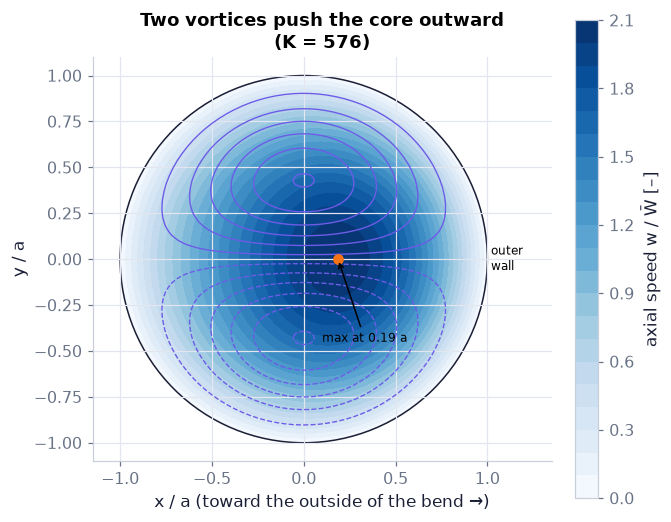

In [126]:
nr_, na_ = (40, 80) if FAST else (60, 120)                      # polar grid sizes
Rg, Ag = np.meshgrid(np.linspace(0, 1, nr_), np.linspace(0, 2*np.pi, na_))   # every (r, α) pair of the polar grid (np.meshgrid, C08)
Xg, Yg = Rg*np.cos(Ag), Rg*np.sin(Ag)                          # outer wall (α = 0) on the right
Wg = ch16.dean_axial_velocity(Rg, Ag, 576.0)                   # axial speed w0 + κ²w1 at K = 576 (units of W̄)
Pg = ch16.dean_secondary_streamfunction(Rg, Ag)                 # ψ0
fig, ax = plt.subplots(figsize=(6.0, 4.8))   # a new figure and its axes
cf = ax.contourf(Xg, Yg, Wg, levels=20, cmap="Blues"); fig.colorbar(cf, label="axial speed w / W̄ [–]")   # filled contours of the axial speed
ax.contour(Xg, Yg, Pg, levels=np.linspace(-0.0075, 0.0075, 12), colors=COLORS["accent"], linewidths=0.9)   # streamlines (contours of ψ0)
k_ = np.unravel_index(np.argmax(Wg), Wg.shape)                  # (row, column) of the largest w: np.argmax counts in the flattened array, np.unravel_index turns that count back into 2-D indices
ax.plot(Xg[k_], Yg[k_], "o", color=COLORS["orange"])           # orange dot: the fastest point of the cross-section
ax.annotate(f"max at {Xg[k_]:.2f} a", (Xg[k_], Yg[k_]), xytext=(0.1, -0.45), fontsize=8, arrowprops=dict(arrowstyle="->"))   # a label with an arrow
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=COLORS["ink"])); ax.text(1.02, 0, "outer\nwall", fontsize=8, va="center")   # a text label on the plot
ax.set(aspect="equal", xlim=(-1.15, 1.35), ylim=(-1.1, 1.1), xlabel="x / a (toward the outside of the bend →)", ylabel="y / a",   # axis labels, limits and title
       title="Two vortices push the core outward\n(K = 576)")   # the figure's title: its message
savefig(fig, "ch16", "c14_dean"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** The pipe's cross-section with the outer wall on the right: the axial speed $w_0+\kappa^2w_1$ at K = 576 (blue shading)
and the streamlines of the secondary flow ψ₀ (purple), two counter-rotating cells; the orange dot is the fastest point. To
find that point the code uses `np.unravel_index`: `np.argmax` of a 2-D array returns one count into the array read row by
row, and `np.unravel_index(count, shape)` converts it back into a (row, column) pair — e.g. count 5 in a 2 × 3 array is
(1, 2).

**How to read it.** The secondary flow crosses the middle toward the outer wall and returns along the top and bottom walls. It carries
fast fluid outward, so the axial maximum shifts toward the outer wall (here by about 0.19 a) — the plus sign of w₁.

**What would change if…** …K doubled? The shift doubles (it is proportional to κ² = K/2) while the vortex pattern keeps its shape — try F6.

📝 **Note.** **N92 [B]** With D: $\dfrac Q{\pi a^2\bar W}=1-0.0306\left(\dfrac D{96}\right)^4+0.0120\left(\dfrac D{96}\right)^8+O(D^{12})$ (16.181) — a change of variable, K = D²/16. In D's definition $D=\sqrt{2\delta}\,\dfrac{\hat Ga^2}{\mu}\dfrac a\nu$ (16.179) the book takes $\hat G=-\dfrac{8\mu\bar W}{a^2}$ (16.180, as printed);
with that sign D would be negative, so Ĝ must be read as the magnitude $8\mu\bar W/a^2$ of the gradient (slip S19). **N93 [B]** The
resistance ratio $\lambda=\dfrac{\lambda_c}{\lambda_s}=1+0.0306\left(\dfrac K{576}\right)^2-0.0110\left(\dfrac K{576}\right)^4+\dots$ (16.182) is the reciprocal of $\dfrac{Q}{\pi a^2\bar W}=1-0.0306\left(\dfrac K{576}\right)^2+0.0120\left(\dfrac K{576}\right)^4+O(K^6)$ (16.178) (0.0306² − 0.0120 = −0.0111 — checked below; the text swaps
"curved" and "straight" — slip S20). At large Dean numbers numerical solutions show thin wall layers, a wall shear growing
with D, and even four-vortex states — named only.

In [127]:
for K_ in (100.0, 300.0, 576.0):                              # three Dean numbers K
    print(K_, f"{1/ch16.dean_flux_ratio(K_) - ch16.curved_resistance_ratio(K_):.1e}")   # small: (16.182) is the reciprocal of (16.178) to the order kept
print(f"0.0306² − 0.0120 = {0.0306**2 - 0.0120:.4f}")         # the K⁴ coefficient of the reciprocal

100.0 -7.7e-08
300.0 -1.8e-05
576.0 -6.5e-04
0.0306² − 0.0120 = -0.0111


In [128]:
K_vals = list(np.linspace(0, 600, 25))                         # Dean numbers K (25 positions)
xs_ = np.linspace(-1, 1, 200)                                  # along the plane of symmetry (200 points: the axis itself is skipped): x = r cos α, α = 0 (outer) or π (inner)
def cuts(K_):                                                  # axial speed along two diameters, and the secondary flow
    r_ = np.abs(xs_); al_ = np.where(xs_ >= 0, 0.0, np.pi)   # x > 0 is the outer half (α = 0), x < 0 the inner half (α = π)
    w_sym = ch16.dean_axial_velocity(r_, al_, K_)              # across the bend (outer wall at +1)
    w_perp = ch16.dean_axial_velocity(r_, np.where(xs_ >= 0, np.pi/2, 3*np.pi/2), K_)   # perpendicular diameter
    u_, v_ = ch16.dean_secondary_velocity(r_, al_, K_)         # secondary velocity components on the symmetry line
    return {"w across the bend (outer → right)": (xs_, w_sym), "w on the perpendicular diameter": (xs_, w_perp),   # what this function hands back
            "secondary speed ×10 on the symmetry line": (xs_, 10*u_*np.cos(al_))}   # x-component: toward the outer wall
fig = slider_figure(cuts, "K", K_vals, xlabel="position across the pipe x / a [–]", ylabel="speed / W̄ [–]",   # build the slider figure (every position computed now)
                    title="The skew grows with K; the pattern keeps its shape", yrange=[-1.5, 2.6], active=24)   # the figure's title: its message
fig.show()   # display the figure

**Figure F6.** Slider: Dean's K from 0 to 600 (opens on 600). Instead of contour maps, three cuts that carry the same
information: the axial speed across the bend (outer wall at +1), the axial speed on the perpendicular diameter, and ten
times the secondary speed along the plane of symmetry. **How to read it.** At K = 0 both axial cuts are the same parabola
and there is no secondary flow; as K grows the cross-bend cut tilts toward the outer wall, linearly in K, while the
secondary flow grows as √K. **What would change if…** the series were pushed beyond about K = 460: our reliability
criterion says the next term is no longer small.

#### 🎮 Interactive: What does a bend do to the flow?

**Why interactive rather than a static figure:** the secondary flow is three-dimensional: orbit the bend to see the tracers corkscrew, drag K to grow the skew, and watch
the flux cursor approach the edge of the series — a helix is hard to read from any single picture.

Start with the **Walkthrough**; the **Explain** tab works every number out with your settings, and the **Derivation** tab (where there is one) steps through the same derivation as above. α is the angle around the cross-section (α = 0 at the outer wall); the Dean-number chips switch between κ, K = 2κ² and D = 4√2κ; the flux shows both the printed 0.0120 and the corrected 0.0119312.

**What to try:**
- Set K = 0 then 288: the bullseye slides outward.
- Orbit the 3-D view: helices.
- Switch the chip to D: 96 at K = 576.

In [129]:
show_viz("ch16", "dean_curved_pipe")   # full-width explainer; ⤢ Full screen for more room

[explainer ch16/dean_curved_pipe]

**What would change if…** …the vessel's wall could not hold its shape at all — a vein above the heart, an airway in a cough? Then the tube's area
depends on the flow: C15.

### 🧩 Floppy tubes choke at S = 1: $(1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]$ (16.204) `C15`

*The question:* Why can't you suck harder through a soft straw?

#### The problem in plain words

Suck hard on a soft drinking straw: past a point, sucking harder brings no more drink — the straw pinches shut near your
mouth. Veins above the heart, airways in a forced cough and an artery under a blood-pressure cuff do the same. **A tube whose
wall gives way can cap its own flow, however hard you pull.**

#### The idea

```
lower the outlet pressure ──► the tube narrows there ──► the blood speeds up (same flow through less area)
the speed u reaches the local wave speed c (S = u/c = 1) ──► no signal can travel back upstream
──► the upstream flow no longer hears the outlet: the flow is choked
```

**The speed index S = u/c plays the role of the Mach number of Ch. 15** (it is $S=\dfrac uc,\ \ \dfrac{dS^2}{S^2}=2\dfrac{du}u-2\dfrac{dc}c$ (16.195), written out in N101 below):
the tube's response to every push carries the factor $1-S^2$ of $(1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]$ (16.204), which vanishes at S = 1, as $1-M^2$ did at a
nozzle throat.

📝 **Note.** **N94 [B]** The scene: a tube whose inside pressure falls below the outside collapses — circle → ellipse → two lobes that
touch. It happens to veins above the heart, coronary vessels squeezed by the heart muscle, an artery under a blood-pressure
cuff, airways during a forced cough. Collapsible tubes can also flutter and make sounds.

```
   ◯            ⬭              ∞
 open       elliptic       two lobes touching
 α = 1      α ≈ 0.6        α ≈ 0.25          (α = A/A₀, the area ratio)
```

📝 **Note.** **N95 [C]** Korotkoff sounds: a cuff pressed between systolic and diastolic pressure makes the artery a collapsible tube
that opens and closes each beat; the sounds a stethoscope hears mark the two pressures. The flow-limitation curve below is
the reason such tubes behave strangely.

📝 **Note.** **N96 [B]** The Starling resistor — a collapsible tube in a pressure chamber (inlet $p_1$, outlet $p_2$, chamber $p_e$):

| Case | What happens |
|---|---|
| 1 flow limitation | lowering $p_2$ stops raising Q |
| 2 pressure-drop limitation | the drop stops growing with the flow |
| 3 rising resistance | the tube narrows as the flow is forced |
| 4 flutter | with a downstream resistor the tube oscillates |
| 5 self-excited oscillations | the tube oscillates on its own |

Case 1 is computed below (ours, model).

📝 **Note.** **N97 [B]** Shapiro's 1-D theory: a general tube law $p-p_e=\hat P(A)$ (16.183); small waves travel at $c^2=\dfrac A\rho\dfrac{d(p-p_e)}{dA}$ (16.185) — C08's speed again
(Bramwell–Hill). The analogy: speed index S ↔ Mach number M · tube law ↔ equation of state · throat ↔ Laval throat (Ch. 15).

In [130]:
A0v = np.pi*vein["a0"]**2                                    # neutral area of our vein [m²]
print(ch16.bramwell_hill_speed(A0v, 1.5*vein["Kp"]/A0v, blood["rho"]), "m/s")   # (16.185) at α = 1: dp/dA = nK_p/A0 → 0.53 m/s

0.5319951765989315 m/s


> 📎 **Primer — bending stiffness.** `P392` · A thin wall resists bending with a stiffness proportional to EI, where the second moment of area
of a wall of thickness h grows as h³: double the thickness, eight times the bending stiffness. A collapsed tube holds its
shape by bending, not by hoop tension.

In [131]:
E, h1, h2 = 1e6, 1e-3, 2e-3                    # modulus [Pa], two thicknesses [m]
print((E*h2**3)/(E*h1**3))                     # 8.0

8.0


📝 **Note.** **N98 [B]** Dimensionless pressure and area: $\mathrm P=\dfrac{p-p_e}{K_p},\ \ \alpha=\dfrac A{A_0}$ (16.186), with $K_p\propto EI$ (16.187) — α here is an **area ratio** (trap T2); the constant
in front of EI is not given, so the code requires it as a keyword. **N99 [B]** The collapsible tube law $-\mathrm P\approx\alpha^{-n}-1,\ \ n=\tfrac32$ (16.188) with n = 3/2
— **a fit for collapse only (α ≤ 1)**; it is not meant for a distended tube.

In [132]:
print(ch16.bending_stiffness_parameter(1e6, 0.5e-3, 4e-3, 0.5, coeff=1.0), "Pa")   # K_p = coeff × E (h/a0)³/(1 − ν̂²)

2604.1666666666665 Pa


> ⚠️ **Common confusion:** (trap T9) P is **negative** when the tube is collapsed (α < 1), so we plot −P, which is positive there.

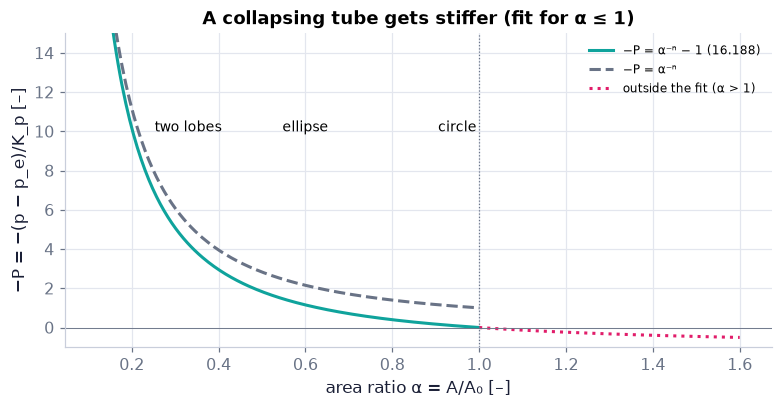

In [133]:
al_c = np.linspace(0.12, 1.0, 200)                            # collapse branch: the fit's range
al_x = np.linspace(1.0, 1.6, 60)                              # beyond α = 1: outside the fit (formula drawn dashed, not the library)
fig, ax = plt.subplots(figsize=(7, 3.6))   # a new figure and its axes
ax.plot(al_c, -ch16.collapsible_tube_law(al_c, n=1.5), color=COLORS["teal"], lw=2, label="−P = α⁻ⁿ − 1 (16.188)")   # curve: −P = α⁻ⁿ − 1 (16.188)
ax.plot(al_c, -ch16.collapsible_tube_law(al_c, n=1.5, form="pure"), "--", color=COLORS["muted"], label="−P = α⁻ⁿ")   # curve: −P = α⁻ⁿ
ax.plot(al_x, al_x**-1.5 - 1, ":", color=COLORS["rose"], label="outside the fit (α > 1)")   # curve: outside the fit (α > 1)
ax.axhline(0, color=COLORS["muted"], lw=0.6); ax.axvline(1, color=COLORS["muted"], ls=":", lw=0.8)   # a reference line
for a_, s_ in ((0.25, "two lobes"), (0.6, "ellipse"), (0.95, "circle")):          # cross-section shapes along the axis
    ax.text(a_ + 0.08*(a_ < 0.3), 10, s_, ha="center", fontsize=9)               # "two lobes" nudged right, clear of the steep curves
ax.set(xlabel="area ratio α = A/A₀ [–]", ylabel="−P = −(p − p_e)/K_p [–]", ylim=(-1, 15), title="A collapsing tube gets stiffer (fit for α ≤ 1)")   # axis labels, limits and title
ax.legend(fontsize=8)   # the legend
savefig(fig, "ch16", "c15_tube_law"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** −P against the area ratio for the fit $-\mathrm P\approx\alpha^{-n}-1,\ \ n=\tfrac32$ (16.188) (teal) and the pure power law (grey dashed), on the collapse branch
α ≤ 1; the rose dotted piece beyond α = 1 is the same formula outside the range it was fitted for.

**How to read it.** As the tube flattens (α falls) it takes ever larger negative transmural pressures to squeeze it further: the slope
dP/dα grows, so the wave speed $c^2=\dfrac{nK_p\alpha^{-n}}{\rho}$ (16.189) grows too (D28).

**What would change if…** …n were 2? The curve would rise more steeply at small α — a tube that resists the last stage of collapse harder.

#### 🧮 Derivation — The wave speed of a collapsible tube `D28` ★ (Eq. 16.189: $c^2=\dfrac{nK_p\alpha^{-n}}{\rho}$)

**What we want to show.** Find how fast a small wave runs along a partly collapsed tube.

**Assumptions.** a uniform tube (K_p, A₀ constant).

**The plan.**

1. Write p − p_e with P.
2. Change variable to α.
3. Differentiate the power law.
4. Substitute.

**Tools we use** (each explained before this point): chain rule (P49) · power rule

**We start from**

$$ \begin{array}{l}c^2=\dfrac A\rho\dfrac{d(p-p_e)}{dA}\ \text{(16.185) and}\ -\mathrm P\approx\alpha^{-n}-1\ \text{(16.188) with}\ \mathrm P=\dfrac{p-p_e}{K_p}\ \text{,}\ \alpha=\dfrac A{A_0} \\ \text{(16.186).}\end{array} $$

---

**Step 1 of 4 — Write the transmural pressure with P.**

$$ p-p_e=K_p\,\mathrm P(\alpha),\quad\alpha=\dfrac A{A_0} $$

- *Why we can do this:* Definitions $\mathrm P=\dfrac{p-p_e}{K_p},\ \ \alpha=\dfrac A{A_0}$ (16.186).
- *In words:* The tube law in dimensionless form.

---

**Step 2 of 4 — Change variable from A to α.**

$$ c^2=\dfrac{\alpha K_p}{\rho}\dfrac{d\mathrm P}{d\alpha} $$

- *Why we can do this:* Chain rule: $\dfrac{d(p-p_e)}{dA}=\dfrac{K_p}{A_0}\dfrac{d\mathrm P}{d\alpha}$, and $A/A_0=\alpha$.
- *In words:* The wave speed is set by the slope of the tube law.

---

**Step 3 of 4 — Differentiate the tube law.**

$$ \mathrm P=1-\alpha^{-n}\ \Rightarrow\ \dfrac{d\mathrm P}{d\alpha}=n\alpha^{-n-1} $$

- *Why we can do this:* $-\mathrm P\approx\alpha^{-n}-1,\ \ n=\tfrac32$ (16.188); power rule. P is negative for α < 1 but its slope is positive (trap T9).
- *In words:* A collapsed tube gets stiffer as it flattens.

---

**Step 4 of 4 — Substitute.**

$$ c^2=\dfrac{nK_p\alpha^{-n}}{\rho}\ \text{(16.189)} $$

- *Why we can do this:* $\alpha\cdot\alpha^{-n-1}=\alpha^{-n}$. Substituting the slope of step 3 into step 2 is direct; powers of the same base multiply by adding exponents.
- *In words:* The more collapsed, the faster the wave.

---

**Result**

$$ c^2=\dfrac{nK_p\alpha^{-n}}{\rho}\ \text{(16.189).} $$

**What it means.** Collapsible vessels carry very slow waves, so ordinary blood speeds can reach S = 1. Fails at α > 1 where the fit $-\mathrm P\approx\alpha^{-n}-1,\ \ n=\tfrac32$ (16.188) is not meant for distension.

**Check it.** Units Pa/(kg m⁻³) = m²/s² ✓; easy numbers α = 0.25, n = 1.5, K_p = 250 Pa, ρ = 1000 kg/m³: c² = 1.5 × 250 × 8/1000 = 3, **c = 1.73 m/s**; our vein at α = 0.5: 0.895 m/s, at α = 1: 0.532 m/s (expect) — a few metres per second at most.

📝 **Notes taught inside `D28`:** **N100 [B]** $c^2=\dfrac{nK_p\alpha^{-n}}{\rho}$ (16.189).

> ⚠️ **Common confusion (traps in `D28`):** P < 0 when collapsed, dP/dα > 0 (T9).

In [134]:
print(ch16.collapsible_wave_speed(np.array([1.0, 0.5, 0.25]), vein["Kp"], blood["rho"]), "m/s")   # (16.189): 0.53, 0.89, 1.50 m/s

[0.532  0.8947 1.5047] m/s


> 🔁 **Recap — Duct laws with friction `R13`** (Ch. 15 §15.3, §15.8 (C03, C11)). Steady 1-D continuity $\dfrac{dA}A+\dfrac{du}u=0$ (16.190) and momentum with friction and gravity $-A\,dp-\tau_ws\,dx-\rho gA\,dz=\rho Au\,du$ (16.191), the wall
stress for turbulent $\dfrac{\tau_ws\,dx}{A}=\dfrac12\rho u^2\dfrac{4f_T\,dx}{d_e}$ (16.192) or laminar $\dfrac{\tau_ws\,dx}{A}=\dfrac{\mu u}{d_0}\dfrac1\alpha\dfrac{4f_L'\,dx}{d_0}$ (16.193) flow — Ch. 15's duct laws with a wall force. **New here:** the area is set
by the tube law, not by the wall's shape. $\dfrac{\tau_ws\,dx}{A}=\dfrac{\mu u}{d_0}\dfrac1\alpha\dfrac{4f_L'\,dx}{d_0}$ (16.193) uses an area $A_e$ the book does not define (slip S21; coded only as a
keyword).

📝 **Note.** **N101 [B]** The speed index $S=\dfrac uc,\ \ \dfrac{dS^2}{S^2}=2\dfrac{du}u-2\dfrac{dc}c$ (16.195) — the Mach number of a floppy tube; in Ch. 15 every response carried the factor
1 − M² (C06), here 1 − S².

In [135]:
print(ch16.speed_index(0.6, ch16.collapsible_wave_speed(0.5, vein["Kp"], blood["rho"])))   # S = u/c at α = 0.5 for u = 0.6 m/s

0.6706115961080932


> 🔁 **Tools from earlier chapters used in this block** (one line each; the full primers are in the chapters named)

- **logarithmic differentiation** — d(ln f) = df/f turns a product of powers into a sum of relative changes; here c² = αK_pP′/ρ becomes 2dc/c = dα/α + dK_p/K_p + dP′/P′. *(Ch. 1, P52)*
- **differentials of algebraic laws as a small linear system** — differentiate each law, divide by it, and solve the small linear system for the changes; in Ch. 15 the common factor was 1 − M², here it is 1 − S². *(Ch. 15, P362)*

#### 🧮 Derivation — The differential relations `D29` ★★ (Eq. 16.201, corrected: $2\dfrac{dc}c=\left(1+\dfrac{\alpha\,\partial^2\mathrm P/\partial\alpha^2}{\partial\mathrm P/\partial\alpha}\right)\dfrac{d\alpha}\alpha+\dfrac{dK_p}{K_p}+\dfrac{\alpha K_p}{\rho c^2}\dfrac{\partial}{\partial x}\left(\dfrac{\partial\mathrm P}{\partial\alpha}\right)dx$)

**What we want to show.** Turn the tube law, the wave speed and the speed index into relations between small changes (differentials) along the tube.

**Assumptions.** Steady flow; P smooth in α and x.

**The plan.**

1. Log-differentiate α.
2. Differentiate the tube law.
3. Expand dP.
4. Log-differentiate c².
5. Log-differentiate S².

**Tools we use** (each explained before this point): total differential (P49) · logarithmic differentiation (P52, reminder) · product rule (P38)

**We start from**

$$ \begin{array}{l}\text{α = A/A₀(x);}\ \mathrm P=\dfrac{p-p_e}{K_p(x)}=\mathrm P(\alpha,x)\ \text{;}\ c^2(\alpha,x)=\dfrac\alpha\rho K_p\dfrac{\partial\mathrm P}{\partial\alpha}\Big\rvert_x\ \text{;}\ S=\dfrac uc \\ \text{(16.195).}\end{array} $$

---

**Step 1 of 9 — Log-differentiate the area ratio.**

$$ \dfrac{d\alpha}\alpha=\dfrac{dA}A-\dfrac{dA_0}{A_0}\ \text{(16.196)} $$

- *Why we can do this:* ln α = ln A − ln A₀ (P52). The book writes dA_e for dA₀ just before (slip S22).
- *In words:* The area ratio changes when the area or the reference area does.

---

**Step 2 of 9 — Differentiate the tube law.**

$$ dp=dp_e+K_p\,d\mathrm P+\mathrm P\,dK_p\ \text{(16.197)} $$

- *Why we can do this:* $p=p_e+K_p\mathrm P$; product rule (P38). Differentiating a product is exact; it splits the pressure change into three causes.
- *In words:* Pressure changes with the outside pressure, the shape and the stiffness.

---

**Step 3 of 9 — Write c² with α.**

$$ c^2(\alpha,x)=\dfrac\alpha\rho K_p\dfrac{\partial\mathrm P}{\partial\alpha}\Big\rvert_x\ \text{(16.198)} $$

- *Why we can do this:* $c^2=\dfrac A\rho\dfrac{d(p-p_e)}{dA}$ (16.185) at fixed x, as in D28 step 2.
- *In words:* The local wave speed.

---

**Step 4 of 9 — Expand dP.**

$$ d\mathrm P=\dfrac{\partial\mathrm P}{\partial\alpha}d\alpha+\dfrac{\partial\mathrm P}{\partial x}dx\ \text{(16.199)} $$

- *Why we can do this:* Total differential of P(α, x) (P49).
- *In words:* P changes with the shape and with position.

---

**Step 5 of 9 — Substitute into dp.**

$$ dp=dp_e+\rho c^2\dfrac{d\alpha}\alpha+K_p\dfrac{\partial\mathrm P}{\partial x}dx+\mathrm P\,dK_p\ \text{(16.200)} $$

- *Why we can do this:* $K_p\dfrac{\partial\mathrm P}{\partial\alpha}d\alpha=\rho c^2\dfrac{d\alpha}\alpha$ by $c^2(\alpha,x)=\dfrac\alpha\rho K_p\dfrac{\partial\mathrm P}{\partial\alpha}\Big\rvert_x$ (16.198).
- *In words:* The shape change enters through ρc².

---

**Step 6 of 9 — Log-differentiate c².**

$$ 2\dfrac{dc}c=\dfrac{d\alpha}\alpha+\dfrac{dK_p}{K_p}+\dfrac{d(\partial\mathrm P/\partial\alpha)}{\partial\mathrm P/\partial\alpha} $$

- *Why we can do this:* ln c² = ln α + ln K_p + ln P_α − ln ρ, ρ constant (P52).
- *In words:* Three causes of a change in wave speed.

---

**Step 7 of 9 — Expand the slope's differential.**

$$ d\left(\dfrac{\partial\mathrm P}{\partial\alpha}\right)=\dfrac{\partial^2\mathrm P}{\partial\alpha^2}d\alpha+\dfrac{\partial}{\partial x}\left(\dfrac{\partial\mathrm P}{\partial\alpha}\right)dx $$

- *Why we can do this:* Total differential of P_α(α, x) (P49).
- *In words:* The slope changes with the shape and along the tube.

---

**Step 8 of 9 — Collect.**

$$ \begin{array}{l}2\dfrac{dc}c=\left(1+\dfrac{\alpha\,\partial^2\mathrm P/\partial\alpha^2}{\partial\mathrm P/\partial\alpha}\right)\dfrac{d\alpha}\alpha+\dfrac{dK_p}{K_p}+\dfrac{\alpha K_p}{\rho c^2}\dfrac{\partial}{\partial x}\left(\dfrac{\partial\mathrm P}{\partial\alpha}\right)dx \\ \text{(16.201, corrected)}\end{array} $$

- *Why we can do this:* Divide step 7 by P_α and use $1/\mathrm P_\alpha=\alpha K_p/(\rho c^2)$ (16.198). The book prints $\partial/\partial x(\partial\mathrm P/\partial x)$ — the inner derivative is wrong (slip S23).
- *In words:* How the wave speed changes.

---

**Step 9 of 9 — Log-differentiate S² and use continuity.**

$$ \dfrac{dS^2}{S^2}=-2\dfrac{d\alpha}\alpha-2\dfrac{dA_0}{A_0}-2\dfrac{dc}c\ \text{(16.202)} $$

- *Why we can do this:* $S=\dfrac uc,\ \ \dfrac{dS^2}{S^2}=2\dfrac{du}u-2\dfrac{dc}c$ (16.195): $dS^2/S^2=2du/u-2dc/c$; continuity $\dfrac{dA}A+\dfrac{du}u=0$ (16.190) $du/u=-dA/A=-d\alpha/\alpha-dA_0/A_0$ (step 1).
- *In words:* S grows when the tube narrows or the wave slows.

---

**Result**

$$ \begin{array}{l}\dfrac{d\alpha}\alpha=\dfrac{dA}A-\dfrac{dA_0}{A_0}\qquad\text{(16.196)} \\[6pt] dp=dp_e+K_p\,d\mathrm P+\mathrm P\,dK_p\qquad\text{(16.197)} \\[6pt] dp=dp_e+\rho c^2\dfrac{d\alpha}\alpha+K_p\dfrac{\partial\mathrm P}{\partial x}dx+\mathrm P\,dK_p\qquad\text{(16.200)} \\[6pt] 2\dfrac{dc}c=\left(1+\dfrac{\alpha\,\partial^2\mathrm P/\partial\alpha^2}{\partial\mathrm P/\partial\alpha}\right)\dfrac{d\alpha}\alpha+\dfrac{dK_p}{K_p}+\dfrac{\alpha K_p}{\rho c^2}\dfrac{\partial}{\partial x}\left(\dfrac{\partial\mathrm P}{\partial\alpha}\right)dx\qquad\text{(16.201, corrected)} \\[6pt] \dfrac{dS^2}{S^2}=-2\dfrac{d\alpha}\alpha-2\dfrac{dA_0}{A_0}-2\dfrac{dc}c\qquad\text{(16.202)}\end{array} $$

*In words:* Small changes of area ratio, pressure, wave speed and speed index along the tube.

**What it means.** Every quantity's change is a sum of the "drivers" dA₀, dp_e, dz, friction, dK_p — ready for D30. Fails where the 1-D picture fails (sharp collapse, contact of the walls).

**Check it.** a uniform tube with P = P(α): $2\dfrac{dc}c=\left(1+\dfrac{\alpha\,\partial^2\mathrm P/\partial\alpha^2}{\partial\mathrm P/\partial\alpha}\right)\dfrac{d\alpha}\alpha+\dfrac{dK_p}{K_p}+\dfrac{\alpha K_p}{\rho c^2}\dfrac{\partial}{\partial x}\left(\dfrac{\partial\mathrm P}{\partial\alpha}\right)dx$ (16.201) becomes $2\,dc/c=(1+\alpha\mathrm P''/\mathrm P')d\alpha/\alpha$; for the power law $\alpha\mathrm P''/\mathrm P'=-(n+1)$, so $2\,dc/c=-n\,d\alpha/\alpha$ — the log-derivative of $c^2=\dfrac{nK_p\alpha^{-n}}{\rho}$ (16.189) ✓; `ch16.collapsible_differentials_sympy()` shows the printed (16.201) failing for a P that depends on x.

📝 **Notes taught inside `D29`:** **N102 [B]** $\dfrac{d\alpha}\alpha=\dfrac{dA}A-\dfrac{dA_0}{A_0}$ (16.196)–$\dfrac{dS^2}{S^2}=-2\dfrac{d\alpha}\alpha-2\dfrac{dA_0}{A_0}-2\dfrac{dc}c$ (16.202) (the book writes $dA_e$ for $dA_0$ just before (16.196) — slip S22).

> ⚠️ **Common confusion (traps in `D29`):** S23; S22; the partial derivatives are at fixed x or fixed α.

> ⚠️ **slip S23 — the book prints** the last term of $\dots+\dfrac{\alpha K_p}{\rho c^2}\dfrac{\partial}{\partial x}\left(\dfrac{\partial\mathrm P}{\partial x}\right)dx$ (16.201, last term as printed); **the correct form is** $2\dfrac{dc}c=\left(1+\dfrac{\alpha\,\partial^2\mathrm P/\partial\alpha^2}{\partial\mathrm P/\partial\alpha}\right)\dfrac{d\alpha}\alpha+\dfrac{dK_p}{K_p}+\dfrac{\alpha K_p}{\rho c^2}\dfrac{\partial}{\partial x}\left(\dfrac{\partial\mathrm P}{\partial\alpha}\right)dx$ (16.201, corrected)
>
> The inner derivative is ∂P/∂α (the slope of the tube law), not ∂P/∂x.

In [136]:
print(ch16.collapsible_differentials_sympy())               # every residual 0, M = 2 − n for the power law
print(ch16.collapsible_differentials_sympy(printed_16_201=True)["dc_difference"])   # the printed term differs when P depends on x

{'dc_difference': 0, 'eq204_residual': 0, 'eq205_residual': 0, 'M_power_law': 2 - n}


dx*(-Derivative(P(alpha, x), (x, 2)) + Derivative(P(alpha, x), alpha, x))/Derivative(P(alpha, x), alpha)


#### 🧮 Derivation — Shapiro's equations and the condition at S = 1 `D30` ★★★ (Eq. 16.204: $(1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]$)

**What we want to show.** Write the change of the area ratio and of the speed index along a collapsible tube in terms of the drivers, and see why S = 1 is special.

**Assumptions.** Steady 1-D flow; the tube law depends on α only (step 4); laminar friction (step 3).

**The plan.**

1. Momentum in differential form.
2. Substitute dp and dA/A.
3. Collect dα: the factor 1 − S².
4. The same for dS².
5. Read S = 1.

**Tools we use** (each explained before this point): a small linear system of differentials (Ch. 15 D12/D22, P362, reminder) · logarithmic differentiation (P52) · sympy (P40)

**We start from**

$$ \dfrac{dA}A+\dfrac{du}u=0\ \text{(16.190) and}\ -A\,dp-\tau_ws\,dx-\rho gA\,dz=\rho Au\,du\ \text{(16.191).} $$

---

**Step 1 of 15 — Use continuity in the momentum law.**

$$ \rho Au\,du=-\rho Au^2\dfrac{dA}A $$

- *Why we can do this:* $\dfrac{dA}A+\dfrac{du}u=0$ (16.190): $du=-u\,dA/A$. Replacing du by its equal from continuity is exact; it removes the speed change from the momentum law.
- *In words:* Where the tube narrows the blood speeds up.

---

**Step 2 of 15 — Divide by A and rearrange.**

$$ d(p+\rho gz)+\dfrac{\tau_ws\,dx}A-\rho u^2\dfrac{dA}A=0\ \text{(16.194)} $$

- *Why we can do this:* $-A\,dp-\tau_ws\,dx-\rho gA\,dz=\rho Au\,du$ (16.191) with step 1, divided by A; ρ constant so $dp+\rho g\,dz=d(p+\rho gz)$.
- *In words:* Pressure-plus-height falls by friction and changes with the area.

---

**Step 3 of 15 — Name the friction term.**

$$ \dfrac{\tau_ws\,dx}A=\mathrm RQ\,dx $$

- *Why we can do this:* R is the viscous resistance per unit length (the book's R in $(1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]$ (16.204)); for laminar flow in area A, $\mathrm R=8\pi\mu/A^2$ (ours: the resistance per length that `ch16.collapsible_march` uses).
- *In words:* Friction costs pressure in proportion to the flow.

---

**Step 4 of 15 — Take a tube law that depends on α only.**

$$ p-p_e(x)=K_p(x)\mathrm P(\alpha)\ \text{(16.203), so}\ dp=dp_e+\rho c^2\dfrac{d\alpha}\alpha+\mathrm P\,dK_p $$

- *Why we can do this:* The book's case: ∂P/∂x = 0 in $dp=dp_e+\rho c^2\dfrac{d\alpha}\alpha+K_p\dfrac{\partial\mathrm P}{\partial x}dx+\mathrm P\,dK_p$ (16.200).
- *In words:* The tube's shape law is the same everywhere; only the outside pressure and the stiffness may vary.

---

**Step 5 of 15 — Substitute dp and dA/A into (16.194).**

$$ dp_e+\rho c^2\dfrac{d\alpha}\alpha+\mathrm P\,dK_p+\rho g\,dz+\mathrm RQ\,dx-\rho u^2\left(\dfrac{d\alpha}\alpha+\dfrac{dA_0}{A_0}\right)=0 $$

- *Why we can do this:* Step 4 and $\dfrac{d\alpha}\alpha=\dfrac{dA}A-\dfrac{dA_0}{A_0}$ (16.196): $dA/A=d\alpha/\alpha+dA_0/A_0$.
- *In words:* One equation with dα and the drivers.

---

**Step 6 of 15 — Collect the dα terms first.**

$$ \rho(c^2-u^2)\dfrac{d\alpha}\alpha=\rho u^2\dfrac{dA_0}{A_0}-\left[dp_e+\rho g\,dz+\mathrm RQ\,dx+\mathrm P\,dK_p\right] $$

- *Why we can do this:* Move everything else right; form the whole right side before dividing (trap T10, the same care as in Ch. 15's duct-flow derivations).
- *In words:* The drivers on one side, the response on the other.

---

**Step 7 of 15 — Divide by $\rho c^2\,dx$.**

$$ (1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]\ \text{(16.204)} $$

- *Why we can do this:* ρc² > 0 and S = u/c $S=\dfrac uc,\ \ \dfrac{dS^2}{S^2}=2\dfrac{du}u-2\dfrac{dc}c$ (16.195).
- *In words:* Like a nozzle: the sign of 1 − S² decides which way the tube responds.

---

**Step 8 of 15 — Simplify (16.201) for P(α).**

$$ 2\dfrac{dc}c=(\mathrm M-2)\dfrac{d\alpha}\alpha+\dfrac{dK_p}{K_p},\quad\mathrm M=3+\dfrac{\alpha\,\partial^2\mathrm P/\partial\alpha^2}{\partial\mathrm P/\partial\alpha}\ \text{(16.206)} $$

- *Why we can do this:* ∂P/∂x = 0 removes the last term of $2\dfrac{dc}c=\left(1+\dfrac{\alpha\,\partial^2\mathrm P/\partial\alpha^2}{\partial\mathrm P/\partial\alpha}\right)\dfrac{d\alpha}\alpha+\dfrac{dK_p}{K_p}+\dfrac{\alpha K_p}{\rho c^2}\dfrac{\partial}{\partial x}\left(\dfrac{\partial\mathrm P}{\partial\alpha}\right)dx$ (16.201, corrected); $1+\alpha\mathrm P''/\mathrm P'=\mathrm M-2$.
- *In words:* M measures how the wave speed changes with the shape.

---

**Step 9 of 15 — Substitute into (16.202).**

$$ \dfrac{dS^2}{S^2}=-\mathrm M\dfrac{d\alpha}\alpha-2\dfrac{dA_0}{A_0}-\dfrac{dK_p}{K_p} $$

- *Why we can do this:* $-2\,d\alpha/\alpha-(\mathrm M-2)\,d\alpha/\alpha=-\mathrm M\,d\alpha/\alpha$. Adding the two dα terms is exact; it shows that the speed index responds to the shape through M alone.
- *In words:* S responds to the shape through M.

---

**Step 10 of 15 — Multiply by $1-S^2$.**

$$ (1-S^2)\dfrac{dS^2}{S^2}=-\mathrm M(1-S^2)\dfrac{d\alpha}\alpha-(1-S^2)\left[2\dfrac{dA_0}{A_0}+\dfrac{dK_p}{K_p}\right] $$

- *Why we can do this:* So that $(1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]$ (16.204) can replace $(1-S^2)d\alpha/\alpha$.
- *In words:* Ready to eliminate dα.

---

**Step 11 of 15 — Insert (16.204).**

$$ (1-S^2)\dfrac{dS^2}{S^2}=-\mathrm M\left\{S^2\dfrac{dA_0}{A_0}-\dfrac{[\dots]}{\rho c^2}\right\}-(1-S^2)\left[2\dfrac{dA_0}{A_0}+\dfrac{dK_p}{K_p}\right] $$

- *Why we can do this:* [⋯] is the bracket of step 6, $dp_e+\rho g\,dz+\mathrm RQ\,dx+\mathrm P\,dK_p$.
- *In words:* Only drivers left on the right.

---

**Step 12 of 15 — Collect the dA₀ terms.**

$$ \dfrac{dA_0}{A_0}\left[-2+(2-\mathrm M)S^2\right] $$

- *Why we can do this:* $-\mathrm MS^2-2+2S^2$. Grouping like terms after multiplying out is exact; it isolates how the area driver acts on S.
- *In words:* The area's effect on S.

---

**Step 13 of 15 — Collect the dK_p terms.**

$$ \dfrac{dK_p}{\rho c^2}\left[\mathrm M\mathrm P-(1-S^2)\alpha\dfrac{d\mathrm P}{d\alpha}\right] $$

- *Why we can do this:* From M/(ρc²)·P dK_p and $-(1-S^2)dK_p/K_p$, with $1/K_p=\alpha\mathrm P'/(\rho c^2)$ by $c^2(\alpha,x)=\dfrac\alpha\rho K_p\dfrac{\partial\mathrm P}{\partial\alpha}\Big\rvert_x$ (16.198).
- *In words:* The stiffness's effect on S.

---

**Step 14 of 15 — Assemble per unit length.**

$$ \begin{array}{l}(1-S^2)\dfrac1{S^2}\dfrac{dS^2}{dx}=\dfrac1{A_0}\dfrac{dA_0}{dx}[-2+(2-\mathrm M)S^2]+\dfrac{\mathrm M}{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ\right]+\dfrac1{\rho c^2}\dfrac{dK_p}{dx}\left[\mathrm M\mathrm P-(1-S^2)\alpha\dfrac{d\mathrm P}{d\alpha}\right] \\ \text{(16.205)}\end{array} $$

- *Why we can do this:* Steps 11–13, divided by dx. Adding three exact lines and dividing by a small length dx gives rates per metre, the book's form.
- *In words:* Shapiro's equation for the speed index.

---

**Step 15 of 15 — Read the condition at S = 1.**

$$ S=1:\quad\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}=\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right] $$

- *Why we can do this:* The left side of $(1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]$ (16.204) vanishes; a finite dα/dx needs the right side to vanish too. So a smooth passage through S = 1 needs dA₀/dx > 0, or $d(p_e+\rho gz)/dx<0$, or $\mathrm P\,dK_p/dx<0$ — with P < 0 that is $dK_p/dx>0$ (trap T9; the text's "decrease" is S24).
- *In words:* Like a Laval throat: S = 1 can only be crossed where the tube widens or is helped.

---

**Result**

$$ \begin{array}{l}(1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]\qquad\text{(16.204)} \\[6pt] (1-S^2)\dfrac1{S^2}\dfrac{dS^2}{dx}=\dfrac1{A_0}\dfrac{dA_0}{dx}[-2+(2-\mathrm M)S^2]+\dfrac{\mathrm M}{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ\right]+\dfrac1{\rho c^2}\dfrac{dK_p}{dx}\left[\mathrm M\mathrm P-(1-S^2)\alpha\dfrac{d\mathrm P}{d\alpha}\right]\qquad\text{(16.205)} \\[6pt] \mathrm M=3+\dfrac{\alpha\,\partial^2\mathrm P/\partial\alpha^2}{\partial\mathrm P/\partial\alpha}\qquad\text{(16.206)}\end{array}\qquad\text{power law: }\mathrm M=2-n=\tfrac12 $$

*In words:* Shapiro's equations: the factor 1 − S² decides every response, and at S = 1 the drivers must balance.

**What it means.** S plays the Mach number: below 1 friction collapses the tube and speeds the flow, until S = 1 at the outlet; then the flow no longer feels the downstream pressure — flow limitation (Starling Case 1), the floppy-tube twin of a choked nozzle. Fails when the walls touch or the flow separates at the throat.

**Check it.** For $\mathrm P=1-\alpha^{-n}$: $\mathrm P'=n\alpha^{-n-1}$, $\mathrm P''=-n(n+1)\alpha^{-n-2}$, so $\mathrm M=3-(n+1)=2-n=0.5$ ✓; friction only (S < 1): dα/dx < 0 — the tube collapses downstream and S rises toward 1 (choking); **expect** our vein, L = 0.1 m, inlet open: the outlet reaches S = 1 at **Q = 19.99 mL/s**, α = 0.312, p₂ − p_e = −946 Pa (−7.1 mmHg); lower p₂ further and Q stays there. The sympy cell below re-runs the derivation's own steps (every line is commented); it prints `0` and `0`.

In [137]:
import sympy as sp                                                       # symbolic algebra
dal, dA0, dpe, dz, dx, dKp, RQ, S2, c2, P, Pa, Paa, Kp, al, A0, g = sp.symbols(   # differentials and coefficients of D29–D30
    'dalpha dA0 dpe dz dx dKp RQ S2 c2 P Pa Paa Kp alpha A0 g', real=True)   # differentials and coefficients
rho = sp.symbols('rho', positive=True)   # density
dp = dpe + rho*c2*dal/al + P*dKp                                         # step 4: (16.200) with ∂P/∂x = 0
mom = sp.Eq(dp + rho*g*dz + RQ*dx - rho*S2*c2*(dal/al + dA0/A0), 0)      # step 5: (16.194), u² = S²c²
dal_sol = sp.solve(mom, dal)[0]                                          # steps 6–7
t204 = al*(S2*dA0/A0 - (dpe + rho*g*dz + RQ*dx + P*dKp)/(rho*c2))/(1 - S2)   # dα from (16.204), to compare
print(sp.simplify(dal_sol - t204))                                       # (16.204) → 0
M = 3 + al*Paa/Pa                                                        # (16.206)
dS2 = -2*dal/al - 2*dA0/A0 - ((1 + al*Paa/Pa)*dal/al + dKp/Kp)           # (16.202) with (16.201, corrected), steps 8–9
lhs = sp.expand((1 - S2)*dS2.subs(dal, dal_sol))                         # steps 10–11
rhs = (dA0/A0*(-2 + (2 - M)*S2) + M/(rho*c2)*(dpe + rho*g*dz + RQ*dx)   # right side of (16.205), continued on the next line
       + dKp/(rho*c2)*(M*P - (1 - S2)*al*Pa))                            # step 14: (16.205)
print(sp.simplify((lhs - rhs).subs(c2, al*Kp*Pa/rho)))                   # with ρc² = αK_pP′ (16.198) → 0

0


0


> ⚠️ **Common confusion (traps in `D30`):** T10 (form the driver, then divide by 1 − S²); T9 and S24 (the sign of P dK_p/dx); M is not a Mach number (T2).

> ⚠️ **Common confusion:** (trap T9, slip S24) The condition at S = 1 needs $\mathrm P\,dK_p/dx<0$; a collapsed tube has P < 0, so the stiffness must
**increase** along the flow — the text's "decrease" reads the sign of P wrongly.

#### ✏️ Tiny example: a vein at its limit

1. A collapsed segment at α = 0.25 with K_p = 250 Pa (easy numbers): c² = 1.5 × 250 × 8/1000 = 3, c = **1.73 m/s**.
2. Its area A = 0.25A₀; with A₀ = 50 mm² the choking flux is Q* = αA₀c = 0.25 × 50 × 10⁻⁶ × 1.73 = **21.7 mL/s**.
3. Our vein (A₀ = 50.3 mm², K_p = 200 Pa, L = 0.1 m, open inlet): friction narrows it until S = 1 at the outlet at
   **Q = 20.0 mL/s**, α = 0.31, p₂ − p_e = −946 Pa = −7.1 mmHg (ours, model).
4. Lower p₂ further: Q stays at 20.0 mL/s.

In [138]:
prm = dict(L=vein["L"], A0=A0v, Kp=vein["Kp"], n=vein["n"], rho=blood["rho"], mu=blood["mu"])   # our vein (model, ours)
print(f"Q* = {ch16.choking_flux(0.25, 50e-6, 250.0, 1000.0)*1e6:.2f} mL/s")   # the tiny example's choking flux
mr = ch16.collapsible_march(15e-6, 1.0, (0.0, prm["L"]), prm)  # (16.204) marched from an open inlet at 15 mL/s
print(f"15 mL/s: outlet α = {mr['alpha'][-1]:.4f}, S = {mr['S'][-1]:.3f}, choked: {mr['choked']}")   # print the result
fl = ch16.flow_limitation_curve(np.linspace(-15, 0, 15 if FAST else 31)*MMHG, p1=0.0, pe=0.0, prm=prm)   # Starling Case 1
print(f"Q_choke = {fl['Q_choke']*1e6:.3f} mL/s, reached for p2 − pe ≤ {fl['p2_choke']:.1f} Pa = {fl['p2_choke']/MMHG:.2f} mmHg")   # print the result
print("M =", ch16.shapiro_M(0.5, 1.5))                       # (16.206) for the power law: 2 − n = 0.5

Q* = 21.65 mL/s
15 mL/s: outlet α = 0.7546, S = 0.602, choked: False


Q_choke = 19.990 mL/s, reached for p2 − pe ≤ -946.1 Pa = -7.10 mmHg
M = 0.5


**What does the code above do?**

1. `collapsible_march` integrates $(1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]$ (16.204) along the tube (friction only: $dA_0=dp_e=dz=dK_p=0$) and stops if S reaches 1.
2. `flow_limitation_curve` finds, for each outlet pressure, the flow whose outlet state matches it; below a critical
   outlet pressure the outlet is at S = 1 and the flow cannot rise any more.
3. `shapiro_M` evaluates $\mathrm M=3+\dfrac{\alpha\,\partial^2\mathrm P/\partial\alpha^2}{\partial\mathrm P/\partial\alpha}$ (16.206): ½ for n = 3/2.

In [139]:
def rhs(x, al, Q):                                             # dα/dx from (16.204) with friction only (laminar R′ = 8πμ/(αA0)²)
    c2 = 1.5*vein["Kp"]*al**-1.5/blood["rho"]                  # (16.189)
    S2 = (Q/(al*A0v))**2/c2                                    # speed index squared
    Rp = 8*np.pi*blood["mu"]/(al*A0v)**2                       # laminar resistance per length [Pa s/m⁴]
    return -al*Rp*Q/(blood["rho"]*c2*(1 - S2))                 # α·driver/(1 − S²)
n_e = 20000; dx = prm["L"]/n_e; al = 1.0                        # explicit Euler, 20 000 steps
for i in range(n_e):                                            # march down the tube, one small step dx at a time
    al += dx*rhs(i*dx, al, 15e-6)                               # Euler step: α ← α + dx·dα/dx at Q = 15 mL/s
assert np.isclose(al, mr["alpha"][-1], rtol=1e-3)               # the library's march
# a frictionless throat (ours; the orchestrator's case): S = 1 exactly where A0(x) is smallest
A0t, Kpt, rhot, al_t = np.pi*6e-3**2, 200.0, 1000.0, 0.35       # neutral area, stiffness, density, area ratio at the throat
Qs = ch16.choking_flux(al_t, A0t, Kpt, rhot, 1.5)              # critical flux: S = 1 at the throat
H = Kpt*ch16.collapsible_tube_law(al_t, n=1.5) + 0.5*rhot*(Qs/(al_t*A0t))**2   # Bernoulli constant K_pP + ½ρu²
A0f = lambda x: A0t*(1 + (x/0.05)**2)                           # a smooth throat at x = 0
a_in = ch16.collapsible_frictionless_alpha(Qs, H, A0f(-0.12), Kpt, rhot, 1.5, branch="sub")   # inlet state (subcritical)
mt = ch16.collapsible_march(Qs, a_in, (-0.12, 0.12), dict(A0=A0f, Kp=Kpt, n=1.5, rho=rhot, mu=1e-3, friction=False), rtol=1e-11, atol=1e-13)   # `ch16.collapsible_march` (the chapter module)
assert a_in <= 1 and np.all(mt["alpha"] <= 1)                   # upstream stays on the collapse branch (α_t ≤ 0.25^(2/3) = 0.397)
assert abs(mt["x_choke"]) < 2e-3                                # S reaches 1 at the throat
print(f"Euler {al:.5f} vs library {mr['alpha'][-1]:.5f}; throat: Q* = {Qs*1e6:.2f} mL/s, inlet α = {a_in:.4f}, S = 1 at x = {mt['x_choke']*1e3:.2f} mm")   # print the result

Euler 0.75457 vs library 0.75457; throat: Q* = 47.65 mL/s, inlet α = 0.8758, S = 1 at x = -0.00 mm


**What does the code above do?**

1. An explicit Euler march of $(1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]$ (16.204) with laminar friction (20 000 steps) reproduces the library's outlet area ratio.
2. A frictionless tube with a smooth throat (ours; ρ = 1000 kg/m³, $K_p$ = 200 Pa, a₀ = 6 mm, throat area ratio 0.35, small
   enough that the upstream tube stays collapsed, α ≤ 1): at the critical flux the march reaches S = 1 exactly at the throat —
   the floppy-tube twin of a Laval nozzle (Ch. 15).

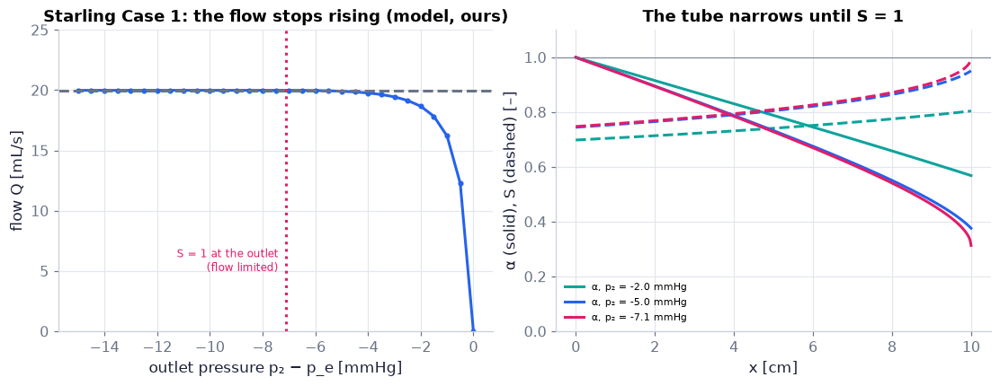

In [140]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.8))   # a new figure and its axes
ax.plot(fl["p2"]/MMHG, fl["Q"]*1e6, "o-", color=COLORS["blue"], ms=3)   # blue: flow against outlet pressure (Starling Case 1)
ax.axhline(fl["Q_choke"]*1e6, ls="--", color=COLORS["muted"]); ax.axvline(fl["p2_choke"]/MMHG, ls=":", color=COLORS["rose"])   # a reference line
ax.text(fl["p2_choke"]/MMHG - 0.3, 5, "S = 1 at the outlet\n(flow limited)", ha="right", fontsize=8, color=COLORS["rose"])   # a text label on the plot
ax.set(xlabel="outlet pressure p₂ − p_e [mmHg]", ylabel="flow Q [mL/s]", ylim=(0, 25), title="Starling Case 1: the flow stops rising (model, ours)")   # axis labels, limits and title
for p2_, col in ((-2.0, COLORS["teal"]), (-5.0, COLORS["blue"]), (fl["p2_choke"]/MMHG, COLORS["rose"])):   # three outlet pressures
    st = ch16.starling_state(0.0, p2_*MMHG, 0.0, prm)          # the flow for that outlet pressure
    m_ = ch16.collapsible_march(min(st["Q"], fl["Q_choke"]*(1 - 1e-6)), 1.0, (0.0, prm["L"]), prm)   # `ch16.collapsible_march` (the chapter module)
    bx.plot(m_["x"]*100, m_["alpha"], color=col, label=f"α, p₂ = {p2_:.1f} mmHg"); bx.plot(m_["x"]*100, m_["S"], "--", color=col)   # curve: α, p₂ = {p2_:.1f} mmHg
bx.axhline(1, color=COLORS["muted"], lw=0.6)   # a reference line
bx.set(xlabel="x [cm]", ylabel="α (solid), S (dashed) [–]", ylim=(0, 1.1), title="The tube narrows until S = 1"); bx.legend(fontsize=7)   # axis labels, limits and title
savefig(fig, "ch16", "c15_starling"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** Left: the flow through our collapsible vein against the outlet pressure (open inlet at the chamber pressure); right: the
area ratio (solid) and speed index (dashed) along the tube for three outlet pressures, the last one at the critical value.

**How to read it.** Lowering the outlet pressure first raises the flow steeply, as in any pipe; below about −4 mmHg the flow is within a
few per cent of its limit, and from −7.1 mmHg on it is exactly flat: the outlet has reached S = 1 and news of a lower outlet pressure can no longer travel upstream against the flow. On the right,
friction narrows the tube along its length and raises S; at the critical case S reaches 1 exactly at the outlet.

**What would change if…** …the blood were more viscous? Friction would narrow the tube faster and the flow would limit at a lower value.

#### 🎮 Interactive: Why can't you suck harder through a floppy straw?

**Why interactive rather than a static figure:** lowering the outlet pressure you watch Q rise and stall as the outlet reaches S = 1; in the throat mode the drivers of
$(1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]$ (16.204) change sign exactly where 1 − S² does; the giraffe mode balances gravity against friction — three regimes of one
equation, switched live.

Start with the **Walkthrough**; the **Explain** tab works every number out with your settings, and the **Derivation** tab (where there is one) steps through the same derivation as above. α is the area ratio A/A₀ (not the Womersley number); P is negative when the tube is collapsed; the tube-law fit is for collapse only (α ≤ 1); the Starling resistor is our model.

**What to try:**
- Drag p₂ from 0 to −15 mmHg: the flow plateaus at about −7 mmHg.
- Throat mode: watch the term bars cross zero at S = 1.
- Giraffe mode: the vein stays partly collapsed.

In [141]:
show_viz("ch16", "collapsible_tube_choking")   # full-width explainer; ⤢ Full screen for more room

[explainer ch16/collapsible_tube_choking]

**The giraffe** (part of C15). A giraffe's jugular vein runs downhill about 2 m from head to heart, dz/dx = −1: gravity
pulls the blood faster than friction alone allows, and the vein runs partly collapsed, its pressure near the outside
pressure — the gravity driver of $(1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]$ (16.204) balancing friction (ours, a model in the explainer above).

**What would change if…** …the fluid could not flow at all below a certain stress? Then the blood in the middle of a pipe stops shearing — C16, the
payoff of C02.

### 🧩 A plug riding on a ring: $a_c=\dfrac{2L\tau_y}{p_1-p_2}=a\left(\dfrac{\tau_y}{\tau_w}\right)$ (16.210) and the Casson flux $Q=\dfrac\pi8\dfrac1{K_c^2}\dfrac{\Delta p}La^4\left[1-\dfrac{16}7\left(\dfrac{a_c}a\right)^{1/2}+\dfrac43\left(\dfrac{a_c}a\right)-\dfrac1{21}\left(\dfrac{a_c}a\right)^4\right]$ (16.220) `C16`

*The question:* Does a yield stress stop blood flowing in a vessel?

📝 **Note.** **N103 [C]** Below about 200 s⁻¹ blood is clearly non-Newtonian (C02); Casson's law is the usual model.

#### The problem in plain words

Squeeze toothpaste from a tube: it comes out as a solid cylinder that slides on a thin sheared layer at the nozzle wall. A
fluid with a yield stress does that in any pipe: **near the centre the stress is too small to shear it, so the centre moves
as a plug**. Blood's yield stress is tiny, but the same picture holds — and it costs flow.

#### The idea

```
stress τ = (Δp/2L) r :  0 on the axis ─────────► τ_w at the wall
   r < a_c :  τ < τ_y  →  no shear: a solid plug
   r > a_c :  τ > τ_y  →  a sheared ring
```

📝 **Note.** **N104 [B]** Casson's law with its yield branch: $\tau^{1/2}=\tau_y^{1/2}+K_c\dot\gamma^{1/2}\ (\tau\ge\tau_y),\ \ \dot\gamma=0\ (\tau<\tau_y)$ (16.207); $K_c$ is dimensional (trap T14).

In [142]:
print(ch16.casson_shear_rate(np.array([0.5, 1.0, 4.0])*ty, ty, Kc))   # zero below τ_y, positive above (16.207)

[0.     0.     1.7087]


#### 🧮 Derivation — The stress line, the plug radius and the minimum pressure drop `D31` ★ (Eq. 16.210: $a_c=\dfrac{2L\tau_y}{p_1-p_2}=a\left(\dfrac{\tau_y}{\tau_w}\right)$)

**What we want to show.** Find where a yield-stress fluid in a pipe shears and where it moves as a solid plug, and the smallest pressure drop that makes it flow at all.

**Assumptions.** Steady, fully developed (step 1).

**The plan.**

1. Force balance.
2. The stress line.
3. Where it meets τ_y.
4. When the plug fills the pipe.

**Tools we use** (each explained before this point): free body of a fluid cylinder (Ch. 8 D07, recap)

**We start from**

$$ \textstyle\sum F_x=0:\ \text{pressure on the two end faces of a cylinder }(r,\Delta x)+\text{shear on its side}=0 $$

*In words:* A fluid cylinder of radius r and length Δx in steady, fully developed flow.

---

**Step 1 of 5 — Balance forces on a fluid cylinder.**

$$ \tau_{rx}\,2\pi r\,\Delta x=-\pi r^2\left(p\rvert_{x+\Delta x}-p\rvert_x\right)\ \text{(16.208)} $$

- *Why we can do this:* Steady, fully developed: no acceleration, so the shear on the side balances the pressure difference on the ends (Ch. 8 D07).
- *In words:* The pressure push on a core of radius r is held by the shear on its surface.

---

**Step 2 of 5 — Let Δx shrink.**

$$ \tau_{rx}(r)=-\dfrac r2\dfrac{dp}{dx}=\dfrac{(p_1-p_2)r}{2L}\ \text{(16.209, first member's sign corrected)} $$

- *Why we can do this:* Divide by 2πrΔx; the limit is dp/dx = −(p₁ − p₂)/L $\dfrac{dp}{dx}=-\dfrac{\Delta p}{L}$ (16.14). The book's first member lacks the minus (slip S25).
- *In words:* Stress grows linearly from the axis — whatever the fluid.

---

**Step 3 of 5 — Evaluate at the wall.**

$$ \tau_w=\dfrac{(p_1-p_2)a}{2L} $$

- *Why we can do this:* r = a. Setting r = a in the linear stress of step 2 gives its value at the wall, where it is largest.
- *In words:* The largest stress is at the wall.

---

**Step 4 of 5 — Find where the stress reaches the yield stress.**

$$ a_c=\dfrac{2L\tau_y}{p_1-p_2}=a\left(\dfrac{\tau_y}{\tau_w}\right)\ \text{(16.210)} $$

- *Why we can do this:* τ_rx(a_c) = τ_y; inside (r < a_c) τ < τ_y, so the shear rate is zero by $\tau^{1/2}=\tau_y^{1/2}+K_c\dot\gamma^{1/2}\ (\tau\ge\tau_y),\ \ \dot\gamma=0\ (\tau<\tau_y)$ (16.207): that core moves as a solid plug.
- *In words:* A plug of radius a_c rides on a sheared ring.

---

**Step 5 of 5 — Ask when the plug fills the pipe.**

$$ a_c\ge a\iff p_1-p_2\le\Delta p_{\min}=\dfrac{2L\tau_y}{a} $$

- *Why we can do this:* $a_c=\dfrac{2L\tau_y}{p_1-p_2}=a\left(\dfrac{\tau_y}{\tau_w}\right)$ (16.210) with a_c = a: the wall stress is below yield everywhere, so nothing shears and nothing flows (trap T21). The book quotes this minimum in dyn/cm² 1000× too small (slip S26).
- *In words:* Below this drop the blood does not move.

---

**Result**

$$ \begin{array}{l}\tau_{rx}(r)=-\dfrac r2\dfrac{dp}{dx}=\dfrac{(p_1-p_2)r}{2L}\qquad\text{(16.209, first member's sign corrected)} \\[6pt] a_c=\dfrac{2L\tau_y}{p_1-p_2}=a\left(\dfrac{\tau_y}{\tau_w}\right)\qquad\text{(16.210)}\end{array}\qquad\Delta p_{\min}=\dfrac{2L\tau_y}{a}\ \text{(ours)} $$

*In words:* Linear stress, a plug of radius a_c, and a smallest pressure drop below which nothing flows.

**What it means.** a yield stress does not stop blood in a pipe; it freezes the centre. Fails if the fluid is not homogeneous (small vessels, C05).

**Check it.** Units Pa·m/m = Pa ✓; **expect** τ_y = 4.8 mPa, L/a = 1000: Δp_min = **9.6 Pa = 0.072 mmHg** — tiny for a whole vessel, so in the circulation the yield stress only matters where pressure differences nearly vanish.

📝 **Notes taught inside `D31`:** **N105 [B]** the linear stress $\tau_{rx}(r)=-\dfrac r2\dfrac{dp}{dx}=\dfrac{(p_1-p_2)r}{2L}$ (16.209, first member's sign corrected) (its first member's sign printed without the minus — slip S25) and the plug radius $a_c=\dfrac{2L\tau_y}{p_1-p_2}=a\left(\dfrac{\tau_y}{\tau_w}\right)$ (16.210).

> ⚠️ **Common confusion (traps in `D31`):** S25, S26; a_c ≥ a means no flow (T21).

> ⚠️ **slip S26 — the book prints** its worked minimum pressure drop in dyn/cm² 1000 times too small; **the correct form is** $\Delta p_{\min}=2L\tau_y/a$, computed below with our numbers in Pa and mmHg

📝 **Note.** **N106 [B]** (trap T21) If $a_c\ge a$ the whole cross-section is below the yield stress: no shear anywhere, so **no flow** —
the functions return zero flux, not a negative plug.

> 📎 **Primer — algebra with square roots.** `P393` · Three moves the Casson algebra uses in every step: $(\sqrt x-\sqrt y)^2=x+y-2\sqrt{xy}$;
$\int r^{1/2}dr=\tfrac23r^{3/2}$; and a polynomial in $t=\sqrt\xi$ is still a polynomial (t² = ξ, t⁸ = ξ⁴).

In [143]:
x, y = 9.0, 4.0
print((np.sqrt(x) - np.sqrt(y))**2, x + y - 2*np.sqrt(x*y))     # 1.0 1.0
print(quad(np.sqrt, 0, 4)[0], 2/3*4**1.5)                        # 5.333 twice

1.0 1.0
5.333333333333335 5.333333333333333


#### 🧮 Derivation — The Casson profile and the plug speed `D32` ★★ (Eq. 16.218: $u_c=\dfrac1{4K_c^2}\dfrac{\Delta p}L\left(\sqrt a-\sqrt{a_c}\right)^3\left(\sqrt a+\tfrac13\sqrt{a_c}\right)$)

**What we want to show.** Find the velocity in the sheared ring and the speed of the plug.

**Assumptions.** As D31; τ ≥ τ_y in the ring.

**The plan.**

1. Invert the law for the shear rate.
2. Write it in r.
3. Integrate.
4. No slip.
5. Rescale with τ_w.
6. Evaluate at the plug's edge.

**Tools we use** (each explained before this point): algebra with square roots and $\int r^{1/2}dr$ (P393, primer in C16)

**We start from**

$$ \tau^{1/2}=\tau_y^{1/2}+K_c\dot\gamma^{1/2}\ \text{(16.207) and}\ \tau=\dfrac{\Delta p}{2L}r\ \text{(16.209).} $$

---

**Step 1 of 11 — Invert the law in the ring.**

$$ \sqrt{\dot\gamma}=\dfrac{\sqrt\tau-\sqrt{\tau_y}}{K_c} $$

- *Why we can do this:* For τ ≥ τ_y subtract √τ_y and divide by K_c.
- *In words:* The shear rate grows with the stress above yield.

---

**Step 2 of 11 — Square.**

$$ \dot\gamma=-\dfrac{du}{dr}=\dfrac{\tau+\tau_y-2\sqrt{\tau\tau_y}}{K_c^2}\ \text{(16.211)} $$

- *Why we can do this:* $(\sqrt x-\sqrt y)^2=x+y-2\sqrt{xy}$ (P393); the shear rate is −du/dr because u falls outward.
- *In words:* The slope of the profile.

---

**Step 3 of 11 — Write both stresses with r.**

$$ \tau=\dfrac{\Delta p}{2L}r,\qquad\tau_y=\dfrac{\Delta p}{2L}a_c $$

- *Why we can do this:* $\tau_{rx}(r)=-\dfrac r2\dfrac{dp}{dx}=\dfrac{(p_1-p_2)r}{2L}$ (16.209) and $a_c=\dfrac{2L\tau_y}{p_1-p_2}=a\left(\dfrac{\tau_y}{\tau_w}\right)$ (16.210).
- *In words:* Everything in one length scale.

---

**Step 4 of 11 — Substitute.**

$$ -\dfrac{du}{dr}=\dfrac1{2K_c^2}\dfrac{\Delta p}L\left(r+a_c-2\sqrt{ra_c}\right)\ \text{(16.212)} $$

- *Why we can do this:* $\sqrt{\tau\tau_y}=\dfrac{\Delta p}{2L}\sqrt{ra_c}$. Replacing τ and τ_y by their expressions in r (step 3) is direct substitution; the root of a product is the product of the roots.
- *In words:* The slope vanishes at r = a_c, where the plug begins.

---

**Step 5 of 11 — Integrate term by term.**

$$ u=\dfrac1{2K_c^2}\dfrac{\Delta p}L\left(\dfrac43\sqrt{a_cr^3}-\dfrac{r^2}2-a_cr+C\right)\ \text{(16.213)} $$

- *Why we can do this:* $\int r\,dr=r^2/2$, $\int a_c\,dr=a_cr$, $\int2\sqrt{a_c}r^{1/2}dr=\tfrac43\sqrt{a_c}r^{3/2}$ (P393); the minus of −du/dr flips each sign.
- *In words:* The profile, up to a constant.

---

**Step 6 of 11 — Apply no slip.**

$$ C=-\left(\dfrac43\sqrt{a_ca^3}-\dfrac{a^2}2-a_ca\right)\ \text{(16.214)} $$

- *Why we can do this:* u(a) = 0. Blood at the rigid wall does not move (no slip), so u(a) = 0; this fixes the one constant.
- *In words:* The constant from the wall.

---

**Step 7 of 11 — Put C back and tidy.**

$$ u=\dfrac1{4K_c^2}\dfrac{\Delta p}L\left[(a^2-r^2)-\dfrac83\sqrt{a_c}\left(\sqrt{a^3}-\sqrt{r^3}\right)+2a_c(a-r)\right]\ \text{(16.215)} $$

- *Why we can do this:* Group by powers of r; take a factor ½ into the prefactor.
- *In words:* The velocity in the sheared ring.

---

**Step 8 of 11 — Scale with the wall stress.**

$$ \dfrac{\Delta p}L=\dfrac{2\tau_w}a,\qquad a_c=a\dfrac{\tau_y}{\tau_w} $$

- *Why we can do this:* D31 step 3 and $a_c=\dfrac{2L\tau_y}{p_1-p_2}=a\left(\dfrac{\tau_y}{\tau_w}\right)$ (16.210).
- *In words:* Two numbers set the shape: τ_w and τ_y.

---

**Step 9 of 11 — Rewrite the profile.**

$$ u=\dfrac{a\tau_w}{2K_c^2}\left\{\left[1-\left(\dfrac ra\right)^2\right]-\dfrac83\sqrt{\dfrac{\tau_y}{\tau_w}}\left[1-\left(\dfrac ra\right)^{3/2}\right]+2\dfrac{\tau_y}{\tau_w}\left(1-\dfrac ra\right)\right\}\ \text{(16.216)} $$

- *Why we can do this:* Factor a² out of each bracket term; $\sqrt{a_c}\sqrt{a^3}=a^2\sqrt{\tau_y/\tau_w}$.
- *In words:* The profile in units of the wall stress.

---

**Step 10 of 11 — Evaluate at the plug's edge.**

$$ \dfrac ra=\dfrac{a_c}a=\dfrac{\tau_y}{\tau_w}\ \text{(16.217)} $$

- *Why we can do this:* The plug moves rigidly with the speed of its edge.
- *In words:* Where the ring meets the plug.

---

**Step 11 of 11 — Factor the plug speed.**

$$ u_c=\dfrac1{4K_c^2}\dfrac{\Delta p}L\left(\sqrt a-\sqrt{a_c}\right)^3\left(\sqrt a+\dfrac13\sqrt{a_c}\right)\ \text{(16.218)} $$

- *Why we can do this:* With s = √a, q = √a_c the bracket of $u=\dfrac1{4K_c^2}\dfrac{\Delta p}L\left[(a^2-r^2)-\dfrac83\sqrt{a_c}\left(\sqrt{a^3}-\sqrt{r^3}\right)+2a_c(a-r)\right]$ (16.215) at r = a_c is $s^4-\tfrac83s^3q+2s^2q^2-\tfrac13q^4$, which equals $(s-q)^3\left(s+\tfrac q3\right)$ (multiply out).
- *In words:* The plug's speed.

---

**Result**

$$ \begin{array}{l}u=\dfrac1{4K_c^2}\dfrac{\Delta p}L\left[(a^2-r^2)-\dfrac83\sqrt{a_c}\left(\sqrt{a^3}-\sqrt{r^3}\right)+2a_c(a-r)\right]\qquad\text{(16.215)} \\[6pt] u=\dfrac{a\tau_w}{2K_c^2}\left\{\left[1-\left(\dfrac ra\right)^2\right]-\dfrac83\sqrt{\dfrac{\tau_y}{\tau_w}}\left[1-\left(\dfrac ra\right)^{3/2}\right]+2\dfrac{\tau_y}{\tau_w}\left(1-\dfrac ra\right)\right\}\qquad\text{(16.216)} \\[6pt] u_c=\dfrac1{4K_c^2}\dfrac{\Delta p}L\left(\sqrt a-\sqrt{a_c}\right)^3\left(\sqrt a+\tfrac13\sqrt{a_c}\right)\qquad\text{(16.218)}\end{array} $$

*In words:* The velocity in the sheared ring and the speed of the plug.

**What it means.** The plug is flat, the ring carries all the shear; the plug's speed falls fast as a_c grows. Fails as D31.

**Check it.** τ_y → 0 (a_c → 0): Poiseuille with μ = K_c² ✓; a_c = a: u_c = 0 ✓; the sympy test checks u(a_c) = u_c (and du/dr = 0 there); **expect** a_c/a = 0.25: u_c is 0.146 of the Poiseuille centreline speed at μ = K_c².

📝 **Notes taught inside `D32`:** **N107 [B]** the profile $u=\dfrac1{4K_c^2}\dfrac{\Delta p}L\left[(a^2-r^2)-\dfrac83\sqrt{a_c}\left(\sqrt{a^3}-\sqrt{r^3}\right)+2a_c(a-r)\right]$ (16.215)/$u=\dfrac{a\tau_w}{2K_c^2}\left\{\left[1-\left(\dfrac ra\right)^2\right]-\dfrac83\sqrt{\dfrac{\tau_y}{\tau_w}}\left[1-\left(\dfrac ra\right)^{3/2}\right]+2\dfrac{\tau_y}{\tau_w}\left(1-\dfrac ra\right)\right\}$ (16.216) and the plug speed $u_c=\dfrac1{4K_c^2}\dfrac{\Delta p}L\left(\sqrt a-\sqrt{a_c}\right)^3\left(\sqrt a+\tfrac13\sqrt{a_c}\right)$ (16.218).

> ⚠️ **Common confusion (traps in `D32`):** Δp/L = 2τ_w/a; the constant comes from u(a) = 0, not from the plug.

#### 🧮 Derivation — The Casson flux `D33` ★★★ (Eq. 16.220: $Q=\dfrac\pi8\dfrac1{K_c^2}\dfrac{\Delta p}La^4\left[1-\dfrac{16}7\left(\dfrac{a_c}a\right)^{1/2}+\dfrac43\left(\dfrac{a_c}a\right)-\dfrac1{21}\left(\dfrac{a_c}a\right)^4\right]$)

**What we want to show.** Add up the plug and the ring to get the flow rate of a Casson fluid, and compare with Poiseuille's.

**Assumptions.** As D32.

**The plan.**

1. Three ring integrals.
2. Scale with a⁴.
3. Write both parts as polynomials in $t=\sqrt{a_c/a}$.
4. Add: most powers cancel.

**Tools we use** (each explained before this point): $\int r^{n/2}dr$ (P393) · a polynomial in √ξ · sympy (P40)

**We start from**

$$ \begin{array}{l}Q=\pi a_c^2u_c+\displaystyle\int_{a_c}^a2\pi ru\,dr\qquad\text{(16.219)} \\[6pt] u=\dfrac1{4K_c^2}\dfrac{\Delta p}L\left[(a^2-r^2)-\dfrac83\sqrt{a_c}\left(\sqrt{a^3}-\sqrt{r^3}\right)+2a_c(a-r)\right]\qquad\text{(16.215)} \\[6pt] u_c=\dfrac1{4K_c^2}\dfrac{\Delta p}L\left(\sqrt a-\sqrt{a_c}\right)^3\left(\sqrt a+\tfrac13\sqrt{a_c}\right)\qquad\text{(16.218)}\end{array} $$

*In words:* Plug plus ring, with the ring profile and the plug speed of D32.

---

**Step 1 of 10 — Split the flux into plug and ring.**

$$ Q=\pi a_c^2u_c+\displaystyle\int_{a_c}^a2\pi ru\,dr\ \text{(16.219)} $$

- *Why we can do this:* The plug (radius a_c) moves rigidly at u_c; the ring is added up ring by ring.
- *In words:* Two parts.

---

**Step 2 of 10 — Pull out the ring profile's prefactor.**

$$ \displaystyle\int_{a_c}^a2\pi ru\,dr=\dfrac{\pi}{2K_c^2}\dfrac{\Delta p}L\int_{a_c}^ar\left[(a^2-r^2)-\tfrac83\sqrt{a_c}\left(a^{3/2}-r^{3/2}\right)+2a_c(a-r)\right]dr $$

- *Why we can do this:* $u=\dfrac1{4K_c^2}\dfrac{\Delta p}L\left[(a^2-r^2)-\dfrac83\sqrt{a_c}\left(\sqrt{a^3}-\sqrt{r^3}\right)+2a_c(a-r)\right]$ (16.215); $2\pi/4=\pi/2$. Constants come out of the integral, so only the bracket that depends on r stays inside.
- *In words:* Three integrals to do.

---

**Step 3 of 10 — Integrate the parabolic term.**

$$ \displaystyle\int_{a_c}^ar(a^2-r^2)\,dr=\dfrac{(a^2-a_c^2)^2}4 $$

- *Why we can do this:* The substitution of D06 step 2.
- *In words:* The Poiseuille-like part.

---

**Step 4 of 10 — Integrate the root term.**

$$ \displaystyle\int_{a_c}^ar\left(a^{3/2}-r^{3/2}\right)dr=a^{3/2}\dfrac{a^2-a_c^2}2-\dfrac27\left(a^{7/2}-a_c^{7/2}\right) $$

- *Why we can do this:* $\int r^{5/2}dr=\tfrac27r^{7/2}$ (P393). The power rule holds for fractional powers when r > 0; it produces the 2/7 behind the 16/7 of the result.
- *In words:* Where the 16/7 will come from.

---

**Step 5 of 10 — Integrate the linear term.**

$$ \displaystyle\int_{a_c}^ar(a-r)\,dr=a\dfrac{a^2-a_c^2}2-\dfrac{a^3-a_c^3}3 $$

- *Why we can do this:* The power rule, $\int r\,dr=r^2/2$ and $\int r^2dr=r^3/3$, evaluated between $a_c$ and $a$; it gives the part of the yield correction that is linear in $a_c$.
- *In words:* The yield correction's part.

---

**Step 6 of 10 — Scale the ring with $a^4$.**

$$ \displaystyle\int_{a_c}^a2\pi ru\,dr=\dfrac{\pi a^4}{8K_c^2}\dfrac{\Delta p}L\cdot4I(\xi),\quad\xi=\dfrac{a_c}a $$

- *Why we can do this:* Every term of steps 3–5 times its coefficient has total power a⁴; factor it out, with $I=\tfrac14(1-\xi^2)^2-\tfrac83\xi^{1/2}\left[\tfrac12(1-\xi^2)-\tfrac27(1-\xi^{7/2})\right]+2\xi\left[\tfrac12(1-\xi^2)-\tfrac13(1-\xi^3)\right]$.
- *In words:* The ring's flux as Poiseuille's times a pure number.

---

**Step 7 of 10 — Expand the ring in $t=\sqrt\xi$.**

$$ 4I=1-\dfrac{16}7t+\dfrac43t^2-2t^4+\dfrac{16}3t^5-4t^6+\dfrac{13}{21}t^8 $$

- *Why we can do this:* Multiply out (sympy in the check cell); t = √ξ makes every power an integer.
- *In words:* A polynomial in t.

---

**Step 8 of 10 — Write the plug in the same units.**

$$ \pi a_c^2u_c=\dfrac{\pi a^4}{8K_c^2}\dfrac{\Delta p}L\cdot2t^4(1-t)^3\left(1+\dfrac t3\right)=\dfrac{\pi a^4}{8K_c^2}\dfrac{\Delta p}L\left[2t^4-\dfrac{16}3t^5+4t^6-\dfrac23t^8\right] $$

- *Why we can do this:* $u_c=\dfrac1{4K_c^2}\dfrac{\Delta p}L\left(\sqrt a-\sqrt{a_c}\right)^3\left(\sqrt a+\tfrac13\sqrt{a_c}\right)$ (16.218): $(\sqrt a-\sqrt{a_c})^3(\sqrt a+\tfrac13\sqrt{a_c})=a^2(1-t)^3(1+t/3)$; $a_c^2=t^4a^2$; $\tfrac{\pi}{4}=\tfrac{\pi}{8}\cdot2$; multiply out.
- *In words:* The plug's flux, also a polynomial in t.

---

**Step 9 of 10 — Add the two polynomials.**

$$ 4I+2t^4(1-t)^3\left(1+\dfrac t3\right)=1-\dfrac{16}7t+\dfrac43t^2-\dfrac1{21}t^8 $$

- *Why we can do this:* The t⁴, t⁵ and t⁶ terms cancel exactly; for t⁸, $\tfrac{13}{21}-\tfrac23=-\tfrac1{21}$.
- *In words:* Almost everything cancels.

---

**Step 10 of 10 — Write it with $a_c/a$.**

$$ Q=\dfrac\pi8\dfrac1{K_c^2}\dfrac{\Delta p}La^4\left[1-\dfrac{16}7\left(\dfrac{a_c}a\right)^{1/2}+\dfrac43\left(\dfrac{a_c}a\right)-\dfrac1{21}\left(\dfrac{a_c}a\right)^4\right]\ \text{(16.220)} $$

- *Why we can do this:* $t=(a_c/a)^{1/2}$, $t^2=a_c/a$, $t^8=(a_c/a)^4$. Undoing the substitution is allowed because t and a_c/a correspond one to one; it returns to the book's variable.
- *In words:* Poiseuille's flux with μ = K_c², times a bracket below 1.

---

**Result**

$$ Q=\dfrac\pi8\dfrac1{K_c^2}\dfrac{\Delta p}La^4\left[1-\dfrac{16}7\left(\dfrac{a_c}a\right)^{1/2}+\dfrac43\left(\dfrac{a_c}a\right)-\dfrac1{21}\left(\dfrac{a_c}a\right)^4\right]\qquad\text{(16.220)} $$

*In words:* The Casson flux: Poiseuille's with μ = K_c², times a bracket below 1.

**What it means.** The yield stress costs flow out of proportion to its size because of the √(a_c/a) term; a small plug already matters. Fails as D31.

**Check it.** ξ → 0: bracket → 1, Poiseuille with μ = K_c² ✓; ξ → 1: $1-\tfrac{16}7+\tfrac43-\tfrac1{21}=0$, Q → 0 ✓; **expect** ξ = 0.25: bracket **0.190**; ξ = 0.01: 0.785 — even a plug 1 % of the radius cuts the flow by a fifth (the √ξ term); the trapezoid of 2πru over plug + ring equals `ch16.casson_pipe_flow_rate` to 10⁻⁶. The sympy cell below re-runs the derivation's own steps (every line is commented); it prints `0`, `0` and `13*t**8/21 - 4*t**6 + 16*t**5/3 - 2*t**4 + 4*t**2/3 - 16*t/7 + 1` (step 7).

In [144]:
import sympy as sp                                                       # symbolic algebra
a, ac, Kc, G, r = sp.symbols('a a_c K_c G r', positive=True)             # G = Δp/L
u = G/(4*Kc**2)*((a**2 - r**2) - sp.Rational(8, 3)*sp.sqrt(ac)*(a**sp.Rational(3, 2) - r**sp.Rational(3, 2))   # (16.215), continued on the next line
                 + 2*ac*(a - r))                                         # (16.215)
uc = G/(4*Kc**2)*(sp.sqrt(a) - sp.sqrt(ac))**3*(sp.sqrt(a) + sp.sqrt(ac)/3)   # (16.218)
print(sp.simplify(u.subs(r, ac) - uc))                                   # the plug speed matches the ring's edge → 0
Q = sp.pi*ac**2*uc + sp.integrate(2*sp.pi*r*u, (r, ac, a))               # (16.219), steps 1–6
xi = ac/a   # ξ = a_c/a
Q220 = sp.pi/8/Kc**2*G*a**4*(1 - sp.Rational(16, 7)*sp.sqrt(xi) + sp.Rational(4, 3)*xi - xi**4/21)   # (16.220)
print(sp.simplify(sp.expand(Q - Q220)))                                  # → 0
t = sp.symbols('t', positive=True)                                       # t = √ξ (steps 7–9)
ring = sp.simplify((Q - sp.pi*ac**2*uc).subs(ac, t**2*a)/(sp.pi*a**4*G/(8*Kc**2)))   # ring flux / Poiseuille's = 4I(t)
print(sp.expand(sp.simplify(ring)))                                      # 13t⁸/21 − 4t⁶ + 16t⁵/3 − 2t⁴ + 4t²/3 − 16t/7 + 1

0

0


13*t**8/21 - 4*t**6 + 16*t**5/3 - 2*t**4 + 4*t**2/3 - 16*t/7 + 1


📝 **Notes taught inside `D33`:** **N108 [B]** $Q=\dfrac\pi8\dfrac1{K_c^2}\dfrac{\Delta p}La^4\left[1-\dfrac{16}7\left(\dfrac{a_c}a\right)^{1/2}+\dfrac43\left(\dfrac{a_c}a\right)-\dfrac1{21}\left(\dfrac{a_c}a\right)^4\right]$ (16.220).

> ⚠️ **Common confusion (traps in `D33`):** Do not forget the plug term π a_c² u_c; t = √ξ, not ξ.

#### ✏️ Tiny example: a plug a quarter of the radius

a = 0.5 mm, τ_y = 4.8 mPa, K_c² = 2.81 mPa s, Δp/L = 76.8 Pa/m:
1. τ_w = (Δp/L)a/2 = 19.2 mPa.
2. a_c/a = τ_y/τ_w = 0.25 → a_c = 0.125 mm.
3. Flux bracket: 1 − (16/7)($0.5$) + (4/3)($0.25$) − (1/21)($0.25$)⁴ = **0.190**.
4. Poiseuille with μ = K_c²: πa⁴(Δp/L)/(8K_c²) = 6.71 × 10⁻¹⁰ m³/s; Casson: **1.28 × 10⁻¹⁰ m³/s**.
5. The minimum drop for L/a = 1000: 2Lτ_y/a = 2 × 1000 × 0.0048 = **9.6 Pa = 0.072 mmHg**.

In [145]:
Kc = wc["Kc"]                                                 # K_c again (the sympy cell above used the name for a symbol)
aP, LP = casson_pipe["a"], casson_pipe["L"]                  # pipe radius and length [m]
dpP = 76.8*LP                                                 # pressure drop [Pa] (gradient 76.8 Pa/m)
ac = ch16.casson_plug_radius(dpP, LP, ty)                     # (16.210) [m]
uc = ch16.casson_core_velocity(aP, dpP, LP, ty, Kc)           # (16.218) [m/s]
QC = ch16.casson_pipe_flow_rate(aP, dpP, LP, ty, Kc)          # (16.220) [m³/s]
dpmin = ch16.casson_min_pressure_drop(LP, aP, ty)             # 2Lτ_y/a [Pa]
print(f"a_c = {ac*1e3:.4f} mm ({ac/aP:.3f} a), u_c = {uc*1e3:.4f} mm/s, Q = {QC:.4e} m³/s, Δp_min = {dpmin:.2f} Pa = {dpmin/MMHG:.3f} mmHg")   # print the result
print("bracket:", ch16.casson_flux_ratio(0.25), "| Poiseuille (μ = K_c²):", ch16.poiseuille_flow_rate(aP, dpP, LP, Kc**2))   # print the result

a_c = 0.1250 mm (0.250 a), u_c = 0.2492 mm/s, Q = 1.2769e-10 m³/s, Δp_min = 9.60 Pa = 0.072 mmHg
bracket: 0.1902901785714286 | Poiseuille (μ = K_c²): 6.71022395999358e-10


In [146]:
r_ring = np.linspace(ac, aP, 4001)                            # the sheared ring
u_ring = ch16.casson_pipe_velocity(r_ring, aP, dpP, LP, ty, Kc)   # (16.215) [m/s]
Q_mine = np.pi*ac**2*uc + np.trapezoid(2*np.pi*r_ring*u_ring, r_ring)   # plug + ring (16.219)
assert np.isclose(Q_mine, QC, rtol=1e-6)                      # equals (16.220)
assert np.isclose(ch16.casson_pipe_flow_rate(aP, dpP, LP, 0.0, Kc), ch16.poiseuille_flow_rate(aP, dpP, LP, Kc**2), rtol=1e-12)   # τ_y → 0: Poiseuille
assert ch16.casson_pipe_flow_rate(aP, 0.9*dpmin, LP, ty, Kc) == 0.0   # below Δp_min: no flow (trap T21)
print(f"plug + ring = {Q_mine:.6e} m³/s")   # print the result

plug + ring = 1.276890e-10 m³/s


**What does the code above do?**

Plug flux plus a trapezoid sum over the ring equals $Q=\dfrac\pi8\dfrac1{K_c^2}\dfrac{\Delta p}La^4\left[1-\dfrac{16}7\left(\dfrac{a_c}a\right)^{1/2}+\dfrac43\left(\dfrac{a_c}a\right)-\dfrac1{21}\left(\dfrac{a_c}a\right)^4\right]$ (16.220); a zero yield stress gives Poiseuille's flux with
μ = K_c²; and below the minimum pressure drop the flux is exactly zero.

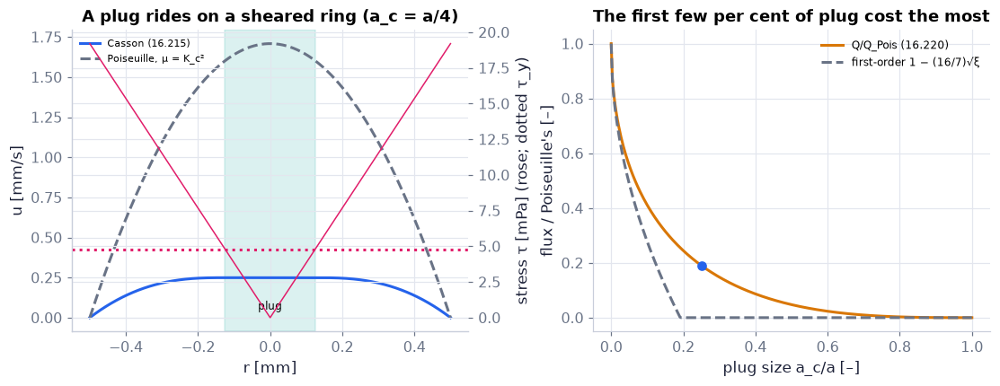

In [147]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.8))   # a new figure and its axes
rr = np.linspace(-aP, aP, 801)                                 # across the diameter [m]
uC = ch16.casson_pipe_velocity(np.abs(rr), aP, dpP, LP, ty, Kc)   # Casson profile (plug value inside a_c)
uP = ch16.poiseuille_velocity(np.abs(rr), aP, dpP, LP, Kc**2)  # Poiseuille with μ = K_c²
ax.plot(rr*1e3, uC*1e3, color=COLORS["blue"], lw=2, label="Casson (16.215)")   # curve: Casson (16.215)
ax.plot(rr*1e3, uP*1e3, "--", color=COLORS["muted"], label="Poiseuille, μ = K_c²")   # curve: Poiseuille, μ = K_c²
ax.axvspan(-ac*1e3, ac*1e3, color=COLORS["teal"], alpha=0.15); ax.text(0, 0.05, "plug", ha="center", fontsize=8)   # a shaded band
ax2 = ax.twinx(); ax2.plot(rr*1e3, dpP/(2*LP)*np.abs(rr)*1e3, color=COLORS["rose"], lw=1); ax2.axhline(ty*1e3, color=COLORS["rose"], ls=":")   # a second y-axis sharing the x-axis
ax2.set_ylabel("stress τ [mPa] (rose; dotted τ_y)")   # axis label or title
ax.set(xlabel="r [mm]", ylabel="u [mm/s]", title="A plug rides on a sheared ring (a_c = a/4)"); ax.legend(fontsize=7, loc="upper left")   # axis labels, limits and title
xi = np.linspace(0, 1, 300)                                    # a_c/a
bx.plot(xi, ch16.casson_flux_ratio(xi), color=COLORS["amber"], lw=2, label="Q/Q_Pois (16.220)")   # curve: Q/Q_Pois (16.220)
bx.plot(xi, np.maximum(0, 1 - 16/7*np.sqrt(xi)), "--", color=COLORS["muted"], label="first-order 1 − (16/7)√ξ")   # curve: first-order 1 − (16/7)√ξ
bx.plot(0.25, ch16.casson_flux_ratio(0.25), "o", color=COLORS["blue"])   # blue dot: our example, a_c = a/4
bx.set(xlabel="plug size a_c/a [–]", ylabel="flux / Poiseuille's [–]", title="The first few per cent of plug cost the most"); bx.legend(fontsize=8)   # axis labels, limits and title
savefig(fig, "ch16", "c16_casson_pipe"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** Left: the Casson velocity profile across the pipe (blue) with the plug shaded teal, Poiseuille's profile for
μ = K_c² at the same pressure drop (grey dashed), and the linear stress (rose, right axis) crossing τ_y at the plug's edge.
Right: the flux relative to Poiseuille's against the plug size, with the first-order √ξ approximation.

**How to read it.** Inside the plug the profile is flat; outside it bends to zero at the wall. The flux falls steeply at small plug
sizes because of the $\sqrt{a_c/a}$ term: a plug 1 % of the radius already costs a fifth of the flow.

**What would change if…** …the pressure gradient were halved? $a_c/a$ would double to 0.5 and the bracket of $Q=\dfrac\pi8\dfrac1{K_c^2}\dfrac{\Delta p}La^4\left[1-\dfrac{16}7\left(\dfrac{a_c}a\right)^{1/2}+\dfrac43\left(\dfrac{a_c}a\right)-\dfrac1{21}\left(\dfrac{a_c}a\right)^4\right]$ (16.220) would fall to
`ch16.casson_flux_ratio(0.5)` = 0.047: the flux would drop to 4.7 % of Poiseuille's (printed below), and Poiseuille's own
flux halves too.

In [148]:
print(f"bracket of (16.220) at a_c/a = 0.25: {ch16.casson_flux_ratio(0.25):.4f}; at 0.5: {ch16.casson_flux_ratio(0.5):.4f}")   # 0.190 and 0.047

bracket of (16.220) at a_c/a = 0.25: 0.1903; at 0.5: 0.0474


In [149]:
xis = list(np.round(np.linspace(0.0, 0.95, 20), 3))           # τ_y/τ_w = a_c/a (20 positions)
sP = np.linspace(-1, 1, 301)                                   # r/a across the diameter
def casson_prof(xi_):                                          # profiles in units of the Poiseuille centre speed a τ_w/(2K_c²)
    tw = 1.0; ty_ = xi_*tw; s = np.abs(sP)                     # wall stress 1, yield stress xi
    u_ = np.where(s <= xi_, (1 - xi_**2) - 8/3*np.sqrt(xi_)*(1 - xi_**1.5) + 2*xi_*(1 - xi_),   # inside the plug (|r|/a ≤ a_c/a): the flat plug speed
                  (1 - s**2) - 8/3*np.sqrt(xi_)*(1 - s**1.5) + 2*xi_*(1 - s))   # (16.216) divided by aτ_w/(2K_c²)
    return {"Casson (16.216)": (sP, u_), "Poiseuille, μ = K_c²": (sP, 1 - sP**2)}   # what this function hands back
fig = slider_figure(casson_prof, "τ_y/τ_w", xis, xlabel="r / a [–]", ylabel="u / (aτ_w/2K_c²) [–]",   # build the slider figure (every position computed now)
                    title="The plug widens as the yield stress approaches the wall stress", yrange=[0, 1.05], active=5)   # the figure's title: its message
fig.show()   # display the figure

**Figure F7.** Slider: the ratio τ_y/τ_w = a_c/a from 0 to 0.95 (opens on 0.25, our example). **What you see.** The Casson
profile $u=\dfrac{a\tau_w}{2K_c^2}\left\{\left[1-\left(\dfrac ra\right)^2\right]-\dfrac83\sqrt{\dfrac{\tau_y}{\tau_w}}\left[1-\left(\dfrac ra\right)^{3/2}\right]+2\dfrac{\tau_y}{\tau_w}\left(1-\dfrac ra\right)\right\}$ (16.216) in units of the Poiseuille centre speed, beside Poiseuille's parabola. **How to read it.** At 0 the two are
one; as the ratio grows the flat plug widens and the whole profile sinks. **What would change if…** the ratio reached 1: the
plug would fill the pipe and the flow would stop (trap T21).

#### 🎮 Interactive: Does a yield stress stop the blood?

**Why interactive rather than a static figure:** dragging the pressure gradient down you watch the plug widen until it fills the pipe and the flow stops; dragging a
shear-rate cursor on the law shows the secant and tangent separate — two linked views of one material.

Start with the **Walkthrough**; the **Explain** tab works every number out with your settings, and the **Derivation** tab (where there is one) steps through the same derivation as above. Stresses are positive magnitudes; τ_y and K_c² are illustrative (Whitmore's constants with our plasma viscosity); the plug radius a_c is a fraction of the pipe radius a.

**What to try:**
- Lower Δp/L toward 2τ_y/a: the plug fills the pipe.
- Set τ_y = 0: Poiseuille returns.
- Click inside the plug: the shear rate is zero there.

In [150]:
show_viz("ch16", "casson_blood_flow")   # full-width explainer; ⤢ Full screen for more room

[explainer ch16/casson_blood_flow]

**What would change if…** …the fluid were sap in a tree instead of blood in an artery? The flow is Poiseuille's again, but now gravity and dissolved
sugars join the pressure — C17.

---

## 16.4 Introduction to the Fluid Mechanics of Plants

**What is this section about?** How water rises from soil to leaf (xylem) and how sugar travels from leaf to root (phloem): one 'water potential' organises both.

### 🧩 Water potential $\psi=p-RTc+\rho gz$ (16.221) `C17`

*The question:* How does water reach the top of a 30-metre tree without a pump?

📝 **Note.** **N109 [B]** The scene: plants make up most of the Earth's living mass. Their vascular tissue has two pipe systems: xylem
(water up) and phloem (sugar sap wherever it is needed).

```
   air  ~~~  water vapour leaves the leaf (transpiration)
   leaf  ◄── lowest ψ
    │  xylem: water pulled up under tension        phloem: sugar sap pushed from leaf to where it is needed
   stem
    │
   root ◄── water enters from the soil (highest ψ)
   soil
```

#### The problem in plain words

Water in a tree climbs tens of metres with no heart. It is not pushed up; **it is pulled**. Water evaporates from the leaves;
the water column in the narrow xylem pipes is pulled up after it, hanging from the leaves under tension — a negative
pressure. To keep track of where water wants to go we need one number that combines pressure, dissolved salt and height.

> 📎 **Primer — osmosis and van 't Hoff's law.** `P384` · Water moves through a membrane toward the side with more dissolved solute. The
pressure that stops it is the osmotic pressure; for a dilute solution $\Pi=cR_uT$ (c in mol/m³) — the solute lowers the
water's "potential" by Π. (Chemical potential is the deeper idea; named only.)

In [151]:
Ru, T = 8.314462618, 293.15                    # gas constant [J/(mol K)], temperature [K]
for c in (10, 100, 300):                       # concentrations [mol/m³]
    print(c, c*Ru*T/1e6)                       # 0.024, 0.244, 0.731 MPa

10 0.024373847164667
100 0.24373847164666998
300 0.7312154149400101


#### The idea

```
ψ  =   p     −   R_u T c    +   ρ g z
     pressure    dissolved      height
     pushes      salt pulls     costs
water moves from high ψ to low ψ:   soil (highest) ──► root ──► stem ──► leaf ──► air (lowest)
```

**One number, the water potential $\psi=p-RTc+\rho gz$ (16.221), says which way water moves** (c is the solute concentration of the
osmosis primer above, R_u the gas constant). A tree needs no pump: evaporation keeps the leaf's ψ lowest, and the column is
pulled up toward it.

> 🔁 **Recap — Hydrostatics** (Ch. 1 D05). $\dfrac{dp}{dz}=-\rho g$ (1.8): in a fluid at rest the pressure falls by ρg per metre of height.

#### 🧮 Derivation — The three terms of the water potential and the tension that lifts sap `D34` ★ (Eq. 16.221: $\psi=p-RTc+\rho gz$)

**What we want to show.** See why water's "potential" adds a pressure, a solute and a height term, and what pressure a still column needs at height z.

**Assumptions.** a dilute ideal solution (step 1); no flow (step 3).

**The plan.**

1. Name the three terms.
2. Check their units.
3. Hold a still column.
4. Solve for p.
5. Read the sign.

**Tools we use** (each explained before this point): osmosis and van 't Hoff's law (P384, primer in C17) · the hydrostatic law $dp/dz=-\rho g$ (1.8) (Ch. 1 D05, recap) · units of physiology (P394)

**We start from**

$$ \psi=p-RTc+\rho gz\ \text{(16.221) and van 't Hoff's}\ \Pi=cR_uT\ \text{(P384).} $$

---

**Step 1 of 5 — Name the three ways water's energy changes.**

$$ \psi=\underbrace{p}_{\text{pressure}}\;\underbrace{-\,R_uTc}_{\text{solutes}}\;+\underbrace{\rho gz}_{\text{height}}\ \text{(16.221)} $$

- *Why we can do this:* Per unit volume of water: pressure work p; dissolved solutes lower water's free energy by the osmotic pressure Π = cR_uT (P384); lifting by z costs ρgz. Water moves from high ψ to low ψ.
- *In words:* One ledger for pressure, salt and height.

---

**Step 2 of 5 — Check the units.**

$$ [R_uTc]=\dfrac{\mathrm J}{\mathrm{mol\,K}}\cdot\mathrm K\cdot\dfrac{\mathrm{mol}}{\mathrm m^3}=\dfrac{\mathrm J}{\mathrm m^3}=\mathrm{Pa} $$

- *Why we can do this:* Each term must be a pressure. In the book's units ρgz comes out in dyn/cm² and must be divided by 10⁶ to be in bar (slip S30).
- *In words:* All three are pascals.

---

**Step 3 of 5 — Hold a still column of pure water.**

$$ \psi(z)=\psi_{soil},\quad c=0 $$

- *Why we can do this:* No flow means no gradient of ψ (water moves only down ψ); the xylem sap is nearly pure water.
- *In words:* The column is in balance with the soil.

---

**Step 4 of 5 — Solve for the pressure at height z.**

$$ p(z)=\psi_{soil}-\rho gz $$

- *Why we can do this:* $\psi=p-RTc+\rho gz$ (16.221) with c = 0 and ψ = ψ_soil; the same as $dp/dz=-\rho g$ (1.8).
- *In words:* The pressure falls by ρg per metre of height.

---

**Step 5 of 5 — Read the sign.**

$$ p(z)<0\ \text{for } z>0\ \text{when}\ \psi_{soil}\le0 $$

- *Why we can do this:* Soil holds its water, so ψ_soil ≤ 0; minus ρgz makes p more negative. Here p is a gauge pressure; the absolute pressure p + p_atm turns negative — a true tension, held by the cohesion of water — once p < −0.1 MPa, which for ψ_soil = −0.1 MPa happens from about 13 cm above the soil (trap T22).
- *In words:* Sap hangs from the leaves under tension.

---

**Result**

$$ \begin{array}{l}p(z)=\psi_{soil}-\rho gz<0\ \text{(ours) for a still column; with flow the Poiseuille drop}\ 8\mu uz/a^2\ \text{is} \\ \text{added (ours).}\end{array} $$

**What it means.** Trees lift water by pulling, not pushing: evaporation at the leaf keeps ψ low, and the column hangs under tension; capillarity alone (0.59 m in a 25 µm conduit) is far too weak. Fails when the tension exceeds what the column can hold (cavitation: a vapour bubble forms and the conduit fills with gas — an *embolism* — after which it no longer carries water).

**Check it.** Units ✓; **expect** 30 m: ρgz = 0.294 MPa; ψ_soil = −0.1 MPa gives p(30 m) = **−0.394 MPa** (−3.9 bar); with sap moving at 1 mm/s in a 25 µm conduit the viscous drop adds 12.8 kPa per metre: −0.778 MPa at the top; the osmotic term of a 0.3 mol/L leaf cell: R_uTc = 0.731 MPa.

> ⚠️ **Common confusion (traps in `D34`):** ψ < 0 under tension (T22); the book's mixed units (S30); "pressure" here is gauge.

#### ✏️ Tiny example: a 30 m tree

1. Soil water potential ψ_soil = −0.1 MPa (moist soil, ours).
2. Still column: p(30 m) = −0.1 − 1000 × 9.81 × 30/10⁶ = **−0.394 MPa** (about −3.9 bar).
3. Moving sap, 1 mm/s in a 25 µm conduit: Poiseuille gradient 8μu/a² = 8 × 10⁻³ × 10⁻³/(25 × 10⁻⁶)² = 12.8 kPa/m; over 30 m
   0.384 MPa more: **−0.778 MPa** at the top.
4. A leaf cell with 0.3 mol/L of solutes: −R_uTc = −0.731 MPa — its ψ is low enough to draw water from the xylem.

In [152]:
psi_top = ch16.water_potential(-0.394e6, 0.0, tree["T"], 30.0)   # (16.221) at the top of a still column [Pa]
terms30 = ch16.water_potential_terms(-0.394e6, 0.0, tree["T"], 30.0)   # pressure, osmotic, gravity parts [Pa]
print(f"psi(30 m) = {psi_top/1e6:.4f} MPa (≈ ψ_soil)", {k: round(v/1e6, 4) for k, v in terms30.items()})   # print the result
print(f"osmotic pressure of 300 mol/m³: {ch16.osmotic_pressure(300.0, tree['T'])/1e6:.4f} MPa (R_u = TH.R_U/1000 per mole)")   # print the result
col = ch16.xylem_column(np.linspace(0, tree["H"], 61), psi_soil=tree["psi_soil"], u=tree["u_xylem"], a=tree["a_xylem"], mu=tree["mu_w"])   # `ch16.xylem_column` (the chapter module)
print(f"moving sap: p(top) = {col['p'][-1]/1e6:.4f} MPa; margin to an illustrative −2 MPa cavitation limit: {ch16.cavitation_margin(col['p'][-1], p_cav=-2.0e6)/1e6:.3f} MPa")   # print the result

psi(30 m) = -0.0998 MPa (≈ ψ_soil) {'pressure': -0.394, 'osmotic': 0.0, 'gravity': 0.2942, 'total': -0.0998}
osmotic pressure of 300 mol/m³: 0.7312 MPa (R_u = TH.R_U/1000 per mole)
moving sap: p(top) = -0.7782 MPa; margin to an illustrative −2 MPa cavitation limit: 1.222 MPa


**What does the code above do?**

1. `water_potential` is $\psi=p-RTc+\rho gz$ (16.221) in SI (pressure gauge in Pa, concentration in mol/m³, height in m); at the top of a still
   column the pressure term and the height term cancel to give back ψ_soil.
2. `osmotic_pressure` is van 't Hoff's law with the universal gas constant per mole (`TH.R_U` is per kmol, so /1000).
3. `xylem_column` adds the Poiseuille drop of moving sap (ours): −0.778 MPa at the top, still 1.2 MPa away from our
   illustrative cavitation limit.

In [153]:
Ru = TH.R_U/1000                                               # J/(mol K)
p_, c_, z_ = -0.394e6, 50.0, 30.0                              # pressure [Pa], solutes [mol/m³], height [m]
psi_mine = p_ - Ru*tree["T"]*c_ + 1000.0*TH.G0*z_              # (16.221) term by term, SI
assert np.isclose(psi_mine, ch16.water_potential(p_, c_, tree["T"], z_))   # the library computes exactly this sum
psi_bar = ch16.water_potential_book_units(p_/1e5, c_*1e-6, tree["T"], z_*100)   # the book's units: bar, mol/cm³, cm, g = 980 cm/s²
assert np.isclose(ch16.bar_to_Pa(psi_bar), ch16.water_potential(p_, c_, tree["T"], z_, g=9.80), rtol=1e-4)   # ρgz ÷ 10⁶ to be in bar (slip S30)
print(f"SI: {psi_mine/1e6:.5f} MPa; book units: {psi_bar:.4f} bar")   # print the result

SI: -0.22167 MPa; book units: -2.2186 bar


**What does the code above do?**

The water potential written term by term in SI equals the library's; the book's mixed units (bar, mol/cm³, cm, with
ρgz in dyn/cm² divided by 10⁶ to be in bar — slip S30) give the same number once converted.

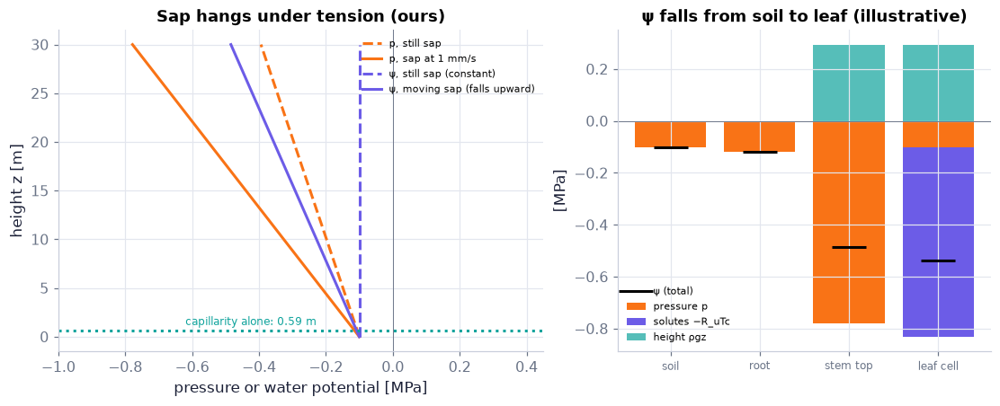

In [154]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 4.0), gridspec_kw=dict(width_ratios=[1.3, 1]))   # a new figure and its axes
still = ch16.xylem_column(col["z"], psi_soil=tree["psi_soil"], u=0.0, a=tree["a_xylem"], mu=tree["mu_w"])   # no flow
ax.plot(still["p"]/1e6, col["z"], color=COLORS["orange"], ls="--", label="p, still sap")   # curve: p, still sap
ax.plot(col["p"]/1e6, col["z"], color=COLORS["orange"], lw=2, label="p, sap at 1 mm/s")   # curve: p, sap at 1 mm/s
ax.plot(still["psi"]/1e6, col["z"], color=COLORS["accent"], ls="--", label="ψ, still sap (constant)")   # curve: ψ, still sap (constant)
ax.plot(col["psi"]/1e6, col["z"], color=COLORS["accent"], lw=2, label="ψ, moving sap (falls upward)")   # curve: ψ, moving sap (falls upward)
hcap = ch01.capillary_rise(0.0728, np.pi/2, 1000.0, tree["a_xylem"])   # Ch. 1: capillary rise in a 25-µm conduit [m]
ax.axhline(hcap, color=COLORS["teal"], ls=":"); ax.text(-0.62, hcap + 0.6, f"capillarity alone: {hcap:.2f} m", fontsize=8, color=COLORS["teal"])   # a reference line
ax.axvline(0, color=COLORS["muted"], lw=0.6)   # a reference line
ax.set(xlabel="pressure or water potential [MPa]", ylabel="height z [m]", xlim=(-1.0, 0.45), title="Sap hangs under tension (ours)")   # axis labels, limits and title
ax.legend(fontsize=7, loc="upper right")   # the legend
places = ["soil", "root", "stem top", "leaf cell"]               # four stations along the water's path
pr = np.array([-0.1, -0.12, col["p"][-1]/1e6, -0.10])           # pressure term [MPa] (illustrative, ours)
os_ = np.array([0.0, 0.0, 0.0, -ch16.osmotic_pressure(300.0, tree["T"])/1e6])   # solute term [MPa]
gr = np.array([0.0, 0.0, 1000*TH.G0*30/1e6, 1000*TH.G0*30/1e6])   # height term [MPa]
xs4 = np.arange(4)                                              # their bar positions 0, 1, 2, 3
bx.bar(xs4, pr, color=COLORS["orange"], label="pressure p"); bx.bar(xs4, os_, bottom=np.minimum(pr, 0), color=COLORS["accent"], label="solutes −R_uTc")   # bars
bx.bar(xs4, gr, color=COLORS["teal"], alpha=0.7, label="height ρgz")   # bars
bx.plot(xs4, pr + os_ + gr, "k_", ms=25, mew=2, label="ψ (total)")   # curve: ψ (total)
bx.set_xticks(xs4, places, fontsize=8); bx.axhline(0, color=COLORS["muted"], lw=0.6)   # a reference line
bx.set(ylabel="[MPa]", title="ψ falls from soil to leaf (illustrative)"); bx.legend(fontsize=7, loc="lower left")   # axis labels, limits and title
savefig(fig, "ch16", "c17_xylem"); plt.show()   # save to outputs/ch16/ and show the figure

**What you see.** Left: pressure (orange) and water potential (purple) up a 30 m tree, for still sap (dashed) and sap moving at 1 mm/s
in 25-µm conduits (solid); the dotted line is how high capillarity alone could lift water. Right: the three terms of ψ at
four places along the path (illustrative values, ours) and their total.

**How to read it.** With still sap ψ is the same everywhere — no flow without a gradient of ψ — and the pressure falls by ρg per metre.
The pressure plotted is gauge: it is already −0.1 MPa (= ψ_soil) at the ground, and the absolute pressure p + p_atm turns
negative — a true tension — about 13 cm above the soil, where p passes −0.1013 MPa. Moving sap needs ψ to fall upward, which pushes the pressure further negative (−0.78 MPa at the
top). Water moves from high ψ (soil) to low ψ (leaf), where the solute term pulls hardest.

**What would change if…** …the tree were twice as tall? The tension at the top would roughly double — trees stop growing roughly where their
xylem can no longer hold the column.

📝 **Note.** **N110 [B]** Xylem: dead conduits (tracheids, vessels); evaporation at the leaves (transpiration) pulls a cohesive column
under tension; too much tension and the column breaks (cavitation); at night root pressure can push water out at leaf edges
(guttation). Capillarity alone: Ch. 1's $h=2\sigma\sin\alpha/(\rho gR)$ (Example 1.1) gives 0.59 m for a 25 µm conduit — far
too little (ours).

In [155]:
print(f"{ch16.capillary_rise(0.0728, np.pi/2, 1000.0, 25e-6):.3f} m")   # Ch. 1: σ = 0.0728 N/m, full wetting, R = 25 µm

0.594 m


📝 **Note.** **N111 [B]** Xylem flow is creeping flow: Re = u·2a/ν = 10⁻³ × 50 × 10⁻⁶/10⁻⁶ = **0.05**; the Poiseuille drop per metre
($12.8$ kPa) is comparable with ρg ($9.8$ kPa).

> ⚠️ **slip S28 — the book prints** a kinematic viscosity ten times water's beside its xylem Reynolds number; **the correct form is** water's $\nu=10^{-6}$ m²/s, which the quoted Reynolds number needs (the book's numbers stay private)

In [156]:
print(ch16.xylem_reynolds(tree["u_xylem"], tree["a_xylem"], tree["nu_w"]))   # Re = u·2a/ν = 0.05

0.05000000000000001


📝 **Note.** **N112 [B]** Phloem: living sieve tubes joined by perforated sieve plates; sugar loaded at a source raises the solute term,
water follows by osmosis, the raised pressure pushes the sap to a sink where sugar is unloaded (the Münch pressure-flow idea)
— ψ again.

```
 source (leaf): sugar in → ψ falls → water enters → p rises ══► sap flows ══► sink (root, fruit): sugar out → p falls
```

📝 **Note.** **N113 [B]** The pressure drop along a sieve tube with its plates: $\Delta p=\dfrac{8\mu Q}{\pi a^4}\left[L+\dfrac\ell N\left(\dfrac ar\right)^4\right]+2\,\Delta p'$ (16.222) (Δp′ the entry loss at a plate, given in the
book).

In [157]:
Qph = phloem["u"]*np.pi*phloem["a"]**2                        # sap flux in one sieve tube [m³/s]
st_ = ch16.sieve_tube_pressure_drop(Qph, phloem["mu"], phloem["a"], phloem["r_pore"], phloem["L"], phloem["ell"], phloem["N"])   # (16.222)
print({k: round(float(v), 3) for k, v in st_.items()}, "Pa")  # the plates carry most of the drop (illustrative sizes, ours)
lim = ch16.sieve_tube_pressure_drop(Qph, phloem["mu"], phloem["a"], phloem["a"], phloem["L"], 0.0, 1)["total"]   # no plates (r = a, ℓ = 0)
print(f"Poiseuille limit {lim:.3f} Pa vs 8μQL/(πa⁴) = {8*phloem['mu']*Qph*phloem['L']/(np.pi*phloem['a']**4):.3f} Pa")   # print the result

{'total': 70.613, 'tube': 10.8, 'plate_viscous': 7.2, 'plate_entry': 52.613, 'plate_share': 0.847} Pa
Poiseuille limit 10.800 Pa vs 8μQL/(πa⁴) = 10.800 Pa


In [158]:
us = list(np.round(np.linspace(0, 3e-3, 13), 5))              # sap speeds 0 … 3 mm/s
zz = np.linspace(0, tree["H"], 61)                            # heights [m]
def column(u_):                                               # ψ terms and p along the trunk for one sap speed
    c_ = ch16.xylem_column(zz, psi_soil=tree["psi_soil"], u=u_, a=tree["a_xylem"], mu=tree["mu_w"])   # `ch16.xylem_column` (the chapter module)
    return {"p": (c_["p"]/1e6, zz), "ψ": (c_["psi"]/1e6, zz), "height term ρgz": (c_["gravity"]/1e6, zz),   # what this function hands back
            "viscous loss": (-c_["viscous"]/1e6, zz)}   # (continued from the line above)
fig = slider_figure(column, "u", us, unit="m/s", xlabel="[MPa]", ylabel="height z [m]",   # build the slider figure (every position computed now)
                    title="Faster sap, deeper tension", xrange=[-1.4, 0.35], yrange=[0, 30], active=4)   # the figure's title: its message
fig.show()   # display the figure

**Figure F8.** Slider: the sap speed in a 25-µm conduit, 0 to 3 mm/s (opens on our 1 mm/s). **What you see.** Pressure,
water potential, the height term and (minus) the accumulated viscous loss against height. **How to read it.** At u = 0 the ψ
line is vertical (no flow without a gradient); every extra mm/s tilts ψ and pushes the top pressure 0.38 MPa further
negative. **What would change if…** the conduits were twice as wide: the viscous loss would fall fourfold
(Poiseuille, 8μu/a²).

#### 🎮 Interactive: How does water climb a 30-metre tree?

**Why interactive rather than a static figure:** dragging height, sap speed and soil dryness you watch the three terms of ψ trade along the trunk while the pressure
goes below zero and a warning appears near the illustrative cavitation limit — three inputs at once, which one static
figure cannot show.

Start with the **Walkthrough**; the **Explain** tab works every number out with your settings, and the **Derivation** tab (where there is one) steps through the same derivation as above. Pressures are gauge, in MPa; ψ < 0 means water is held under tension; the cavitation limit is illustrative.

**What to try:**
- Set the sap speed to 0: ψ is the same at every height.
- Pick the 100 m giant.
- Drought: lower ψ_soil to −1.5 MPa.

In [159]:
show_viz("ch16", "xylem_water_potential")   # full-width explainer; ⤢ Full screen for more room

[explainer ch16/xylem_water_potential]

**What would change if…** …the tree were twice as tall? The tension doubles — trees stop growing roughly where their xylem can no longer hold the
column.

---

## Exercises, literature and what comes next

*↪ **S01** Exercises 16.1–16.6 (not reproduced): 16.1 extends C06 (an elastic tube whose radius varies along it); 16.2 is
the dimensional analysis of C03 (careful: its Strouhal number is aω/U — trap T6); 16.3 a stenosis; 16.4 Shapiro's pure
pressure–gravity flows (C15; the citation's year is misprinted — slip S33); 16.5–16.6 generalise C16 to power-law and
Herschel–Bulkley fluids (`ch16.power_law_pipe_flow_rate`, `ch16.herschel_bulkley_pipe_flow_rate`, ours).*

*↪ **S02** Acknowledgment, literature cited and supplemental reading: not reproduced. Sources we read first-hand are listed
in the next cell.*

**Sources read first-hand (public).** Secomb & Pries (2013), *C. R. Physique* 14, 470 (the in-vitro viscosity law of C05);
Wikipedia articles "Womersley number", "Pulsatile flow", "Moens–Korteweg equation", "Windkessel effect", "Murray's law",
"Hemorheology", "Entrance length (fluid dynamics)"; Lubashevsky & Gafiychuk, arXiv:adap-org/9909003 (Murray's cost).
Open items: Dean (1928) and Womersley (1955) were not read first-hand; the Navier–Stokes check of Dean's K⁴ coefficient
($0.0119312$, slip S34) is our own calculation, not a published value.

---

## ✅ What should have clicked

- **C01** The heart's work per beat is the area of its pressure–volume loop, about a joule: $W=-\oint p\,dV$ (ours).
- **C02** Blood thins with shear: Casson's law $\sqrt{\dfrac{\tau}{\mu_p}}=k_c\sqrt{\dot\gamma}+\sqrt{\dfrac{\tau_y}{\mu_p}}$ (16.6) is a straight line in square roots, with the yield stress as intercept.
- **C03** $\alpha=a\sqrt{\omega/\nu}$ (16.12) compares a vessel with its own Stokes layer: $\alpha=\sqrt2\,a/\delta_e$.
- **C04** $R=\dfrac{8\mu L}{\pi a^4}$ (16.20): halve the radius, sixteen times the resistance — the arterioles' lever on blood pressure.
- **C05** A thin plasma layer makes blood seem thinner in narrow tubes: $\mu_{app}=\mu_p\left[1-\left(1-\dfrac\delta a\right)^4\left(1-\dfrac{\mu_p}{\mu_c}\right)\right]^{-1}$ (16.33).
- **C06** An artery is a spring: the tube law $a=a_0\left[1-\dfrac{a_0}{Eh}(p-p_e)\right]^{-1}$ (16.41), with a hoop stress $\sigma_{\theta\theta}=\dfrac{(p-p_e)a}{h}$ (16.39).
- **C07** The aorta stores each beat and drains it with time constant RK: $Q(t)=\mathrm K\dfrac{dp}{dt}+\dfrac{p(t)}{R}$ (16.49); the mean is $R\bar Q$, compliance sets the swing.
- **C08** The pulse is a wave of wall stretch, $c=\sqrt{\dfrac{Eh}{2\rho a_0}}$ (16.62), metres per second while the blood barely moves.
- **C09** Womersley's profile $u(r,t)=\dfrac{Ga^2}{i\mu\alpha^2}\left(1-\dfrac{J_0(i^{3/2}\alpha r/a)}{J_0(i^{3/2}\alpha)}\right)e^{i\omega t}$ (16.82): a breathing parabola at small α, a lagging plug at large α.
- **C10** The flow amplitude falls as 8/α² and lags up to 90°: $|Q|=\dfrac{\pi Ga^4}{\mu\alpha^2}\sqrt{X^2+Y^2}$ (16.99), $\tan\phi=\dfrac XY$ (16.100).
- **C11** Viscosity slows and damps the pulse by amounts ∝ 1/α: the pressure root of $X^2\left[2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}-4\right]+X\left[4\hat\nu-1-2\hat\beta\dfrac{J_0(\hat\beta)}{J_1(\hat\beta)}\right]+(1-\hat\nu^2)=0$ (16.136).
- **C12** Murray: at the best radius pumping is half the upkeep, so $a=\left[\dfrac{16\mu}{\pi^2K}\right]^{1/6}Q^{1/3}$ (16.140, corrected) gives Q ∝ a³ and $a_0^3=a_1^3+a_2^3$ (16.144).
- **C13** A fork reflects by admittance mismatch, $\mathrm R=\dfrac{p_R}{p_I}=\dfrac{Y_1-\sum Y_j}{Y_1+\sum Y_j},\ \ \mathrm T=\dfrac{p_{Tj}}{p_I}=\dfrac{2Y_1}{Y_1+\sum Y_j}$ (16.153), and energy balances: $\mathrm R^2+(\sum Y_j/Y_1)\mathrm T^2=1$.
- **C14** A bend makes two vortices and pushes the fast core outward; the flux falls as $\dfrac{Q}{\pi a^2\bar W}=1-0.0306\left(\dfrac K{576}\right)^2+0.0120\left(\dfrac K{576}\right)^4+O(K^6)$ (16.178) (K⁴ coefficient 0.0119312 with slip S34 corrected).
- **C15** A floppy tube chokes at S = 1 — flow limitation: $(1-S^2)\dfrac1\alpha\dfrac{d\alpha}{dx}=\dfrac{S^2}{A_0}\dfrac{dA_0}{dx}-\dfrac1{\rho c^2}\left[\dfrac{dp_e}{dx}+\rho g\dfrac{dz}{dx}+\mathrm RQ+\mathrm P\dfrac{dK_p}{dx}\right]$ (16.204).
- **C16** A yield stress makes a plug and costs flow through $\sqrt{a_c/a}$: $Q=\dfrac\pi8\dfrac1{K_c^2}\dfrac{\Delta p}La^4\left[1-\dfrac{16}7\left(\dfrac{a_c}a\right)^{1/2}+\dfrac43\left(\dfrac{a_c}a\right)-\dfrac1{21}\left(\dfrac{a_c}a\right)^4\right]$ (16.220).
- **C17** Sap is pulled up under tension: $\psi=p-RTc+\rho gz$ (16.221).

**What later chapters build on**

- This is the book's last chapter: the tools reused here (Poiseuille, Stokes layers, d'Alembert, differential relations with a 1 − S² factor, perturbation series) are the toolkit for any applied fluid problem — including the climate-system flows of Ch. 13 (Ekman layers are Stokes layers in a rotating frame; wave reflection and choking reappear in ocean straits).

**Not taught here (and where to find it)**
- swimming and flying (not in this chapter; Ch. 14's thrust-from-lift explainer is the closest)
- turbulence in the aorta (Ch. 12)
- large-Dean-number numerics (named in N93)
- collapsible-tube oscillations (named in N96)